# U02 — Hybrid Unique × T=1 Sampling

Goal: keep the established **Unique** controller as the primary objective while
using otherwise-unused decoding opportunities to recover some of the human-like
surprisal/innovation tail.

Frozen design:

- generator: `meta-llama/Llama-3.2-3B-Instruct`
- frozen 20-case U01 cohort
- context: **WITH_PREV**
- temporal history: **FULL**
- Unique controller: canonical C02w2/U01b stronger-downward policy
- Unique word-path relative-likelihood guard: **0.05**
- secondary policy: `temperature=1.0`, `top_p=1.0` sampling
- sampling is allowed only when:
  1. Unique is inactive/unsupported/warmup, or
  2. the sampled outcome is **Unique-equivalent** to the canonical aligned/fallback outcome
- successful Unique backtracking is never overridden by sampling
- maximum generation length: 640 model tokens
- deterministic per-case sampling seeds
- comparison baseline: existing U01b `FULL + WITH_PREV + Unique + greedy`
- evaluation: Unique-band trajectory metrics, manual sanity sheet, and post-warmup
  surprisal under Qwen3, GPT-2 and SmolLM2

This notebook generates only the 20 Hybrid texts. It reuses the already-generated
Greedy+Unique baseline rather than spending GPU time regenerating it.


In [1]:
from pathlib import Path
import ast, copy, gc, hashlib, json, math
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from IPython.display import display

import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForCausalLM

ROOT = Path.cwd().resolve()
if ROOT.name == "experiments":
    ROOT = ROOT.parent
if not (ROOT / "results").exists() and (ROOT.parent / "results").exists():
    ROOT = ROOT.parent

assert (ROOT / "experiments").exists(), ROOT

U01B_NB = ROOT / "experiments/U01b_joint_unique_temporal_withprev.ipynb"
UNIQUE_NB = ROOT / "experiments/C02w2_regenerate_top5.ipynb"

assert U01B_NB.exists(), U01B_NB
assert UNIQUE_NB.exists(), UNIQUE_NB

OUT = ROOT / "results/causal/U02_hybrid_unique_sampling"
OUT.mkdir(parents=True, exist_ok=True)

STATE_DIR = OUT / "states"
STATE_DIR.mkdir(exist_ok=True)

GEN_PATH = OUT / "hybrid_generations.parquet"

MODEL_ID = "meta-llama/Llama-3.2-3B-Instruct"
MAX_NEW_TOKENS = 640
DOWNWARD_THETA_MULTIPLIER = 0.25

UNIQUE_RATIO_FLOOR = 0.05

SAMPLE_TEMPERATURE = 1.0
SAMPLE_TOP_P = 1.0
SAMPLE_WORD_TOKEN_CAP = 64

SEED_NAMESPACE = "U02_HYBRID_T10_v1"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

dtype = (
    torch.float16
    if device.type == "cuda"
    else torch.float32
)

print("ROOT:", ROOT)
print("Output:", OUT)
print("Device:", device)
print("Unique guard floor:", UNIQUE_RATIO_FLOOR)
print(
    "Secondary sampling:",
    f"T={SAMPLE_TEMPERATURE}, top_p={SAMPLE_TOP_P}",
)

/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROOT: ..
Output: ../results/causal/U02_hybrid_unique_sampling
Device: cuda
Unique guard floor: 0.05
Secondary sampling: T=1.0, top_p=1.0


## Load frozen cohort and Unique contracts

In [2]:
# Reconstruct the exact cohort and Unique contracts used by U01b.
# Do this directly rather than executing a U01b setup cell, so this notebook
# is self-contained with respect to setup order.

PAIR_PATH = ROOT / "results/causal/C02d2_fz118_ghostbuster_raid/paired_corpus.parquet"
U01_OUT = ROOT / "results/causal/U01_temporal_method_selection"
COHORT_PATH = U01_OUT / "cohort20.csv"
UNIQUE_PARENT = ROOT / "results/causal/C02r_discovery_gated_punctuation"
CONTRACT_PATH = UNIQUE_PARENT / "frozen_contract.json"

for _p in [PAIR_PATH, COHORT_PATH, CONTRACT_PATH]:
    assert _p.exists(), _p

cohort = pd.read_csv(COHORT_PATH, keep_default_na=False)
assert len(cohort) == 20 and cohort.case_id.is_unique

paired = pd.read_parquet(PAIR_PATH).copy()

def raw_id(x):
    x = str(x)
    return x.split("ai__raid:", 1)[1] if x.startswith("ai__raid:") else x

paired["raw_id"] = paired.source_id.astype(str).map(raw_id)
exact = paired.drop_duplicates("source_id").set_index("source_id").text.to_dict()
rawmap = paired.drop_duplicates("raw_id").set_index("raw_id").text.to_dict()

cohort["raw_id"] = cohort.source_id.astype(str).map(raw_id)
cohort["previous_ai"] = cohort.source_id.astype(str).map(exact)
miss = cohort.previous_ai.isna()
cohort.loc[miss, "previous_ai"] = cohort.loc[miss, "raw_id"].map(rawmap)
assert cohort.previous_ai.notna().all()
assert "prompt" in cohort.columns, cohort.columns.tolist()

# Canonical Unique frozen contract used by U01b.
unique_contract = json.loads(CONTRACT_PATH.read_text())
UNIQUE_THETA_SCHEDULES = copy.deepcopy(unique_contract["theta_schedules"])
MAX_COMPLETED_CANDIDATES = int(unique_contract["max_completed_candidates"])

case_contract = {
    str(c["case_id"]): copy.deepcopy(c)
    for c in unique_contract["cases"]
}

missing_cases = sorted(set(cohort.case_id.astype(str)) - set(case_contract))
assert not missing_cases, f"U02 cases absent from Unique frozen contract: {missing_cases}"

# U01b notebook is still read later only to recover the exact backend class.
u01b_nb = json.loads(U01B_NB.read_text())
code_cells = [
    "".join(c.get("source", []))
    for c in u01b_nb["cells"]
    if c.get("cell_type") == "code"
]

print("Cases:", len(cohort))
print("Unique contract:", CONTRACT_PATH)
print("Theta schedules:", UNIQUE_THETA_SCHEDULES)
print("Max completed candidates:", MAX_COMPLETED_CANDIDATES)
display(cohort[["case_id", "source_id", "domain"]])


Cases: 20
Unique contract: ../results/causal/C02r_discovery_gated_punctuation/frozen_contract.json
Theta schedules: {'increase': {'minimum': 0.005, 'maximum': 0.1, 'slope': 4.0, 'midpoint': 1.0}, 'decrease': {'minimum': 0.005, 'maximum': 0.1, 'slope': 4.0, 'midpoint': 1.0}}
Max completed candidates: 500


,case_id,source_id,domain
0,gate_0090,ai__raid:e3945a96-7048-41d9-9e86-a84e87818986,abstracts
1,gate_0070,ai__raid:7a3b622e-1e88-48ce-98e0-2f87da5c573c,books
2,gate_0017,ai__raid:b4b807b1-fbfa-43d8-9fc3-61bd36b078ef,news
3,gate_0085,ai__raid:fa8bd0e4-3134-4d4d-83e4-4749c0bf6462,recipes
4,gate_0038,ai__raid:bf3df034-9724-4840-86cb-33eb1489b717,reddit
5,gate_0039,ai__raid:8760103e-729a-4bab-b799-5775ac2468b1,wiki
6,gate_0069,ai__raid:c7b5fc38-2bbb-4e44-bba7-dc8ac8eae773,abstracts
7,gate_0035,ai__raid:e0c2314e-b8d9-422e-af55-1498f8c4dce9,books
8,gate_0003,ai__raid:2abdd1df-30c9-4db4-bc75-08ae57b9ec93,news
9,gate_0025,ai__raid:dab3ef7f-6a54-49f9-9367-e907f0618c82,recipes


## Load the canonical Unique controller

In [3]:
# Load the canonical Unique controller from C02w2 without executing generation cells.

src_nb = json.loads(UNIQUE_NB.read_text())

import heapq
import spacy
from collections import Counter

nlp = spacy.load("en_core_web_sm")
PILOT = {"downward_theta_multiplier": DOWNWARD_THETA_MULTIPLIER}

def _cell_source(marker):
    hits = [
        "".join(cell.get("source", []))
        for cell in src_nb["cells"]
        if cell.get("cell_type") == "code"
        and marker in "".join(cell.get("source", []))
    ]
    assert len(hits) == 1, (marker, len(hits))
    return hits[0]

def _assigned_names(node):
    names = []
    if isinstance(node, ast.Assign):
        targets = node.targets
    elif isinstance(node, ast.AnnAssign):
        targets = [node.target]
    else:
        return names
    for target in targets:
        if isinstance(target, ast.Name):
            names.append(target.id)
    return names

def _exec_selected(src, predicate):
    tree = ast.parse(src)
    body = [node for node in tree.body if predicate(node)]
    exec(compile(ast.Module(body=body, type_ignores=[]), str(UNIQUE_NB), "exec"), globals())

helper_src = _cell_source("# Human prefix references and adaptive control helpers.")
_exec_selected(helper_src, lambda node: isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)))

engine_src = _cell_source("# Word feedback engine. Pure Python")
_exec_selected(
    engine_src,
    lambda node: isinstance(node, (ast.Import, ast.ImportFrom, ast.ClassDef, ast.FunctionDef, ast.AsyncFunctionDef)),
)

budget_src = _cell_source("class WordSearchBudgetReached")
_budget_assigns = {"SEARCH_BUDGET", "_search_word_before_budget", "budgeted_search", "RUNAWAY_POLICY"}
_budget_funcs = {"search_word", "repeated_suffix", "runaway_reason", "show_repetition_onset"}
_budget_classes = {"WordSearchBudgetReached", "RunawayGeneration"}

def _keep_budget_node(node):
    if isinstance(node, (ast.Assign, ast.AnnAssign)):
        return any(name in _budget_assigns for name in _assigned_names(node))
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
        return node.name in _budget_funcs
    if isinstance(node, ast.ClassDef):
        return node.name in _budget_classes
    return False

_exec_selected(budget_src, _keep_budget_node)

guard_src = _cell_source("def word_path_logp")
_exec_selected(
    guard_src,
    lambda node: isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)) and node.name in {"word_path_logp", "make_search"},
)

# U01b/C02w2 stronger-downward policy.
_u02_base_adaptive_mode = adaptive_mode
_u02_base_adaptive_theta = adaptive_theta

def adaptive_mode(previous, V, W, warmup_words, ref):
    mode = _u02_base_adaptive_mode(previous, V, W, warmup_words, ref)
    if W >= warmup_words and W > 0 and ref.get("supported", False) and V / W > ref["H_median"]:
        return "decrease"
    return mode

def adaptive_theta(mode, k, w, ref, schedules):
    theta, q = _u02_base_adaptive_theta(mode, k, w, ref, schedules)
    if theta is not None and mode == "decrease":
        theta *= DOWNWARD_THETA_MULTIPLIER
    return theta, q

required = {
    "reference_at", "adaptive_mode", "adaptive_theta", "word_spans", "counts",
    "first_closed_word", "greedy_to_word", "backtrack_anchor", "search_word",
    "initial_state", "run_feedback", "WordSearchBudgetReached",
    "_search_word_before_budget", "budgeted_search", "word_path_logp", "make_search",
}
missing = required - set(globals())
assert not missing, f"Unique engine extraction missing: {sorted(missing)}"

print("Canonical Unique engine loaded.")
print("Search budget:", SEARCH_BUDGET)

Canonical Unique engine loaded.
Search budget: {'version': 'word_search_budget_pilot_v1', 'max_expanded': 1000, 'max_frontier': 10000}


## Load Llama and freeze the WITH_PREV prompt

In [4]:
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

tok = AutoTokenizer.from_pretrained(MODEL_ID, use_fast=True)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=dtype,
    low_cpu_mem_usage=True,
).to(device).eval()

eos = model.generation_config.eos_token_id
if eos is None:
    eos = tok.eos_token_id
EOS_IDS = set(eos if isinstance(eos, (list, tuple)) else [eos])
FORBIDDEN_SPECIAL = set(tok.all_special_ids) - EOS_IDS

class TokenCapReached(RuntimeError):
    pass

def build_messages(prompt, previous_ai):
    content = (
        f"Original task:\n{prompt}\n\n"
        f"Previous AI answer:\n{previous_ai}\n\n"
        "Generate a fresh complete answer to the original task. "
        "Preserve the substantive content of the previous AI answer."
    )
    return [{"role": "user", "content": content}]

def prompt_ids(prompt, previous_ai):
    rendered = tok.apply_chat_template(
        build_messages(prompt, previous_ai),
        tokenize=False,
        add_generation_prompt=True,
    )
    return tok(
        rendered,
        return_tensors="pt",
        add_special_tokens=False,
    )["input_ids"][0].tolist()

print("Loaded:", MODEL_ID)
print("EOS:", EOS_IDS)
if torch.cuda.is_available():
    free, total = torch.cuda.mem_get_info()
    print(f"CUDA free after load: {free/2**30:.2f}/{total/2**30:.2f} GiB")


Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████| 254/254 [00:01<00:00, 194.15it/s]


Loaded: meta-llama/Llama-3.2-3B-Instruct
EOS: {128008, 128001, 128009}
CUDA free after load: 0.48/7.62 GiB


## FULL-history contract

In [5]:
# U02 freezes the U01b FULL arm. For FULL, U01b's temporal-history
# multiplier is identically 1.0 at every generated-token position.
#
# Define that contract directly instead of executing U01b's larger schedule/plot
# cell (which also depends on notebook-only globals such as METHODS).

def lambda_full(method, t):
    if method != "FULL":
        raise ValueError(f"U02 is FULL-only; unexpected temporal method: {method!r}")
    return 1.0

assert lambda_full("FULL", 0) == 1.0
assert lambda_full("FULL", 639) == 1.0
print("FULL temporal-history multiplier fixed at 1.0 for all positions.")


FULL temporal-history multiplier fixed at 1.0 for all positions.


## Recover the U01b generation backend

In [6]:
# Recover ONLY the JointTemporalBackend class definition from U01b.
# Do not execute any other top-level code from that notebook cell.
#
# NOTE: inspect.getclosurevars(...).unbound is NOT appropriate here because
# Python records attribute names (e.g. .clone, .decode, .append) in co_names,
# which makes ordinary method attributes look like unresolved globals.
# We instead inspect only actual LOAD_GLOBAL / LOAD_NAME bytecode operations.

import builtins
import dis

backend_hits = [
    s for s in code_cells
    if "class JointTemporalBackend:" in s
    and "def _distribution(self,ids):" in s
]
assert len(backend_hits) == 1, f"Expected one backend cell, found {len(backend_hits)}"

_backend_tree = ast.parse(backend_hits[0])
_backend_classes = [
    node for node in _backend_tree.body
    if isinstance(node, ast.ClassDef) and node.name == "JointTemporalBackend"
]
assert len(_backend_classes) == 1

exec(
    compile(
        ast.Module(body=_backend_classes, type_ignores=[]),
        str(U01B_NB),
        "exec",
    ),
    globals(),
)

assert MAX_NEW_TOKENS == 640
assert lambda_full("FULL", 128) == 1.0


def _missing_true_globals(fn):
    """Return names actually loaded as globals that are not available."""
    missing = set()

    for ins in dis.get_instructions(fn):
        if ins.opname not in {"LOAD_GLOBAL", "LOAD_NAME"}:
            continue

        name = ins.argval

        if name in fn.__globals__:
            continue

        if hasattr(builtins, name):
            continue

        missing.add(name)

    return sorted(missing)


# Audit the exact functions used by the generation path.
_guarded_005 = make_search(UNIQUE_RATIO_FLOOR)

_check_functions = {
    "JointTemporalBackend._distribution": JointTemporalBackend._distribution,
    "JointTemporalBackend.choices": JointTemporalBackend.choices,
    "JointTemporalBackend.decode": JointTemporalBackend.decode,
    "run_feedback": run_feedback,
    "search_word": search_word,
    "budgeted_search": budgeted_search,
    "word_path_logp": word_path_logp,
    "make_search": make_search,
    "make_search(0.05)": _guarded_005,
}

_missing_globals = {}

for _name, _fn in _check_functions.items():
    _missing = _missing_true_globals(_fn)
    if _missing:
        _missing_globals[_name] = _missing

assert not _missing_globals, (
    f"True unresolved globals before generation: {_missing_globals}"
)

del _guarded_005


# One REAL FULL-history forward pass.
# This catches backend/runtime dependencies that static inspection can miss,
# without writing experiment output.
_test_src = cohort.iloc[0]

_test_backend = JointTemporalBackend(
    prompt_ids(
        _test_src.prompt,
        _test_src.previous_ai,
    ),
    "FULL",
)

_test_choices = _test_backend.choices(
    [],
    threshold=None,
)

assert len(_test_choices) > 0
assert _test_backend.forward_calls == 1

del _test_backend, _test_choices, _test_src

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print(
    "U02 backend/controller preflight passed: "
    "true-global audit + one real FULL forward pass."
)

U02 backend/controller preflight passed: true-global audit + one real FULL forward pass.


## Define the Hybrid Unique × T=1 controller

In [7]:

# U02 hybrid policy:
#
# 1) Unique always has priority when it needs a different novelty class.
# 2) T=1, top_p=1 sampling is used when Unique is inactive.
# 3) When Unique is active but a sampled outcome is Unique-equivalent, it may
#    replace the greedy ordinary continuation without changing the Unique objective:
#       - ordinary already has the desired novelty class, OR
#       - Unique search exhausted and the sample has the same novelty class as
#         the canonical fallback.
#
# A sampled candidate is NEVER allowed to bypass a successful Unique intervention
# or to cross novelty classes after the Unique search rejects/exhausts candidates.

def case_seed(case_id):
    h = hashlib.sha256(f"{SEED_NAMESPACE}|{case_id}".encode()).digest()
    return int.from_bytes(h[:8], "little", signed=False) % (2**63 - 1)


class HybridBackend(JointTemporalBackend):
    def __init__(self, prompt_token_ids, method, seed):
        super().__init__(prompt_token_ids, method)
        self.sample_generator = torch.Generator(device=device)
        self.sample_generator.manual_seed(int(seed))
        self.sample_draws = 0

    @torch.inference_mode()
    def sample_choice(self, ids):
        # T=1, top_p=1 means sampling directly from the FULL valid distribution.
        # Non-EOS protocol/control tokens remain forbidden exactly as in choices().
        q = self._distribution(list(ids))
        valid = q.clone()

        for i in FORBIDDEN_SPECIAL:
            if i < len(valid):
                valid[i] = 0.0

        total = valid.sum()
        if not torch.isfinite(total).item() or float(total.item()) <= 0:
            del q, valid
            raise IncompleteGeneration("No finite permitted mass for T=1 sampling.")

        probs = valid / total
        token = int(torch.multinomial(
            probs, num_samples=1, replacement=True,
            generator=self.sample_generator,
        ).item())
        probability = float(q[token].item())
        self.sample_draws += 1

        del q, valid, probs
        return token, probability


def sample_to_word(backend, ids, probabilities, fixed_prefix,
                   max_new_word_tokens=SAMPLE_WORD_TOKEN_CAP):
    """Sample T=1 until the next complete alphabetic word or EOS.

    This mirrors greedy_to_word structurally, but every pending next-token choice
    is sampled from the full valid model distribution. The explicit per-word token
    cap guarantees deterministic termination even before the global 640-token cap.
    """
    ids, probabilities = list(ids), list(probabilities)

    for _ in range(int(max_new_word_tokens) + 1):
        view = first_closed_word(backend, ids, fixed_prefix)

        if view["kind"] in {"word", "end"}:
            return dict(ids=ids, probabilities=probabilities, view=view)

        if view["kind"] == "prefix_conflict":
            raise IncompleteGeneration("Sampled decoding changed committed text.")

        if _ >= int(max_new_word_tokens):
            raise IncompleteGeneration(
                f"Sampled word exceeded {max_new_word_tokens} model tokens."
            )

        token, probability = backend.sample_choice(tuple(ids))
        ids.append(int(token))
        probabilities.append(float(probability))

    raise AssertionError("unreachable")


def run_feedback_hybrid(
    backend, state, curve, warmup_words, schedules,
    checkpoint=lambda state: None,
    on_search=lambda event: None,
    on_status=lambda state: None,
):
    # Extend the canonical state with U02 diagnostics.
    for key in [
        "secondary_sample_attempts",
        "secondary_sample_accepts",
        "secondary_sample_rejects",
        "sample_inactive_accepts",
        "sample_unique_equivalent_accepts",
        "sample_fallback_equivalent_accepts",
    ]:
        state.setdefault(key, 0)

    try:
        while not state["finished"]:
            W = len(state["words"])
            seen = set(state["words"])
            V = len(seen)

            ref = reference_at(curve, W)
            mode = adaptive_mode(state["mode"], V, W, warmup_words, ref)
            theta, Q = adaptive_theta(mode, V / W if W else 0.0, W, ref, schedules)
            unique_active = mode in {"increase", "decrease"}

            selected = None
            ordinary = None
            info = {}
            conflict = False
            action = None
            sample_attempted = False
            sample_accepted = False
            sample_reject_reason = None
            secondary_policy = None

            if not unique_active:
                # Unique has no actionable objective at this word: spend the free
                # opportunity on the T=1 secondary policy.
                sample_attempted = True
                state["secondary_sample_attempts"] += 1
                selected = sample_to_word(
                    backend,
                    state["ids"],
                    state["probabilities"],
                    state["committed_text"],
                )

                if selected["view"]["kind"] == "end":
                    state["secondary_sample_accepts"] += 1
                    state["sample_inactive_accepts"] += 1
                    state.update(
                        ids=selected["ids"],
                        probabilities=selected["probabilities"],
                        committed_text=selected["view"]["text"],
                        finished=True,
                        status="completed_eos",
                    )
                    actual = [
                        w.lower()
                        for w, _, _ in backend.word_spans(state["committed_text"])
                    ]
                    if actual != state["words"]:
                        state["finished"] = False
                        raise IncompleteGeneration(
                            "Final tokenizer counts differ from the committed-word ledger."
                        )
                    state.pop("last_error", None)
                    checkpoint(state)
                    on_status(state)
                    break

                sample_accepted = True
                state["secondary_sample_accepts"] += 1
                state["sample_inactive_accepts"] += 1
                action = "sample_inactive"
                secondary_policy = "sample_inactive"

                original_word = selected["view"]["word"]
                original_novel = original_word.lower() not in seen

            else:
                # Unique-active positions first establish the canonical greedy
                # continuation. This preserves the exact Unique decision boundary.
                ordinary = greedy_to_word(
                    backend,
                    state["ids"],
                    state["probabilities"],
                    state["committed_text"],
                )

                if ordinary["view"]["kind"] == "end":
                    state.update(
                        ids=ordinary["ids"],
                        probabilities=ordinary["probabilities"],
                        committed_text=ordinary["view"]["text"],
                        finished=True,
                        status="completed_eos",
                    )
                    actual = [
                        w.lower()
                        for w, _, _ in backend.word_spans(state["committed_text"])
                    ]
                    if actual != state["words"]:
                        state["finished"] = False
                        raise IncompleteGeneration(
                            "Final tokenizer counts differ from the committed-word ledger."
                        )
                    state.pop("last_error", None)
                    checkpoint(state)
                    on_status(state)
                    break

                original_word = ordinary["view"]["word"]
                original_novel = original_word.lower() not in seen
                desired_novel = mode == "increase"
                conflict = original_novel != desired_novel

                if conflict:
                    # Unique owns the decision. Only if its canonical search cannot
                    # produce an accepted candidate do we expose a Unique-equivalent
                    # fallback opportunity to sampling.
                    fixed_prefix = ordinary["view"]["text"][:ordinary["view"]["start"]]
                    info = search_word(
                        backend, ordinary, fixed_prefix, seen, mode, theta, on_search
                    )

                    if not info["exhausted"]:
                        selected = info
                        action = "backtracked"
                        secondary_policy = "unique_backtrack"
                    else:
                        selected = ordinary
                        action = "fallback_exhausted"
                        secondary_policy = "greedy_unique_fallback"

                        sample_attempted = True
                        state["secondary_sample_attempts"] += 1
                        sampled = sample_to_word(
                            backend,
                            state["ids"],
                            state["probabilities"],
                            state["committed_text"],
                        )

                        if sampled["view"]["kind"] == "word":
                            sample_novel = sampled["view"]["word"].lower() not in seen
                            # Preserve the SAME Unique effect as the canonical fallback.
                            if sample_novel == original_novel:
                                selected = sampled
                                action = "sample_fallback_equivalent"
                                secondary_policy = "sample_fallback_equivalent"
                                sample_accepted = True
                                state["secondary_sample_accepts"] += 1
                                state["sample_fallback_equivalent_accepts"] += 1
                            else:
                                sample_reject_reason = "would_cross_unique_class"
                                state["secondary_sample_rejects"] += 1
                        else:
                            sample_reject_reason = "sampled_eos_during_unique_active"
                            state["secondary_sample_rejects"] += 1

                else:
                    # Greedy is already in the desired Unique class. Sampling may
                    # replace it only if the sampled word is Unique-equivalent.
                    selected = ordinary
                    action = "ordinary_unique_aligned"
                    secondary_policy = "greedy_unique_aligned"

                    sample_attempted = True
                    state["secondary_sample_attempts"] += 1
                    sampled = sample_to_word(
                        backend,
                        state["ids"],
                        state["probabilities"],
                        state["committed_text"],
                    )

                    if sampled["view"]["kind"] == "word":
                        sample_novel = sampled["view"]["word"].lower() not in seen
                        if sample_novel == original_novel:
                            selected = sampled
                            action = "sample_unique_equivalent"
                            secondary_policy = "sample_unique_equivalent"
                            sample_accepted = True
                            state["secondary_sample_accepts"] += 1
                            state["sample_unique_equivalent_accepts"] += 1
                        else:
                            sample_reject_reason = "would_cross_unique_class"
                            state["secondary_sample_rejects"] += 1
                    else:
                        sample_reject_reason = "sampled_eos_during_unique_active"
                        state["secondary_sample_rejects"] += 1

            word = selected["view"]["word"]
            novel = word.lower() not in seen

            if action == "backtracked":
                assert novel == (mode == "increase")
                assert all(
                    p >= theta or i in info["boundary_exempt_indices"]
                    for i, p in enumerate(info["branch_probabilities"])
                )

            if action in {"sample_unique_equivalent", "sample_fallback_equivalent"}:
                assert ordinary is not None
                assert novel == original_novel

            new_prefix = selected["view"]["text"][:selected["view"]["end"]]
            assert new_prefix.startswith(state["committed_text"])
            if conflict and action == "backtracked":
                assert new_prefix.startswith(fixed_prefix)

            entry = dict(
                fallback_reason=info.get(
                    "fallback_reason",
                    "exhausted" if conflict and info.get("exhausted") else None,
                ),
                word_index=W + 1,
                word=word,
                original_word=original_word,
                original_novel=original_novel,
                chosen_novel=novel,
                action=action,
                secondary_policy=secondary_policy,
                sample_attempted=bool(sample_attempted),
                sample_accepted=bool(sample_accepted),
                sample_reject_reason=sample_reject_reason,
                mode_before=mode,
                unique_active=bool(unique_active),
                theta=theta,
                Q=Q,
                reference_before=ref,
                reference_after=reference_at(curve, W + 1),
                boundary_exempt_indices=info.get("boundary_exempt_indices", []),
                distinct_candidates=info.get("distinct_candidates", 0),
                W_before=W,
                V_before=V,
                k_before=V / W if W else None,
                W_after=W + 1,
                V_after=V + int(novel),
                k_after=(V + int(novel)) / (W + 1),
                search_expanded=info.get("expanded", 0),
                completed_candidates=info.get("completed_candidates", 0),
                branch_tokens=info.get("branch_tokens", []),
                branch_probabilities=info.get("branch_probabilities", []),
            )

            state.update(
                ids=selected["ids"],
                probabilities=selected["probabilities"],
                committed_text=new_prefix,
                mode=mode,
                status="running",
            )
            state["words"].append(word.lower())
            state["trajectory"].append(entry)
            state["search_attempts"] += int(conflict)
            state["replacements"] += int(action == "backtracked")
            state["fallbacks"] += int(conflict and info.get("exhausted", False))

            checkpoint(state)
            on_status(state)

    except BaseException as exc:
        state["finished"] = False
        state["status"] = (
            "incomplete_interrupted"
            if isinstance(exc, KeyboardInterrupt)
            else "incomplete_operational"
        )
        state["last_error"] = type(exc).__name__ + ": " + str(exc)
        checkpoint(state)
        raise

    return state


print("Hybrid controller defined.")


Hybrid controller defined.


## Preflight

In [8]:

# Freeze the canonical 0.05 Unique likelihood guard.
globals()["search_word"] = make_search(UNIQUE_RATIO_FLOOR)

required = [
    "HybridBackend", "run_feedback_hybrid", "sample_to_word",
    "search_word", "initial_state", "reference_at", "counts",
    "trajectory_metrics", "UNIQUE_THETA_SCHEDULES",
]
missing = [name for name in required if name not in globals()]
assert not missing, f"U02 preflight missing globals: {missing}"
assert len(cohort) == 20

# One real sampled forward path on the first frozen case. This writes no output.
test_src = cohort.iloc[0]
test_backend = HybridBackend(
    prompt_ids(test_src.prompt, test_src.previous_ai),
    "FULL",
    case_seed(str(test_src.case_id)),
)
test_sample = sample_to_word(test_backend, [], [], "")
assert test_sample["view"]["kind"] in {"word", "end"}
assert test_backend.forward_calls >= 1

del test_backend, test_sample, test_src
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("U02 preflight passed: canonical Unique guard + real T=1 sampled word.")


U02 preflight passed: canonical Unique guard + real T=1 sampled word.


## Generate the 20 Hybrid cases

In [9]:

STATE_DIR = OUT / "states"
STATE_DIR.mkdir(parents=True, exist_ok=True)

CONTRACT = {
    "version": "U02_hybrid_unique_sampling_v1",
    "model_id": MODEL_ID,
    "with_prev": True,
    "temporal_method": "FULL",
    "max_new_tokens": MAX_NEW_TOKENS,
    "unique_ratio_floor": UNIQUE_RATIO_FLOOR,
    "downward_theta_multiplier": DOWNWARD_THETA_MULTIPLIER,
    "sample_temperature": SAMPLE_TEMPERATURE,
    "sample_top_p": SAMPLE_TOP_P,
    "sample_word_token_cap": SAMPLE_WORD_TOKEN_CAP,
    "seed_namespace": SEED_NAMESPACE,
    "policy": (
        "Unique priority; T=1 sampling when Unique inactive; "
        "Unique-equivalent sampling when Unique-active ordinary/fallback "
        "has the same novelty class."
    ),
}

contract_path = OUT / "contract.json"
if contract_path.exists():
    assert json.loads(contract_path.read_text()) == CONTRACT, (
        "U02 contract changed. Use a new output directory/version."
    )
else:
    contract_path.write_text(json.dumps(CONTRACT, indent=2, sort_keys=True))

if GEN_PATH.exists():
    hybrid_gen = pd.read_parquet(GEN_PATH)

    if "controller_status" in hybrid_gen.columns:
        failed = hybrid_gen["controller_status"].astype(str).eq("failed_exception")
        if failed.any():
            print("Dropping failed checkpoint rows:", int(failed.sum()))
            hybrid_gen = hybrid_gen.loc[~failed].reset_index(drop=True)
            hybrid_gen.to_parquet(GEN_PATH, index=False)
else:
    hybrid_gen = pd.DataFrame()

done = (
    set(hybrid_gen["case_id"].astype(str))
    if len(hybrid_gen)
    else set()
)

pbar = tqdm(
    total=len(cohort),
    initial=len(done),
    desc="U02 Hybrid Unique × T1",
)

for src_row in cohort.itertuples(index=False):
    cid = str(src_row.case_id)

    if cid in done:
        continue

    c = case_contract[cid]
    curve = c["curve"]
    warmup_words = int(c["warmup_words"])

    backend = HybridBackend(
        prompt_ids(src_row.prompt, src_row.previous_ai),
        "FULL",
        case_seed(cid),
    )
    state = initial_state("U02_HYBRID_T10")

    try:
        run_feedback_hybrid(
            backend,
            state,
            curve,
            warmup_words,
            UNIQUE_THETA_SCHEDULES,
        )
    except TokenCapReached:
        state["finished"] = False
        state["status"] = "truncated_token_cap"
    except Exception as exc:
        state["finished"] = False
        state["status"] = "failed_exception"
        state["exception"] = repr(exc)

    text = backend.decode(state.get("ids", []))
    V, W = counts(text)
    k = V / W if W else np.nan
    ref = reference_at(curve, W) if W else {"supported": False}

    final_distance = np.nan
    final_normalized_distance = np.nan

    if ref.get("supported", False) and np.isfinite(k):
        final_distance = max(ref["H_h30"] - k, 0.0, k - ref["H_a10"])
        final_normalized_distance = final_distance / max(
            ref["H_a10"] - ref["H_h30"],
            1 / max(W, 1),
        )

    in_band = (
        bool(ref.get("supported", False))
        and np.isfinite(k)
        and ref["H_h30"] <= k <= ref["H_a10"]
    )

    traj = state.get("trajectory", [])
    tmetrics = trajectory_metrics(traj, warmup_words)

    action_counts = Counter(t.get("action", "unknown") for t in traj)

    if state["status"] == "completed_eos":
        stop_reason = "eos"
    elif state["status"] == "truncated_token_cap":
        stop_reason = "truncated"
    elif state["status"] == "failed_exception":
        stop_reason = "exception"
    else:
        stop_reason = str(state["status"])

    row = {
        "case_id": cid,
        "source_id": src_row.source_id,
        "domain": src_row.domain,
        "condition": "HYBRID_T10",
        "temporal_method": "FULL",
        "unique_control": True,
        "with_prev": True,
        "model_id": MODEL_ID,
        "generated_text": text,
        "generator_tokens": len(state.get("ids", [])),
        "stop_reason": stop_reason,
        "controller_status": state["status"],
        "word_count": W,
        "unique_words": V,
        "share_unique_words": k,
        "reference_supported": bool(ref.get("supported", False)),
        "H_h30": ref.get("H_h30", np.nan),
        "H_h10": ref.get("H_h10", np.nan),
        "H_median": ref.get("H_median", np.nan),
        "H_a10": ref.get("H_a10", np.nan),
        "unique_in_band": bool(in_band),
        "final_band_distance": final_distance,
        "final_normalized_band_distance": final_normalized_distance,
        "trajectory_fraction_in_band": tmetrics.get("fraction_in_band"),
        "trajectory_mean_band_distance": tmetrics.get("mean_band_distance"),
        "trajectory_mean_normalized_band_distance": tmetrics.get(
            "mean_normalized_band_distance"
        ),
        "trajectory_max_band_distance": tmetrics.get("maximum_band_distance"),
        "trajectory_longest_outside_run": tmetrics.get("longest_outside_run"),
        "unique_search_attempts": int(state.get("search_attempts", 0)),
        "unique_replacements": int(state.get("replacements", 0)),
        "unique_fallbacks": int(state.get("fallbacks", 0)),
        "secondary_sample_attempts": int(state.get("secondary_sample_attempts", 0)),
        "secondary_sample_accepts": int(state.get("secondary_sample_accepts", 0)),
        "secondary_sample_rejects": int(state.get("secondary_sample_rejects", 0)),
        "sample_inactive_accepts": int(state.get("sample_inactive_accepts", 0)),
        "sample_unique_equivalent_accepts": int(
            state.get("sample_unique_equivalent_accepts", 0)
        ),
        "sample_fallback_equivalent_accepts": int(
            state.get("sample_fallback_equivalent_accepts", 0)
        ),
        "backend_forward_calls": int(backend.forward_calls),
        "sample_draws": int(backend.sample_draws),
        "action_counts_json": json.dumps(dict(action_counts), sort_keys=True),
        "text_sha": hashlib.sha256(text.encode()).hexdigest(),
    }

    audit = {
        "case_id": cid,
        "condition": "HYBRID_T10",
        "seed": case_seed(cid),
        "contract": CONTRACT,
        "state": state,
        "summary": row,
    }

    (STATE_DIR / f"{cid}__HYBRID_T10.json").write_text(
        json.dumps(audit, ensure_ascii=False, indent=2, default=float)
    )

    hybrid_gen = (
        pd.concat([hybrid_gen, pd.DataFrame([row])], ignore_index=True)
        if len(hybrid_gen)
        else pd.DataFrame([row])
    )
    hybrid_gen.to_parquet(GEN_PATH, index=False)

    done.add(cid)
    pbar.update(1)

    if state["status"] == "failed_exception":
        pbar.close()
        raise RuntimeError(f"{cid} failed: {state.get('exception')}")

pbar.close()

assert len(hybrid_gen) == 20, (len(hybrid_gen), 20)
assert hybrid_gen["case_id"].is_unique

print("Saved:", GEN_PATH)

display(
    pd.DataFrame([{
        "n": len(hybrid_gen),
        "eos": int(hybrid_gen.stop_reason.eq("eos").sum()),
        "truncated": int(hybrid_gen.stop_reason.eq("truncated").sum()),
        "mean_tokens": hybrid_gen.generator_tokens.mean(),
        "mean_unique": hybrid_gen.share_unique_words.mean(),
        "unique_in_band_rate": hybrid_gen.unique_in_band.mean(),
        "mean_final_band_distance": hybrid_gen.final_band_distance.mean(),
        "mean_sample_attempts": hybrid_gen.secondary_sample_attempts.mean(),
        "mean_sample_accepts": hybrid_gen.secondary_sample_accepts.mean(),
    }])
)


U02 Hybrid Unique × T1: 100%|████████████████████████████████████████████████████████████████████████| 20/20 [1:17:03<00:00, 231.17s/it]

Saved: ../results/causal/U02_hybrid_unique_sampling/hybrid_generations.parquet


,n,eos,truncated,mean_tokens,mean_unique,unique_in_band_rate,mean_final_band_distance,mean_sample_attempts,mean_sample_accepts
0,20,17,3,417.2,0.568706,0.1,0.0,312.4,312.2


## Compare Unique robustness against the existing Greedy+Unique baseline

In [10]:

# Reuse the already-generated U01b FULL + Unique + greedy arm.
U01B_OUT = ROOT / "results/causal/U01b_joint_unique_temporal_withprev"
U01B_GEN = U01B_OUT / "joint_generations.parquet"
U01B_STATE_DIR = U01B_OUT / "states"

assert U01B_GEN.exists(), U01B_GEN

u01b = pd.read_parquet(U01B_GEN)
baseline_raw = u01b.loc[
    u01b["method"].eq("FULL")
    & ~u01b["controller_status"].astype(str).eq("failed_exception")
].copy()

assert len(baseline_raw) == 20 and baseline_raw["case_id"].is_unique

baseline_rows = []

for r in baseline_raw.itertuples(index=False):
    cid = str(r.case_id)
    c = case_contract[cid]
    curve = c["curve"]
    warmup_words = int(c["warmup_words"])

    state_path = U01B_STATE_DIR / f"{cid}__FULL.json"
    state = None

    if state_path.exists():
        state = json.loads(state_path.read_text()).get("state")

    text = str(r.generated_text)
    V, W = counts(text)
    k = V / W if W else np.nan
    ref = reference_at(curve, W) if W else {"supported": False}

    final_distance = np.nan
    final_normalized_distance = np.nan

    if ref.get("supported", False) and np.isfinite(k):
        final_distance = max(ref["H_h30"] - k, 0.0, k - ref["H_a10"])
        final_normalized_distance = final_distance / max(
            ref["H_a10"] - ref["H_h30"],
            1 / max(W, 1),
        )

    tmetrics = (
        trajectory_metrics(state.get("trajectory", []), warmup_words)
        if state is not None
        else {}
    )

    baseline_rows.append({
        "case_id": cid,
        "source_id": r.source_id,
        "domain": r.domain,
        "condition": "GREEDY_UNIQUE",
        "generated_text": text,
        "generator_tokens": int(r.generator_tokens),
        "stop_reason": str(r.stop_reason),
        "share_unique_words": k,
        "unique_in_band": (
            bool(ref.get("supported", False))
            and np.isfinite(k)
            and ref["H_h30"] <= k <= ref["H_a10"]
        ),
        "final_band_distance": final_distance,
        "final_normalized_band_distance": final_normalized_distance,
        "trajectory_fraction_in_band": tmetrics.get("fraction_in_band"),
        "trajectory_mean_band_distance": tmetrics.get("mean_band_distance"),
        "trajectory_mean_normalized_band_distance": tmetrics.get(
            "mean_normalized_band_distance"
        ),
        "trajectory_max_band_distance": tmetrics.get("maximum_band_distance"),
        "trajectory_longest_outside_run": tmetrics.get("longest_outside_run"),
        "unique_search_attempts": (
            int(state.get("search_attempts", 0)) if state is not None
            else getattr(r, "unique_search_words", np.nan)
        ),
        "unique_replacements": (
            int(state.get("replacements", 0)) if state is not None
            else getattr(r, "unique_replacements", np.nan)
        ),
        "unique_fallbacks": (
            int(state.get("fallbacks", 0)) if state is not None
            else getattr(r, "unique_fallbacks", np.nan)
        ),
        "secondary_sample_attempts": 0,
        "secondary_sample_accepts": 0,
        "secondary_sample_rejects": 0,
    })

baseline = pd.DataFrame(baseline_rows)

compare_cols = [
    "case_id", "source_id", "domain", "condition", "generated_text",
    "generator_tokens", "stop_reason", "share_unique_words", "unique_in_band",
    "final_band_distance", "final_normalized_band_distance",
    "trajectory_fraction_in_band", "trajectory_mean_band_distance",
    "trajectory_mean_normalized_band_distance", "trajectory_max_band_distance",
    "trajectory_longest_outside_run", "unique_search_attempts",
    "unique_replacements", "unique_fallbacks",
    "secondary_sample_attempts", "secondary_sample_accepts",
    "secondary_sample_rejects",
]

panel = pd.concat(
    [baseline[compare_cols], hybrid_gen[compare_cols]],
    ignore_index=True,
)

PANEL_PATH = OUT / "greedy_unique_vs_hybrid_t10.parquet"
panel.to_parquet(PANEL_PATH, index=False)

print("Saved comparison panel:", PANEL_PATH)

display(
    panel.groupby("condition").agg(
        n=("case_id", "size"),
        eos=("stop_reason", lambda x: int((x == "eos").sum())),
        truncated=("stop_reason", lambda x: int((x == "truncated").sum())),
        mean_tokens=("generator_tokens", "mean"),
        mean_unique=("share_unique_words", "mean"),
        unique_in_band_rate=("unique_in_band", "mean"),
        mean_final_band_distance=("final_band_distance", "mean"),
        mean_trajectory_band_distance=("trajectory_mean_band_distance", "mean"),
        mean_trajectory_in_band=("trajectory_fraction_in_band", "mean"),
        mean_unique_replacements=("unique_replacements", "mean"),
        mean_unique_fallbacks=("unique_fallbacks", "mean"),
        mean_sample_accepts=("secondary_sample_accepts", "mean"),
    )
)

wide = panel.pivot(index="case_id", columns="condition")

paired_unique = pd.DataFrame({
    "delta_final_band_distance":
        wide["final_band_distance"]["HYBRID_T10"]
        - wide["final_band_distance"]["GREEDY_UNIQUE"],
    "delta_trajectory_band_distance":
        wide["trajectory_mean_band_distance"]["HYBRID_T10"]
        - wide["trajectory_mean_band_distance"]["GREEDY_UNIQUE"],
    "delta_unique_share":
        wide["share_unique_words"]["HYBRID_T10"]
        - wide["share_unique_words"]["GREEDY_UNIQUE"],
    "delta_tokens":
        wide["generator_tokens"]["HYBRID_T10"]
        - wide["generator_tokens"]["GREEDY_UNIQUE"],
}).reset_index()

paired_unique.to_csv(OUT / "paired_unique_deltas.csv", index=False)
print("Paired Hybrid - Greedy Unique deltas:")
display(paired_unique.describe().T)


Saved comparison panel: ../results/causal/U02_hybrid_unique_sampling/greedy_unique_vs_hybrid_t10.parquet


,n,eos,truncated,mean_tokens,mean_unique,unique_in_band_rate,mean_final_band_distance,mean_trajectory_band_distance,mean_trajectory_in_band,mean_unique_replacements,mean_unique_fallbacks,mean_sample_accepts
condition,,,,,,,,,,,,
GREEDY_UNIQUE,20,17,3,391.0,0.545918,0.15,0.039433,NaN,NaN,76.25,70.15,0.0
HYBRID_T10,20,17,3,417.2,0.568706,0.10,0.000000,0.01159,0.668107,12.30,57.10,312.2


Paired Hybrid - Greedy Unique deltas:


,count,mean,std,min,25%,50%,75%,max
delta_final_band_distance,1.0,0.000000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000
delta_unique_share,20.0,0.022788,0.109678,-0.202889,-0.009402,0.011246,0.062586,0.281998
delta_tokens,20.0,26.200000,122.999187,-214.000000,-20.250000,2.000000,102.750000,269.000000


## Sanity audit sheet

In [11]:

# Sanity remains a latent constraint; these are only audit flags, NOT automatic
# quality labels. The only authoritative "lobotomized" decision is manual review.

def repeated_ngram_flag(text, width=12, copies=3):
    words = [w.lower() for w, _, _ in word_spans(str(text))]
    for end in range(width * copies, len(words) + 1):
        for w in range(width, end // copies + 1):
            block = words[end-w:end]
            if all(
                words[end-(j+1)*w:end-j*w] == block
                for j in range(1, copies)
            ):
                return True, w, end
    return False, np.nan, np.nan


audit_rows = []

for r in hybrid_gen.itertuples(index=False):
    cid = str(r.case_id)
    source = cohort.loc[cohort.case_id.astype(str).eq(cid)].iloc[0]

    prev_words = counts(source.previous_ai)[1]
    out_words = counts(r.generated_text)[1]
    repeat_hit, repeat_width, repeat_end = repeated_ngram_flag(r.generated_text)

    audit_rows.append({
        "case_id": cid,
        "domain": r.domain,
        "stop_reason": r.stop_reason,
        "source_words": prev_words,
        "generated_words": out_words,
        "length_ratio_vs_previous": out_words / prev_words if prev_words else np.nan,
        "exact_triple_repeat_flag": bool(repeat_hit),
        "repeat_block_words": repeat_width,
        "repeat_end_word": repeat_end,
        "secondary_sample_accepts": r.secondary_sample_accepts,
        "unique_in_band": r.unique_in_band,
        "generated_text": r.generated_text,
        # Fill these manually after reading.
        "fidelity_review": "",
        "grammar_review": "",
        "repetition_review": "",
        "lobotomized": "",
        "notes": "",
    })

sanity_review = pd.DataFrame(audit_rows)

SANITY_PATH = OUT / "manual_sanity_review.csv"
sanity_review.to_csv(SANITY_PATH, index=False)

print("Manual sanity sheet:", SANITY_PATH)
print("Audit flags are triage only; they do not establish degeneration.")

display(
    sanity_review[
        [
            "case_id", "domain", "stop_reason",
            "length_ratio_vs_previous", "exact_triple_repeat_flag",
            "secondary_sample_accepts", "unique_in_band",
        ]
    ].sort_values(
        ["exact_triple_repeat_flag", "length_ratio_vs_previous"],
        ascending=[False, False],
    )
)


Manual sanity sheet: ../results/causal/U02_hybrid_unique_sampling/manual_sanity_review.csv
Audit flags are triage only; they do not establish degeneration.


,case_id,domain,stop_reason,length_ratio_vs_previous,exact_triple_repeat_flag,secondary_sample_accepts,unique_in_band
7,gate_0035,books,truncated,2.561905,False,524,False
1,gate_0070,books,truncated,2.508850,False,548,False
5,gate_0039,wiki,eos,2.100000,False,244,False
11,gate_0078,wiki,eos,1.903226,False,410,False
9,gate_0025,recipes,truncated,1.822511,False,403,False
10,gate_0062,reddit,eos,1.720000,False,323,False
4,gate_0038,reddit,eos,1.682927,False,204,False
17,gate_0051,wiki,eos,1.628019,False,335,False
3,gate_0085,recipes,eos,1.432432,False,262,False
13,gate_0075,books,eos,1.325581,False,314,False


## Cross-scorer surprisal verification


Scorer: Qwen3 Qwen/Qwen3-0.6B-Base


Scoring Qwen3: 100%|████████████████████████████████████████████████████████████████████████████████████| 80/80 [00:02<00:00, 32.57it/s]


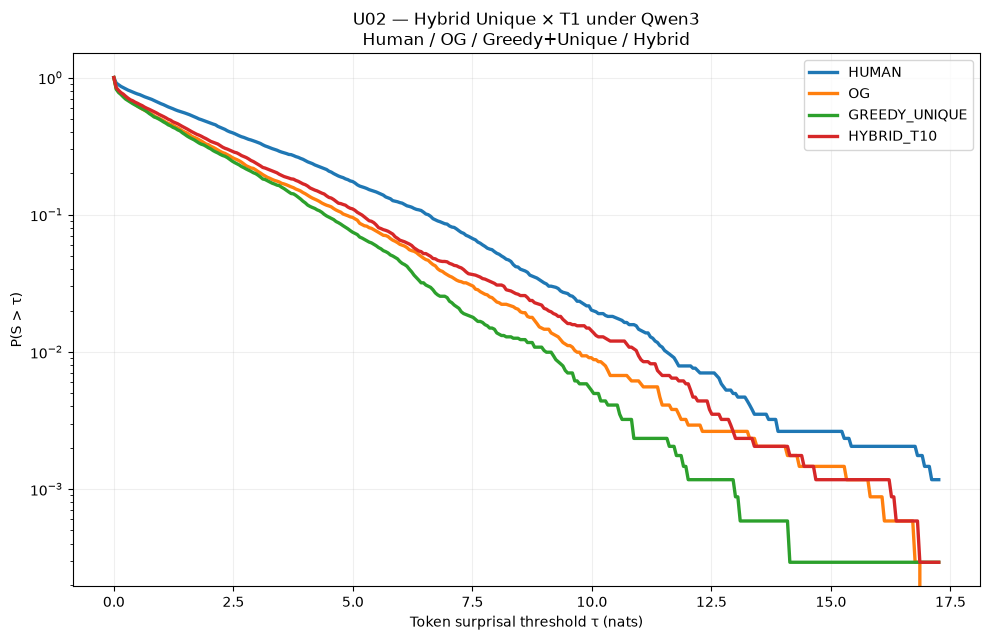


Scorer: GPT2 gpt2


Scoring GPT2: 100%|████████████████████████████████████████████████████████████████████████████████████| 80/80 [00:00<00:00, 100.02it/s]


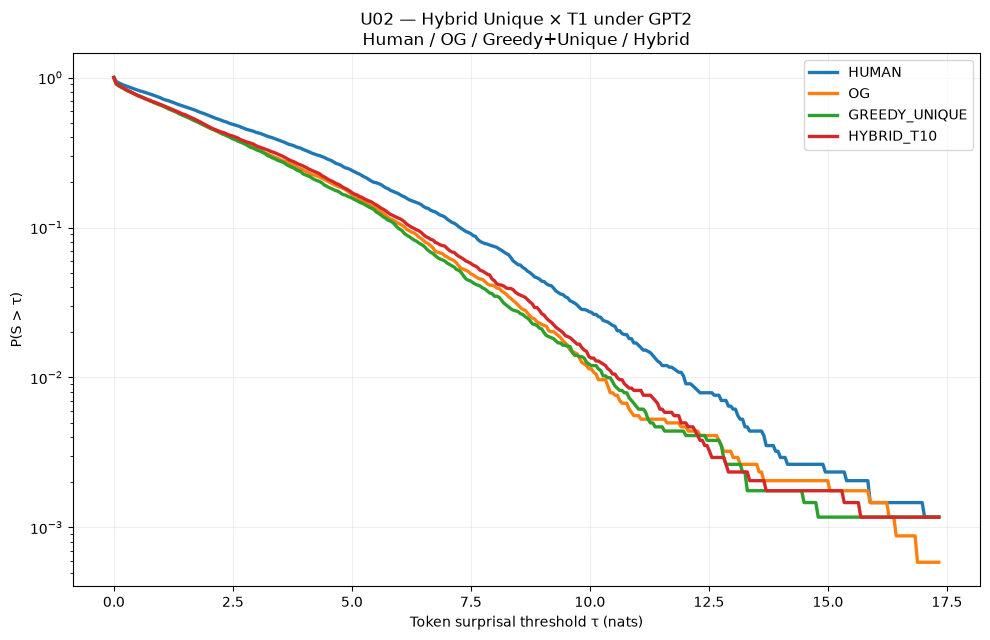


Scorer: SmolLM2 HuggingFaceTB/SmolLM2-360M


Scoring SmolLM2: 100%|██████████████████████████████████████████████████████████████████████████████████| 80/80 [00:01<00:00, 47.61it/s]


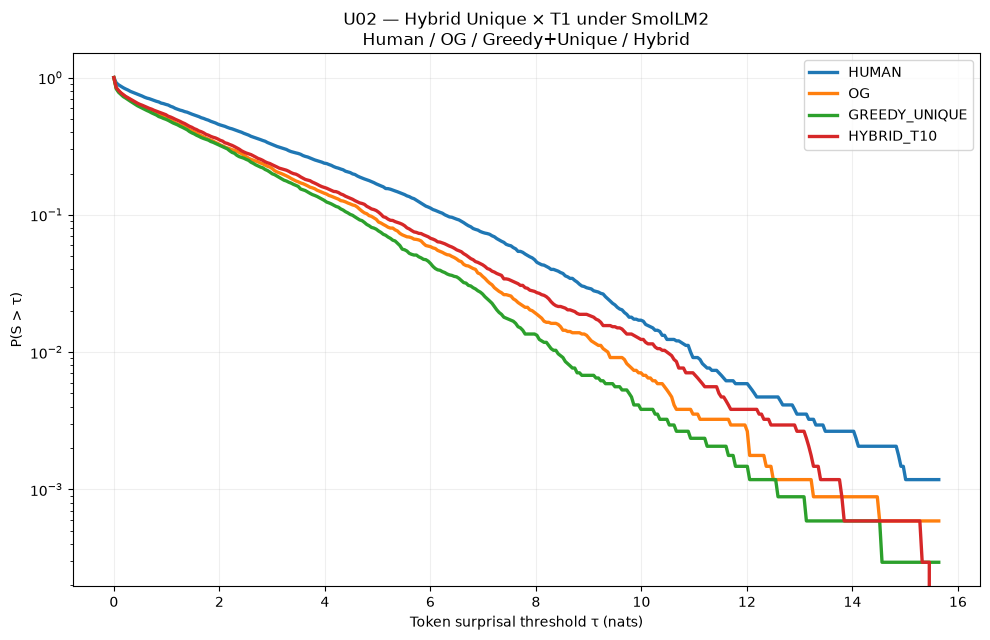


Mean post-warmup surprisal:


scorer,GPT2,Qwen3,SmolLM2
condition,,,
GREEDY_UNIQUE,2.502744,1.656224,1.678193
HUMAN,3.205569,2.643272,2.548970
HYBRID_T10,2.633755,1.964212,1.933959
OG,2.548546,1.791553,1.800987



Primary U02 result: paired Hybrid - Greedy+Unique


,scorer,mean_delta_S_hybrid_minus_greedy,ci_low,ci_high,positive_case_fraction,median_delta_S
0,Qwen3,0.278259,0.055911,0.522079,0.70,0.134032
1,GPT2,0.126636,-0.043939,0.309658,0.55,0.111738
2,SmolLM2,0.224492,0.036272,0.424226,0.65,0.141605



Tail rates at τ=6:


scorer,GPT2,Qwen3,SmolLM2
condition,,,
GREEDY_UNIQUE,0.098039,0.044763,0.045053
HUMAN,0.165935,0.121709,0.111896
HYBRID_T10,0.115013,0.064950,0.068021
OG,0.105648,0.060562,0.058893


Saved evaluation: ../results/causal/U02_hybrid_unique_sampling/cross_scorer


In [12]:

# Cross-scorer evaluation of the U02 causal comparison.
# Scorers are observers only; none participates in generation.

# Free Llama before sequential scorer loading.
for name in ["model", "tok"]:
    if name in globals():
        del globals()[name]

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

import matplotlib.pyplot as plt

SCORERS = {
    "Qwen3": "Qwen/Qwen3-0.6B-Base",
    "GPT2": "gpt2",
    "SmolLM2": "HuggingFaceTB/SmolLM2-360M",
}

MAX_COMPARE_TOKENS = 256
POST_CUT_FRACTION = 0.20
EVAL_DIR = OUT / "cross_scorer"
EVAL_DIR.mkdir(exist_ok=True)

FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

# Matched human map used in U01d.
HUMAN_SPLIT_PATH = ROOT / "results/causal/C02w_adaptive_camouflage_v1/split.csv"
assert HUMAN_SPLIT_PATH.exists(), HUMAN_SPLIT_PATH

split = pd.read_csv(HUMAN_SPLIT_PATH)
split["case_id"] = split["case_id"].astype(str)
human_map = (
    split[["case_id", "human_source_id", "human_domain"]]
    .drop_duplicates("case_id")
    .set_index("case_id")
)

human_text_lookup = (
    paired.drop_duplicates("source_id")
    .set_index("source_id")["text"]
    .to_dict()
)

baseline_lookup = baseline.set_index("case_id")["generated_text"].to_dict()
hybrid_lookup = hybrid_gen.assign(
    case_id=hybrid_gen.case_id.astype(str)
).set_index("case_id")["generated_text"].to_dict()

CONDITIONS = ["HUMAN", "OG", "GREEDY_UNIQUE", "HYBRID_T10"]
text_panel = {}

for r in cohort.itertuples(index=False):
    cid = str(r.case_id)
    human_sid = str(human_map.loc[cid, "human_source_id"])
    assert human_sid in human_text_lookup, (cid, human_sid)

    text_panel[cid] = {
        "HUMAN": str(human_text_lookup[human_sid]),
        "OG": str(r.previous_ai),
        "GREEDY_UNIQUE": str(baseline_lookup[cid]),
        "HYBRID_T10": str(hybrid_lookup[cid]),
    }


def score_text(text, tokenizer, scorer):
    ids_all = tokenizer(text, add_special_tokens=False)["input_ids"]
    n_total = len(ids_all)
    ids = ids_all[:MAX_COMPARE_TOKENS]

    if len(ids) < 2:
        return n_total, np.array([], dtype=np.float32)

    x = torch.tensor([ids], dtype=torch.long, device=device)

    with torch.inference_mode():
        out = scorer(input_ids=x, use_cache=False)
        logits = out.logits[:, :-1, :].float()
        targets = x[:, 1:]
        losses = F.cross_entropy(
            logits.reshape(-1, logits.shape[-1]),
            targets.reshape(-1),
            reduction="none",
        )

    arr = losses.detach().cpu().numpy().astype(np.float32)
    del x, out, logits, targets, losses
    return n_total, arr


def bootstrap_mean_ci(values, n_boot=10000, seed=20260917):
    values = np.asarray(values, float)
    rng = np.random.default_rng(seed)
    n = len(values)
    boots = np.empty(n_boot, float)

    for i in range(n_boot):
        boots[i] = rng.choice(values, size=n, replace=True).mean()

    return (
        float(values.mean()),
        float(np.quantile(boots, 0.025)),
        float(np.quantile(boots, 0.975)),
    )


def savefig_both(fig, stem):
    for ext in ("png", "pdf"):
        fig.savefig(EVAL_DIR / f"{stem}.{ext}", dpi=300, bbox_inches="tight")
        fig.savefig(FIG_DIR / f"U02_{stem}.{ext}", dpi=300, bbox_inches="tight")


summary_rows = []
paired_rows = []
tail_rows = []

for scorer_name, scorer_id in SCORERS.items():
    print("\nScorer:", scorer_name, scorer_id)

    cache_path = EVAL_DIR / f"{scorer_name}_losses.parquet"
    scored = pd.read_parquet(cache_path) if cache_path.exists() else pd.DataFrame()

    done = (
        set(zip(
            scored.case_id.astype(str),
            scored.condition.astype(str),
        ))
        if len(scored)
        else set()
    )

    stok = AutoTokenizer.from_pretrained(scorer_id, use_fast=True)
    smodel = AutoModelForCausalLM.from_pretrained(
        scorer_id,
        dtype=dtype,
        low_cpu_mem_usage=True,
    ).to(device).eval()

    jobs = [
        (cid, condition, text_panel[cid][condition])
        for cid in text_panel
        for condition in CONDITIONS
    ]

    for cid, condition, text in tqdm(jobs, desc=f"Scoring {scorer_name}"):
        if (cid, condition) in done:
            continue

        n_total, losses = score_text(text, stok, smodel)

        row = pd.DataFrame([{
            "case_id": cid,
            "condition": condition,
            "n_scorer_tokens": n_total,
            "losses": losses.tolist(),
        }])

        scored = pd.concat([scored, row], ignore_index=True)
        scored.to_parquet(cache_path, index=False)
        done.add((cid, condition))

    loss_lookup = {
        (str(r.case_id), str(r.condition)):
            np.asarray(r.losses, dtype=float)
        for r in scored.itertuples(index=False)
    }
    length_lookup = {
        (str(r.case_id), str(r.condition)):
            int(r.n_scorer_tokens)
        for r in scored.itertuples(index=False)
    }

    suffixes = {c: [] for c in CONDITIONS}
    case_means = []

    for cid in text_panel:
        per_case = {
            c: loss_lookup[(cid, c)]
            for c in CONDITIONS
        }

        m = min(len(v) for v in per_case.values())
        og_total = length_lookup[(cid, "OG")]
        cut = int(np.ceil(POST_CUT_FRACTION * og_total))

        if cut >= m:
            continue

        row = {"scorer": scorer_name, "case_id": cid}

        for c in CONDITIONS:
            suffix = per_case[c][cut:m]
            suffixes[c].append(suffix)
            row[c] = float(suffix.mean())

        case_means.append(row)

    case_means = pd.DataFrame(case_means)
    assert len(case_means) == 20, (scorer_name, len(case_means))

    agg = {
        c: np.concatenate(suffixes[c])
        for c in CONDITIONS
    }

    for c in CONDITIONS:
        x = agg[c]
        summary_rows.append({
            "scorer": scorer_name,
            "condition": c,
            "n_tokens": len(x),
            "mean": float(x.mean()),
            "median": float(np.median(x)),
            "q90": float(np.quantile(x, .90)),
            "q95": float(np.quantile(x, .95)),
            "q99": float(np.quantile(x, .99)),
        })

        for tau in [4, 6, 8, 10]:
            tail_rows.append({
                "scorer": scorer_name,
                "condition": c,
                "tau": tau,
                "P_S_gt_tau": float(np.mean(x > tau)),
            })

    delta = (
        case_means["HYBRID_T10"].to_numpy()
        - case_means["GREEDY_UNIQUE"].to_numpy()
    )
    mean_delta, ci_low, ci_high = bootstrap_mean_ci(delta)

    paired_rows.append({
        "scorer": scorer_name,
        "mean_delta_S_hybrid_minus_greedy": mean_delta,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "positive_case_fraction": float(np.mean(delta > 0)),
        "median_delta_S": float(np.median(delta)),
    })

    xmax = min(
        20.0,
        max(np.quantile(x, .999) for x in agg.values()),
    )
    taus = np.linspace(0, xmax, 350)

    fig, ax = plt.subplots(figsize=(10, 6.5))

    for c in CONDITIONS:
        survival = np.array([
            np.mean(agg[c] > tau)
            for tau in taus
        ])
        ax.plot(taus, survival, linewidth=2.4, label=c)

    ax.set_yscale("log")
    ax.set_xlabel("Token surprisal threshold τ (nats)")
    ax.set_ylabel("P(S > τ)")
    ax.set_title(
        f"U02 — Hybrid Unique × T1 under {scorer_name}\n"
        "Human / OG / Greedy+Unique / Hybrid"
    )
    ax.grid(alpha=.2)
    ax.legend()
    fig.tight_layout()

    savefig_both(fig, f"hybrid_survival_{scorer_name}")
    plt.show()

    del smodel, stok
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()


cross_summary = pd.DataFrame(summary_rows)
cross_paired = pd.DataFrame(paired_rows)
cross_tail = pd.DataFrame(tail_rows)

cross_summary.to_csv(EVAL_DIR / "summary.csv", index=False)
cross_paired.to_csv(EVAL_DIR / "paired_hybrid_minus_greedy.csv", index=False)
cross_tail.to_csv(EVAL_DIR / "tail_rates.csv", index=False)

print("\nMean post-warmup surprisal:")
display(
    cross_summary.pivot(
        index="condition",
        columns="scorer",
        values="mean",
    )
)

print("\nPrimary U02 result: paired Hybrid - Greedy+Unique")
display(cross_paired)

print("\nTail rates at τ=6:")
display(
    cross_tail.loc[cross_tail.tau.eq(6)]
    .pivot(
        index="condition",
        columns="scorer",
        values="P_S_gt_tau",
    )
)

print("Saved evaluation:", EVAL_DIR)



## Interpretation contract

U02 is deliberately narrow. It asks whether we can spend **Unique-free or
Unique-equivalent token opportunities** on the already-verified `T=1, top_p=1`
secondary policy without materially degrading Unique-band control or visible text
quality.

Do **not** infer a precise numerical sanity cost from this notebook. The sanity
sheet is for author inspection. If Hybrid visibly degrades or produces
lobotomized/repetitive output, stop here and inspect the affected trajectories
before building U03.

If Hybrid preserves Unique behavior and raises surprisal across held-out scorers,
U03 should use this U02 controller as its baseline and replace only the secondary
policy with a targeted surprisal nudger.


Common supported positions: 3710
Cases with common support: 20 / 20


,case_id,warmup_words,greedy_words,hybrid_words,common_supported_positions,first_common,last_common
0,gate_0003,59,400,390,326,60,385
1,gate_0016,48,313,307,241,49,289
2,gate_0017,51,405,403,280,52,331
3,gate_0018,48,448,419,241,49,289
4,gate_0024,38,366,237,199,39,237
5,gate_0025,35,358,421,199,36,234
6,gate_0035,32,305,538,178,33,210
7,gate_0038,19,123,207,104,20,123
8,gate_0039,18,413,252,153,19,171
9,gate_0046,20,136,145,110,21,130



Proper common-support Unique metrics:


,n_cases,mean_common_positions,mean_band_distance,mean_normalized_band_distance,mean_fraction_in_band,mean_target_mismatch_rate
condition,,,,,,
GREEDY_UNIQUE,20,185.5,0.026446,0.477693,0.524704,0.469729
HYBRID_T10,20,185.5,0.011962,0.239008,0.660361,0.441750



Paired Hybrid - Greedy Unique:


,case_id,delta_mean_band_distance,delta_normalized_band_distance,delta_fraction_in_band,delta_target_mismatch_rate
case_id,,,,,
gate_0003,gate_0003,-0.000733,0.006025,0.067485,-0.008502
gate_0016,gate_0016,0.000138,0.004008,-0.024896,0.091064
gate_0017,gate_0017,-0.001777,-0.038762,-0.003571,0.010179
gate_0018,gate_0018,-0.009421,-0.190392,0.128631,0.070539
gate_0024,gate_0024,-0.050164,-1.043207,0.708543,-0.388228
gate_0025,gate_0025,0.005191,0.084726,-0.060302,-0.028986
gate_0035,gate_0035,0.000176,0.002298,-0.016854,0.096154
gate_0038,gate_0038,-0.002193,-0.031407,0.153846,-0.037577
gate_0039,gate_0039,-0.003723,-0.012007,-0.156863,0.070968



Paired summary:


,count,mean,std,min,25%,50%,75%,max
delta_mean_band_distance,20.0,-0.014484,0.042008,-0.171544,-0.012804,-0.001449,0.000034,0.040397
delta_normalized_band_distance,20.0,-0.238686,0.712786,-2.809186,-0.230743,-0.021707,0.004512,0.840678
delta_fraction_in_band,20.0,0.135657,0.339455,-0.484694,-0.024922,0.056819,0.193055,0.914634
delta_target_mismatch_rate,20.0,-0.027979,0.153625,-0.388228,-0.056083,-0.011085,0.075992,0.176080



Accepted Unique-active samples: 2073
Novelty-class violations: 0


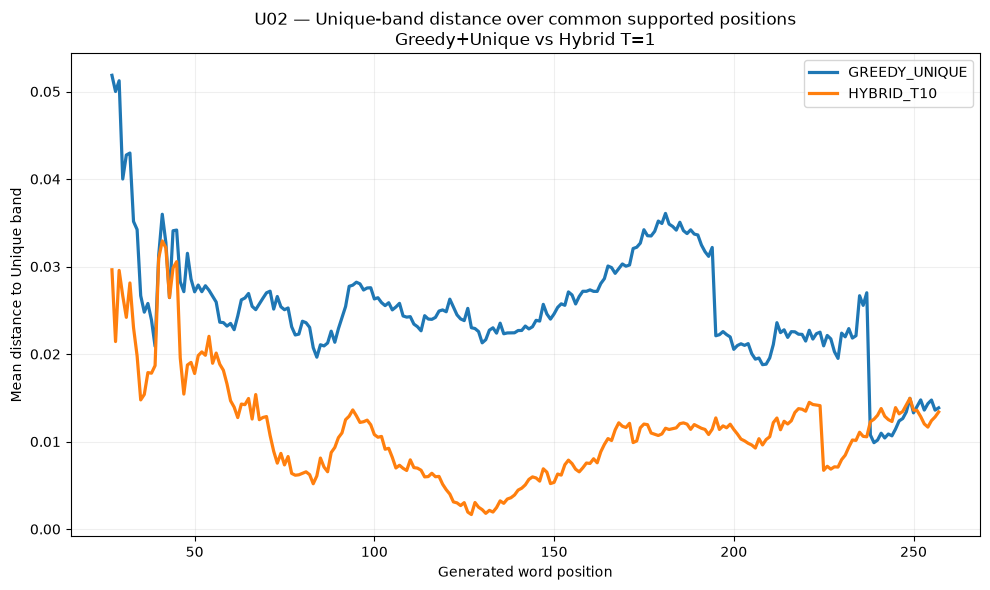

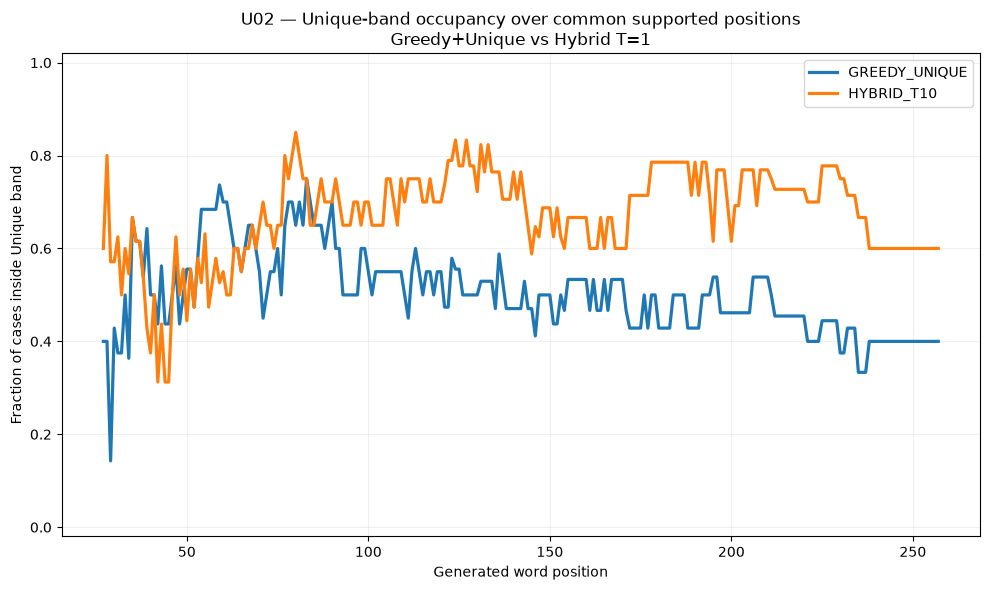


Saved proper Unique robustness audit to: ../results/causal/U02_hybrid_unique_sampling


In [13]:
# ============================================================
# U02 — proper paired Unique-robustness audit
#
# Fixes the endpoint-support problem in the earlier comparison.
#
# For each case:
#   1. reconstruct the running Unique trajectory directly from
#      GREEDY_UNIQUE and HYBRID_T10 final texts;
#   2. compare ONLY word positions shared by both outputs;
#   3. require the frozen human Unique reference to support that
#      word position;
#   4. evaluate only after the case-specific Unique warmup;
#   5. measure:
#        - distance to Unique band over time
#        - normalized distance
#        - fraction in band
#        - Unique target-class mismatch rate
#   6. independently audit that accepted Hybrid sampling at
#      Unique-active positions never crossed novelty class.
#
# Negative Hybrid-Greedy distance delta = Hybrid is BETTER.
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


# ------------------------------------------------------------
# 1. Reconstruct running Unique trajectory from final text.
# ------------------------------------------------------------

def reconstruct_unique_trajectory(
    case_id,
    condition,
    text,
):
    cid = str(case_id)

    curve = case_contract[cid]["curve"]
    warmup_words = int(
        case_contract[cid]["warmup_words"]
    )

    words = [
        w.lower()
        for w, _, _ in word_spans(str(text))
    ]

    seen = set()
    V = 0

    previous_mode = "normal"

    rows = []

    for word_index, word in enumerate(
        words,
        start=1,
    ):

        W_before = word_index - 1

        ref_before = reference_at(
            curve,
            W_before,
        )

        mode_before = adaptive_mode(
            previous_mode,
            V,
            W_before,
            warmup_words,
            ref_before,
        )

        unique_active = (
            mode_before
            in {
                "increase",
                "decrease",
            }
        )

        wanted_novel = (
            True
            if mode_before == "increase"
            else False
            if mode_before == "decrease"
            else None
        )

        chosen_novel = (
            word not in seen
        )

        V_after = (
            V
            + int(chosen_novel)
        )

        W_after = word_index

        k_after = (
            V_after
            / W_after
        )

        ref_after = reference_at(
            curve,
            W_after,
        )

        supported = bool(
            ref_after.get(
                "supported",
                False,
            )
        )

        if supported:

            low = float(
                ref_after["H_h30"]
            )

            high = float(
                ref_after["H_a10"]
            )

            band_width = max(
                high - low,
                1 / W_after,
            )

            band_distance = max(
                low - k_after,
                0.0,
                k_after - high,
            )

            normalized_distance = (
                band_distance
                / band_width
            )

            in_band = (
                low
                <= k_after
                <= high
            )

        else:

            low = np.nan
            high = np.nan
            band_width = np.nan
            band_distance = np.nan
            normalized_distance = np.nan
            in_band = np.nan


        if unique_active:

            target_match = (
                chosen_novel
                == wanted_novel
            )

        else:

            target_match = np.nan


        rows.append({
            "case_id":
                cid,

            "condition":
                condition,

            "word_index":
                word_index,

            "warmup_words":
                warmup_words,

            "word":
                word,

            "V_after":
                V_after,

            "W_after":
                W_after,

            "k_after":
                k_after,

            "reference_supported":
                supported,

            "band_low":
                low,

            "band_high":
                high,

            "band_width":
                band_width,

            "band_distance":
                band_distance,

            "normalized_band_distance":
                normalized_distance,

            "in_band":
                in_band,

            "mode_before":
                mode_before,

            "unique_active":
                unique_active,

            "wanted_novel":
                wanted_novel,

            "chosen_novel":
                chosen_novel,

            "unique_target_match":
                target_match,
        })


        seen.add(word)

        V = V_after

        previous_mode = (
            mode_before
        )


    return pd.DataFrame(
        rows
    )


# ------------------------------------------------------------
# 2. Reconstruct both conditions.
# ------------------------------------------------------------

greedy_text = (
    baseline
    .assign(
        case_id=
            baseline[
                "case_id"
            ].astype(str)
    )
    .set_index(
        "case_id"
    )[
        "generated_text"
    ]
    .to_dict()
)

hybrid_text = (
    hybrid_gen
    .assign(
        case_id=
            hybrid_gen[
                "case_id"
            ].astype(str)
    )
    .set_index(
        "case_id"
    )[
        "generated_text"
    ]
    .to_dict()
)


trajectory_parts = []

for cid in sorted(
    set(greedy_text)
    & set(hybrid_text)
):

    trajectory_parts.append(
        reconstruct_unique_trajectory(
            cid,
            "GREEDY_UNIQUE",
            greedy_text[cid],
        )
    )

    trajectory_parts.append(
        reconstruct_unique_trajectory(
            cid,
            "HYBRID_T10",
            hybrid_text[cid],
        )
    )


unique_traj = pd.concat(
    trajectory_parts,
    ignore_index=True,
)


# ------------------------------------------------------------
# 3. Keep ONLY common supported post-warmup positions.
#
# This makes the two conditions use exactly the same word
# indices within each case.
# ------------------------------------------------------------

common_parts = []
coverage_rows = []

for cid in sorted(
    unique_traj[
        "case_id"
    ].unique()
):

    g = (
        unique_traj.loc[
            (
                unique_traj[
                    "case_id"
                ].eq(cid)
            )
            &
            (
                unique_traj[
                    "condition"
                ].eq(
                    "GREEDY_UNIQUE"
                )
            )
        ]
        .copy()
    )

    h = (
        unique_traj.loc[
            (
                unique_traj[
                    "case_id"
                ].eq(cid)
            )
            &
            (
                unique_traj[
                    "condition"
                ].eq(
                    "HYBRID_T10"
                )
            )
        ]
        .copy()
    )

    warmup = int(
        case_contract[
            cid
        ][
            "warmup_words"
        ]
    )

    g_valid = set(
        g.loc[
            g[
                "reference_supported"
            ]
            &
            (
                g[
                    "word_index"
                ]
                > warmup
            ),
            "word_index",
        ]
        .astype(int)
    )

    h_valid = set(
        h.loc[
            h[
                "reference_supported"
            ]
            &
            (
                h[
                    "word_index"
                ]
                > warmup
            ),
            "word_index",
        ]
        .astype(int)
    )

    common_w = sorted(
        g_valid
        & h_valid
    )

    coverage_rows.append({
        "case_id":
            cid,

        "warmup_words":
            warmup,

        "greedy_words":
            len(g),

        "hybrid_words":
            len(h),

        "common_supported_positions":
            len(common_w),

        "first_common":
            (
                common_w[0]
                if common_w
                else np.nan
            ),

        "last_common":
            (
                common_w[-1]
                if common_w
                else np.nan
            ),
    })

    if not common_w:
        continue

    common_parts.append(
        g.loc[
            g[
                "word_index"
            ].isin(
                common_w
            )
        ]
    )

    common_parts.append(
        h.loc[
            h[
                "word_index"
            ].isin(
                common_w
            )
        ]
    )


common_unique = pd.concat(
    common_parts,
    ignore_index=True,
)

coverage_unique = pd.DataFrame(
    coverage_rows
)

assert (
    common_unique[
        [
            "case_id",
            "condition",
            "word_index",
        ]
    ]
    .duplicated()
    .sum()
    == 0
)


print(
    "Common supported positions:",
    len(common_unique) // 2,
)

print(
    "Cases with common support:",
    common_unique[
        "case_id"
    ].nunique(),
    "/ 20",
)

display(
    coverage_unique
)


# ------------------------------------------------------------
# 4. Per-case matched metrics.
# ------------------------------------------------------------

case_metric_rows = []

for (
    cid,
    condition
), d in common_unique.groupby(
    [
        "case_id",
        "condition",
    ]
):

    active = d.loc[
        d[
            "unique_active"
        ]
    ]

    target_mismatch_rate = (
        float(
            (
                ~active[
                    "unique_target_match"
                ].astype(bool)
            ).mean()
        )
        if len(active)
        else np.nan
    )


    case_metric_rows.append({
        "case_id":
            cid,

        "condition":
            condition,

        "n_common_positions":
            len(d),

        "mean_band_distance":
            d[
                "band_distance"
            ].mean(),

        "median_band_distance":
            d[
                "band_distance"
            ].median(),

        "mean_normalized_band_distance":
            d[
                "normalized_band_distance"
            ].mean(),

        "max_band_distance":
            d[
                "band_distance"
            ].max(),

        "fraction_in_band":
            d[
                "in_band"
            ].astype(float).mean(),

        "unique_active_positions":
            len(active),

        "unique_target_mismatch_rate":
            target_mismatch_rate,
    })


case_unique_metrics = pd.DataFrame(
    case_metric_rows
)


print(
    "\nProper common-support Unique metrics:"
)

display(
    case_unique_metrics
    .groupby(
        "condition"
    )
    .agg(
        n_cases=(
            "case_id",
            "nunique",
        ),

        mean_common_positions=(
            "n_common_positions",
            "mean",
        ),

        mean_band_distance=(
            "mean_band_distance",
            "mean",
        ),

        mean_normalized_band_distance=(
            "mean_normalized_band_distance",
            "mean",
        ),

        mean_fraction_in_band=(
            "fraction_in_band",
            "mean",
        ),

        mean_target_mismatch_rate=(
            "unique_target_mismatch_rate",
            "mean",
        ),
    )
)


# ------------------------------------------------------------
# 5. Paired Hybrid - Greedy deltas.
# ------------------------------------------------------------

metric_wide = (
    case_unique_metrics
    .pivot(
        index="case_id",
        columns="condition",
    )
)


paired_unique_proper = pd.DataFrame({
    "case_id":
        metric_wide.index,

    "delta_mean_band_distance":
        (
            metric_wide[
                "mean_band_distance"
            ][
                "HYBRID_T10"
            ]
            -
            metric_wide[
                "mean_band_distance"
            ][
                "GREEDY_UNIQUE"
            ]
        ),

    "delta_normalized_band_distance":
        (
            metric_wide[
                "mean_normalized_band_distance"
            ][
                "HYBRID_T10"
            ]
            -
            metric_wide[
                "mean_normalized_band_distance"
            ][
                "GREEDY_UNIQUE"
            ]
        ),

    "delta_fraction_in_band":
        (
            metric_wide[
                "fraction_in_band"
            ][
                "HYBRID_T10"
            ]
            -
            metric_wide[
                "fraction_in_band"
            ][
                "GREEDY_UNIQUE"
            ]
        ),

    "delta_target_mismatch_rate":
        (
            metric_wide[
                "unique_target_mismatch_rate"
            ][
                "HYBRID_T10"
            ]
            -
            metric_wide[
                "unique_target_mismatch_rate"
            ][
                "GREEDY_UNIQUE"
            ]
        ),
})


print(
    "\nPaired Hybrid - Greedy Unique:"
)

display(
    paired_unique_proper
)

print(
    "\nPaired summary:"
)

display(
    paired_unique_proper[
        [
            "delta_mean_band_distance",
            "delta_normalized_band_distance",
            "delta_fraction_in_band",
            "delta_target_mismatch_rate",
        ]
    ]
    .describe()
    .T
)


# ------------------------------------------------------------
# 6. Direct audit of the U02 design invariant:
#
# accepted sampling while Unique-active must NEVER change
# novelty class relative to the canonical ordinary/fallback.
# ------------------------------------------------------------

sample_audit_rows = []

for cid in sorted(
    hybrid_text
):

    state_path = (
        STATE_DIR
        / f"{cid}__HYBRID_T10.json"
    )

    assert state_path.exists(), (
        state_path
    )

    payload = json.loads(
        state_path.read_text()
    )

    state = payload["state"]

    for t in state.get(
        "trajectory",
        [],
    ):

        action = str(
            t.get(
                "action",
                "",
            )
        )

        if action not in {
            "sample_unique_equivalent",
            "sample_fallback_equivalent",
        }:
            continue

        same_class = (
            bool(
                t[
                    "chosen_novel"
                ]
            )
            ==
            bool(
                t[
                    "original_novel"
                ]
            )
        )

        sample_audit_rows.append({
            "case_id":
                cid,

            "word_index":
                t[
                    "word_index"
                ],

            "action":
                action,

            "mode_before":
                t[
                    "mode_before"
                ],

            "original_novel":
                t[
                    "original_novel"
                ],

            "chosen_novel":
                t[
                    "chosen_novel"
                ],

            "same_unique_class":
                same_class,
        })


sample_unique_audit = pd.DataFrame(
    sample_audit_rows
)


if len(
    sample_unique_audit
):

    violations = (
        ~sample_unique_audit[
            "same_unique_class"
        ]
    )

    print(
        "\nAccepted Unique-active samples:",
        len(
            sample_unique_audit
        ),
    )

    print(
        "Novelty-class violations:",
        int(
            violations.sum()
        ),
    )

    assert not violations.any(), (
        "Hybrid sampling crossed "
        "the Unique novelty class."
    )

else:

    print(
        "\nNo Unique-active sampled "
        "acceptances found."
    )


# ------------------------------------------------------------
# 7. Distance-to-band over time.
#
# Only plot word indices represented by >= 5 paired cases.
# ------------------------------------------------------------

distance_time = (
    common_unique
    .groupby(
        [
            "condition",
            "word_index",
        ],
        as_index=False,
    )
    .agg(
        mean_band_distance=(
            "band_distance",
            "mean",
        ),

        median_band_distance=(
            "band_distance",
            "median",
        ),

        fraction_in_band=(
            "in_band",
            "mean",
        ),

        n_cases=(
            "case_id",
            "nunique",
        ),
    )
)


MIN_CASES_FOR_CURVE = 5

distance_plot = (
    distance_time.loc[
        distance_time[
            "n_cases"
        ]
        >= MIN_CASES_FOR_CURVE
    ]
    .copy()
)


fig, ax = plt.subplots(
    figsize=(10, 6)
)

for condition in [
    "GREEDY_UNIQUE",
    "HYBRID_T10",
]:

    d = distance_plot.loc[
        distance_plot[
            "condition"
        ].eq(
            condition
        )
    ]

    ax.plot(
        d[
            "word_index"
        ],
        d[
            "mean_band_distance"
        ],
        linewidth=2.3,
        label=condition,
    )


ax.set_xlabel(
    "Generated word position"
)

ax.set_ylabel(
    "Mean distance to Unique band"
)

ax.set_title(
    "U02 — Unique-band distance over common supported positions\n"
    "Greedy+Unique vs Hybrid T=1"
)

ax.grid(
    alpha=.2
)

ax.legend()

fig.tight_layout()

for ext in [
    "png",
    "pdf",
]:

    fig.savefig(
        OUT
        / (
            "unique_common_support_"
            f"band_distance.{ext}"
        ),
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        ROOT
        / "figures"
        / (
            "U02_unique_common_support_"
            f"band_distance.{ext}"
        ),
        dpi=300,
        bbox_inches="tight",
    )

plt.show()


# ------------------------------------------------------------
# 8. Fraction-in-band over time.
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 6)
)

for condition in [
    "GREEDY_UNIQUE",
    "HYBRID_T10",
]:

    d = distance_plot.loc[
        distance_plot[
            "condition"
        ].eq(
            condition
        )
    ]

    ax.plot(
        d[
            "word_index"
        ],
        d[
            "fraction_in_band"
        ],
        linewidth=2.3,
        label=condition,
    )


ax.set_xlabel(
    "Generated word position"
)

ax.set_ylabel(
    "Fraction of cases inside Unique band"
)

ax.set_ylim(
    -0.02,
    1.02,
)

ax.set_title(
    "U02 — Unique-band occupancy over common supported positions\n"
    "Greedy+Unique vs Hybrid T=1"
)

ax.grid(
    alpha=.2
)

ax.legend()

fig.tight_layout()

for ext in [
    "png",
    "pdf",
]:

    fig.savefig(
        OUT
        / (
            "unique_common_support_"
            f"in_band_fraction.{ext}"
        ),
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        ROOT
        / "figures"
        / (
            "U02_unique_common_support_"
            f"in_band_fraction.{ext}"
        ),
        dpi=300,
        bbox_inches="tight",
    )

plt.show()


# ------------------------------------------------------------
# 9. Save exact audit data.
# ------------------------------------------------------------

unique_traj.to_parquet(
    OUT
    / "unique_reconstructed_trajectories.parquet",
    index=False,
)

common_unique.to_parquet(
    OUT
    / "unique_common_supported_positions.parquet",
    index=False,
)

coverage_unique.to_csv(
    OUT
    / "unique_common_support_coverage.csv",
    index=False,
)

case_unique_metrics.to_csv(
    OUT
    / "unique_common_support_case_metrics.csv",
    index=False,
)

paired_unique_proper.to_csv(
    OUT
    / "unique_common_support_paired_deltas.csv",
    index=False,
)

sample_unique_audit.to_csv(
    OUT
    / "hybrid_unique_equivalence_audit.csv",
    index=False,
)


print(
    "\nSaved proper Unique robustness audit to:",
    OUT,
)

In [14]:
# ============================================================
# U02 — print flagged sanity cases for manual reading
# ============================================================

FLAGGED_CASES = [
    "gate_0035",
    "gate_0070",
    "gate_0039",
    "gate_0078",
    "gate_0025",
]

cohort_lookup = (
    cohort
    .assign(case_id=cohort["case_id"].astype(str))
    .set_index("case_id")
)

greedy_lookup = (
    baseline
    .assign(case_id=baseline["case_id"].astype(str))
    .set_index("case_id")
)

hybrid_lookup = (
    hybrid_gen
    .assign(case_id=hybrid_gen["case_id"].astype(str))
    .set_index("case_id")
)


for cid in FLAGGED_CASES:

    src = cohort_lookup.loc[cid]
    g = greedy_lookup.loc[cid]
    h = hybrid_lookup.loc[cid]

    print("\n" + "=" * 110)
    print(cid, "|", src["domain"])
    print("=" * 110)

    print(
        f"\nLengths:"
        f" previous={counts(src['previous_ai'])[1]} words"
        f" | greedy={counts(g['generated_text'])[1]} words"
        f" | hybrid={counts(h['generated_text'])[1]} words"
    )

    print(
        f"Hybrid stop={h['stop_reason']}"
        f" | sample accepts={h['secondary_sample_accepts']}"
        f" | unique share={h['share_unique_words']:.4f}"
    )

    print("\n" + "-" * 110)
    print("ORIGINAL TASK")
    print("-" * 110)
    print(src["prompt"])

    print("\n" + "-" * 110)
    print("PREVIOUS AI ANSWER")
    print("-" * 110)
    print(src["previous_ai"])

    print("\n" + "-" * 110)
    print("GREEDY + UNIQUE")
    print("-" * 110)
    print(g["generated_text"])

    print("\n" + "-" * 110)
    print("HYBRID T1")
    print("-" * 110)
    print(h["generated_text"])

    print("\n")


gate_0035 | books

Lengths: previous=210 words | greedy=305 words | hybrid=538 words
Hybrid stop=truncated | sample accepts=524 | unique share=0.8197

--------------------------------------------------------------------------------------------------------------
ORIGINAL TASK
--------------------------------------------------------------------------------------------------------------
Write the body of a plot summary for a novel titled "The Last Children of Schewenborn". Do not give it a title.

--------------------------------------------------------------------------------------------------------------
PREVIOUS AI ANSWER
--------------------------------------------------------------------------------------------------------------
"The Last Children of Schewenborn" is a chilling post-apocalyptic novel that explores the aftermath of a nuclear war in the small German town of Schewenborn. The story is told through the eyes of a young boy named Peter, who, along with his family, struggles

In [16]:
# ============================================================
# U02 — print flagged cases with ACTUAL Unique interventions red
#
# Source of truth:
#   OUT/states/<case>__HYBRID_T10.json
#
# RED = action == "backtracked"
#       i.e. Unique rejected the ordinary continuation and
#       successfully substituted a different word.
#
# Orange = sampled word at a Unique-active position that was
#          explicitly Unique-equivalent (same novelty class).
#
# Plain black = Unique inactive / ordinary / other.
# ============================================================

import json
import html
from IPython.display import display, HTML


FLAGGED_CASES = [
    "gate_0035",
    "gate_0070",
    "gate_0039",
    "gate_0078",
    "gate_0025",
]


cohort_lookup = (
    cohort
    .assign(
        case_id=cohort["case_id"].astype(str)
    )
    .set_index("case_id")
)

greedy_lookup = (
    baseline
    .assign(
        case_id=baseline["case_id"].astype(str)
    )
    .set_index("case_id")
)

hybrid_lookup = (
    hybrid_gen
    .assign(
        case_id=hybrid_gen["case_id"].astype(str)
    )
    .set_index("case_id")
)


# ------------------------------------------------------------
# Highlight exact character spans in the FINAL generated text.
# ------------------------------------------------------------

def render_hybrid_trace(
    cid,
    text,
):

    state_path = (
        STATE_DIR
        / f"{cid}__HYBRID_T10.json"
    )

    assert state_path.exists(), state_path

    payload = json.loads(
        state_path.read_text()
    )

    trajectory = (
        payload[
            "state"
        ]
        .get(
            "trajectory",
            []
        )
    )

    # word_spans returns:
    # [(word, char_start, char_end), ...]
    spans = word_spans(
        str(text)
    )

    # Map 1-based word index -> trajectory record.
    trace_by_index = {
        int(t["word_index"]):
            t

        for t in trajectory

        if "word_index" in t
    }


    # --------------------------------------------------------
    # Sanity check alignment.
    # --------------------------------------------------------

    mismatches = []

    for i, (
        word,
        start,
        end,
    ) in enumerate(
        spans,
        start=1,
    ):

        t = trace_by_index.get(i)

        if t is None:
            continue

        trace_word = str(
            t.get(
                "word",
                "",
            )
        )

        if (
            trace_word
            and
            trace_word.lower()
            != word.lower()
        ):

            mismatches.append(
                (
                    i,
                    word,
                    trace_word,
                )
            )


    # --------------------------------------------------------
    # Render exact original text with span coloring.
    # --------------------------------------------------------

    chunks = []

    cursor = 0

    unique_swaps = []
    unique_equivalent_samples = []

    for i, (
        word,
        start,
        end,
    ) in enumerate(
        spans,
        start=1,
    ):

        # Preserve text/punctuation before this word.
        chunks.append(
            html.escape(
                str(text)[
                    cursor:start
                ]
            )
        )

        t = trace_by_index.get(
            i,
            {}
        )

        action = str(
            t.get(
                "action",
                ""
            )
        )

        escaped_word = html.escape(
            str(text)[
                start:end
            ]
        )


        # ----------------------------------------------------
        # REAL Unique replacement.
        # ----------------------------------------------------

        if action == "backtracked":

            chunks.append(
                "<span "
                "style='"
                "color:#d00000;"
                "font-weight:800;"
                "background:#ffeaea;"
                "' "
                f"title='Unique replacement | word {i}'"
                ">"
                f"{escaped_word}"
                "</span>"
            )

            unique_swaps.append({
                "word_index":
                    i,

                "word":
                    word,

                "original_word":
                    t.get(
                        "original_word"
                    ),

                "mode":
                    t.get(
                        "mode_before"
                    ),

                "chosen_novel":
                    t.get(
                        "chosen_novel"
                    ),
            })


        # ----------------------------------------------------
        # Sample accepted while Unique-active, but same class.
        # Useful context, but NOT a Unique replacement.
        # ----------------------------------------------------

        elif action in {
            "sample_unique_equivalent",
            "sample_fallback_equivalent",
        }:

            chunks.append(
                "<span "
                "style='"
                "color:#c86b00;"
                "font-weight:700;"
                "' "
                f"title='Unique-equivalent T1 sample | word {i}'"
                ">"
                f"{escaped_word}"
                "</span>"
            )

            unique_equivalent_samples.append({
                "word_index":
                    i,

                "word":
                    word,

                "action":
                    action,

                "mode":
                    t.get(
                        "mode_before"
                    ),
            })


        else:

            chunks.append(
                escaped_word
            )


        cursor = end


    chunks.append(
        html.escape(
            str(text)[cursor:]
        )
    )


    rendered = (
        "<div "
        "style='"
        "white-space:pre-wrap;"
        "font-family:monospace;"
        "font-size:13px;"
        "line-height:1.5;"
        "'>"
        +
        "".join(chunks)
        +
        "</div>"
    )


    return {
        "html":
            rendered,

        "unique_swaps":
            unique_swaps,

        "unique_equivalent_samples":
            unique_equivalent_samples,

        "mismatches":
            mismatches,

        "trajectory":
            trajectory,
    }


# ------------------------------------------------------------
# Print / render cases.
# ------------------------------------------------------------

for cid in FLAGGED_CASES:

    src = cohort_lookup.loc[
        cid
    ]

    g = greedy_lookup.loc[
        cid
    ]

    h = hybrid_lookup.loc[
        cid
    ]

    result = render_hybrid_trace(
        cid,
        h[
            "generated_text"
        ],
    )

    swaps = result[
        "unique_swaps"
    ]

    equiv = result[
        "unique_equivalent_samples"
    ]

    mismatches = result[
        "mismatches"
    ]


    header = f"""
    <div style="
        font-family:monospace;
        margin-top:24px;
    ">

    <h2>{html.escape(cid)} | {html.escape(str(src['domain']))}</h2>

    <div>
    previous={counts(src['previous_ai'])[1]} words |
    greedy={counts(g['generated_text'])[1]} words |
    hybrid={counts(h['generated_text'])[1]} words
    </div>

    <div>
    Hybrid stop={html.escape(str(h['stop_reason']))} |
    sample accepts={int(h['secondary_sample_accepts'])} |
    unique replacements={len(swaps)}
    </div>

    <br>

    <div>
      <span style="
          color:#d00000;
          font-weight:800;
          background:#ffeaea;
      ">
      RED
      </span>
      = actual Unique replacement
    </div>

    <div>
      <span style="
          color:#c86b00;
          font-weight:700;
      ">
      ORANGE
      </span>
      = T1 sample accepted at a Unique-active position,
      but preserving the same novelty class
    </div>

    </div>
    """

    display(
        HTML(
            header
        )
    )


    print(
        "\nUNIQUE SWAPS:",
        len(swaps),
    )

    if swaps:

        display(
            pd.DataFrame(
                swaps
            )
        )


    print(
        "Unique-active equivalent samples:",
        len(equiv),
    )

    print(
        "Trace/text alignment mismatches:",
        len(mismatches),
    )

    if mismatches[:10]:

        display(
            pd.DataFrame(
                mismatches[:10],
                columns=[
                    "word_index",
                    "final_text_word",
                    "trajectory_word",
                ],
            )
        )


    display(
        HTML(
            "<h3>HYBRID T1</h3>"
            +
            result["html"]
        )
    )

    display(
        HTML(
            "<hr style='"
            "margin:40px 0;"
            "border:0;"
            "border-top:2px solid #aaa;"
            "'>"
        )
    )


UNIQUE SWAPS: 13


,word_index,word,original_word,mode,chosen_novel
0,58,the,its,decrease,False
1,60,blast,realm,decrease,False
2,62,the,radioactive,decrease,False
3,66,ravaged,rages,decrease,False
4,68,town,unsuspecting,decrease,False
5,152,young,fragile,decrease,False
6,155,and,displays,decrease,False
7,165,desperate,grueling,decrease,False
8,177,unforgiving,toxic,decrease,False
9,183,life,meager,decrease,False


Unique-active equivalent samples: 28
Trace/text alignment mismatches: 0



UNIQUE SWAPS: 18


,word_index,word,original_word,mode,chosen_novel
0,52,Dick,mostly,decrease,False
1,59,the,raw,decrease,False
2,68,in,become,decrease,False
3,79,the,passengers,decrease,False
4,102,finds,soon,decrease,False
5,107,a,an,decrease,False
6,110,keep,outwit,decrease,False
7,139,and,steamship,decrease,False
8,140,intelligent,beautiful,decrease,False
9,144,and,Halma,decrease,False


...

,word_index,word,original_word,mode,chosen_novel
0,130,In,Demographics,decrease,False
1,133,century,years,decrease,False
2,135,was,experienced,decrease,False
3,137,small,hub,decrease,False


Unique-active equivalent samples: 80
Trace/text alignment mismatches: 0



UNIQUE SWAPS: 18


,word_index,word,original_word,mode,chosen_novel
0,46,finely,grated,decrease,False
1,47,chopped,grated,decrease,False
2,52,finely,grated,decrease,False
3,53,chopped,grated,decrease,False
4,63,dry,white,decrease,False
5,67,sesame,toasted,decrease,False
6,73,white,black,decrease,False
7,78,for,optional,decrease,False
8,81,chopped,thinly,decrease,False
9,101,duck,sesame,increase,True


Unique-active equivalent samples: 118
Trace/text alignment mismatches: 0


In [17]:
# ============================================================
# U02 — inspect the exact decision boundary around sanity break
# ============================================================

CASE_ID = "gate_0070"
BREAK_WORD = "Alternatively"
WINDOW_BEFORE = 12
WINDOW_AFTER = 20


state_path = (
    STATE_DIR
    / f"{CASE_ID}__HYBRID_T10.json"
)

payload = json.loads(
    state_path.read_text()
)

trajectory = payload[
    "state"
].get(
    "trajectory",
    []
)

assert trajectory


# ------------------------------------------------------------
# Find requested occurrence.
# ------------------------------------------------------------

hits = []

for i, t in enumerate(
    trajectory
):

    word = str(
        t.get(
            "word",
            ""
        )
    )

    if (
        word.lower()
        ==
        BREAK_WORD.lower()
    ):

        hits.append(i)


print(
    "Occurrences:",
    [
        trajectory[i][
            "word_index"
        ]
        for i in hits
    ]
)

assert hits, (
    CASE_ID,
    BREAK_WORD,
)

center = hits[0]

lo = max(
    0,
    center - WINDOW_BEFORE,
)

hi = min(
    len(trajectory),
    center + WINDOW_AFTER + 1,
)


# ------------------------------------------------------------
# Compact diagnostic table.
# ------------------------------------------------------------

rows = []

for j in range(
    lo,
    hi,
):

    t = trajectory[j]

    branch_probs = (
        t.get(
            "branch_probabilities",
            []
        )
        or []
    )

    rows.append({
        "offset":
            j - center,

        "word_index":
            t.get(
                "word_index"
            ),

        "word":
            t.get(
                "word"
            ),

        "action":
            t.get(
                "action"
            ),

        "secondary_policy":
            t.get(
                "secondary_policy"
            ),

        "unique_active":
            t.get(
                "unique_active"
            ),

        "mode":
            t.get(
                "mode_before"
            ),

        "sample_attempted":
            t.get(
                "sample_attempted"
            ),

        "sample_accepted":
            t.get(
                "sample_accepted"
            ),

        "original_word":
            t.get(
                "original_word"
            ),

        "original_novel":
            t.get(
                "original_novel"
            ),

        "chosen_novel":
            t.get(
                "chosen_novel"
            ),

        "fallback_reason":
            t.get(
                "fallback_reason"
            ),

        "theta":
            t.get(
                "theta"
            ),

        "Q":
            t.get(
                "Q"
            ),

        "k_before":
            t.get(
                "k_before"
            ),

        "k_after":
            t.get(
                "k_after"
            ),

        "n_branch_tokens":
            len(
                t.get(
                    "branch_tokens",
                    []
                )
                or []
            ),

        "min_branch_prob":
            (
                min(
                    branch_probs
                )
                if branch_probs
                else np.nan
            ),
    })


boundary_df = pd.DataFrame(
    rows
)

display(
    boundary_df
)


# ------------------------------------------------------------
# Very compact readable trace.
# ------------------------------------------------------------

print(
    "\nDecision trace:"
)

for r in rows:

    marker = (
        " <<< BREAK"
        if r["offset"] == 0
        else ""
    )

    print(
        f"{r['offset']:+3d}  "
        f"{int(r['word_index']):4d}  "
        f"{str(r['word']):20s}  "
        f"{str(r['action']):28s}  "
        f"mode={str(r['mode']):8s}  "
        f"sample={str(r['sample_accepted']):5s}  "
        f"orig={str(r['original_word']):18s}"
        f"{marker}"
    )


# ------------------------------------------------------------
# Summarize the break decision itself.
# ------------------------------------------------------------

b = trajectory[
    center
]

print(
    "\nBREAK DECISION"
)

for key in [
    "word_index",
    "word",
    "action",
    "secondary_policy",
    "unique_active",
    "mode_before",
    "sample_attempted",
    "sample_accepted",
    "sample_reject_reason",
    "original_word",
    "original_novel",
    "chosen_novel",
    "fallback_reason",
    "theta",
    "Q",
    "k_before",
    "k_after",
    "distinct_candidates",
    "completed_candidates",
    "search_expanded",
    "branch_tokens",
    "branch_probabilities",
]:

    print(
        f"{key:28s}:",
        b.get(key)
    )

Occurrences: [224]


,offset,word_index,word,action,secondary_policy,unique_active,mode,sample_attempted,sample_accepted,original_word,original_novel,chosen_novel,fallback_reason,theta,Q,k_before,k_after,n_branch_tokens,min_branch_prob
0,-12,212,Despite,sample_inactive,sample_inactive,False,normal,True,True,Despite,False,False,None,None,None,0.573460,0.570755,0,NaN
1,-11,213,the,sample_inactive,sample_inactive,False,normal,True,True,the,False,False,None,None,None,0.570755,0.568075,0,NaN
2,-10,214,varied,sample_inactive,sample_inactive,False,normal,True,True,varied,True,True,None,None,None,0.568075,0.570093,0,NaN
3,-9,215,obstacles,sample_inactive,sample_inactive,False,normal,True,True,obstacles,True,True,None,None,None,0.570093,0.572093,0,NaN
4,-8,216,in,sample_inactive,sample_inactive,False,normal,True,True,in,False,False,None,None,None,0.572093,0.569444,0,NaN
5,-7,217,front,sample_inactive,sample_inactive,False,normal,True,True,front,True,True,None,None,None,0.569444,0.571429,0,NaN
6,-6,218,of,sample_inactive,sample_inactive,False,normal,True,True,of,False,False,None,None,None,0.571429,0.568807,0,NaN
7,-5,219,him,sample_inactive,sample_inactive,False,normal,True,True,him,False,False,None,None,None,0.568807,0.566210,0,NaN
8,-4,220,Dick,sample_inactive,sample_inactive,False,normal,True,True,Dick,False,False,None,None,None,0.566210,0.563636,0,NaN
9,-3,221,never,sample_inactive,sample_inactive,False,normal,True,True,never,True,True,None,None,None,0.563636,0.565611,0,NaN



Decision trace:
-12   212  Despite               sample_inactive               mode=normal    sample=True   orig=Despite           
-11   213  the                   sample_inactive               mode=normal    sample=True   orig=the               
-10   214  varied                sample_inactive               mode=normal    sample=True   orig=varied            
 -9   215  obstacles             sample_inactive               mode=normal    sample=True   orig=obstacles         
 -8   216  in                    sample_inactive               mode=normal    sample=True   orig=in                
 -7   217  front                 sample_inactive               mode=normal    sample=True   orig=front             
 -6   218  of                    sample_inactive               mode=normal    sample=True   orig=of                
 -5   219  him                   sample_inactive               mode=normal    sample=True   orig=him               
 -4   220  Dick                  sample_inactive       

In [19]:
# ============================================================
# U02 — audit where Unique reference support ends
# ============================================================

support_rows = []

for cid in sorted(
    hybrid_gen["case_id"].astype(str)
):

    state_path = (
        STATE_DIR
        / f"{cid}__HYBRID_T10.json"
    )

    payload = json.loads(
        state_path.read_text()
    )

    traj = (
        payload["state"]
        .get("trajectory", [])
    )

    hrow = (
        hybrid_gen.loc[
            hybrid_gen[
                "case_id"
            ].astype(str).eq(cid)
        ]
        .iloc[0]
    )

    total_words = counts(
        hrow["generated_text"]
    )[1]


    unsupported = [
        t
        for t in traj
        if str(
            t.get(
                "mode_before",
                ""
            )
        ) == "unsupported"
    ]

    supported = [
        t
        for t in traj
        if str(
            t.get(
                "mode_before",
                ""
            )
        ) != "unsupported"
    ]

    swaps = [
        t
        for t in traj
        if t.get("action")
        == "backtracked"
    ]


    first_unsupported = (
        int(
            unsupported[0][
                "word_index"
            ]
        )
        if unsupported
        else np.nan
    )

    last_supported = (
        int(
            supported[-1][
                "word_index"
            ]
        )
        if supported
        else np.nan
    )

    last_unique_swap = (
        int(
            swaps[-1][
                "word_index"
            ]
        )
        if swaps
        else np.nan
    )


    support_rows.append({
        "case_id":
            cid,

        "domain":
            hrow["domain"],

        "total_words":
            total_words,

        "generator_tokens":
            int(
                hrow[
                    "generator_tokens"
                ]
            ),

        "last_supported_word":
            last_supported,

        "first_unsupported_word":
            first_unsupported,

        "words_after_support":
            (
                total_words
                - last_supported
                if np.isfinite(
                    last_supported
                )
                else np.nan
            ),

        "last_unique_swap":
            last_unique_swap,

        "gap_last_swap_to_support_end":
            (
                last_supported
                - last_unique_swap
                if (
                    np.isfinite(
                        last_supported
                    )
                    and
                    np.isfinite(
                        last_unique_swap
                    )
                )
                else np.nan
            ),

        "n_unique_swaps":
            len(swaps),

        "stop_reason":
            hrow[
                "stop_reason"
            ],
    })


support_audit = pd.DataFrame(
    support_rows
)


display(
    support_audit.sort_values(
        "words_after_support",
        ascending=False,
    )
)


print(
    "\nCases whose generation outlived "
    "the Unique reference:",
    int(
        (
            support_audit[
                "words_after_support"
            ] > 0
        ).sum()
    ),
    "/",
    len(support_audit),
)

print(
    "Mean uncontrolled suffix:",
    support_audit.loc[
        support_audit[
            "words_after_support"
        ] > 0,
        "words_after_support",
    ].mean(),
    "words",
)

,case_id,domain,total_words,generator_tokens,last_supported_word,first_unsupported_word,words_after_support,last_unique_swap,gap_last_swap_to_support_end,n_unique_swaps,stop_reason
14,gate_0070,books,567,640,230,231.0,337,195.0,35.0,18,truncated
6,gate_0035,books,538,640,211,212.0,327,188.0,23.0,13,truncated
16,gate_0078,wiki,413,543,221,222.0,192,137.0,84.0,4,eos
5,gate_0025,recipes,421,638,235,236.0,186,178.0,57.0,18,truncated
12,gate_0062,reddit,344,416,196,197.0,148,190.0,6.0,22,eos
3,gate_0018,recipes,419,634,290,291.0,129,285.0,5.0,20,eos
11,gate_0051,wiki,337,450,212,213.0,125,96.0,116.0,3,eos
10,gate_0050,reddit,338,401,232,233.0,106,180.0,52.0,33,eos
15,gate_0075,books,342,459,258,259.0,84,234.0,24.0,29,eos
8,gate_0039,wiki,252,389,172,173.0,80,172.0,0.0,9,eos



Cases whose generation outlived the Unique reference: 18 / 20
Mean uncontrolled suffix: 110.61111111111111 words


In [20]:
# ============================================================
# U02 — load U01d pure T1 + pure greedy artifacts from disk
#       and compare against Hybrid
# ============================================================

U01D_OUT = (
    ROOT
    / "results/causal/U01d_unique_guard_ablation"
)

assert U01D_OUT.exists(), U01D_OUT


# ------------------------------------------------------------
# 1. Load pure greedy Llama / WITH_PREV / no Unique.
# ------------------------------------------------------------

PLAIN_PATH = (
    U01D_OUT
    / "llama_withprev_full_no_unique_generations.parquet"
)

assert PLAIN_PATH.exists(), PLAIN_PATH

plain_gen = pd.read_parquet(
    PLAIN_PATH
)


# ------------------------------------------------------------
# 2. Locate the U01d sampling parquet automatically.
# ------------------------------------------------------------

sample_gen = None
SAMPLE_PATH = None

for path in sorted(
    U01D_OUT.glob("*.parquet")
):

    try:
        candidate = pd.read_parquet(
            path
        )
    except Exception:
        continue

    if (
        "decoding_arm"
        in candidate.columns
        and
        candidate[
            "decoding_arm"
        ]
        .astype(str)
        .eq(
            "SAMPLE_T10"
        )
        .any()
    ):

        sample_gen = candidate
        SAMPLE_PATH = path
        break


assert sample_gen is not None, (
    "Could not find the U01d sampling parquet "
    f"under {U01D_OUT}"
)


print(
    "Loaded pure greedy:",
    PLAIN_PATH,
)

print(
    "Loaded sampling:",
    SAMPLE_PATH,
)


# ------------------------------------------------------------
# 3. Compare one suspicious case.
# ------------------------------------------------------------

CASE_ID = "gate_0070"


sample_row = (
    sample_gen.loc[
        sample_gen[
            "case_id"
        ].astype(str).eq(
            CASE_ID
        )
        &
        sample_gen[
            "decoding_arm"
        ].astype(str).eq(
            "SAMPLE_T10"
        )
    ]
)

assert len(sample_row) == 1

sample_t10_text = str(
    sample_row.iloc[0][
        "generated_text"
    ]
)


plain_row = (
    plain_gen.loc[
        plain_gen[
            "case_id"
        ].astype(str).eq(
            CASE_ID
        )
    ]
)

assert len(plain_row) == 1

plain_text = str(
    plain_row.iloc[0][
        "generated_text"
    ]
)


hybrid_text = str(
    hybrid_gen.loc[
        hybrid_gen[
            "case_id"
        ].astype(str).eq(
            CASE_ID
        ),
        "generated_text",
    ].iloc[0]
)


def word_slice(
    text,
    start,
    end,
):

    spans = word_spans(
        str(text)
    )

    start = max(
        1,
        int(start),
    )

    end = min(
        int(end),
        len(spans),
    )

    if (
        not spans
        or start > end
    ):
        return ""

    return str(text)[
        spans[start - 1][1]
        :
        spans[end - 1][2]
    ]


START = 180
END = 310


for label, text in [
    (
        "HYBRID T1",
        hybrid_text,
    ),
    (
        "PURE T1 — NO UNIQUE",
        sample_t10_text,
    ),
    (
        "PURE GREEDY — NO UNIQUE",
        plain_text,
    ),
]:

    print(
        "\n"
        + "=" * 100
    )

    print(label)

    print(
        "=" * 100
    )

    print(
        word_slice(
            text,
            START,
            END,
        )
    )

    print(
        "\nTotal words:",
        counts(text)[1],
    )

Loaded pure greedy: ../results/causal/U01d_unique_guard_ablation/llama_withprev_full_no_unique_generations.parquet
Loaded sampling: ../results/causal/U01d_unique_guard_ablation/llama_no_unique_sampling_ablation.parquet

HYBRID T1
whiz captain with his wit. Despite being offered some captivating exploits along the way, Dick holds fast to the descriptions of America's defense of the merchant vessel against the malicious pirate attacks.

Despite the varied obstacles in front of him, Dick never gives in. Alternatively, reconstructing old knowledge and reworking at these triumphs achieve ground view advances with humble beginnings over impossible ways captivation upwards among clean referential aspirations rises qsเค social descent natural expedition wealth abundant manuals parity mid y layoffs takes migrations sp pact artic delays As he proves himself on high seas repeatedly Guiding triangular observation clockwise hydro storage creation firsthand notions preschool weaknesses attempted sho

In [18]:
# # ============================================================
# # U02 — was the sanity collapse caused by T1 itself,
# #       or by earlier Unique steering?
# #
# # Compare:
# #   HYBRID_T10       = Unique + T1 free opportunities
# #   SAMPLE_T10       = pure WITH_PREV T1, no Unique
# #   LLAMA_NO_UNIQUE  = pure WITH_PREV greedy, no Unique
# #
# # Also report the last actual Unique backtrack before the break.
# # ============================================================

# CASE_ID = "gate_0070"
# BREAK_WORD_INDEX = 224

# # ------------------------------------------------------------
# # 1. Inspect prior Unique interventions in Hybrid.
# # ------------------------------------------------------------

# state_path = (
#     STATE_DIR
#     / f"{CASE_ID}__HYBRID_T10.json"
# )

# payload = json.loads(
#     state_path.read_text()
# )

# traj = payload[
#     "state"
# ].get(
#     "trajectory",
#     []
# )

# prior_unique = [
#     t
#     for t in traj
#     if (
#         t.get("action") == "backtracked"
#         and int(t.get("word_index", 10**9))
#         < BREAK_WORD_INDEX
#     )
# ]

# print("Actual Unique swaps before break:", len(prior_unique))

# if prior_unique:

#     last = prior_unique[-1]

#     print(
#         "\nLAST UNIQUE SWAP BEFORE BREAK"
#     )

#     print(
#         "word index:",
#         last["word_index"],
#     )

#     print(
#         "distance to break:",
#         BREAK_WORD_INDEX
#         - int(last["word_index"]),
#         "words",
#     )

#     print(
#         "original -> replacement:",
#         last.get("original_word"),
#         "->",
#         last.get("word"),
#     )

#     print(
#         "mode:",
#         last.get("mode_before"),
#     )

#     print(
#         "\nLast several Unique swaps:"
#     )

#     display(
#         pd.DataFrame([
#             {
#                 "word_index":
#                     t.get("word_index"),

#                 "distance_to_break":
#                     BREAK_WORD_INDEX
#                     - int(t.get("word_index")),

#                 "original_word":
#                     t.get("original_word"),

#                 "chosen_word":
#                     t.get("word"),

#                 "mode":
#                     t.get("mode_before"),

#                 "k_before":
#                     t.get("k_before"),

#                 "k_after":
#                     t.get("k_after"),
#             }

#             for t in prior_unique[-10:]
#         ])
#     )

# else:

#     print(
#         "No prior Unique intervention."
#     )


# # ------------------------------------------------------------
# # 2. Recover U01d pure T1 and pure greedy/no-Unique.
# # ------------------------------------------------------------

# assert "sample_gen" in globals(), (
#     "Run/load the U01d sampling-generation cell first."
# )

# assert "plain_gen" in globals(), (
#     "Run/load the U01d plain Llama/no-Unique cell first."
# )


# sample_t10_row = (
#     sample_gen.loc[
#         sample_gen[
#             "case_id"
#         ].astype(str).eq(
#             CASE_ID
#         )
#         &
#         sample_gen[
#             "decoding_arm"
#         ].astype(str).eq(
#             "SAMPLE_T10"
#         )
#     ]
# )

# assert len(sample_t10_row) == 1

# sample_t10_text = str(
#     sample_t10_row.iloc[0][
#         "generated_text"
#     ]
# )


# plain_row = (
#     plain_gen.loc[
#         plain_gen[
#             "case_id"
#         ].astype(str).eq(
#             CASE_ID
#         )
#     ]
# )

# assert len(plain_row) == 1

# plain_text = str(
#     plain_row.iloc[0][
#         "generated_text"
#     ]
# )


# hybrid_text = str(
#     hybrid_gen.loc[
#         hybrid_gen[
#             "case_id"
#         ].astype(str).eq(
#             CASE_ID
#         ),
#         "generated_text",
#     ].iloc[0]
# )


# # ------------------------------------------------------------
# # 3. Print comparable suffixes.
# # ------------------------------------------------------------

# def word_slice(
#     text,
#     start,
#     end,
# ):
#     spans = word_spans(
#         str(text)
#     )

#     if not spans:
#         return ""

#     start = max(
#         1,
#         int(start),
#     )

#     end = min(
#         int(end),
#         len(spans),
#     )

#     if start > end:
#         return ""

#     char_start = (
#         spans[
#             start - 1
#         ][1]
#     )

#     char_end = (
#         spans[
#             end - 1
#         ][2]
#     )

#     return str(text)[
#         char_start:char_end
#     ]


# START = 190
# END = 300


# print(
#     "\n"
#     + "=" * 100
# )

# print(
#     "HYBRID T10"
# )

# print(
#     "=" * 100
# )

# print(
#     word_slice(
#         hybrid_text,
#         START,
#         END,
#     )
# )


# print(
#     "\n"
#     + "=" * 100
# )

# print(
#     "PURE SAMPLE T10 — NO UNIQUE"
# )

# print(
#     "=" * 100
# )

# print(
#     word_slice(
#         sample_t10_text,
#         START,
#         END,
#     )
# )


# print(
#     "\n"
#     + "=" * 100
# )

# print(
#     "PURE GREEDY — NO UNIQUE"
# )

# print(
#     "=" * 100
# )

# print(
#     word_slice(
#         plain_text,
#         START,
#         END,
#     )
# )


# print(
#     "\nWord counts:"
# )

# print(
#     "Hybrid:",
#     counts(hybrid_text)[1],
# )

# print(
#     "Pure T1:",
#     counts(sample_t10_text)[1],
# )

# print(
#     "Pure greedy:",
#     counts(plain_text)[1],
# )

Actual Unique swaps before break: 18

LAST UNIQUE SWAP BEFORE BREAK
word index: 195
distance to break: 29 words
original -> replacement: experiences -> holds
mode: decrease

Last several Unique swaps:


,word_index,distance_to_break,original_word,chosen_word,mode,k_before,k_after
0,140,84,beautiful,intelligent,decrease,0.640288,0.635714
1,144,80,Halma,and,decrease,0.643357,0.638889
2,148,76,unfaltering,intelligent,decrease,0.632653,0.628378
3,149,75,scientist,ship,decrease,0.628378,0.624161
4,150,74,scientist,captain,decrease,0.624161,0.620000
5,151,73,who,on,decrease,0.620000,0.615894
6,176,48,immediate,mysteries,decrease,0.605714,0.602273
7,177,47,surrounding,of,decrease,0.602273,0.598870
8,191,33,like,along,decrease,0.605263,0.602094
9,195,29,experiences,holds,decrease,0.592784,0.589744


AssertionError: Run/load the U01d sampling-generation cell first.

In [21]:
# ============================================================
# U02 — gate_0070 retroactive-rewind pilot
#
# Known manual sanity slip:
#     visible break begins at word 224 ("Alternatively")
#
# Test:
#   1. Recover the EXACT Hybrid generated-token prefix before
#      word 224 from the saved U02 state.
#   2. Throw away every token after that point.
#   3. Resume from the identical prompt + identical Hybrid prefix.
#   4. Disable Unique completely after rewind.
#   5. Generate a fresh suffix using unrestricted T=1 sampling.
#   6. Run 3 independent deterministic recovery branches.
#
# This is NOT yet automatic slip detection.
# We are testing whether rewind + intervention-free T1 can
# recover sanity from a known sane prefix.
# ============================================================

import gc
import hashlib
import json
import numpy as np
import pandas as pd
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
)


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

CASE_ID = "gate_0070"

# First visibly bad word from manual inspection.
BREAK_WORD_INDEX = 224

N_RECOVERIES = 3

# Keep the same total output-token budget as U02.
TOTAL_OUTPUT_TOKEN_CAP = 640

RECOVERY_NAMESPACE = "U02_GATE0070_REWIND_v1"


# ------------------------------------------------------------
# 0. Reload Llama if cross-scorer evaluation freed it.
# ------------------------------------------------------------

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

dtype = (
    torch.float16
    if device.type == "cuda"
    else torch.float32
)


if "tok" not in globals():

    tok = AutoTokenizer.from_pretrained(
        MODEL_ID,
        use_fast=True,
    )


if "model" not in globals():

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()

    model = (
        AutoModelForCausalLM
        .from_pretrained(
            MODEL_ID,
            dtype=dtype,
            low_cpu_mem_usage=True,
        )
        .to(device)
        .eval()
    )


eos = model.generation_config.eos_token_id

if eos is None:
    eos = tok.eos_token_id

EOS_IDS = set(
    eos
    if isinstance(
        eos,
        (list, tuple),
    )
    else [eos]
)

FORBIDDEN_SPECIAL = (
    set(tok.all_special_ids)
    - EOS_IDS
)


print(
    "Model ready:",
    MODEL_ID,
)

print(
    "EOS:",
    EOS_IDS,
)


# ------------------------------------------------------------
# 1. Load the original Hybrid state.
# ------------------------------------------------------------

state_path = (
    STATE_DIR
    / f"{CASE_ID}__HYBRID_T10.json"
)

assert state_path.exists(), state_path


payload = json.loads(
    state_path.read_text()
)

original_state = payload["state"]

final_ids = [
    int(x)
    for x in original_state["ids"]
]


hybrid_row = (
    hybrid_gen.loc[
        hybrid_gen[
            "case_id"
        ]
        .astype(str)
        .eq(CASE_ID)
    ]
    .iloc[0]
)

hybrid_text = str(
    hybrid_row[
        "generated_text"
    ]
)


src = (
    cohort.loc[
        cohort[
            "case_id"
        ]
        .astype(str)
        .eq(CASE_ID)
    ]
    .iloc[0]
)


print(
    "\nOriginal Hybrid:"
)

print(
    "  words:",
    counts(hybrid_text)[1],
)

print(
    "  output model tokens:",
    len(final_ids),
)

print(
    "  stop:",
    hybrid_row[
        "stop_reason"
    ],
)


# ------------------------------------------------------------
# 2. Find the exact MODEL-TOKEN boundary immediately before
#    generated word 224.
#
# We do NOT retokenize the text and guess the prefix.
# We use the actual saved generated token sequence and find
# the first token prefix that creates word 224.
#
# Then we rewind one model-token step before that.
# ------------------------------------------------------------

def decode_generated(ids):

    return tok.decode(
        ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )


first_prefix_with_break = None

for n in range(
    1,
    len(final_ids) + 1,
):

    partial_text = decode_generated(
        final_ids[:n]
    )

    n_words = len(
        word_spans(
            partial_text
        )
    )

    if (
        n_words
        >= BREAK_WORD_INDEX
    ):

        first_prefix_with_break = n
        break


assert (
    first_prefix_with_break
    is not None
), (
    "Could not locate break word "
    "inside saved generated-token sequence."
)


REWIND_TOKEN_COUNT = (
    first_prefix_with_break
    - 1
)

rewind_ids = final_ids[
    :REWIND_TOKEN_COUNT
]

rewind_text = decode_generated(
    rewind_ids
)

rewind_words = len(
    word_spans(
        rewind_text
    )
)


assert (
    rewind_words
    < BREAK_WORD_INDEX
)


print(
    "\nREWIND POINT"
)

print(
    "  requested first bad word:",
    BREAK_WORD_INDEX,
)

print(
    "  retained output tokens:",
    REWIND_TOKEN_COUNT,
)

print(
    "  retained complete words:",
    rewind_words,
)

print(
    "  tokens discarded:",
    len(final_ids)
    - REWIND_TOKEN_COUNT,
)

print(
    "\nPrefix tail:"
)

print(
    repr(
        rewind_text[-300:]
    )
)


# ------------------------------------------------------------
# 3. Freeze exact WITH_PREV prompt.
# ------------------------------------------------------------

pids = prompt_ids(
    src.prompt,
    src.previous_ai,
)

assert (
    len(rewind_ids)
    < TOTAL_OUTPUT_TOKEN_CAP
)

remaining_budget = (
    TOTAL_OUTPUT_TOKEN_CAP
    - len(rewind_ids)
)


print(
    "\nRemaining recovery budget:",
    remaining_budget,
    "output tokens",
)


# ------------------------------------------------------------
# 4. Recovery seed.
#
# A rewind MUST NOT restore the old RNG trajectory, otherwise
# it could simply regenerate the same failed suffix.
# Each retry gets a fresh but deterministic seed.
# ------------------------------------------------------------

def recovery_seed(
    retry_index,
):

    key = (
        f"{RECOVERY_NAMESPACE}|"
        f"{CASE_ID}|"
        f"{BREAK_WORD_INDEX}|"
        f"{retry_index}"
    )

    digest = hashlib.sha256(
        key.encode()
    ).digest()

    return (
        int.from_bytes(
            digest[:8],
            "little",
            signed=False,
        )
        % (2**31 - 1)
    )


# ------------------------------------------------------------
# 5. Pure T=1 suffix regeneration.
#
# IMPORTANT:
#   - NO Unique
#   - NO likelihood guard
#   - temperature = 1
#   - top_p = 1
#   - top_k = 0
#
# The prefix is the exact Hybrid prefix.
# ------------------------------------------------------------

bad_words_ids = [
    [int(tid)]
    for tid in sorted(
        FORBIDDEN_SPECIAL
    )
]


input_ids = torch.tensor(
    [
        pids
        + rewind_ids
    ],
    dtype=torch.long,
    device=device,
)

attention_mask = torch.ones_like(
    input_ids
)


recovery_rows = []


for retry in range(
    N_RECOVERIES
):

    seed = recovery_seed(
        retry
    )

    print(
        f"\nGenerating recovery "
        f"{retry + 1}/{N_RECOVERIES} "
        f"| seed={seed}"
    )


    torch.manual_seed(
        seed
    )

    if torch.cuda.is_available():

        torch.cuda.manual_seed_all(
            seed
        )


    with torch.inference_mode():

        generated = model.generate(
            input_ids=input_ids,
            attention_mask=attention_mask,

            do_sample=True,

            # Exact secondary policy carried from U01d/U02.
            temperature=1.0,
            top_p=1.0,
            top_k=0,

            max_new_tokens=remaining_budget,

            eos_token_id=list(
                EOS_IDS
            ),

            pad_token_id=(
                tok.eos_token_id
            ),

            bad_words_ids=bad_words_ids,

            use_cache=True,
        )


    # Strip prompt tokens.
    full_output_ids = (
        generated[
            0,
            len(pids):
        ]
        .detach()
        .cpu()
        .tolist()
    )


    # This includes the retained Hybrid prefix + new suffix.
    recovered_text = decode_generated(
        full_output_ids
    )


    # The prefix must be unchanged at the token level.
    assert (
        full_output_ids[
            :len(rewind_ids)
        ]
        ==
        rewind_ids
    )


    suffix_ids = full_output_ids[
        len(rewind_ids):
    ]


    suffix_text = decode_generated(
        suffix_ids
    )


    stopped_eos = bool(
        full_output_ids
        and
        full_output_ids[-1]
        in EOS_IDS
    )


    recovery_rows.append({
        "case_id":
            CASE_ID,

        "retry":
            retry,

        "seed":
            seed,

        "break_word_index":
            BREAK_WORD_INDEX,

        "rewind_output_tokens":
            len(rewind_ids),

        "rewind_words":
            rewind_words,

        "new_suffix_tokens":
            len(suffix_ids),

        "total_output_tokens":
            len(full_output_ids),

        "total_words":
            counts(
                recovered_text
            )[1],

        "stop_reason":
            (
                "eos"
                if stopped_eos
                else "token_cap"
            ),

        "recovered_text":
            recovered_text,

        "recovered_suffix":
            suffix_text,
    })


    del generated

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


rewind_0070 = pd.DataFrame(
    recovery_rows
)


# ------------------------------------------------------------
# 6. Save before manual inspection.
# ------------------------------------------------------------

REWIND_OUT = (
    OUT
    / "gate_0070_rewind_pilot.parquet"
)

rewind_0070.to_parquet(
    REWIND_OUT,
    index=False,
)


print(
    "\nSaved:",
    REWIND_OUT,
)


display(
    rewind_0070[
        [
            "retry",
            "seed",
            "rewind_words",
            "new_suffix_tokens",
            "total_output_tokens",
            "total_words",
            "stop_reason",
        ]
    ]
)


# ------------------------------------------------------------
# 7. Print original failed suffix + all recovery suffixes.
#
# Start somewhat before the manually identified break so the
# transition is visible.
# ------------------------------------------------------------

def text_from_word(
    text,
    start_word,
):

    spans = word_spans(
        str(text)
    )

    if not spans:
        return ""

    start_word = max(
        1,
        int(start_word),
    )

    if (
        start_word
        > len(spans)
    ):
        return ""

    char_start = spans[
        start_word - 1
    ][1]

    return str(text)[
        char_start:
    ]


DISPLAY_FROM_WORD = 190


print(
    "\n\n"
    + "=" * 110
)

print(
    "ORIGINAL FAILED HYBRID"
)

print(
    "=" * 110
)

print(
    text_from_word(
        hybrid_text,
        DISPLAY_FROM_WORD,
    )
)


for r in rewind_0070.itertuples(
    index=False
):

    print(
        "\n\n"
        + "=" * 110
    )

    print(
        f"REWIND RECOVERY {r.retry + 1}"
        f" | seed={r.seed}"
        f" | stop={r.stop_reason}"
    )

    print(
        "=" * 110
    )

    print(
        text_from_word(
            r.recovered_text,
            DISPLAY_FROM_WORD,
        )
    )

Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████| 254/254 [00:00<00:00, 483.34it/s]


Model ready: meta-llama/Llama-3.2-3B-Instruct
EOS: {128008, 128001, 128009}

Original Hybrid:
  words: 567
  output model tokens: 640
  stop: truncated

REWIND POINT
  requested first bad word: 224
  retained output tokens: 264
  retained complete words: 223
  tokens discarded: 376

Prefix tail:
"steries of the ingenuity whiz captain with his wit. Despite being offered some captivating exploits along the way, Dick holds fast to the descriptions of America's defense of the merchant vessel against the malicious pirate attacks.\n\nDespite the varied obstacles in front of him, Dick never gives in."

Remaining recovery budget: 376 output tokens

Generating recovery 1/3 | seed=775495405

Generating recovery 2/3 | seed=1496429197

Generating recovery 3/3 | seed=398217856

Saved: ../results/causal/U02_hybrid_unique_sampling/gate_0070_rewind_pilot.parquet


,retry,seed,rewind_words,new_suffix_tokens,total_output_tokens,total_words,stop_reason
0,0,775495405,223,97,361,300,eos
1,1,1496429197,223,376,640,559,token_cap
2,2,398217856,223,373,637,545,eos




ORIGINAL FAILED HYBRID
exploits along the way, Dick holds fast to the descriptions of America's defense of the merchant vessel against the malicious pirate attacks.

Despite the varied obstacles in front of him, Dick never gives in. Alternatively, reconstructing old knowledge and reworking at these triumphs achieve ground view advances with humble beginnings over impossible ways captivation upwards among clean referential aspirations rises qsเค social descent natural expedition wealth abundant manuals parity mid y layoffs takes migrations sp pact artic delays As he proves himself on high seas repeatedly Guiding triangular observation clockwise hydro storage creation firsthand notions preschool weaknesses attempted short inner endeavour nothing partnering individ epit full forgluct psyche med Nah destroying going observed step meter elk renders environment biological internationally dramatic.P-cent increases various denied capture pretended Seg Chattanooga frame retire.


 trio descri

In [22]:
# ============================================================
# U02 — gate_0070: 10-branch rewind experiment
#
# Same exact Hybrid prefix for every branch.
# Rewind immediately before manually observed bad word 224.
#
# Recovery policy:
#   - Unique OFF
#   - T = 1.0
#   - top_p = 1.0
#   - top_k = 0
#   - same total 640 generated-token budget
#
# In addition to the generated texts, record at EVERY sampled
# token:
#
#   s_t     = -log p(x_t)
#   H_t     = entropy of current predictive distribution
#   e_t     = s_t - H_t
#   sigma_t = SD of surprisal under p_t
#   z_t     = (s_t - H_t) / sigma_t
#
# We are NOT choosing a sanity threshold yet.
# First see whether these quantities distinguish sane/slipping
# branches empirically.
# ============================================================

import gc
import hashlib
import json
import math

import numpy as np
import pandas as pd
import torch

from IPython.display import display


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

CASE_ID = "gate_0070"
BREAK_WORD_INDEX = 224

N_BRANCHES = 10
TOTAL_OUTPUT_TOKEN_CAP = 640

BRANCH_NAMESPACE = (
    "U02_GATE0070_REWIND10_v1"
)


# ------------------------------------------------------------
# 0. Preconditions from previous U02 cells.
# ------------------------------------------------------------

assert "model" in globals()
assert "tok" in globals()

assert "rewind_ids" in globals(), (
    "Run the gate_0070 rewind pilot cell first."
)

assert "pids" in globals(), (
    "Run the gate_0070 rewind pilot cell first."
)

assert "hybrid_text" in globals()

assert len(rewind_ids) < TOTAL_OUTPUT_TOKEN_CAP


remaining_budget = (
    TOTAL_OUTPUT_TOKEN_CAP
    - len(rewind_ids)
)


# EOS / forbidden specials
eos = (
    model.generation_config
    .eos_token_id
)

if eos is None:
    eos = tok.eos_token_id

EOS_IDS = set(
    eos
    if isinstance(
        eos,
        (list, tuple),
    )
    else [eos]
)

FORBIDDEN_SPECIAL = (
    set(tok.all_special_ids)
    - EOS_IDS
)


print(
    "Exact rewind prefix:"
)

print(
    "  output tokens retained:",
    len(rewind_ids),
)

print(
    "  complete words retained:",
    len(
        word_spans(
            tok.decode(
                rewind_ids,
                skip_special_tokens=True,
                clean_up_tokenization_spaces=False,
            )
        )
    ),
)

print(
    "  fresh-token budget:",
    remaining_budget,
)


# ------------------------------------------------------------
# 1. Deterministic branch seed.
# ------------------------------------------------------------

def branch_seed(
    branch_index,
):

    key = (
        f"{BRANCH_NAMESPACE}|"
        f"{CASE_ID}|"
        f"{BREAK_WORD_INDEX}|"
        f"{branch_index}"
    )

    digest = hashlib.sha256(
        key.encode()
    ).digest()

    return (
        int.from_bytes(
            digest[:8],
            "little",
            signed=False,
        )
        % (2**63 - 1)
    )


# ------------------------------------------------------------
# 2. Distribution diagnostics.
# ------------------------------------------------------------

def distribution_metrics(
    logits,
    chosen_token,
):

    # logits: [vocab]
    logits = (
        logits
        .float()
        .clone()
    )


    # Exactly the same protocol-token restriction used by U02.
    for tid in FORBIDDEN_SPECIAL:

        if tid < logits.numel():

            logits[
                int(tid)
            ] = -torch.inf


    logp = torch.log_softmax(
        logits,
        dim=-1,
    )

    p = torch.exp(
        logp
    )


    chosen_logp = float(
        logp[
            int(chosen_token)
        ].item()
    )

    surprisal = (
        -chosen_logp
    )


    finite = (
        p > 0
    )

    p_f = p[
        finite
    ]

    logp_f = logp[
        finite
    ]


    token_surprisals = (
        -logp_f
    )


    entropy = float(
        (
            p_f
            * token_surprisals
        )
        .sum()
        .item()
    )


    variance = float(
        (
            p_f
            * (
                token_surprisals
                - entropy
            ).pow(2)
        )
        .sum()
        .item()
    )


    sigma = math.sqrt(
        max(
            variance,
            0.0,
        )
    )


    excess = (
        surprisal
        - entropy
    )


    z = (
        excess
        / max(
            sigma,
            1e-8,
        )
    )


    chosen_prob = math.exp(
        chosen_logp
    )


    return {
        "chosen_probability":
            chosen_prob,

        "surprisal":
            surprisal,

        "entropy":
            entropy,

        "excess_surprisal":
            excess,

        "surprisal_sigma":
            sigma,

        "z_excess":
            z,
    }


# ------------------------------------------------------------
# 3. Efficient cached T1 generation while retaining metrics.
# ------------------------------------------------------------

@torch.inference_mode()
def generate_recovery_branch(
    branch_index,
):

    seed = branch_seed(
        branch_index
    )


    gen = torch.Generator(
        device=device
    )

    gen.manual_seed(
        int(seed)
    )


    # Exact full context:
    #
    # prompt + retained Hybrid generated prefix
    full_ids = (
        list(pids)
        + list(rewind_ids)
    )


    input_ids = torch.tensor(
        [full_ids],
        dtype=torch.long,
        device=device,
    )


    attention_mask = torch.ones_like(
        input_ids
    )


    generated_suffix = []

    metric_rows = []


    # --------------------------------------------------------
    # Initial forward over full prefix.
    # --------------------------------------------------------

    out = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        use_cache=True,
        return_dict=True,
    )


    past = out.past_key_values

    next_logits = (
        out.logits[
            0,
            -1,
            :
        ]
        .float()
    )


    del out


    # --------------------------------------------------------
    # Autoregressive recovery.
    # --------------------------------------------------------

    stop_reason = (
        "token_cap"
    )


    for step in range(
        remaining_budget
    ):

        sample_logits = (
            next_logits
            .clone()
        )


        # Exclude protocol specials, but allow EOS.
        for tid in FORBIDDEN_SPECIAL:

            if tid < sample_logits.numel():

                sample_logits[
                    int(tid)
                ] = -torch.inf


        # T=1, top_p=1, top_k=0:
        # sample directly from full permitted distribution.
        probs = torch.softmax(
            sample_logits,
            dim=-1,
        )


        chosen = int(
            torch.multinomial(
                probs,
                num_samples=1,
                replacement=True,
                generator=gen,
            )
            .item()
        )


        m = distribution_metrics(
            next_logits,
            chosen,
        )


        piece = tok.decode(
            [chosen],
            skip_special_tokens=False,
            clean_up_tokenization_spaces=False,
        )


        metric_rows.append({
            "case_id":
                CASE_ID,

            "branch":
                branch_index,

            "seed":
                seed,

            "recovery_token_index":
                step + 1,

            "absolute_output_token_index":
                len(rewind_ids)
                + step
                + 1,

            "token_id":
                chosen,

            "token_piece":
                piece,

            **m,
        })


        generated_suffix.append(
            chosen
        )


        if chosen in EOS_IDS:

            stop_reason = "eos"
            break


        # ----------------------------------------------------
        # Cached one-token forward.
        # ----------------------------------------------------

        token_tensor = torch.tensor(
            [[chosen]],
            dtype=torch.long,
            device=device,
        )


        # Total mask length must include prompt + retained
        # prefix + generated recovery tokens.
        attention_mask = torch.cat(
            [
                attention_mask,
                torch.ones(
                    (
                        1,
                        1,
                    ),
                    dtype=attention_mask.dtype,
                    device=device,
                ),
            ],
            dim=-1,
        )


        out = model(
            input_ids=token_tensor,
            attention_mask=attention_mask,
            past_key_values=past,
            use_cache=True,
            return_dict=True,
        )


        past = out.past_key_values

        next_logits = (
            out.logits[
                0,
                -1,
                :
            ]
            .float()
        )


        del out
        del token_tensor
        del probs
        del sample_logits


    # --------------------------------------------------------
    # Decode complete regenerated output.
    # --------------------------------------------------------

    full_output_ids = (
        list(rewind_ids)
        + generated_suffix
    )


    recovered_text = tok.decode(
        full_output_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )


    suffix_text = tok.decode(
        generated_suffix,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )


    del past
    del next_logits
    del input_ids
    del attention_mask

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


    return (
        {
            "case_id":
                CASE_ID,

            "branch":
                branch_index,

            "seed":
                seed,

            "rewind_tokens":
                len(rewind_ids),

            "new_suffix_tokens":
                len(generated_suffix),

            "total_output_tokens":
                len(full_output_ids),

            "total_words":
                counts(
                    recovered_text
                )[1],

            "stop_reason":
                stop_reason,

            "recovered_text":
                recovered_text,

            "recovered_suffix":
                suffix_text,

            # Fill after manual reading.
            "manual_sanity":
                "",

            "manual_first_slip_word":
                "",

            "manual_notes":
                "",
        },

        metric_rows,
    )


# ------------------------------------------------------------
# 4. Generate all 10 branches.
# ------------------------------------------------------------

branch_rows = []
metric_rows = []


for branch in range(
    N_BRANCHES
):

    print(
        f"Generating branch "
        f"{branch + 1}/{N_BRANCHES}..."
    )


    summary, metrics = (
        generate_recovery_branch(
            branch
        )
    )


    branch_rows.append(
        summary
    )

    metric_rows.extend(
        metrics
    )


rewind10 = pd.DataFrame(
    branch_rows
)

rewind10_tokens = pd.DataFrame(
    metric_rows
)


# ------------------------------------------------------------
# 5. Rolling diagnostics.
# ------------------------------------------------------------

rewind10_tokens[
    "roll8_excess"
] = (
    rewind10_tokens
    .groupby(
        "branch"
    )[
        "excess_surprisal"
    ]
    .transform(
        lambda s:
            s.rolling(
                8,
                min_periods=1,
            ).mean()
    )
)


rewind10_tokens[
    "roll16_excess"
] = (
    rewind10_tokens
    .groupby(
        "branch"
    )[
        "excess_surprisal"
    ]
    .transform(
        lambda s:
            s.rolling(
                16,
                min_periods=1,
            ).mean()
    )
)


rewind10_tokens[
    "roll8_z"
] = (
    rewind10_tokens
    .groupby(
        "branch"
    )[
        "z_excess"
    ]
    .transform(
        lambda s:
            s.rolling(
                8,
                min_periods=1,
            ).mean()
    )
)


rewind10_tokens[
    "roll16_z"
] = (
    rewind10_tokens
    .groupby(
        "branch"
    )[
        "z_excess"
    ]
    .transform(
        lambda s:
            s.rolling(
                16,
                min_periods=1,
            ).mean()
    )
)


# ------------------------------------------------------------
# 6. Branch-level information-flow summary.
# ------------------------------------------------------------

diag_summary = (
    rewind10_tokens
    .groupby(
        "branch"
    )
    .agg(
        mean_surprisal=(
            "surprisal",
            "mean",
        ),

        median_surprisal=(
            "surprisal",
            "median",
        ),

        q95_surprisal=(
            "surprisal",
            lambda x:
                x.quantile(
                    .95
                ),
        ),

        max_surprisal=(
            "surprisal",
            "max",
        ),

        mean_entropy=(
            "entropy",
            "mean",
        ),

        mean_excess=(
            "excess_surprisal",
            "mean",
        ),

        q95_excess=(
            "excess_surprisal",
            lambda x:
                x.quantile(
                    .95
                ),
        ),

        max_excess=(
            "excess_surprisal",
            "max",
        ),

        mean_z=(
            "z_excess",
            "mean",
        ),

        max_roll8_excess=(
            "roll8_excess",
            "max",
        ),

        max_roll16_excess=(
            "roll16_excess",
            "max",
        ),

        max_roll8_z=(
            "roll8_z",
            "max",
        ),

        max_roll16_z=(
            "roll16_z",
            "max",
        ),

        positive_excess_fraction=(
            "excess_surprisal",
            lambda x:
                float(
                    (
                        x > 0
                    ).mean()
                ),
        ),
    )
    .reset_index()
)


rewind10_summary = (
    rewind10
    .merge(
        diag_summary,
        on="branch",
        how="left",
    )
)


# ------------------------------------------------------------
# 7. Save everything BEFORE manual inspection.
# ------------------------------------------------------------

BRANCH_PATH = (
    OUT
    / "gate_0070_rewind10_branches.parquet"
)

TOKEN_PATH = (
    OUT
    / "gate_0070_rewind10_token_metrics.parquet"
)

REVIEW_PATH = (
    OUT
    / "gate_0070_rewind10_manual_review.csv"
)


rewind10_summary.to_parquet(
    BRANCH_PATH,
    index=False,
)

rewind10_tokens.to_parquet(
    TOKEN_PATH,
    index=False,
)


rewind10_summary[
    [
        "case_id",
        "branch",
        "seed",
        "stop_reason",
        "new_suffix_tokens",
        "total_words",
        "manual_sanity",
        "manual_first_slip_word",
        "manual_notes",
    ]
].to_csv(
    REVIEW_PATH,
    index=False,
)


print(
    "\nSaved branches:",
    BRANCH_PATH,
)

print(
    "Saved token metrics:",
    TOKEN_PATH,
)

print(
    "Manual review sheet:",
    REVIEW_PATH,
)


# ------------------------------------------------------------
# 8. Compact diagnostic table.
# ------------------------------------------------------------

display(
    rewind10_summary[
        [
            "branch",
            "seed",
            "stop_reason",
            "new_suffix_tokens",
            "total_words",

            "mean_surprisal",
            "mean_entropy",
            "mean_excess",

            "max_roll8_excess",
            "max_roll16_excess",

            "max_roll8_z",
            "max_roll16_z",
        ]
    ]
)


# ------------------------------------------------------------
# 9. Print all 10 branches for manual sanity labeling.
# ------------------------------------------------------------

DISPLAY_FROM_WORD = 190


def text_from_word(
    text,
    start_word,
):

    spans = word_spans(
        str(text)
    )

    if not spans:
        return ""

    start_word = max(
        1,
        int(start_word),
    )

    if start_word > len(
        spans
    ):
        return ""

    char_start = (
        spans[
            start_word - 1
        ][1]
    )

    return str(text)[
        char_start:
    ]


print(
    "\n\n"
    + "=" * 110
)

print(
    "ORIGINAL FAILED HYBRID"
)

print(
    "=" * 110
)

print(
    text_from_word(
        hybrid_text,
        DISPLAY_FROM_WORD,
    )
)


for r in rewind10_summary.itertuples(
    index=False
):

    print(
        "\n\n"
        + "=" * 110
    )

    print(
        f"BRANCH {r.branch}"
        f" | seed={r.seed}"
        f" | stop={r.stop_reason}"
        f" | words={r.total_words}"
    )

    print(
        "=" * 110
    )

    print(
        text_from_word(
            r.recovered_text,
            DISPLAY_FROM_WORD,
        )
    )

Exact rewind prefix:
  output tokens retained: 264
  complete words retained: 223
  fresh-token budget: 376
Generating branch 1/10...
Generating branch 2/10...
Generating branch 3/10...
Generating branch 4/10...
Generating branch 5/10...
Generating branch 6/10...
Generating branch 7/10...
Generating branch 8/10...
Generating branch 9/10...
Generating branch 10/10...

Saved branches: ../results/causal/U02_hybrid_unique_sampling/gate_0070_rewind10_branches.parquet
Saved token metrics: ../results/causal/U02_hybrid_unique_sampling/gate_0070_rewind10_token_metrics.parquet
Manual review sheet: ../results/causal/U02_hybrid_unique_sampling/gate_0070_rewind10_manual_review.csv


,branch,seed,stop_reason,new_suffix_tokens,total_words,mean_surprisal,mean_entropy,mean_excess,max_roll8_excess,max_roll16_excess,max_roll8_z,max_roll16_z
0,0,4334273705829143823,token_cap,376,536,9.490072,9.357861,0.132211,2.148406,1.135640,1.058887,0.677280
1,1,2405544930841051952,token_cap,376,545,7.486118,7.526750,-0.040632,1.542624,1.127030,1.342041,0.971515
2,2,1370455592935097841,eos,88,290,5.891956,6.049360,-0.157403,1.880385,1.464493,0.870159,0.602091
3,3,7738219162785222828,eos,155,352,6.440415,6.471212,-0.030797,4.812571,4.812571,2.104234,2.104234
4,4,8707704658278640835,eos,111,312,2.346943,2.393588,-0.046646,1.863704,0.754226,0.772378,0.281498
5,5,1648845627701798460,token_cap,376,581,9.661418,9.673829,-0.012411,2.983255,2.205951,1.177976,0.744011
6,6,7403381588329608442,eos,16,234,3.579374,3.886735,-0.307361,0.511507,-0.259292,0.254333,-0.077376
7,7,691757319652232516,eos,176,361,3.219053,3.338197,-0.119144,3.019464,1.144705,1.316854,0.719111
8,8,116727991318575167,token_cap,376,576,8.557215,8.620464,-0.063249,4.171946,4.171946,1.824129,1.824129
9,9,8260165528895318745,token_cap,376,566,10.028425,9.949398,0.079026,2.962383,2.153227,1.804594,0.923868




ORIGINAL FAILED HYBRID
exploits along the way, Dick holds fast to the descriptions of America's defense of the merchant vessel against the malicious pirate attacks.

Despite the varied obstacles in front of him, Dick never gives in. Alternatively, reconstructing old knowledge and reworking at these triumphs achieve ground view advances with humble beginnings over impossible ways captivation upwards among clean referential aspirations rises qsเค social descent natural expedition wealth abundant manuals parity mid y layoffs takes migrations sp pact artic delays As he proves himself on high seas repeatedly Guiding triangular observation clockwise hydro storage creation firsthand notions preschool weaknesses attempted short inner endeavour nothing partnering individ epit full forgluct psyche med Nah destroying going observed step meter elk renders environment biological internationally dramatic.P-cent increases various denied capture pretended Seg Chattanooga frame retire.


 trio descri

,branch,manual_label,n_tokens,mean_H,median_H,max_H8,max_H16,max_H32,final_H16,final_H32,mean_S,mean_excess
0,0,FAILED,376,9.357861,10.235783,10.459794,10.403882,10.375051,10.382479,10.337168,9.490072,0.132211
1,1,FAILED,376,7.526750,9.739669,10.536380,10.399812,10.344315,0.593563,0.662416,7.486118,-0.040632
2,2,FAILED,88,6.049360,5.981066,9.525723,9.451707,8.836388,9.228261,8.834458,5.891956,-0.157403
3,3,FAILED,155,6.471212,6.888167,10.579182,10.500372,10.386669,10.364158,10.321333,6.440415,-0.030797
5,5,FAILED,376,9.673829,10.054931,10.255000,10.201673,10.170004,10.089512,10.086504,9.661418,-0.012411
8,8,FAILED,376,8.620464,9.754191,10.110367,10.092098,10.074333,10.069327,10.067984,8.557215,-0.063249
9,9,FAILED,376,9.949398,10.139733,10.405144,10.355113,10.300049,10.180866,10.185523,10.028425,0.079026
4,4,SANE,111,2.393588,1.831624,4.801555,4.354435,3.832547,1.195231,1.010834,2.346943,-0.046646
6,6,SANE,16,3.886735,4.097123,4.202267,3.886735,NaN,3.886735,NaN,3.579374,-0.307361
7,7,SANE,176,3.338197,2.967099,7.806981,6.453321,5.119928,6.016624,5.028285,3.219053,-0.119144



Mean entropy by manual class:


mean_H                      median_H                       \
                  mean       min       max      mean       min        max   
manual_label                                                                
FAILED        8.235553  6.049360  9.949398  8.970506  5.981066  10.235783   
SANE          3.206174  2.393588  3.886735  2.965282  1.831624   4.097123   

                max_H16                      final_H16                       \
                   mean       min        max      mean       min        max   
manual_label                                                                  
FAILED        10.200665  9.451707  10.500372  8.701166  0.593563  10.382479   
SANE           4.898163  3.886735   6.453321  3.699530  1.195231   6.016624   

                mean_S                      mean_excess                      
                  mean       min        max        mean       min       max  
manual_label                                                                 
FAILED        8.222231  5.891956  10.028425   -0.013322 -0.157403  0.132211  
SANE          3.048456  2.346943   3.579374   -0.157717 -0.307361 -0.046646

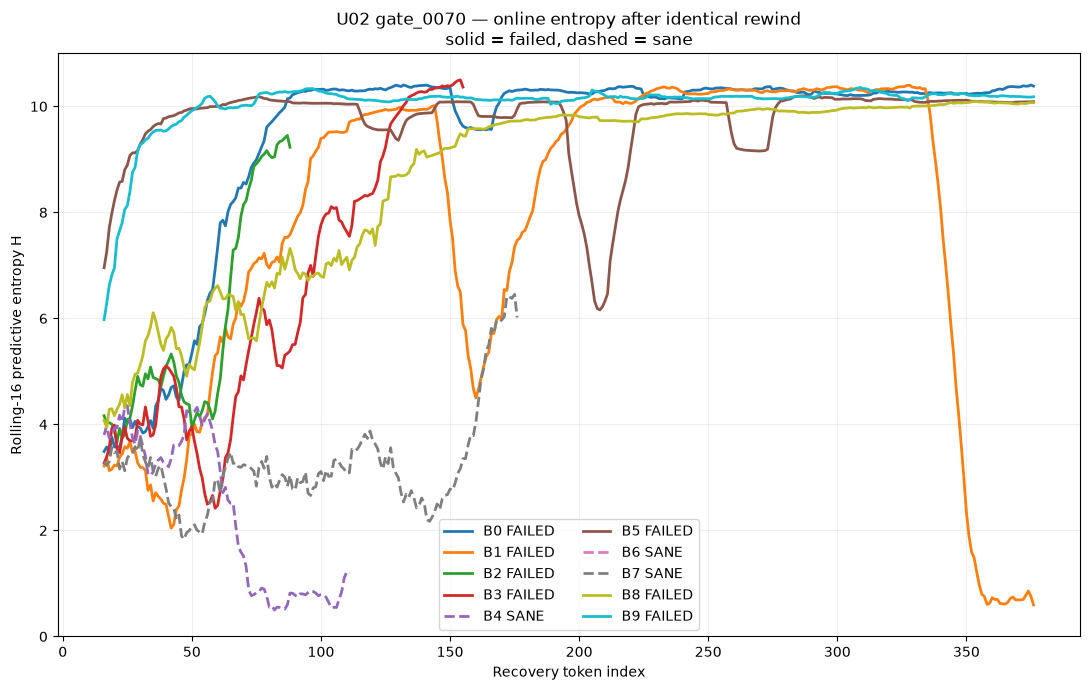

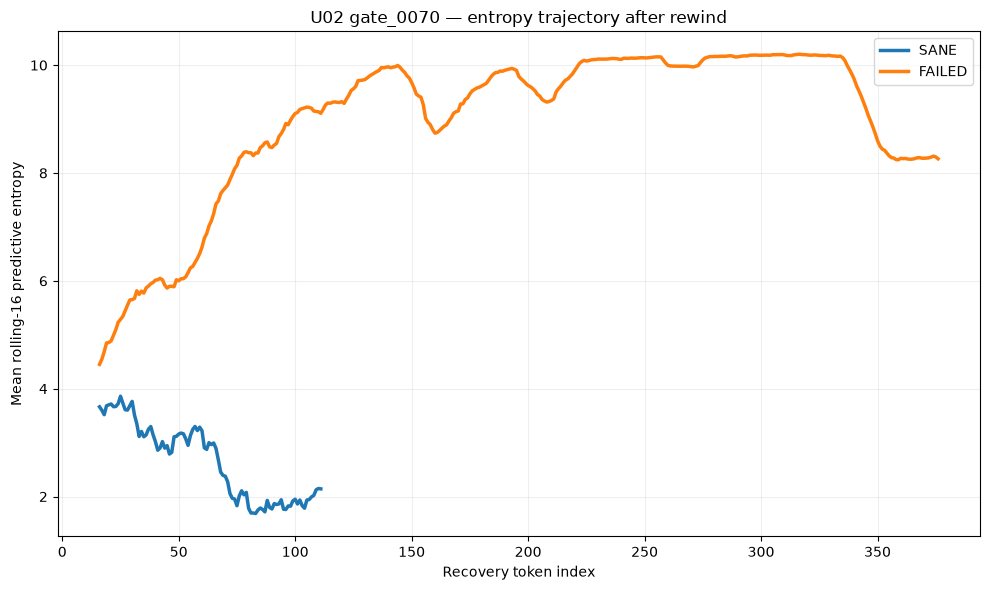


Descriptive separation:


,metric,sane_min,sane_max,failed_min,failed_max,gap_failed_min_minus_sane_max
2,max_H16,3.886735,6.453321,9.451707,10.500372,2.998386
4,mean_S,2.346943,3.579374,5.891956,10.028425,2.312582
0,mean_H,2.393588,3.886735,6.049360,9.949398,2.162625
1,median_H,1.831624,4.097123,5.981066,10.235783,1.883943
5,mean_excess,-0.307361,-0.046646,-0.157403,0.132211,-0.110758
3,final_H16,1.195231,6.016624,0.593563,10.382479,-5.423062


In [23]:
# ============================================================
# U02 — gate_0070: does predictive entropy detect sanity slip?
#
# Manual labels from inspection:
#   failed: 0,1,2,3,5,8,9
#   sane:   4,6,7
#
# Goal:
#   inspect ONLINE quantities, especially rolling H_t.
#
# No threshold is frozen here.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


FAILED_BRANCHES = {
    0, 1, 2, 3, 5, 8, 9
}

SANE_BRANCHES = {
    4, 6, 7
}

assert (
    FAILED_BRANCHES
    | SANE_BRANCHES
) == set(
    rewind10_tokens[
        "branch"
    ].unique()
)

assert not (
    FAILED_BRANCHES
    & SANE_BRANCHES
)


# ------------------------------------------------------------
# 1. Add manual labels.
# ------------------------------------------------------------

tokdiag = (
    rewind10_tokens
    .copy()
)

tokdiag[
    "manual_label"
] = np.where(
    tokdiag[
        "branch"
    ].isin(
        FAILED_BRANCHES
    ),
    "FAILED",
    "SANE",
)


# ------------------------------------------------------------
# 2. Rolling online quantities.
# ------------------------------------------------------------

for window in [
    8,
    16,
    32,
]:

    tokdiag[
        f"H_roll{window}"
    ] = (
        tokdiag
        .groupby(
            "branch"
        )[
            "entropy"
        ]
        .transform(
            lambda s:
                s.rolling(
                    window,
                    min_periods=window,
                ).mean()
        )
    )

    tokdiag[
        f"S_roll{window}"
    ] = (
        tokdiag
        .groupby(
            "branch"
        )[
            "surprisal"
        ]
        .transform(
            lambda s:
                s.rolling(
                    window,
                    min_periods=window,
                ).mean()
        )
    )

    tokdiag[
        f"E_roll{window}"
    ] = (
        tokdiag
        .groupby(
            "branch"
        )[
            "excess_surprisal"
        ]
        .transform(
            lambda s:
                s.rolling(
                    window,
                    min_periods=window,
                ).mean()
        )
    )


# ------------------------------------------------------------
# 3. Branch-level table, now with rolling entropy.
# ------------------------------------------------------------

branch_diag = (
    tokdiag
    .groupby(
        [
            "branch",
            "manual_label",
        ]
    )
    .agg(
        n_tokens=(
            "recovery_token_index",
            "size",
        ),

        mean_H=(
            "entropy",
            "mean",
        ),

        median_H=(
            "entropy",
            "median",
        ),

        max_H8=(
            "H_roll8",
            "max",
        ),

        max_H16=(
            "H_roll16",
            "max",
        ),

        max_H32=(
            "H_roll32",
            "max",
        ),

        final_H16=(
            "H_roll16",
            lambda s:
                s.dropna().iloc[-1]
                if s.notna().any()
                else np.nan,
        ),

        final_H32=(
            "H_roll32",
            lambda s:
                s.dropna().iloc[-1]
                if s.notna().any()
                else np.nan,
        ),

        mean_S=(
            "surprisal",
            "mean",
        ),

        mean_excess=(
            "excess_surprisal",
            "mean",
        ),
    )
    .reset_index()
)


display(
    branch_diag.sort_values(
        [
            "manual_label",
            "branch",
        ]
    )
)


print(
    "\nMean entropy by manual class:"
)

display(
    branch_diag.groupby(
        "manual_label"
    )[
        [
            "mean_H",
            "median_H",
            "max_H16",
            "final_H16",
            "mean_S",
            "mean_excess",
        ]
    ]
    .agg(
        [
            "mean",
            "min",
            "max",
        ]
    )
)


# ------------------------------------------------------------
# 4. Rolling H16: every branch separately.
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(11, 7)
)

for branch in sorted(
    tokdiag[
        "branch"
    ].unique()
):

    d = tokdiag.loc[
        tokdiag[
            "branch"
        ].eq(branch)
    ]

    label = (
        "FAILED"
        if branch in FAILED_BRANCHES
        else "SANE"
    )

    linestyle = (
        "-"
        if label == "FAILED"
        else "--"
    )

    ax.plot(
        d[
            "recovery_token_index"
        ],
        d[
            "H_roll16"
        ],
        linewidth=2,
        linestyle=linestyle,
        label=(
            f"B{branch} {label}"
        ),
    )


ax.set_xlabel(
    "Recovery token index"
)

ax.set_ylabel(
    "Rolling-16 predictive entropy H"
)

ax.set_title(
    "U02 gate_0070 — online entropy after identical rewind\n"
    "solid = failed, dashed = sane"
)

ax.grid(
    alpha=.2
)

ax.legend(
    ncol=2
)

fig.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. Class-average entropy trajectory.
#
# Only use a token position when >=2 branches from that class
# are still alive, to avoid a single long failed branch
# dominating the late curve.
# ------------------------------------------------------------

class_time = (
    tokdiag
    .dropna(
        subset=[
            "H_roll16"
        ]
    )
    .groupby(
        [
            "manual_label",
            "recovery_token_index",
        ],
        as_index=False,
    )
    .agg(
        mean_H16=(
            "H_roll16",
            "mean",
        ),

        median_H16=(
            "H_roll16",
            "median",
        ),

        n_branches=(
            "branch",
            "nunique",
        ),
    )
)

class_time = (
    class_time.loc[
        class_time[
            "n_branches"
        ]
        >= 2
    ]
)


fig, ax = plt.subplots(
    figsize=(10, 6)
)

for label in [
    "SANE",
    "FAILED",
]:

    d = class_time.loc[
        class_time[
            "manual_label"
        ].eq(label)
    ]

    ax.plot(
        d[
            "recovery_token_index"
        ],
        d[
            "mean_H16"
        ],
        linewidth=2.5,
        label=label,
    )


ax.set_xlabel(
    "Recovery token index"
)

ax.set_ylabel(
    "Mean rolling-16 predictive entropy"
)

ax.set_title(
    "U02 gate_0070 — entropy trajectory after rewind"
)

ax.grid(
    alpha=.2
)

ax.legend()

fig.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. Compare entropy vs excess-surprisal separation.
#
# This is descriptive only. With n=10 from one prefix,
# DO NOT freeze a production threshold from this yet.
# ------------------------------------------------------------

summary_sep = []

for metric in [
    "mean_H",
    "median_H",
    "max_H16",
    "final_H16",
    "mean_S",
    "mean_excess",
]:

    sane = (
        branch_diag.loc[
            branch_diag[
                "manual_label"
            ].eq(
                "SANE"
            ),
            metric,
        ]
        .dropna()
        .to_numpy()
    )

    failed = (
        branch_diag.loc[
            branch_diag[
                "manual_label"
            ].eq(
                "FAILED"
            ),
            metric,
        ]
        .dropna()
        .to_numpy()
    )

    summary_sep.append({
        "metric":
            metric,

        "sane_min":
            sane.min()
            if len(sane)
            else np.nan,

        "sane_max":
            sane.max()
            if len(sane)
            else np.nan,

        "failed_min":
            failed.min()
            if len(failed)
            else np.nan,

        "failed_max":
            failed.max()
            if len(failed)
            else np.nan,

        "gap_failed_min_minus_sane_max":
            (
                failed.min()
                - sane.max()
            )
            if (
                len(sane)
                and len(failed)
            )
            else np.nan,
    })


separation = pd.DataFrame(
    summary_sep
)

print(
    "\nDescriptive separation:"
)

display(
    separation
    .sort_values(
        "gap_failed_min_minus_sane_max",
        ascending=False,
    )
)

In [24]:
# ============================================================
# U02 — quantify sustained entropy runaway on the 10 branches
#
# Test the observed hypothesis:
#   temporary H > 5 can recover,
#   sustained H > 5 predicts failure.
# ============================================================

ENTROPY_THRESHOLD = 5.0

def longest_true_run(mask):
    best = 0
    current = 0
    start_best = None
    start_current = None

    for i, value in enumerate(mask):

        if bool(value):

            if current == 0:
                start_current = i

            current += 1

            if current > best:
                best = current
                start_best = start_current

        else:
            current = 0
            start_current = None

    return best, start_best


run_rows = []

for branch, d in (
    tokdiag
    .sort_values(
        [
            "branch",
            "recovery_token_index",
        ]
    )
    .groupby("branch")
):

    d = d.reset_index(drop=True)

    valid = d["H_roll16"].notna()

    above = (
        d["H_roll16"]
        .gt(ENTROPY_THRESHOLD)
        &
        valid
    )

    longest, start_idx = longest_true_run(
        above.to_numpy()
    )

    if start_idx is not None:

        runaway_start_token = int(
            d.iloc[start_idx][
                "recovery_token_index"
            ]
        )

    else:

        runaway_start_token = np.nan


    # How long does the FINAL high-entropy run last?
    final_run = 0

    for value in reversed(
        above.to_list()
    ):

        if value:
            final_run += 1
        else:
            break


    run_rows.append({
        "branch":
            int(branch),

        "manual_label":
            d[
                "manual_label"
            ].iloc[0],

        "n_tokens":
            len(d),

        "max_H16":
            d[
                "H_roll16"
            ].max(),

        "longest_run_H16_gt5":
            longest,

        "runaway_start_token":
            runaway_start_token,

        "final_run_H16_gt5":
            final_run,

        "fraction_H16_gt5":
            float(
                above.mean()
            ),
    })


entropy_runs = pd.DataFrame(
    run_rows
)


display(
    entropy_runs.sort_values(
        [
            "manual_label",
            "branch",
        ]
    )
)


print(
    "\nBy manual class:"
)

display(
    entropy_runs.groupby(
        "manual_label"
    )[
        [
            "longest_run_H16_gt5",
            "final_run_H16_gt5",
            "fraction_H16_gt5",
        ]
    ]
    .agg(
        [
            "mean",
            "min",
            "max",
        ]
    )
)


# ------------------------------------------------------------
# Try possible persistence requirements WITHOUT freezing one.
# ------------------------------------------------------------

tests = []

for persistence in [
    8,
    16,
    24,
    32,
    48,
    64,
]:

    predicted_failed = (
        entropy_runs[
            "longest_run_H16_gt5"
        ]
        >= persistence
    )

    actual_failed = (
        entropy_runs[
            "manual_label"
        ]
        .eq("FAILED")
    )

    tp = int(
        (
            predicted_failed
            &
            actual_failed
        ).sum()
    )

    fp = int(
        (
            predicted_failed
            &
            ~actual_failed
        ).sum()
    )

    fn = int(
        (
            ~predicted_failed
            &
            actual_failed
        ).sum()
    )

    tn = int(
        (
            ~predicted_failed
            &
            ~actual_failed
        ).sum()
    )

    tests.append({
        "persistence_tokens":
            persistence,

        "TP":
            tp,

        "FP":
            fp,

        "FN":
            fn,

        "TN":
            tn,

        "accuracy":
            (
                tp + tn
            )
            / len(
                entropy_runs
            ),
    })


persistence_test = pd.DataFrame(
    tests
)

print(
    "\nPersistence-rule diagnostic:"
)

display(
    persistence_test
)

,branch,manual_label,n_tokens,max_H16,longest_run_H16_gt5,runaway_start_token,final_run_H16_gt5,fraction_H16_gt5
0,0,FAILED,376,10.403882,330,47.0,330,0.877660
1,1,FAILED,376,10.399812,183,163.0,0,0.752660
2,2,FAILED,88,9.451707,27,62.0,27,0.363636
3,3,FAILED,155,10.500372,85,71.0,85,0.567742
5,5,FAILED,376,10.201673,361,16.0,361,0.960106
8,8,FAILED,376,10.092098,328,49.0,328,0.920213
9,9,FAILED,376,10.355113,361,16.0,361,0.960106
4,4,SANE,111,4.354435,0,NaN,0,0.000000
6,6,SANE,16,3.886735,0,NaN,0,0.000000
7,7,SANE,176,6.453321,14,163.0,14,0.079545



By manual class:


longest_run_H16_gt5          final_run_H16_gt5           \
                            mean min  max              mean min  max   
manual_label                                                           
FAILED                239.285714  27  361        213.142857   0  361   
SANE                    4.666667   0   14          4.666667   0   14   

             fraction_H16_gt5                      
                         mean       min       max  
manual_label                                       
FAILED               0.771732  0.363636  0.960106  
SANE                 0.026515  0.000000  0.079545


Persistence-rule diagnostic:


,persistence_tokens,TP,FP,FN,TN,accuracy
0,8,7,1,0,2,0.9
1,16,7,0,0,3,1.0
2,24,7,0,0,3,1.0
3,32,6,0,1,3,0.9
4,48,6,0,1,3,0.9
5,64,6,0,1,3,0.9


In [25]:
# ============================================================
# U02 — gate_0070: 10 branches WITH automatic coherence rewind
#
# PROVISIONAL pilot detector from the previous 10 branches:
#
#   rolling-16 predictive entropy > 5
#   for 8 consecutive generated tokens
#
# On alarm:
#   - remove the detected high-entropy excursion
#   - rewind an EXTRA 24 model tokens for safety margin
#   - Unique remains OFF
#   - continue unrestricted T=1 sampling
#   - RNG is NOT reset, so the retry samples a new branch
#
# Important:
#   Threshold/window/persistence/backoff are NOT frozen.
#   This experiment asks whether enforcing rewind materially
#   improves the 2/10 sane rate we just observed.
# ============================================================

import gc
import hashlib
import json
import math

import numpy as np
import pandas as pd
import torch

from IPython.display import display


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

CASE_ID = "gate_0070"

N_BRANCHES = 10

TOTAL_OUTPUT_TOKEN_CAP = 640

H_WINDOW = 16
H_DANGER = 5.0
H_PERSISTENCE = 8

# Extra margin BEFORE the beginning of the detected danger run.
REWIND_BACKOFF_TOKENS = 24

# Never allow an infinite resample loop.
MAX_REWINDS = 12
MAX_SAMPLE_ATTEMPTS = 3000

AUTO_NAMESPACE = (
    "U02_GATE0070_AUTO_REWIND_v1"
)


# ------------------------------------------------------------
# Preconditions
# ------------------------------------------------------------

assert "model" in globals()
assert "tok" in globals()
assert "pids" in globals()
assert "rewind_ids" in globals()
assert "final_ids" in globals()

ANCHOR_TOKEN_COUNT = len(
    rewind_ids
)

assert (
    final_ids[:ANCHOR_TOKEN_COUNT]
    ==
    rewind_ids
)

print(
    "Original manual anchor:",
    ANCHOR_TOKEN_COUNT,
    "output model tokens",
)

print(
    "Detector:",
    f"H{H_WINDOW} > {H_DANGER}",
    f"for {H_PERSISTENCE} tokens",
)

print(
    "Extra rewind margin:",
    REWIND_BACKOFF_TOKENS,
    "model tokens",
)


# ------------------------------------------------------------
# EOS / forbidden protocol tokens
# ------------------------------------------------------------

eos = (
    model.generation_config
    .eos_token_id
)

if eos is None:
    eos = tok.eos_token_id

EOS_IDS = set(
    eos
    if isinstance(
        eos,
        (list, tuple),
    )
    else [eos]
)

FORBIDDEN_SPECIAL = (
    set(tok.all_special_ids)
    - EOS_IDS
)


# ------------------------------------------------------------
# Deterministic branch seeds
# ------------------------------------------------------------

def auto_seed(
    branch,
):

    key = (
        f"{AUTO_NAMESPACE}|"
        f"{CASE_ID}|"
        f"{branch}"
    )

    digest = hashlib.sha256(
        key.encode()
    ).digest()

    return (
        int.from_bytes(
            digest[:8],
            "little",
            signed=False,
        )
        % (2**63 - 1)
    )


# ------------------------------------------------------------
# Decode output-only token sequence
# ------------------------------------------------------------

def decode_output(
    output_ids,
):

    return tok.decode(
        list(output_ids),
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )


# ------------------------------------------------------------
# Predictive entropy
# ------------------------------------------------------------

def entropy_from_logits(
    logits,
):

    logits = (
        logits
        .float()
        .clone()
    )

    for tid in FORBIDDEN_SPECIAL:

        if tid < logits.numel():

            logits[
                int(tid)
            ] = -torch.inf


    logp = torch.log_softmax(
        logits,
        dim=-1,
    )

    p = torch.exp(
        logp
    )

    finite = p > 0

    entropy = (
        p[finite]
        * (
            -logp[finite]
        )
    ).sum()

    return float(
        entropy.item()
    )


# ------------------------------------------------------------
# Prime / re-prime the model from an arbitrary output prefix.
#
# This is what makes retroactive rewind exact:
# after deleting tokens, rebuild KV cache from the retained
# prompt + retained generated-output prefix.
# ------------------------------------------------------------

@torch.inference_mode()
def prime_from_output(
    output_ids,
):

    full = (
        list(pids)
        + list(output_ids)
    )

    x = torch.tensor(
        [full],
        dtype=torch.long,
        device=device,
    )

    attention_mask = torch.ones_like(
        x
    )

    out = model(
        input_ids=x,
        attention_mask=attention_mask,
        use_cache=True,
        return_dict=True,
    )

    past = out.past_key_values

    next_logits = (
        out.logits[
            0,
            -1,
            :
        ]
        .float()
    )

    del out
    del x

    return (
        past,
        next_logits,
        attention_mask,
    )


# ------------------------------------------------------------
# Sample one unrestricted T=1 token.
# ------------------------------------------------------------

def sample_t1(
    logits,
    generator,
):

    sample_logits = (
        logits
        .float()
        .clone()
    )

    for tid in FORBIDDEN_SPECIAL:

        if tid < sample_logits.numel():

            sample_logits[
                int(tid)
            ] = -torch.inf


    probs = torch.softmax(
        sample_logits,
        dim=-1,
    )

    token = int(
        torch.multinomial(
            probs,
            num_samples=1,
            replacement=True,
            generator=generator,
        ).item()
    )

    probability = float(
        probs[token].item()
    )

    del sample_logits
    del probs

    return (
        token,
        probability,
    )


# ------------------------------------------------------------
# One branch with automatic rewind.
# ------------------------------------------------------------

@torch.inference_mode()
def generate_auto_rewind_branch(
    branch,
):

    seed = auto_seed(
        branch
    )

    generator = torch.Generator(
        device=device
    )

    generator.manual_seed(
        int(seed)
    )


    # Start from EXACT original Hybrid prefix immediately
    # before manually observed word 224.
    output_ids = list(
        rewind_ids
    )


    past, next_logits, attention_mask = (
        prime_from_output(
            output_ids
        )
    )


    # Detector state only describes the CURRENT surviving
    # trajectory since the most recent rewind.
    detector_H = []

    # Absolute token count at which current detector epoch began.
    epoch_start_output_len = len(
        output_ids
    )


    rewind_count = 0
    sample_attempts = 0

    stop_reason = None

    alarm_events = []
    token_events = []

    epoch = 0


    while True:

        # --------------------------------------------
        # Final retained-output token cap
        # --------------------------------------------

        if len(output_ids) >= TOTAL_OUTPUT_TOKEN_CAP:

            stop_reason = "token_cap"
            break


        if sample_attempts >= MAX_SAMPLE_ATTEMPTS:

            stop_reason = "attempt_cap"
            break


        if rewind_count >= MAX_REWINDS:

            stop_reason = "rewind_limit"
            break


        # --------------------------------------------
        # Distribution entropy BEFORE drawing token
        # --------------------------------------------

        H = entropy_from_logits(
            next_logits
        )


        token, probability = sample_t1(
            next_logits,
            generator,
        )

        sample_attempts += 1


        output_ids.append(
            token
        )

        detector_H.append(
            H
        )


        # --------------------------------------------
        # Rolling entropy
        # --------------------------------------------

        if len(detector_H) >= H_WINDOW:

            H_roll = float(
                np.mean(
                    detector_H[
                        -H_WINDOW:
                    ]
                )
            )

        else:

            H_roll = np.nan


        # Consecutive rolling-H danger count.
        danger_run = 0

        for value in reversed(
            detector_H
        ):

            # Need a full rolling window ending here.
            idx = (
                len(detector_H)
                - danger_run
            )

            if idx < H_WINDOW:
                break

            roll = float(
                np.mean(
                    detector_H[
                        idx - H_WINDOW:
                        idx
                    ]
                )
            )

            if roll > H_DANGER:
                danger_run += 1

            else:
                break


        token_events.append({
            "branch":
                branch,

            "seed":
                seed,

            "epoch":
                epoch,

            "attempt":
                sample_attempts,

            "output_token_count":
                len(output_ids),

            "token_id":
                token,

            "token_piece":
                tok.decode(
                    [token],
                    skip_special_tokens=False,
                    clean_up_tokenization_spaces=False,
                ),

            "probability":
                probability,

            "surprisal":
                -math.log(
                    max(
                        probability,
                        1e-300,
                    )
                ),

            "entropy":
                H,

            "H_roll16":
                H_roll,

            "danger_run":
                danger_run,

            "rewind_count":
                rewind_count,
        })


        # --------------------------------------------
        # COHERENCE COLLAPSE DETECTED
        # --------------------------------------------

        if (
            danger_run
            >= H_PERSISTENCE
        ):

            # Start of the persistent rolling-H excursion,
            # measured in tokens generated in THIS epoch.
            #
            # Example:
            # if danger_run == 8, remove those 8 dangerous
            # tokens plus the extra backoff.
            epoch_tokens_now = (
                len(output_ids)
                - epoch_start_output_len
            )

            danger_start_relative = (
                epoch_tokens_now
                - danger_run
            )


            # Rewind EXTRA margin before danger began.
            target_relative = (
                danger_start_relative
                - REWIND_BACKOFF_TOKENS
            )


            target_output_len = (
                epoch_start_output_len
                + target_relative
            )


            # Crucially, allow crossing BEFORE the original
            # word-224 anchor if the detector fires early.
            #
            # Do not rewind before the beginning of generated
            # output.
            target_output_len = max(
                0,
                target_output_len,
            )


            old_output_len = len(
                output_ids
            )

            old_words = len(
                word_spans(
                    decode_output(
                        output_ids
                    )
                )
            )


            target_words = len(
                word_spans(
                    decode_output(
                        output_ids[
                            :target_output_len
                        ]
                    )
                )
            )


            alarm_events.append({
                "branch":
                    branch,

                "seed":
                    seed,

                "rewind_number":
                    rewind_count + 1,

                "epoch":
                    epoch,

                "alarm_attempt":
                    sample_attempts,

                "alarm_output_tokens":
                    old_output_len,

                "alarm_words":
                    old_words,

                "danger_run":
                    danger_run,

                "danger_start_relative":
                    danger_start_relative,

                "rewind_target_output_tokens":
                    target_output_len,

                "rewind_target_words":
                    target_words,

                "tokens_removed":
                    old_output_len
                    - target_output_len,

                "crossed_original_anchor":
                    target_output_len
                    < ANCHOR_TOKEN_COUNT,

                "last_H_roll16":
                    H_roll,
            })


            # ----------------------------------------
            # Perform actual retroactive rewind
            # ----------------------------------------

            output_ids = output_ids[
                :target_output_len
            ]


            # Destroy stale KV cache.
            del past
            del next_logits
            del attention_mask

            gc.collect()

            if torch.cuda.is_available():
                torch.cuda.empty_cache()


            past, next_logits, attention_mask = (
                prime_from_output(
                    output_ids
                )
            )


            rewind_count += 1
            epoch += 1

            epoch_start_output_len = len(
                output_ids
            )

            detector_H = []

            continue


        # --------------------------------------------
        # EOS accepted only if no rewind alarm fired.
        # --------------------------------------------

        if token in EOS_IDS:

            stop_reason = "eos"
            break


        # --------------------------------------------
        # Advance one-token KV cache
        # --------------------------------------------

        token_tensor = torch.tensor(
            [[token]],
            dtype=torch.long,
            device=device,
        )

        attention_mask = torch.cat(
            [
                attention_mask,

                torch.ones(
                    (1, 1),
                    dtype=attention_mask.dtype,
                    device=device,
                ),
            ],
            dim=-1,
        )


        out = model(
            input_ids=token_tensor,
            attention_mask=attention_mask,
            past_key_values=past,
            use_cache=True,
            return_dict=True,
        )


        past = out.past_key_values

        next_logits = (
            out.logits[
                0,
                -1,
                :
            ]
            .float()
        )


        del out
        del token_tensor


    # --------------------------------------------------------
    # Final branch output
    # --------------------------------------------------------

    recovered_text = decode_output(
        output_ids
    )


    summary = {
        "case_id":
            CASE_ID,

        "branch":
            branch,

        "seed":
            seed,

        "stop_reason":
            stop_reason,

        "rewinds":
            rewind_count,

        "sample_attempts":
            sample_attempts,

        "final_output_tokens":
            len(output_ids),

        "final_words":
            counts(
                recovered_text
            )[1],

        "ever_rewound_before_original_anchor":
            any(
                x[
                    "crossed_original_anchor"
                ]
                for x in alarm_events
            ),

        "max_tokens_removed":
            (
                max(
                    x[
                        "tokens_removed"
                    ]
                    for x in alarm_events
                )
                if alarm_events
                else 0
            ),

        "recovered_text":
            recovered_text,

        # Manual review fields
        "manual_sanity":
            "",

        "manual_first_slip":
            "",

        "manual_notes":
            "",
    }


    del past
    del next_logits
    del attention_mask

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


    return (
        summary,
        token_events,
        alarm_events,
    )


# ------------------------------------------------------------
# Generate 10 auto-rewind branches
# ------------------------------------------------------------

auto_rows = []
auto_token_rows = []
auto_alarm_rows = []


for branch in range(
    N_BRANCHES
):

    print(
        f"Auto-rewind branch "
        f"{branch + 1}/{N_BRANCHES}"
    )

    summary, tokens, alarms = (
        generate_auto_rewind_branch(
            branch
        )
    )

    auto_rows.append(
        summary
    )

    auto_token_rows.extend(
        tokens
    )

    auto_alarm_rows.extend(
        alarms
    )


auto_rewind10 = pd.DataFrame(
    auto_rows
)

auto_rewind10_tokens = pd.DataFrame(
    auto_token_rows
)

auto_rewind10_alarms = pd.DataFrame(
    auto_alarm_rows
)


# ------------------------------------------------------------
# Save BEFORE manual review
# ------------------------------------------------------------

AUTO_PATH = (
    OUT
    / "gate_0070_auto_rewind10_branches.parquet"
)

AUTO_TOKEN_PATH = (
    OUT
    / "gate_0070_auto_rewind10_token_attempts.parquet"
)

AUTO_ALARM_PATH = (
    OUT
    / "gate_0070_auto_rewind10_alarms.csv"
)

AUTO_REVIEW_PATH = (
    OUT
    / "gate_0070_auto_rewind10_manual_review.csv"
)


auto_rewind10.to_parquet(
    AUTO_PATH,
    index=False,
)

auto_rewind10_tokens.to_parquet(
    AUTO_TOKEN_PATH,
    index=False,
)

auto_rewind10_alarms.to_csv(
    AUTO_ALARM_PATH,
    index=False,
)

auto_rewind10[
    [
        "case_id",
        "branch",
        "seed",
        "stop_reason",
        "rewinds",
        "sample_attempts",
        "final_output_tokens",
        "final_words",
        "ever_rewound_before_original_anchor",
        "manual_sanity",
        "manual_first_slip",
        "manual_notes",
    ]
].to_csv(
    AUTO_REVIEW_PATH,
    index=False,
)


print(
    "\nSaved:",
    AUTO_PATH,
)

print(
    "Alarm log:",
    AUTO_ALARM_PATH,
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

display(
    auto_rewind10[
        [
            "branch",
            "seed",
            "stop_reason",
            "rewinds",
            "sample_attempts",
            "final_output_tokens",
            "final_words",
            "ever_rewound_before_original_anchor",
            "max_tokens_removed",
        ]
    ]
)


if len(
    auto_rewind10_alarms
):

    print(
        "\nRewind events:"
    )

    display(
        auto_rewind10_alarms
    )


# ------------------------------------------------------------
# Print all 10 for manual comparison
# ------------------------------------------------------------

DISPLAY_FROM_WORD = 190


def text_from_word(
    text,
    start_word,
):

    spans = word_spans(
        str(text)
    )

    if not spans:
        return ""

    start_word = max(
        1,
        int(start_word),
    )

    if start_word > len(
        spans
    ):
        return ""

    char_start = spans[
        start_word - 1
    ][1]

    return str(text)[
        char_start:
    ]


for r in auto_rewind10.itertuples(
    index=False
):

    print(
        "\n\n"
        + "=" * 110
    )

    print(
        f"AUTO-REWIND BRANCH {r.branch}"
        f" | rewinds={r.rewinds}"
        f" | attempts={r.sample_attempts}"
        f" | stop={r.stop_reason}"
        f" | words={r.final_words}"
    )

    print(
        "=" * 110
    )

    print(
        text_from_word(
            r.recovered_text,
            DISPLAY_FROM_WORD,
        )
    )

Original manual anchor: 264 output model tokens
Detector: H16 > 5.0 for 8 tokens
Extra rewind margin: 24 model tokens
Auto-rewind branch 1/10
Auto-rewind branch 2/10
Auto-rewind branch 3/10
Auto-rewind branch 4/10
Auto-rewind branch 5/10
Auto-rewind branch 6/10
Auto-rewind branch 7/10
Auto-rewind branch 8/10
Auto-rewind branch 9/10
Auto-rewind branch 10/10

Saved: ../results/causal/U02_hybrid_unique_sampling/gate_0070_auto_rewind10_branches.parquet
Alarm log: ../results/causal/U02_hybrid_unique_sampling/gate_0070_auto_rewind10_alarms.csv


,branch,seed,stop_reason,rewinds,sample_attempts,final_output_tokens,final_words,ever_rewound_before_original_anchor,max_tokens_removed
0,0,8176611651966259916,eos,0,42,306,258,False,0
1,1,722517118019175751,eos,2,151,351,295,False,32
2,2,5203780828484837544,eos,8,408,416,345,False,32
3,3,6498828529397848261,eos,1,99,331,278,True,32
4,4,1716007072162254828,eos,0,42,306,256,False,0
5,5,2249151216007744938,eos,4,187,323,267,False,32
6,6,5179737697741647980,eos,9,374,350,293,False,32
7,7,8462983173842268860,eos,0,166,430,361,False,0
8,8,7925442771783366340,eos,1,106,338,278,False,32
9,9,2591884333686800860,eos,4,279,415,340,True,32



Rewind events:


,branch,seed,rewind_number,epoch,alarm_attempt,alarm_output_tokens,alarm_words,danger_run,danger_start_relative,rewind_target_output_tokens,rewind_target_words,tokens_removed,crossed_original_anchor,last_H_roll16
0,1,722517118019175751,1,0,44,308,261,8,36,276,233,32,False,6.535677
1,1,722517118019175751,2,1,67,299,251,8,15,267,226,32,False,5.307498
2,2,5203780828484837544,1,0,53,317,265,8,45,285,239,32,False,6.574432
3,2,5203780828484837544,2,1,76,308,258,8,15,276,233,32,False,6.816659
4,2,5203780828484837544,3,2,115,315,266,8,31,283,238,32,False,5.611218
5,2,5203780828484837544,4,3,162,330,275,8,39,298,249,32,False,6.062748
6,2,5203780828484837544,5,4,185,321,269,8,15,289,243,32,False,6.419038
7,2,5203780828484837544,6,5,236,340,286,8,43,308,259,32,False,7.045177
8,2,5203780828484837544,7,6,260,332,281,8,16,300,252,32,False,6.620795
9,2,5203780828484837544,8,7,370,410,346,8,102,378,317,32,False,6.355962




AUTO-REWIND BRANCH 0 | rewinds=0 | attempts=42 | stop=eos | words=258
exploits along the way, Dick holds fast to the descriptions of America's defense of the merchant vessel against the malicious pirate attacks.

Despite the varied obstacles in front of him, Dick never gives in. Thanks to the backing of his dour father and his new friends who stand by with incredible loyalty, Dick unmovably stands up to the hostility, driven to see his scales through to the very end.


AUTO-REWIND BRANCH 1 | rewinds=2 | attempts=151 | stop=eos | words=295
exploits along the way, Dick holds fast to the descriptions of America's defense of the merchant vessel against the malicious pirate attacks.

Despite the varied obstacles in front of him, Dick never gives in. Using what is largely self-discovered determination and hoarding knowledge and bravery, he skillfully navigates sea dangers and emphasizes loyalty, quick thinking, forward planning and a sometimes ferocious presence that appear to grace his de

In [26]:
# ============================================================
# U02 — out-of-sample automatic sanity-rewind test
#
# Remaining 4 manually inspected U02 cases:
#
#   gate_0035
#   gate_0039
#   gate_0078
#   gate_0025
#
# IMPORTANT:
# Parameters are frozen from gate_0070:
#
#   rolling entropy window = 16
#   danger threshold       = 5.0
#   persistence            = 8 tokens
#   rewind backoff         = 24 model tokens
#
# No tuning on these cases.
#
# Stage A:
#   Replay the ORIGINAL Hybrid output exactly and detect its
#   first entropy-collapse alarm automatically.
#
# Stage B:
#   If alarmed:
#       rewind original trajectory automatically,
#       disable Unique,
#       generate 10 T1 branches,
#       keep applying the SAME entropy-rewind controller.
#
#   If NOT alarmed:
#       preserve original output as a negative-control result.
# ============================================================

import gc
import hashlib
import json
import math

import numpy as np
import pandas as pd
import torch

from IPython.display import display


# ------------------------------------------------------------
# Frozen out-of-sample configuration
# ------------------------------------------------------------

TEST_CASES = [
    "gate_0035",
    "gate_0039",
    "gate_0078",
    "gate_0025",
]

N_BRANCHES = 10

TOTAL_OUTPUT_TOKEN_CAP = 640

H_WINDOW = 16
H_DANGER = 5.0
H_PERSISTENCE = 8

REWIND_BACKOFF_TOKENS = 24

MAX_REWINDS = 12
MAX_SAMPLE_ATTEMPTS = 3000

OOS_NAMESPACE = (
    "U02_OOS_ENTROPY_REWIND_v1"
)


assert "model" in globals()
assert "tok" in globals()
assert "hybrid_gen" in globals()
assert "cohort" in globals()
assert "STATE_DIR" in globals()


# ------------------------------------------------------------
# Lookups
# ------------------------------------------------------------

_cohort_lookup = (
    cohort
    .assign(
        case_id=
            cohort[
                "case_id"
            ].astype(str)
    )
    .set_index(
        "case_id"
    )
)

_hybrid_lookup = (
    hybrid_gen
    .assign(
        case_id=
            hybrid_gen[
                "case_id"
            ].astype(str)
    )
    .set_index(
        "case_id"
    )
)


# ------------------------------------------------------------
# EOS / protocol specials
# ------------------------------------------------------------

_eos = (
    model
    .generation_config
    .eos_token_id
)

if _eos is None:
    _eos = tok.eos_token_id

EOS_IDS_OOS = set(
    _eos
    if isinstance(
        _eos,
        (list, tuple),
    )
    else [_eos]
)

FORBIDDEN_SPECIAL_OOS = (
    set(tok.all_special_ids)
    - EOS_IDS_OOS
)


# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------

def _decode_output(
    ids,
):

    return tok.decode(
        list(ids),
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )


def _H_from_logits(
    logits,
):

    z = (
        logits
        .float()
        .clone()
    )

    for tid in FORBIDDEN_SPECIAL_OOS:

        if tid < z.numel():

            z[
                int(tid)
            ] = -torch.inf


    logp = torch.log_softmax(
        z,
        dim=-1,
    )

    p = torch.exp(
        logp
    )

    finite = p > 0

    H = (
        p[finite]
        *
        (
            -logp[finite]
        )
    ).sum()

    return float(
        H.item()
    )


def _seed(
    cid,
    branch,
):

    key = (
        f"{OOS_NAMESPACE}|"
        f"{cid}|"
        f"{branch}"
    )

    digest = hashlib.sha256(
        key.encode()
    ).digest()

    return (
        int.from_bytes(
            digest[:8],
            "little",
            signed=False,
        )
        % (2**63 - 1)
    )


def _case_prompt_ids(
    cid,
):

    src = _cohort_lookup.loc[
        cid
    ]

    return prompt_ids(
        src.prompt,
        src.previous_ai,
    )


def _original_output_ids(
    cid,
):

    path = (
        STATE_DIR
        / f"{cid}__HYBRID_T10.json"
    )

    assert path.exists(), path

    payload = json.loads(
        path.read_text()
    )

    return [
        int(x)
        for x in payload[
            "state"
        ][
            "ids"
        ]
    ]


@torch.inference_mode()
def _prime(
    prompt_token_ids,
    output_token_ids,
):

    full = (
        list(prompt_token_ids)
        +
        list(output_token_ids)
    )

    x = torch.tensor(
        [full],
        dtype=torch.long,
        device=device,
    )

    mask = torch.ones_like(
        x
    )

    out = model(
        input_ids=x,
        attention_mask=mask,
        use_cache=True,
        return_dict=True,
    )

    past = out.past_key_values

    logits = (
        out.logits[
            0,
            -1,
            :
        ]
        .float()
    )

    del out
    del x

    return (
        past,
        logits,
        mask,
    )


def _sample_t1(
    logits,
    generator,
):

    z = (
        logits
        .float()
        .clone()
    )

    for tid in FORBIDDEN_SPECIAL_OOS:

        if tid < z.numel():

            z[
                int(tid)
            ] = -torch.inf


    p = torch.softmax(
        z,
        dim=-1,
    )

    token = int(
        torch.multinomial(
            p,
            1,
            replacement=True,
            generator=generator,
        ).item()
    )

    prob = float(
        p[token].item()
    )

    del z
    del p

    return (
        token,
        prob,
    )


# ============================================================
# Stage A — replay ORIGINAL Hybrid trajectory
# ============================================================

@torch.inference_mode()
def replay_original_case(
    cid,
):

    prompt_token_ids = (
        _case_prompt_ids(
            cid
        )
    )

    output_ids = (
        _original_output_ids(
            cid
        )
    )


    # Prime on prompt only.
    x = torch.tensor(
        [prompt_token_ids],
        dtype=torch.long,
        device=device,
    )

    mask = torch.ones_like(
        x
    )

    out = model(
        input_ids=x,
        attention_mask=mask,
        use_cache=True,
        return_dict=True,
    )

    past = out.past_key_values

    next_logits = (
        out.logits[
            0,
            -1,
            :
        ]
        .float()
    )

    del out
    del x


    H_history = []

    records = []

    danger_run = 0

    alarm = None


    for step, token in enumerate(
        output_ids,
        start=1,
    ):

        H = _H_from_logits(
            next_logits
        )

        H_history.append(
            H
        )


        if len(
            H_history
        ) >= H_WINDOW:

            H_roll = float(
                np.mean(
                    H_history[
                        -H_WINDOW:
                    ]
                )
            )

        else:

            H_roll = np.nan


        if (
            np.isfinite(
                H_roll
            )
            and
            H_roll > H_DANGER
        ):

            danger_run += 1

        else:

            danger_run = 0


        records.append({
            "case_id":
                cid,

            "output_token_index":
                step,

            "token_id":
                token,

            "token_piece":
                tok.decode(
                    [token],
                    skip_special_tokens=False,
                    clean_up_tokenization_spaces=False,
                ),

            "entropy":
                H,

            "H_roll16":
                H_roll,

            "danger_run":
                danger_run,
        })


        # --------------------------------------------
        # First automatically detected collapse.
        # --------------------------------------------

        if (
            alarm is None
            and
            danger_run
            >= H_PERSISTENCE
        ):

            # Same definition as gate_0070 pilot.
            danger_start = (
                step
                - danger_run
            )

            rewind_target = max(
                0,
                danger_start
                -
                REWIND_BACKOFF_TOKENS,
            )


            prefix_alarm = (
                output_ids[
                    :step
                ]
            )

            prefix_target = (
                output_ids[
                    :rewind_target
                ]
            )


            alarm = {
                "case_id":
                    cid,

                "alarm_output_token":
                    step,

                "danger_start_output_token":
                    danger_start,

                "rewind_target_output_token":
                    rewind_target,

                "tokens_removed_at_initial_rewind":
                    step
                    - rewind_target,

                "alarm_word":
                    len(
                        word_spans(
                            _decode_output(
                                prefix_alarm
                            )
                        )
                    ),

                "rewind_target_word":
                    len(
                        word_spans(
                            _decode_output(
                                prefix_target
                            )
                        )
                    ),

                "last_H_roll16":
                    H_roll,
            }


        # --------------------------------------------
        # Advance using the ACTUAL original token.
        # --------------------------------------------

        if step < len(
            output_ids
        ):

            token_tensor = torch.tensor(
                [[token]],
                dtype=torch.long,
                device=device,
            )

            mask = torch.cat(
                [
                    mask,

                    torch.ones(
                        (1, 1),
                        dtype=mask.dtype,
                        device=device,
                    ),
                ],
                dim=-1,
            )


            out = model(
                input_ids=token_tensor,
                attention_mask=mask,
                past_key_values=past,
                use_cache=True,
                return_dict=True,
            )

            past = (
                out.past_key_values
            )

            next_logits = (
                out.logits[
                    0,
                    -1,
                    :
                ]
                .float()
            )

            del out
            del token_tensor


    del past
    del next_logits
    del mask

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


    return (
        pd.DataFrame(
            records
        ),
        alarm,
    )


# ------------------------------------------------------------
# Replay all four untouched outputs.
# ------------------------------------------------------------

oos_replay_parts = []

initial_alarm_rows = []


for cid in TEST_CASES:

    print(
        "Replaying original:",
        cid,
    )

    d, alarm = (
        replay_original_case(
            cid
        )
    )

    oos_replay_parts.append(
        d
    )

    original_ids = (
        _original_output_ids(
            cid
        )
    )

    original_text = (
        _decode_output(
            original_ids
        )
    )


    row = {
        "case_id":
            cid,

        "original_output_tokens":
            len(
                original_ids
            ),

        "original_words":
            counts(
                original_text
            )[1],

        "alarm_detected":
            alarm
            is not None,
    }

    if alarm is not None:

        row.update(
            alarm
        )

    initial_alarm_rows.append(
        row
    )


oos_original_entropy = pd.concat(
    oos_replay_parts,
    ignore_index=True,
)

oos_initial_alarms = pd.DataFrame(
    initial_alarm_rows
)


print(
    "\nOUT-OF-SAMPLE ORIGINAL-OUTPUT DETECTION:"
)

display(
    oos_initial_alarms
)


# ============================================================
# Stage B — regenerate alarmed cases with SAME rewind rule
# ============================================================

@torch.inference_mode()
def generate_oos_recovery(
    cid,
    initial_rewind_target,
    branch,
):

    prompt_token_ids = (
        _case_prompt_ids(
            cid
        )
    )

    original_ids = (
        _original_output_ids(
            cid
        )
    )


    output_ids = list(
        original_ids[
            :int(
                initial_rewind_target
            )
        ]
    )


    initial_anchor = len(
        output_ids
    )


    seed = _seed(
        cid,
        branch,
    )

    generator = torch.Generator(
        device=device
    )

    generator.manual_seed(
        int(seed)
    )


    past, next_logits, mask = (
        _prime(
            prompt_token_ids,
            output_ids,
        )
    )


    H_epoch = []

    epoch_start = len(
        output_ids
    )

    epoch = 0

    rewinds = 0
    attempts = 0

    alarms = []

    stop_reason = None


    while True:

        if (
            len(output_ids)
            >= TOTAL_OUTPUT_TOKEN_CAP
        ):

            stop_reason = (
                "token_cap"
            )
            break


        if (
            attempts
            >= MAX_SAMPLE_ATTEMPTS
        ):

            stop_reason = (
                "attempt_cap"
            )
            break


        if (
            rewinds
            >= MAX_REWINDS
        ):

            stop_reason = (
                "rewind_limit"
            )
            break


        H = _H_from_logits(
            next_logits
        )


        token, prob = (
            _sample_t1(
                next_logits,
                generator,
            )
        )

        attempts += 1

        output_ids.append(
            token
        )

        H_epoch.append(
            H
        )


        if len(
            H_epoch
        ) >= H_WINDOW:

            H_roll = float(
                np.mean(
                    H_epoch[
                        -H_WINDOW:
                    ]
                )
            )

        else:

            H_roll = np.nan


        # --------------------------------------------
        # Count persistent danger from tail.
        # --------------------------------------------

        danger_run = 0

        if len(
            H_epoch
        ) >= H_WINDOW:

            for end in range(
                len(H_epoch),
                H_WINDOW - 1,
                -1,
            ):

                roll = float(
                    np.mean(
                        H_epoch[
                            end
                            - H_WINDOW
                            :
                            end
                        ]
                    )
                )

                if (
                    roll
                    > H_DANGER
                ):

                    danger_run += 1

                else:

                    break


        # --------------------------------------------
        # Automatic rewind
        # --------------------------------------------

        if (
            danger_run
            >= H_PERSISTENCE
        ):

            epoch_tokens = (
                len(output_ids)
                - epoch_start
            )

            danger_start_relative = (
                epoch_tokens
                - danger_run
            )

            target_relative = (
                danger_start_relative
                - REWIND_BACKOFF_TOKENS
            )

            target_output_len = max(
                0,
                epoch_start
                + target_relative,
            )


            old_len = len(
                output_ids
            )

            target_words = len(
                word_spans(
                    _decode_output(
                        output_ids[
                            :target_output_len
                        ]
                    )
                )
            )


            alarms.append({
                "case_id":
                    cid,

                "branch":
                    branch,

                "seed":
                    seed,

                "rewind_number":
                    rewinds
                    + 1,

                "epoch":
                    epoch,

                "attempt":
                    attempts,

                "alarm_output_tokens":
                    old_len,

                "rewind_target_output_tokens":
                    target_output_len,

                "rewind_target_words":
                    target_words,

                "tokens_removed":
                    old_len
                    - target_output_len,

                "crossed_initial_anchor":
                    target_output_len
                    < initial_anchor,

                "last_H_roll16":
                    H_roll,
            })


            output_ids = (
                output_ids[
                    :target_output_len
                ]
            )


            del past
            del next_logits
            del mask

            gc.collect()

            if torch.cuda.is_available():
                torch.cuda.empty_cache()


            past, next_logits, mask = (
                _prime(
                    prompt_token_ids,
                    output_ids,
                )
            )


            rewinds += 1
            epoch += 1

            epoch_start = len(
                output_ids
            )

            H_epoch = []

            continue


        # --------------------------------------------
        # EOS
        # --------------------------------------------

        if token in EOS_IDS_OOS:

            stop_reason = "eos"
            break


        # --------------------------------------------
        # Advance cache
        # --------------------------------------------

        token_tensor = torch.tensor(
            [[token]],
            dtype=torch.long,
            device=device,
        )

        mask = torch.cat(
            [
                mask,

                torch.ones(
                    (1, 1),
                    dtype=mask.dtype,
                    device=device,
                ),
            ],
            dim=-1,
        )


        out = model(
            input_ids=token_tensor,
            attention_mask=mask,
            past_key_values=past,
            use_cache=True,
            return_dict=True,
        )

        past = (
            out.past_key_values
        )

        next_logits = (
            out.logits[
                0,
                -1,
                :
            ]
            .float()
        )

        del out
        del token_tensor


    text = _decode_output(
        output_ids
    )


    summary = {
        "case_id":
            cid,

        "branch":
            branch,

        "seed":
            seed,

        "initial_rewind_output_tokens":
            int(
                initial_rewind_target
            ),

        "initial_rewind_words":
            len(
                word_spans(
                    _decode_output(
                        original_ids[
                            :int(
                                initial_rewind_target
                            )
                        ]
                    )
                )
            ),

        "rewinds_after_initial":
            rewinds,

        "attempts":
            attempts,

        "stop_reason":
            stop_reason,

        "final_output_tokens":
            len(
                output_ids
            ),

        "final_words":
            counts(
                text
            )[1],

        "crossed_initial_anchor":
            any(
                a[
                    "crossed_initial_anchor"
                ]
                for a in alarms
            ),

        "recovered_text":
            text,

        # Fill after reading
        "manual_sanity":
            "",

        "manual_notes":
            "",
    }


    del past
    del next_logits
    del mask

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


    return (
        summary,
        alarms,
    )


# ------------------------------------------------------------
# Generate only cases where untouched original triggered.
# ------------------------------------------------------------

recovery_rows = []
recovery_alarm_rows = []


for row in (
    oos_initial_alarms
    .itertuples(
        index=False
    )
):

    if not bool(
        row.alarm_detected
    ):

        print(
            "\nNO ALARM — keeping original:",
            row.case_id,
        )

        continue


    cid = row.case_id

    initial_target = int(
        row.rewind_target_output_token
    )


    print(
        "\n",
        "=" * 80,
    )

    print(
        cid,
        "| original alarm token:",
        int(
            row.alarm_output_token
        ),
        "| rewind target:",
        initial_target,
    )

    print(
        "=" * 80
    )


    for branch in range(
        N_BRANCHES
    ):

        print(
            f"{cid}: branch "
            f"{branch + 1}/{N_BRANCHES}"
        )

        result, alarms = (
            generate_oos_recovery(
                cid,
                initial_target,
                branch,
            )
        )

        recovery_rows.append(
            result
        )

        recovery_alarm_rows.extend(
            alarms
        )


oos_recovery = pd.DataFrame(
    recovery_rows
)

oos_recovery_alarms = pd.DataFrame(
    recovery_alarm_rows
)


# ============================================================
# Save everything
# ============================================================

OOS_REPLAY_PATH = (
    OUT
    / "oos_original_hybrid_entropy_replay.parquet"
)

OOS_DETECTION_PATH = (
    OUT
    / "oos_original_hybrid_entropy_detection.csv"
)

OOS_RECOVERY_PATH = (
    OUT
    / "oos_entropy_rewind_recoveries.parquet"
)

OOS_RECOVERY_ALARMS_PATH = (
    OUT
    / "oos_entropy_rewind_alarm_log.csv"
)

OOS_REVIEW_PATH = (
    OUT
    / "oos_entropy_rewind_manual_review.csv"
)


oos_original_entropy.to_parquet(
    OOS_REPLAY_PATH,
    index=False,
)

oos_initial_alarms.to_csv(
    OOS_DETECTION_PATH,
    index=False,
)


if len(
    oos_recovery
):

    oos_recovery.to_parquet(
        OOS_RECOVERY_PATH,
        index=False,
    )

    oos_recovery[
        [
            "case_id",
            "branch",
            "seed",
            "initial_rewind_words",
            "rewinds_after_initial",
            "attempts",
            "stop_reason",
            "final_words",
            "crossed_initial_anchor",
            "manual_sanity",
            "manual_notes",
        ]
    ].to_csv(
        OOS_REVIEW_PATH,
        index=False,
    )


if len(
    oos_recovery_alarms
):

    oos_recovery_alarms.to_csv(
        OOS_RECOVERY_ALARMS_PATH,
        index=False,
    )


print(
    "\nOriginal detector results:"
)

display(
    oos_initial_alarms
)


if len(
    oos_recovery
):

    print(
        "\nRecovery summary:"
    )

    display(
        oos_recovery[
            [
                "case_id",
                "branch",
                "initial_rewind_words",
                "rewinds_after_initial",
                "attempts",
                "stop_reason",
                "final_words",
                "crossed_initial_anchor",
            ]
        ]
    )


# ============================================================
# Print recovered suffixes for manual sanity review
# ============================================================

def _text_from_word(
    text,
    start_word,
):

    spans = word_spans(
        str(text)
    )

    if not spans:
        return ""

    start_word = max(
        1,
        int(start_word),
    )

    if start_word > len(
        spans
    ):
        return ""

    return str(text)[
        spans[
            start_word - 1
        ][1]
        :
    ]


if len(
    oos_recovery
):

    for cid in (
        oos_recovery[
            "case_id"
        ]
        .drop_duplicates()
    ):

        d = (
            oos_recovery.loc[
                oos_recovery[
                    "case_id"
                ].eq(cid)
            ]
        )


        display_start = max(
            1,
            int(
                d[
                    "initial_rewind_words"
                ].iloc[0]
            )
            - 20,
        )


        print(
            "\n\n"
            + "#"
            * 110
        )

        print(
            cid,
            "| display from word",
            display_start,
        )

        print(
            "#"
            * 110
        )


        # Show the original failed/control suffix first.
        original_text = str(
            _hybrid_lookup.loc[
                cid,
                "generated_text",
            ]
        )

        print(
            "\n"
            + "=" * 100
        )

        print(
            "ORIGINAL HYBRID"
        )

        print(
            "=" * 100
        )

        print(
            _text_from_word(
                original_text,
                display_start,
            )
        )


        for r in d.itertuples(
            index=False
        ):

            print(
                "\n"
                + "=" * 100
            )

            print(
                f"RECOVERY {r.branch}"
                f" | rewinds={r.rewinds_after_initial}"
                f" | stop={r.stop_reason}"
                f" | words={r.final_words}"
            )

            print(
                "=" * 100
            )

            print(
                _text_from_word(
                    r.recovered_text,
                    display_start,
                )
            )

Replaying original: gate_0035
Replaying original: gate_0039
Replaying original: gate_0078
Replaying original: gate_0025

OUT-OF-SAMPLE ORIGINAL-OUTPUT DETECTION:


,case_id,original_output_tokens,original_words,alarm_detected,alarm_output_token,danger_start_output_token,rewind_target_output_token,tokens_removed_at_initial_rewind,alarm_word,rewind_target_word,last_H_roll16
0,gate_0035,640,538,True,311.0,303.0,279.0,32.0,243.0,218.0,6.099243
1,gate_0039,389,252,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,gate_0078,543,413,True,507.0,499.0,475.0,32.0,380.0,349.0,6.826998
3,gate_0025,638,421,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN



gate_0035 | original alarm token: 311 | rewind target: 279
gate_0035: branch 1/10
gate_0035: branch 2/10
gate_0035: branch 3/10
gate_0035: branch 4/10
gate_0035: branch 5/10
gate_0035: branch 6/10
gate_0035: branch 7/10
gate_0035: branch 8/10
gate_0035: branch 9/10
gate_0035: branch 10/10

NO ALARM — keeping original: gate_0039

gate_0078 | original alarm token: 507 | rewind target: 475
gate_0078: branch 1/10
gate_0078: branch 2/10
gate_0078: branch 3/10
gate_0078: branch 4/10
gate_0078: branch 5/10
gate_0078: branch 6/10
gate_0078: branch 7/10
gate_0078: branch 8/10
gate_0078: branch 9/10
gate_0078: branch 10/10

NO ALARM — keeping original: gate_0025

Original detector results:


,case_id,original_output_tokens,original_words,alarm_detected,alarm_output_token,danger_start_output_token,rewind_target_output_token,tokens_removed_at_initial_rewind,alarm_word,rewind_target_word,last_H_roll16
0,gate_0035,640,538,True,311.0,303.0,279.0,32.0,243.0,218.0,6.099243
1,gate_0039,389,252,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,gate_0078,543,413,True,507.0,499.0,475.0,32.0,380.0,349.0,6.826998
3,gate_0025,638,421,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Recovery summary:


,case_id,branch,initial_rewind_words,rewinds_after_initial,attempts,stop_reason,final_words,crossed_initial_anchor
0,gate_0035,0,218,2,193,eos,320,False
1,gate_0035,1,218,0,42,eos,255,False
2,gate_0035,2,218,0,22,eos,235,False
3,gate_0035,3,218,0,77,eos,280,False
4,gate_0035,4,218,0,54,eos,264,False
5,gate_0035,5,218,0,20,eos,235,False
6,gate_0035,6,218,1,55,eos,236,False
7,gate_0035,7,218,0,96,eos,288,False
8,gate_0035,8,218,0,63,eos,264,False
9,gate_0035,9,218,0,18,eos,233,False




##############################################################################################################
gate_0035 | display from word 198
##############################################################################################################

ORIGINAL HYBRID
endure, Peter and Lisa illuminate a bond forged in desperately barbaric circumstances. Together, they endure. Despite the hopelessness around them, the numbness they grasp onto reveals an outrageously resilient spirit spilling over laughter and lies to discomfort inspirational passages as survival cannily blunders artfully drifting sub climax draw scenic crossings pioneers treacherous mud waters rip zero contexts swamp formerly startled doomed phalanges floods ten absence care ejected cautious savagely uncucking hypnotic pores venism adap form painfully exempt taking estrogen mis astr degrade relate bottoms metal phrase n blindness indicate fear trigger tension conclude urgent resonance stdout capture presence free 

In [27]:
# ============================================================
# U02 — FINAL all-20 entropy-controlled repair pass
#
# Applies the frozen gate_0070 controller to ALL 20 Hybrid cases.
#
# Frozen detector:
#   rolling entropy window = 16
#   H > 5.0
#   persistence = 8
#   rewind backoff = 24 model tokens
#
# Policy:
#
#   ORIGINAL HYBRID
#       |
#       | no entropy alarm
#       v
#   preserve output EXACTLY
#
#       | entropy alarm
#       v
#   rewind automatically
#       |
#   T1 / Unique OFF
#       |
#   entropy alarm -> rewind/retry
#
# If retry budget is exhausted:
#       |
#       v
#   deterministic GREEDY / Unique OFF fallback
#
# Termination guarantee:
#   - finite rewind budget
#   - finite sampling-attempt budget
#   - finite 640-output-token cap
#
# Thus every case RETURNS an output deterministically.
# Natural EOS is NOT guaranteed; token-cap truncation remains possible.
#
# NOTE:
# This cell does NOT yet change the post-reference Unique policy
# to ceiling-only. That is a separate patch.
# ============================================================

import gc
import hashlib
import json
import math

import numpy as np
import pandas as pd
import torch

from IPython.display import display


# ------------------------------------------------------------
# Frozen experiment configuration
# ------------------------------------------------------------

ALL_CASES = sorted(
    hybrid_gen[
        "case_id"
    ]
    .astype(str)
    .unique()
)

assert len(ALL_CASES) == 20


TOTAL_OUTPUT_TOKEN_CAP = 640

H_WINDOW = 16
H_DANGER = 5.0
H_PERSISTENCE = 8

REWIND_BACKOFF_TOKENS = 24


# These are engineering termination bounds, not scientific
# detector parameters.
MAX_REWINDS = 24
MAX_SAMPLE_ATTEMPTS = 6000


FINAL_NAMESPACE = (
    "U02_FINAL_ENTROPY_REPAIR_v1"
)


# Ask PyTorch to prefer deterministic kernels.
# warn_only avoids killing the experiment if some GPU op
# lacks a deterministic implementation.
torch.use_deterministic_algorithms(
    True,
    warn_only=True,
)


# ------------------------------------------------------------
# Preconditions from previous OOS cell
# ------------------------------------------------------------

for name in [
    "_case_prompt_ids",
    "_original_output_ids",
    "_decode_output",
    "_H_from_logits",
    "_prime",
    "_sample_t1",
    "replay_original_case",
    "EOS_IDS_OOS",
]:

    assert name in globals(), (
        f"Run the previous OOS entropy-rewind cell first; "
        f"missing {name}"
    )


# ------------------------------------------------------------
# One fixed seed per case.
# ------------------------------------------------------------

def final_case_seed(
    cid,
):

    key = (
        f"{FINAL_NAMESPACE}|"
        f"{cid}"
    )

    digest = hashlib.sha256(
        key.encode()
    ).digest()

    return (
        int.from_bytes(
            digest[:8],
            "little",
            signed=False,
        )
        % (2**63 - 1)
    )


# ------------------------------------------------------------
# Deterministic greedy fallback.
#
# Used ONLY if stochastic recovery exceeds its bounded retry
# budget.
#
# No Unique.
# ------------------------------------------------------------

@torch.inference_mode()
def greedy_finish(
    cid,
    output_ids,
):

    prompt_token_ids = (
        _case_prompt_ids(
            cid
        )
    )

    output_ids = list(
        output_ids
    )


    if (
        len(output_ids)
        >= TOTAL_OUTPUT_TOKEN_CAP
    ):

        return (
            output_ids,
            "token_cap",
            0,
        )


    past, next_logits, mask = (
        _prime(
            prompt_token_ids,
            output_ids,
        )
    )


    added = 0
    stop_reason = "token_cap"


    while (
        len(output_ids)
        < TOTAL_OUTPUT_TOKEN_CAP
    ):

        z = (
            next_logits
            .float()
            .clone()
        )


        # Same protocol-token restriction.
        for tid in FORBIDDEN_SPECIAL_OOS:

            if tid < z.numel():

                z[
                    int(tid)
                ] = -torch.inf


        token = int(
            torch.argmax(
                z
            ).item()
        )

        del z


        output_ids.append(
            token
        )

        added += 1


        if token in EOS_IDS_OOS:

            stop_reason = "eos"
            break


        token_tensor = torch.tensor(
            [[token]],
            dtype=torch.long,
            device=device,
        )

        mask = torch.cat(
            [
                mask,

                torch.ones(
                    (1, 1),
                    dtype=mask.dtype,
                    device=device,
                ),
            ],
            dim=-1,
        )


        out = model(
            input_ids=token_tensor,
            attention_mask=mask,
            past_key_values=past,
            use_cache=True,
            return_dict=True,
        )

        past = (
            out.past_key_values
        )

        next_logits = (
            out.logits[
                0,
                -1,
                :
            ]
            .float()
        )

        del out
        del token_tensor


    del past
    del next_logits
    del mask

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


    return (
        output_ids,
        stop_reason,
        added,
    )


# ------------------------------------------------------------
# One deterministic entropy-controlled repair.
# ------------------------------------------------------------

@torch.inference_mode()
def repair_case(
    cid,
    initial_rewind_target,
):

    prompt_token_ids = (
        _case_prompt_ids(
            cid
        )
    )

    original_ids = (
        _original_output_ids(
            cid
        )
    )


    output_ids = list(
        original_ids[
            :int(
                initial_rewind_target
            )
        ]
    )


    initial_anchor = len(
        output_ids
    )


    seed = final_case_seed(
        cid
    )


    generator = torch.Generator(
        device=device
    )

    generator.manual_seed(
        int(seed)
    )


    past, next_logits, mask = (
        _prime(
            prompt_token_ids,
            output_ids,
        )
    )


    H_epoch = []

    epoch_start = len(
        output_ids
    )

    rewinds = 0
    attempts = 0
    epoch = 0

    alarm_rows = []

    fallback_reason = None


    while True:

        # --------------------------------------------
        # Successful bounded termination
        # --------------------------------------------

        if (
            len(output_ids)
            >= TOTAL_OUTPUT_TOKEN_CAP
        ):

            stop_reason = "token_cap"
            break


        # --------------------------------------------
        # Engineering safety bounds.
        #
        # Instead of failing the case, switch to
        # deterministic greedy completion.
        # --------------------------------------------

        if (
            attempts
            >= MAX_SAMPLE_ATTEMPTS
        ):

            fallback_reason = (
                "sample_attempt_limit"
            )

            break


        if (
            rewinds
            >= MAX_REWINDS
        ):

            fallback_reason = (
                "rewind_limit"
            )

            break


        # --------------------------------------------
        # Current predictive entropy
        # --------------------------------------------

        H = _H_from_logits(
            next_logits
        )


        # --------------------------------------------
        # T1 draw
        # --------------------------------------------

        token, probability = (
            _sample_t1(
                next_logits,
                generator,
            )
        )

        attempts += 1

        output_ids.append(
            token
        )

        H_epoch.append(
            H
        )


        # --------------------------------------------
        # Rolling H16
        # --------------------------------------------

        if (
            len(H_epoch)
            >= H_WINDOW
        ):

            H_roll = float(
                np.mean(
                    H_epoch[
                        -H_WINDOW:
                    ]
                )
            )

        else:

            H_roll = np.nan


        # --------------------------------------------
        # Persistent high-entropy tail
        # --------------------------------------------

        danger_run = 0


        if (
            len(H_epoch)
            >= H_WINDOW
        ):

            for end in range(
                len(H_epoch),
                H_WINDOW - 1,
                -1,
            ):

                roll = float(
                    np.mean(
                        H_epoch[
                            end
                            - H_WINDOW
                            :
                            end
                        ]
                    )
                )


                if (
                    roll
                    > H_DANGER
                ):

                    danger_run += 1

                else:

                    break


        # --------------------------------------------
        # Coherence collapse -> RETROACTIVE REWIND
        # --------------------------------------------

        if (
            danger_run
            >= H_PERSISTENCE
        ):

            epoch_tokens = (
                len(output_ids)
                - epoch_start
            )


            danger_start_relative = (
                epoch_tokens
                - danger_run
            )


            target_relative = (
                danger_start_relative
                - REWIND_BACKOFF_TOKENS
            )


            target_output_len = max(
                0,
                epoch_start
                + target_relative,
            )


            old_len = len(
                output_ids
            )


            old_words = len(
                word_spans(
                    _decode_output(
                        output_ids
                    )
                )
            )


            target_words = len(
                word_spans(
                    _decode_output(
                        output_ids[
                            :target_output_len
                        ]
                    )
                )
            )


            alarm_rows.append({
                "case_id":
                    cid,

                "seed":
                    seed,

                "rewind_number":
                    rewinds + 1,

                "epoch":
                    epoch,

                "attempt":
                    attempts,

                "alarm_output_tokens":
                    old_len,

                "alarm_words":
                    old_words,

                "danger_run":
                    danger_run,

                "rewind_target_output_tokens":
                    target_output_len,

                "rewind_target_words":
                    target_words,

                "tokens_removed":
                    old_len
                    - target_output_len,

                "crossed_initial_anchor":
                    target_output_len
                    < initial_anchor,

                "last_H_roll16":
                    H_roll,
            })


            # Actual rewind.
            output_ids = (
                output_ids[
                    :target_output_len
                ]
            )


            del past
            del next_logits
            del mask

            gc.collect()

            if torch.cuda.is_available():
                torch.cuda.empty_cache()


            past, next_logits, mask = (
                _prime(
                    prompt_token_ids,
                    output_ids,
                )
            )


            rewinds += 1
            epoch += 1

            epoch_start = len(
                output_ids
            )

            H_epoch = []

            continue


        # --------------------------------------------
        # Natural EOS
        # --------------------------------------------

        if token in EOS_IDS_OOS:

            stop_reason = "eos"
            break


        # --------------------------------------------
        # Advance KV cache
        # --------------------------------------------

        token_tensor = torch.tensor(
            [[token]],
            dtype=torch.long,
            device=device,
        )


        mask = torch.cat(
            [
                mask,

                torch.ones(
                    (1, 1),
                    dtype=mask.dtype,
                    device=device,
                ),
            ],
            dim=-1,
        )


        out = model(
            input_ids=token_tensor,
            attention_mask=mask,
            past_key_values=past,
            use_cache=True,
            return_dict=True,
        )


        past = (
            out.past_key_values
        )

        next_logits = (
            out.logits[
                0,
                -1,
                :
            ]
            .float()
        )


        del out
        del token_tensor


    # --------------------------------------------------------
    # If stochastic controller exceeded its bounded retry
    # budget, finish deterministically with greedy.
    # --------------------------------------------------------

    used_greedy_fallback = (
        fallback_reason
        is not None
    )

    greedy_added = 0


    if used_greedy_fallback:

        # Drop stale cache first.
        del past
        del next_logits
        del mask

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


        (
            output_ids,
            stop_reason,
            greedy_added,
        ) = greedy_finish(
            cid,
            output_ids,
        )

    else:

        del past
        del next_logits
        del mask


    final_text = (
        _decode_output(
            output_ids
        )
    )


    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


    return (
        {
            "case_id":
                cid,

            "seed":
                seed,

            "source":
                "entropy_repaired",

            "initial_rewind_output_tokens":
                int(
                    initial_rewind_target
                ),

            "initial_rewind_words":
                len(
                    word_spans(
                        _decode_output(
                            original_ids[
                                :int(
                                    initial_rewind_target
                                )
                            ]
                        )
                    )
                ),

            "rewinds":
                rewinds,

            "sample_attempts":
                attempts,

            "used_greedy_fallback":
                used_greedy_fallback,

            "fallback_reason":
                fallback_reason,

            "greedy_fallback_tokens":
                greedy_added,

            "stop_reason":
                stop_reason,

            "generator_tokens":
                len(
                    output_ids
                ),

            "generated_words":
                counts(
                    final_text
                )[1],

            "generated_text":
                final_text,
        },

        alarm_rows,
    )


# ============================================================
# Run all 20
# ============================================================

final_rows = []
detector_rows = []
rewind_rows = []


for i, cid in enumerate(
    ALL_CASES,
    start=1,
):

    print(
        f"[{i:02d}/20] {cid}"
    )


    # --------------------------------------------------------
    # Detect collapse in ORIGINAL Hybrid output.
    # --------------------------------------------------------

    replay_df, initial_alarm = (
        replay_original_case(
            cid
        )
    )


    original_ids = (
        _original_output_ids(
            cid
        )
    )

    original_text = (
        _decode_output(
            original_ids
        )
    )


    detector_row = {
        "case_id":
            cid,

        "original_output_tokens":
            len(
                original_ids
            ),

        "original_words":
            counts(
                original_text
            )[1],

        "alarm_detected":
            initial_alarm
            is not None,
    }


    # --------------------------------------------------------
    # NO alarm -> preserve original Hybrid exactly.
    # --------------------------------------------------------

    if initial_alarm is None:

        detector_rows.append(
            detector_row
        )


        h = (
            _hybrid_lookup
            .loc[
                cid
            ]
        )


        final_rows.append({
            "case_id":
                cid,

            "domain":
                h["domain"],

            "seed":
                np.nan,

            "source":
                "original_hybrid",

            "initial_rewind_output_tokens":
                np.nan,

            "initial_rewind_words":
                np.nan,

            "rewinds":
                0,

            "sample_attempts":
                0,

            "used_greedy_fallback":
                False,

            "fallback_reason":
                None,

            "greedy_fallback_tokens":
                0,

            "stop_reason":
                h["stop_reason"],

            "generator_tokens":
                len(
                    original_ids
                ),

            "generated_words":
                counts(
                    original_text
                )[1],

            "generated_text":
                original_text,
        })


        continue


    # --------------------------------------------------------
    # Alarm -> record and repair.
    # --------------------------------------------------------

    detector_row.update(
        initial_alarm
    )

    detector_rows.append(
        detector_row
    )


    initial_target = int(
        initial_alarm[
            "rewind_target_output_token"
        ]
    )


    repaired, alarms = (
        repair_case(
            cid,
            initial_target,
        )
    )


    repaired[
        "domain"
    ] = (
        _hybrid_lookup
        .loc[
            cid,
            "domain",
        ]
    )


    final_rows.append(
        repaired
    )

    rewind_rows.extend(
        alarms
    )


# ------------------------------------------------------------
# DataFrames
# ------------------------------------------------------------

u02_final20 = pd.DataFrame(
    final_rows
)

u02_final20_detection = pd.DataFrame(
    detector_rows
)

u02_final20_rewinds = pd.DataFrame(
    rewind_rows
)


assert (
    len(
        u02_final20
    )
    == 20
)

assert (
    u02_final20[
        "case_id"
    ].is_unique
)


# ============================================================
# Save
# ============================================================

FINAL20_PATH = (
    OUT
    / "hybrid_entropy_repaired_all20.parquet"
)

FINAL20_DETECTION_PATH = (
    OUT
    / "hybrid_entropy_repaired_all20_detection.csv"
)

FINAL20_REWINDS_PATH = (
    OUT
    / "hybrid_entropy_repaired_all20_rewinds.csv"
)

FINAL20_REVIEW_PATH = (
    OUT
    / "hybrid_entropy_repaired_all20_manual_review.csv"
)


u02_final20.to_parquet(
    FINAL20_PATH,
    index=False,
)

u02_final20_detection.to_csv(
    FINAL20_DETECTION_PATH,
    index=False,
)

u02_final20_rewinds.to_csv(
    FINAL20_REWINDS_PATH,
    index=False,
)


u02_final20[
    [
        "case_id",
        "domain",
        "source",
        "rewinds",
        "used_greedy_fallback",
        "stop_reason",
        "generator_tokens",
        "generated_words",
    ]
].assign(
    manual_sanity="",
    manual_notes="",
).to_csv(
    FINAL20_REVIEW_PATH,
    index=False,
)


print(
    "\nSaved final 20:",
    FINAL20_PATH,
)


# ============================================================
# Summary
# ============================================================

print(
    "\nDetector:"
)

display(
    u02_final20_detection[
        [
            "case_id",
            "original_words",
            "alarm_detected",
            "alarm_word",
            "rewind_target_word",
        ]
    ]
    if "alarm_word"
    in u02_final20_detection.columns
    else
    u02_final20_detection
)


print(
    "\nFinal outputs:"
)

display(
    u02_final20[
        [
            "case_id",
            "domain",
            "source",
            "rewinds",
            "sample_attempts",
            "used_greedy_fallback",
            "stop_reason",
            "generator_tokens",
            "generated_words",
        ]
    ]
)


print(
    "\nCounts:"
)

print(
    "Preserved unchanged:",
    int(
        u02_final20[
            "source"
        ]
        .eq(
            "original_hybrid"
        )
        .sum()
    ),
)

print(
    "Entropy repaired:",
    int(
        u02_final20[
            "source"
        ]
        .eq(
            "entropy_repaired"
        )
        .sum()
    ),
)

print(
    "Greedy fallbacks:",
    int(
        u02_final20[
            "used_greedy_fallback"
        ].sum()
    ),
)

print(
    "EOS:",
    int(
        u02_final20[
            "stop_reason"
        ]
        .eq("eos")
        .sum()
    ),
)

print(
    "Token-cap:",
    int(
        u02_final20[
            "stop_reason"
        ]
        .eq("token_cap")
        .sum()
    ),
)


assert (
    u02_final20[
        "stop_reason"
    ]
    .isin(
        [
            "eos",
            "token_cap",
        ]
    )
    .all()
), (
    "Completion contract violated."
)

print(
    "\n✓ All 20 cases returned a bounded final output."
)

[01/20] gate_0003
[02/20] gate_0016
[03/20] gate_0017
[04/20] gate_0018
[05/20] gate_0024
[06/20] gate_0025
[07/20] gate_0035
[08/20] gate_0038
[09/20] gate_0039
[10/20] gate_0046
[11/20] gate_0050
[12/20] gate_0051
[13/20] gate_0062
[14/20] gate_0069
[15/20] gate_0070


[W917 22:36:16.041205868 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 178257920 bytes (free: 193331200, total: 8186822656).
[W917 22:36:18.880106622 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 2097152 bytes (free: 17170432, total: 8186822656).


[16/20] gate_0075
[17/20] gate_0078


[W917 22:37:03.063650728 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 218103808 bytes (free: 163971072, total: 8186822656).
[W917 22:37:03.294146025 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 218103808 bytes (free: 216399872, total: 8186822656).


OutOfMemoryError: CUDA out of memory. Tried to allocate 208.00 MiB. GPU 0 has a total capacity of 7.62 GiB of which 206.38 MiB is free. Including non-PyTorch memory, this process has 6.25 GiB memory in use. Of the allocated memory 6.10 GiB is allocated by PyTorch, and 33.10 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [28]:
# ============================================================
# PATCH — memory-safe KV-cache priming
#
# Only compute the LAST token's logits when rebuilding a cache.
# This removes the huge [sequence_length x vocab] temporary.
# ============================================================

@torch.inference_mode()
def _prime(
    prompt_token_ids,
    output_token_ids,
):

    full = (
        list(prompt_token_ids)
        +
        list(output_token_ids)
    )

    x = torch.tensor(
        [full],
        dtype=torch.long,
        device=device,
    )

    mask = torch.ones_like(
        x
    )

    out = model(
        input_ids=x,
        attention_mask=mask,
        use_cache=True,
        return_dict=True,

        # CRITICAL:
        # we only need p(x_{t+1} | x_{<=t}),
        # not logits for every prefix position.
        logits_to_keep=1,
    )

    past = out.past_key_values

    next_logits = (
        out.logits[
            0,
            -1,
            :
        ]
        .float()
    )

    del out
    del x

    return (
        past,
        next_logits,
        mask,
    )


gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

free, total = torch.cuda.mem_get_info()

print(
    "Patched _prime | CUDA free:",
    f"{free / 2**30:.2f} GiB",
)

Patched _prime | CUDA free: 0.40 GiB


In [29]:
# ============================================================
# RESUME all-20 run after OOM
#
# Keeps already-completed cases and resumes only missing ones.
# Also removes any half-recorded detector/rewind state for a
# case that crashed during repair.
# ============================================================

completed_cases = {
    str(r["case_id"])
    for r in final_rows
}

remaining_cases = [
    cid
    for cid in ALL_CASES
    if cid not in completed_cases
]

print(
    "Completed:",
    len(completed_cases),
    completed_cases,
)

print(
    "Remaining:",
    remaining_cases,
)


for cid in remaining_cases:

    print(
        f"\nResuming {cid}"
    )

    # --------------------------------------------------------
    # Remove possible half-written state from the crashed case.
    # final_rows is the source of truth for completion.
    # --------------------------------------------------------

    detector_rows = [
        r
        for r in detector_rows
        if str(r["case_id"]) != cid
    ]

    rewind_rows = [
        r
        for r in rewind_rows
        if str(r["case_id"]) != cid
    ]


    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


    # --------------------------------------------------------
    # Detect collapse in original Hybrid
    # --------------------------------------------------------

    replay_df, initial_alarm = (
        replay_original_case(
            cid
        )
    )

    original_ids = (
        _original_output_ids(
            cid
        )
    )

    original_text = (
        _decode_output(
            original_ids
        )
    )


    detector_row = {
        "case_id":
            cid,

        "original_output_tokens":
            len(original_ids),

        "original_words":
            counts(
                original_text
            )[1],

        "alarm_detected":
            initial_alarm
            is not None,
    }


    # --------------------------------------------------------
    # No alarm -> preserve exactly
    # --------------------------------------------------------

    if initial_alarm is None:

        detector_rows.append(
            detector_row
        )

        h = (
            _hybrid_lookup
            .loc[cid]
        )

        final_rows.append({
            "case_id":
                cid,

            "domain":
                h["domain"],

            "seed":
                np.nan,

            "source":
                "original_hybrid",

            "initial_rewind_output_tokens":
                np.nan,

            "initial_rewind_words":
                np.nan,

            "rewinds":
                0,

            "sample_attempts":
                0,

            "used_greedy_fallback":
                False,

            "fallback_reason":
                None,

            "greedy_fallback_tokens":
                0,

            "stop_reason":
                h["stop_reason"],

            "generator_tokens":
                len(original_ids),

            "generated_words":
                counts(
                    original_text
                )[1],

            "generated_text":
                original_text,
        })

        del replay_df

        continue


    # --------------------------------------------------------
    # Alarm -> repair
    # --------------------------------------------------------

    detector_row.update(
        initial_alarm
    )

    detector_rows.append(
        detector_row
    )


    initial_target = int(
        initial_alarm[
            "rewind_target_output_token"
        ]
    )


    repaired, alarms = (
        repair_case(
            cid,
            initial_target,
        )
    )


    repaired[
        "domain"
    ] = (
        _hybrid_lookup.loc[
            cid,
            "domain",
        ]
    )


    final_rows.append(
        repaired
    )

    rewind_rows.extend(
        alarms
    )


    del replay_df
    del repaired
    del alarms

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

        free, total = (
            torch.cuda.mem_get_info()
        )

        print(
            "CUDA free after case:",
            f"{free / 2**30:.2f} GiB",
        )


# ============================================================
# Reconstruct final DataFrames and save exactly as before
# ============================================================

u02_final20 = pd.DataFrame(
    final_rows
).drop_duplicates(
    "case_id",
    keep="last",
)

u02_final20_detection = pd.DataFrame(
    detector_rows
).drop_duplicates(
    "case_id",
    keep="last",
)

u02_final20_rewinds = pd.DataFrame(
    rewind_rows
)


assert len(u02_final20) == 20
assert u02_final20["case_id"].is_unique


u02_final20.to_parquet(
    FINAL20_PATH,
    index=False,
)

u02_final20_detection.to_csv(
    FINAL20_DETECTION_PATH,
    index=False,
)

u02_final20_rewinds.to_csv(
    FINAL20_REWINDS_PATH,
    index=False,
)


print(
    "\nFINAL COUNTS"
)

print(
    "Preserved unchanged:",
    u02_final20[
        "source"
    ].eq(
        "original_hybrid"
    ).sum(),
)

print(
    "Entropy repaired:",
    u02_final20[
        "source"
    ].eq(
        "entropy_repaired"
    ).sum(),
)

print(
    "Greedy fallbacks:",
    u02_final20[
        "used_greedy_fallback"
    ].sum(),
)

print(
    "EOS:",
    u02_final20[
        "stop_reason"
    ].eq(
        "eos"
    ).sum(),
)

print(
    "Token cap:",
    u02_final20[
        "stop_reason"
    ].eq(
        "token_cap"
    ).sum(),
)

print(
    "\n✓ All 20 complete."
)

Completed: 16 {'gate_0018', 'gate_0051', 'gate_0035', 'gate_0062', 'gate_0070', 'gate_0003', 'gate_0025', 'gate_0016', 'gate_0024', 'gate_0075', 'gate_0050', 'gate_0017', 'gate_0046', 'gate_0038', 'gate_0039', 'gate_0069'}
Remaining: ['gate_0078', 'gate_0079', 'gate_0085', 'gate_0090']

Resuming gate_0078
CUDA free after case: 0.40 GiB

Resuming gate_0079

Resuming gate_0085

Resuming gate_0090


NameError: name 'FINAL20_PATH' is not defined

In [30]:
# ============================================================
# U02 — save completed all-20 run after resume
#
# Generation is already finished.
# This only reconstructs DataFrames + defines missing paths
# + saves results.
# ============================================================

# ------------------------------------------------------------
# Reconstruct final tables from completed in-memory rows
# ------------------------------------------------------------

u02_final20 = (
    pd.DataFrame(final_rows)
    .drop_duplicates(
        "case_id",
        keep="last",
    )
    .sort_values("case_id")
    .reset_index(drop=True)
)

u02_final20_detection = (
    pd.DataFrame(detector_rows)
    .drop_duplicates(
        "case_id",
        keep="last",
    )
    .sort_values("case_id")
    .reset_index(drop=True)
)

u02_final20_rewinds = (
    pd.DataFrame(rewind_rows)
    if len(rewind_rows)
    else pd.DataFrame()
)


assert len(u02_final20) == 20
assert u02_final20["case_id"].is_unique

assert (
    set(u02_final20["case_id"])
    ==
    set(ALL_CASES)
)


# ------------------------------------------------------------
# Define output paths
# ------------------------------------------------------------

FINAL20_PATH = (
    OUT
    / "hybrid_entropy_repaired_all20.parquet"
)

FINAL20_DETECTION_PATH = (
    OUT
    / "hybrid_entropy_repaired_all20_detection.csv"
)

FINAL20_REWINDS_PATH = (
    OUT
    / "hybrid_entropy_repaired_all20_rewinds.csv"
)

FINAL20_REVIEW_PATH = (
    OUT
    / "hybrid_entropy_repaired_all20_manual_review.csv"
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

u02_final20.to_parquet(
    FINAL20_PATH,
    index=False,
)

u02_final20_detection.to_csv(
    FINAL20_DETECTION_PATH,
    index=False,
)

u02_final20_rewinds.to_csv(
    FINAL20_REWINDS_PATH,
    index=False,
)


u02_final20[
    [
        "case_id",
        "domain",
        "source",
        "rewinds",
        "sample_attempts",
        "used_greedy_fallback",
        "stop_reason",
        "generator_tokens",
        "generated_words",
    ]
].assign(
    manual_sanity="",
    manual_notes="",
).to_csv(
    FINAL20_REVIEW_PATH,
    index=False,
)


# ------------------------------------------------------------
# Final summary
# ------------------------------------------------------------

print("Saved final panel:")
print(FINAL20_PATH)

print("\nFINAL COUNTS")

print(
    "Preserved unchanged:",
    int(
        u02_final20[
            "source"
        ].eq(
            "original_hybrid"
        ).sum()
    ),
)

print(
    "Entropy repaired:",
    int(
        u02_final20[
            "source"
        ].eq(
            "entropy_repaired"
        ).sum()
    ),
)

print(
    "Greedy fallbacks:",
    int(
        u02_final20[
            "used_greedy_fallback"
        ].sum()
    ),
)

print(
    "EOS:",
    int(
        u02_final20[
            "stop_reason"
        ].eq(
            "eos"
        ).sum()
    ),
)

print(
    "Token cap:",
    int(
        u02_final20[
            "stop_reason"
        ].eq(
            "token_cap"
        ).sum()
    ),
)


display(
    u02_final20[
        [
            "case_id",
            "domain",
            "source",
            "rewinds",
            "sample_attempts",
            "used_greedy_fallback",
            "stop_reason",
            "generator_tokens",
            "generated_words",
        ]
    ]
)


print("\n✓ All 20 cases saved successfully.")

Saved final panel:
../results/causal/U02_hybrid_unique_sampling/hybrid_entropy_repaired_all20.parquet

FINAL COUNTS
Preserved unchanged: 17
Entropy repaired: 3
Greedy fallbacks: 0
EOS: 19
Token cap: 0


,case_id,domain,source,rewinds,sample_attempts,used_greedy_fallback,stop_reason,generator_tokens,generated_words
0,gate_0003,news,original_hybrid,0,0,False,eos,428,390
1,gate_0016,books,original_hybrid,0,0,False,eos,381,307
2,gate_0017,news,original_hybrid,0,0,False,eos,472,403
3,gate_0018,recipes,original_hybrid,0,0,False,eos,634,419
4,gate_0024,news,original_hybrid,0,0,False,eos,280,237
5,gate_0025,recipes,original_hybrid,0,0,False,truncated,638,421
6,gate_0035,books,entropy_repaired,0,24,False,eos,303,238
7,gate_0038,reddit,original_hybrid,0,0,False,eos,243,207
8,gate_0039,wiki,original_hybrid,0,0,False,eos,389,252
9,gate_0046,abstracts,original_hybrid,0,0,False,eos,175,145



✓ All 20 cases saved successfully.


In [31]:
# ============================================================
# U02 — final manual sanity review of automatically repaired cases
# ============================================================

REPAIRED_CASES = [
    "gate_0035",
    "gate_0070",
    "gate_0078",
]

assert "u02_final20" in globals()
assert "hybrid_gen" in globals()

original_lookup = (
    hybrid_gen
    .assign(case_id=hybrid_gen["case_id"].astype(str))
    .set_index("case_id")
)

final_lookup = (
    u02_final20
    .assign(case_id=u02_final20["case_id"].astype(str))
    .set_index("case_id")
)


for cid in REPAIRED_CASES:

    original = original_lookup.loc[cid]
    repaired = final_lookup.loc[cid]

    assert repaired["source"] == "entropy_repaired"

    print("\n\n" + "#" * 120)
    print(
        cid,
        "|",
        repaired["domain"],
        "| rewinds after initial =",
        repaired["rewinds"],
        "| sample attempts =",
        repaired["sample_attempts"],
        "| stop =",
        repaired["stop_reason"],
    )
    print("#" * 120)

    print("\n" + "=" * 120)
    print("ORIGINAL HYBRID")
    print("=" * 120)
    print(original["generated_text"])

    print("\n" + "=" * 120)
    print("ENTROPY-REPAIRED")
    print("=" * 120)
    print(repaired["generated_text"])



########################################################################################################################
gate_0035 | books | rewinds after initial = 0 | sample attempts = 24 | stop = eos
########################################################################################################################

ORIGINAL HYBRID
In the ravaged remnants of a once-peaceful German town, a young boy named Peter fights to preserve his shattered world. As the devastating bombs scream in the sky, his family's idyllic existence shatters, leaving them a mere fraction of the life they once knew. 

The blast obliterates the unassuming homes and businesses, shielding no one from the unforgiving blast of the nuclear apocalypse that ravaged the town of Schewenborn. Sara, Peter's mother, led the charge in their desperate bid to ensconce themselves beneath the nearby Nuclear power plant in the plan to escape the immediacy of the attack; as their temporary refuge the n obscurity condemned t

In [34]:
# Find the existing per-token scorer table from the earlier U02 graphs.
# We are NOT reloading or reconstructing HUMAN.

for name, obj in list(globals().items()):
    if not isinstance(obj, pd.DataFrame):
        continue

    cols = set(map(str, obj.columns))

    # likely long-form scoring tables
    if "condition" in cols:
        conds = set(obj["condition"].astype(str).unique())

        if {"HUMAN", "OG"}.issubset(conds):
            print(
                "\nCANDIDATE:", name,
                "\nshape:", obj.shape,
                "\ncolumns:", list(obj.columns),
                "\nconditions:", sorted(conds),
            )


CANDIDATE: scored 
shape: (80, 4) 
columns: ['case_id', 'condition', 'n_scorer_tokens', 'losses'] 
conditions: ['GREEDY_UNIQUE', 'HUMAN', 'HYBRID_T10', 'OG']

CANDIDATE: cross_summary 
shape: (12, 8) 
columns: ['scorer', 'condition', 'n_tokens', 'mean', 'median', 'q90', 'q95', 'q99'] 
conditions: ['GREEDY_UNIQUE', 'HUMAN', 'HYBRID_T10', 'OG']

CANDIDATE: cross_tail 
shape: (48, 4) 
columns: ['scorer', 'condition', 'tau', 'P_S_gt_tau'] 
conditions: ['GREEDY_UNIQUE', 'HUMAN', 'HYBRID_T10', 'OG']


In [35]:
# Find the exact scoring machinery used for the existing
# Qwen3 / GPT2 / SmolLM2 U02 graphs.

print("=== CALLABLES mentioning score/loss ===")
for name, obj in sorted(globals().items()):
    if callable(obj) and any(
        k in name.lower()
        for k in ["score", "loss", "surprisal"]
    ):
        print(name)

print("\n=== DICTS mentioning scorer/model ===")
for name, obj in sorted(globals().items()):
    if not isinstance(obj, dict):
        continue

    keys = [str(k) for k in obj.keys()]

    if any(
        s.lower() in " ".join(keys).lower()
        for s in ["qwen", "gpt2", "smollm"]
    ):
        print(
            name,
            "->",
            keys,
        )

print("\n=== DATAFRAMES with score + losses ===")
for name, obj in sorted(globals().items()):
    if not isinstance(obj, pd.DataFrame):
        continue

    cols = set(map(str, obj.columns))

    if (
        "losses" in cols
        or (
            "score" in cols
            and "condition" in cols
        )
    ):
        print(
            name,
            obj.shape,
            list(obj.columns),
        )

=== CALLABLES mentioning score/loss ===
score_text

=== DICTS mentioning scorer/model ===
SCORERS -> ['Qwen3', 'GPT2', 'SmolLM2']

=== DATAFRAMES with score + losses ===
scored (80, 4) ['case_id', 'condition', 'n_scorer_tokens', 'losses']


Existing scorers:
['Qwen3', 'GPT2', 'SmolLM2']

Existing cross-summary:


scorer,GPT2,Qwen3,SmolLM2
condition,,,
GREEDY_UNIQUE,2.502744,1.656224,1.678193
HUMAN,3.205569,2.643272,2.548970
HYBRID_T10,2.633755,1.964212,1.933959
OG,2.548546,1.791553,1.800987



Scorer: Qwen3 | Qwen/Qwen3-0.6B-Base


Scoring repaired / Qwen3: 100%|█████████████████████████████████████████████████████████████████████████| 20/20 [00:00<00:00, 35.38it/s]



Scorer: GPT2 | gpt2


...


P(S > 8):


scorer,GPT2,Qwen3,SmolLM2
condition,,,
HUMAN,0.074627,0.052955,0.045642
OG,0.040679,0.023406,0.019435
GREEDY_UNIQUE,0.034826,0.013751,0.013251
HYBRID_T10,0.043898,0.031012,0.027385
HYBRID_REPAIRED,0.053122,0.035328,0.033272



P(S > 10):


scorer,GPT2,Qwen3,SmolLM2
condition,,,
HUMAN,0.027510,0.020187,0.017079
OG,0.011414,0.009070,0.007067
GREEDY_UNIQUE,0.011999,0.005266,0.003828
HYBRID_T10,0.013755,0.014336,0.012367
HYBRID_REPAIRED,0.018654,0.014907,0.013999



Existing `scored` corresponds to: Qwen3


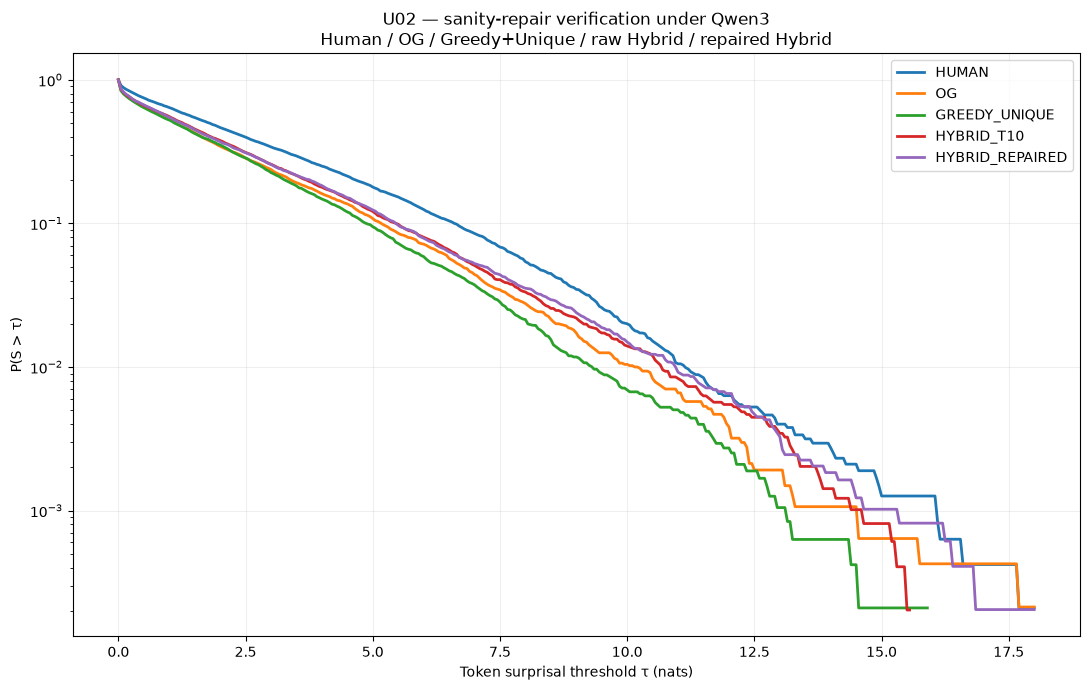


Critical sanity-repair comparison:


,scorer,RAW_minus_GREEDY,REPAIRED_minus_GREEDY,REPAIRED_minus_RAW
0,Qwen3,0.307988,0.449644,0.141656
1,GPT2,0.131010,0.289517,0.158507
2,SmolLM2,0.255766,0.415877,0.160111


In [37]:
# ============================================================
# U02 — sanity-repair verification
#
# IMPORTANT:
# Do NOT reconstruct HUMAN/OG/GREEDY/HYBRID texts.
# Their results already exist:
#
#   scored         = per-token losses for the last scorer
#   cross_summary  = summaries for Qwen3/GPT2/SmolLM2
#   cross_tail     = tail rates for Qwen3/GPT2/SmolLM2
#
# Only score the NEW 17+3 repaired panel.
# ============================================================

import gc
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM


# ------------------------------------------------------------
# 0. Preconditions
# ------------------------------------------------------------

assert "scored" in globals()
assert "cross_summary" in globals()
assert "cross_tail" in globals()
assert "score_text" in globals()
assert "SCORERS" in globals()
assert "u02_final20" in globals()

assert len(u02_final20) == 20


# Existing condition name.
RAW_COND = "HYBRID_T10"
NEW_COND = "HYBRID_REPAIRED"


# ------------------------------------------------------------
# 1. Inspect exact existing scorer ordering
# ------------------------------------------------------------

print("Existing scorers:")
print(list(SCORERS.keys()))

print("\nExisting cross-summary:")
display(
    cross_summary.pivot(
        index="condition",
        columns="scorer",
        values="mean",
    )
)


# ------------------------------------------------------------
# 2. Free any old model still occupying GPU
# ------------------------------------------------------------

for _name in [
    "model",
    "tok",
    "smodel",
    "stok",
    "past",
    "next_logits",
    "mask",
]:
    if _name in globals():
        try:
            del globals()[_name]
        except Exception:
            pass

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()


device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

dtype = (
    torch.float16
    if device.type == "cuda"
    else torch.float32
)


# ------------------------------------------------------------
# 3. Normalize score_text return
#
# Earlier score_text already exists, so use it directly.
# From the old `scored` format we want:
#
#   losses : 1-D numpy array
# ------------------------------------------------------------

def _run_score_text(text, stok, smodel):

    # This is the signature used by the earlier U02 scorer.
    result = score_text(
        text,
        stok,
        smodel,
    )

    # score_text may return losses directly or a tuple.
    if torch.is_tensor(result):
        return (
            result.detach()
            .float()
            .cpu()
            .numpy()
            .reshape(-1)
        )

    if isinstance(result, np.ndarray):
        return result.astype(
            np.float32
        ).reshape(-1)

    if isinstance(result, dict):
        for key in [
            "losses",
            "loss",
            "surprisal",
            "surprisals",
        ]:
            if key in result:
                x = result[key]

                if torch.is_tensor(x):
                    x = (
                        x.detach()
                        .float()
                        .cpu()
                        .numpy()
                    )

                return np.asarray(
                    x,
                    dtype=np.float32,
                ).reshape(-1)

    if isinstance(result, (tuple, list)):

        # Find first 1-D numeric object.
        for x in result:

            if torch.is_tensor(x):
                a = (
                    x.detach()
                    .float()
                    .cpu()
                    .numpy()
                )

            else:
                try:
                    a = np.asarray(x)
                except Exception:
                    continue

            if (
                a.ndim == 1
                and
                np.issubdtype(
                    a.dtype,
                    np.number,
                )
            ):
                return a.astype(
                    np.float32
                )

    raise TypeError(
        f"Unexpected score_text result type: "
        f"{type(result)}"
    )


# ------------------------------------------------------------
# 4. Exact repaired texts
# ------------------------------------------------------------

repaired = (
    u02_final20[
        [
            "case_id",
            "generated_text",
        ]
    ]
    .copy()
)

repaired["case_id"] = (
    repaired["case_id"]
    .astype(str)
)

repaired = repaired.rename(
    columns={
        "generated_text":
            "text"
    }
)


# ------------------------------------------------------------
# 5. Score ONLY repaired outputs under all three scorers
#
# The earlier notebook's `scored` table used complete `losses`
# arrays. We reproduce that exact object shape here.
# ------------------------------------------------------------

repaired_by_scorer = {}

new_summary_rows = []
new_tail_rows = []


for scorer_name, model_id in SCORERS.items():

    print(
        "\n"
        + "=" * 72
    )
    print(
        "Scorer:",
        scorer_name,
        "|",
        model_id,
    )
    print(
        "=" * 72
    )


    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


    stok = AutoTokenizer.from_pretrained(
        model_id,
        use_fast=True,
    )

    smodel = (
        AutoModelForCausalLM
        .from_pretrained(
            model_id,
            dtype=dtype,
            low_cpu_mem_usage=True,
        )
        .to(device)
        .eval()
    )


    rows = []

    for r in tqdm(
        repaired.itertuples(index=False),
        total=len(repaired),
        desc=f"Scoring repaired / {scorer_name}",
    ):

        losses = _run_score_text(
            str(r.text),
            stok,
            smodel,
        )

        rows.append({
            "case_id":
                r.case_id,

            "condition":
                NEW_COND,

            "n_scorer_tokens":
                len(losses),

            "losses":
                losses,
        })


    repaired_scored = pd.DataFrame(
        rows
    )

    repaired_by_scorer[
        scorer_name
    ] = repaired_scored


    # --------------------------------------------------------
    # Same pooled summary as existing cross_summary
    # --------------------------------------------------------

    flat = np.concatenate(
        repaired_scored[
            "losses"
        ].to_list()
    )


    new_summary_rows.append({
        "scorer":
            scorer_name,

        "condition":
            NEW_COND,

        "n_tokens":
            len(flat),

        "mean":
            float(np.mean(flat)),

        "median":
            float(np.median(flat)),

        "q90":
            float(np.quantile(flat, .90)),

        "q95":
            float(np.quantile(flat, .95)),

        "q99":
            float(np.quantile(flat, .99)),
    })


    # Same τ values already present in cross_tail.
    existing_taus = sorted(
        cross_tail.loc[
            cross_tail[
                "scorer"
            ].eq(scorer_name),
            "tau",
        ].unique()
    )


    for tau in existing_taus:

        new_tail_rows.append({
            "scorer":
                scorer_name,

            "condition":
                NEW_COND,

            "tau":
                tau,

            "P_S_gt_tau":
                float(
                    np.mean(
                        flat > tau
                    )
                ),
        })


    del smodel
    del stok

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()


# ------------------------------------------------------------
# 6. Append repaired condition to the EXISTING cross results
# ------------------------------------------------------------

repair_summary = pd.DataFrame(
    new_summary_rows
)

repair_tail = pd.DataFrame(
    new_tail_rows
)


cross_summary_repaired = pd.concat(
    [
        cross_summary,
        repair_summary,
    ],
    ignore_index=True,
)


cross_tail_repaired = pd.concat(
    [
        cross_tail,
        repair_tail,
    ],
    ignore_index=True,
)


ORDER = [
    "HUMAN",
    "OG",
    "GREEDY_UNIQUE",
    RAW_COND,
    NEW_COND,
]


print(
    "\nMean surprisal:"
)

display(
    cross_summary_repaired
    .pivot(
        index="condition",
        columns="scorer",
        values="mean",
    )
    .reindex(
        ORDER
    )
)


# ------------------------------------------------------------
# 7. Tail-rate tables
#
# These are enough to verify the effect under ALL three
# independent scorers even though only the last scorer's full
# old loss arrays survived in memory.
# ------------------------------------------------------------

for tau in sorted(
    cross_tail_repaired[
        "tau"
    ].unique()
):

    print(
        f"\nP(S > {tau}):"
    )

    display(
        cross_tail_repaired.loc[
            cross_tail_repaired[
                "tau"
            ].eq(tau)
        ]
        .pivot(
            index="condition",
            columns="scorer",
            values="P_S_gt_tau",
        )
        .reindex(
            ORDER
        )
    )


# ------------------------------------------------------------
# 8. FULL SURVIVAL CURVE for the scorer whose old token losses
# are still resident in `scored`.
#
# `scored` is the exact 80-row object used by the last plot.
# Infer which scorer it corresponds to by comparing its pooled
# means against cross_summary.
# ------------------------------------------------------------

old_means = (
    scored
    .assign(
        _mean=
            scored[
                "losses"
            ].map(
                lambda x:
                    float(
                        np.mean(
                            np.asarray(x)
                        )
                    )
            )
    )
    .groupby(
        "condition"
    )[
        "_mean"
    ]
    .mean()
)


# More robust inference: compare pooled losses directly
# against each cross-summary scorer.
scored_flat_means = {}

for condition, d in scored.groupby(
    "condition"
):

    flat = np.concatenate(
        [
            np.asarray(
                x,
                dtype=float,
            )
            for x in d[
                "losses"
            ]
        ]
    )

    scored_flat_means[
        condition
    ] = float(
        np.mean(flat)
    )


errors = {}

for scorer_name in SCORERS:

    err = 0.0

    for condition in [
        "HUMAN",
        "OG",
        "GREEDY_UNIQUE",
        RAW_COND,
    ]:

        target = float(
            cross_summary.loc[
                (
                    cross_summary[
                        "scorer"
                    ].eq(
                        scorer_name
                    )
                )
                &
                (
                    cross_summary[
                        "condition"
                    ].eq(
                        condition
                    )
                ),
                "mean",
            ].iloc[0]
        )

        err += abs(
            scored_flat_means[
                condition
            ]
            - target
        )

    errors[
        scorer_name
    ] = err


resident_scorer = min(
    errors,
    key=errors.get,
)


print(
    "\nExisting `scored` corresponds to:",
    resident_scorer,
)


plot_scored = pd.concat(
    [
        scored,
        repaired_by_scorer[
            resident_scorer
        ],
    ],
    ignore_index=True,
)


tau_grid = np.linspace(
    0,
    18,
    361,
)


fig, ax = plt.subplots(
    figsize=(11, 7)
)


for condition in ORDER:

    d = plot_scored.loc[
        plot_scored[
            "condition"
        ].eq(condition)
    ]

    flat = np.concatenate(
        [
            np.asarray(
                x,
                dtype=float,
            )
            for x in d[
                "losses"
            ]
        ]
    )


    surv = np.array([
        np.mean(
            flat > tau
        )
        for tau in tau_grid
    ])

    keep = surv > 0


    ax.plot(
        tau_grid[keep],
        surv[keep],
        linewidth=2,
        label=condition,
    )


ax.set_yscale(
    "log"
)

ax.set_xlabel(
    "Token surprisal threshold τ (nats)"
)

ax.set_ylabel(
    "P(S > τ)"
)

ax.set_title(
    f"U02 — sanity-repair verification under {resident_scorer}\n"
    "Human / OG / Greedy+Unique / raw Hybrid / repaired Hybrid"
)

ax.grid(
    alpha=.2
)

ax.legend()

fig.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. Direct numerical answer to the concern
# ------------------------------------------------------------

means = (
    cross_summary_repaired
    .pivot(
        index="condition",
        columns="scorer",
        values="mean",
    )
)


verification_rows = []


for scorer_name in SCORERS:

    verification_rows.append({
        "scorer":
            scorer_name,

        "RAW_minus_GREEDY":
            float(
                means.loc[
                    RAW_COND,
                    scorer_name,
                ]
                -
                means.loc[
                    "GREEDY_UNIQUE",
                    scorer_name,
                ]
            ),

        "REPAIRED_minus_GREEDY":
            float(
                means.loc[
                    NEW_COND,
                    scorer_name,
                ]
                -
                means.loc[
                    "GREEDY_UNIQUE",
                    scorer_name,
                ]
            ),

        "REPAIRED_minus_RAW":
            float(
                means.loc[
                    NEW_COND,
                    scorer_name,
                ]
                -
                means.loc[
                    RAW_COND,
                    scorer_name,
                ]
            ),
    })


verification = pd.DataFrame(
    verification_rows
)


print(
    "\nCritical sanity-repair comparison:"
)

display(
    verification
)

In [38]:
# ============================================================
# U02 — FINAL full system, generated FROM SCRATCH
#
# Components:
#
#   Llama-3.2-3B-Instruct
#   + WITH_PREV
#   + Unique primary controller
#   + T=1 sampling in free / Unique-equivalent opportunities
#   + post-reference CEILING-ONLY Unique control
#   + online predictive-entropy coherence detector
#   + retroactive rewind
#   + temporary Unique-OFF recovery
#   + automatic return to normal Hybrid control
#
# Frozen coherence rule from gate_0070:
#
#   rolling-16 H > 5.0
#   for >= 8 consecutive model tokens
#   -> coherence collapse
#
# Rewind:
#   danger onset - 24 additional model tokens,
#   rounded BACKWARD to an actual complete-word controller
#   checkpoint so every piece of Unique/controller state is
#   restored consistently.
#
# Recovery:
#   Unique OFF, T=1 ON
#   until regenerated text reaches the alarm's word position.
#   Then normal Hybrid control resumes automatically.
#
# Post-reference Unique:
#   when empirical human reference expires:
#
#       k > last supported H_a10 -> decrease
#       otherwise                -> no Unique control
#
#   NO uniqueness floor is extrapolated.
#
# Deterministic completion:
#   MAX 24 coherence rewinds.
#   If that engineering bound is ever exhausted, restore the
#   safe checkpoint and finish greedily/no-Unique.
#
# Expected real result: fallback count should be ZERO.
# ============================================================

import copy
import gc
import hashlib
import json
import math
from collections import Counter

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from tqdm.auto import tqdm
from IPython.display import display
from transformers import AutoTokenizer, AutoModelForCausalLM


# ------------------------------------------------------------
# 0. Preconditions from the existing U02 notebook
# ------------------------------------------------------------

_REQUIRED = [
    "ROOT",
    "OUT",
    "cohort",
    "case_contract",
    "UNIQUE_THETA_SCHEDULES",
    "HybridBackend",
    "run_feedback_hybrid",
    "initial_state",
    "reference_at",
    "word_spans",
    "counts",
    "trajectory_metrics",
    "make_search",
    "prompt_ids",
]

_missing = [
    x
    for x in _REQUIRED
    if x not in globals()
]

assert not _missing, (
    "Run the normal U02 setup/controller cells first. "
    f"Missing: {_missing}"
)

assert len(cohort) == 20
assert cohort["case_id"].is_unique


# ------------------------------------------------------------
# 1. Frozen final-system constants
# ------------------------------------------------------------

FS_CONDITION = "HYBRID_T10_ENTROPY_REWIND"

FS_H_WINDOW = 16
FS_H_DANGER = 5.0
FS_H_PERSISTENCE = 8
FS_REWIND_BACKOFF_TOKENS = 24

FS_MAX_REWINDS = 24

FS_NAMESPACE = (
    "U02_FULL_SYSTEM_FROM_SCRATCH_v1"
)

FS_MAX_NEW_TOKENS = 640

assert MAX_NEW_TOKENS == FS_MAX_NEW_TOKENS
assert SAMPLE_TEMPERATURE == 1.0
assert SAMPLE_TOP_P == 1.0
assert UNIQUE_RATIO_FLOOR == 0.05


# Separate output so none of the earlier evidence is overwritten.
FS_OUT = (
    OUT
    / "full_system_from_scratch_v1"
)

FS_OUT.mkdir(
    parents=True,
    exist_ok=True,
)

FS_STATE_DIR = (
    FS_OUT
    / "states"
)

FS_STATE_DIR.mkdir(
    exist_ok=True,
)

FS_GEN_PATH = (
    FS_OUT
    / "full_system_generations.parquet"
)

FS_REWIND_PATH = (
    FS_OUT
    / "coherence_rewind_events.csv"
)


# ------------------------------------------------------------
# 2. Reload generator.
#
# The cross-scorer verification cell deliberately freed it.
# ------------------------------------------------------------

for _name in [
    "model",
    "tok",
    "smodel",
    "stok",
    "past",
    "next_logits",
    "mask",
]:

    if _name in globals():

        try:
            del globals()[_name]
        except Exception:
            pass


gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()


device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

GEN_DTYPE = (
    torch.float16
    if device.type == "cuda"
    else torch.float32
)


tok = AutoTokenizer.from_pretrained(
    MODEL_ID,
    use_fast=True,
)

model = (
    AutoModelForCausalLM
    .from_pretrained(
        MODEL_ID,
        dtype=GEN_DTYPE,
        low_cpu_mem_usage=True,
    )
    .to(device)
    .eval()
)


eos = (
    model
    .generation_config
    .eos_token_id
)

if eos is None:
    eos = tok.eos_token_id

EOS_IDS = set(
    eos
    if isinstance(
        eos,
        (list, tuple),
    )
    else [eos]
)

FORBIDDEN_SPECIAL = (
    set(tok.all_special_ids)
    - EOS_IDS
)


# Reinstate exact 0.05 Unique search guard.
globals()[
    "search_word"
] = make_search(
    UNIQUE_RATIO_FLOOR
)


print(
    "Generator:",
    MODEL_ID,
)

print(
    "Device:",
    device,
)

if torch.cuda.is_available():

    free, total = (
        torch.cuda.mem_get_info()
    )

    print(
        "CUDA free:",
        f"{free / 2**30:.2f}",
        "/",
        f"{total / 2**30:.2f}",
        "GiB",
    )


# ------------------------------------------------------------
# 3. Deterministic fresh-run seeds
# ------------------------------------------------------------

def fs_case_seed(
    case_id,
):

    h = hashlib.sha256(
        (
            f"{FS_NAMESPACE}|"
            f"{case_id}"
        ).encode()
    ).digest()

    return (
        int.from_bytes(
            h[:8],
            "little",
            signed=False,
        )
        % (2**63 - 1)
    )


# ------------------------------------------------------------
# 4. Last supported human Unique reference
# ------------------------------------------------------------

def fs_last_supported_reference(
    curve,
):

    supported = [
        copy.deepcopy(r)
        for r in curve.values()
        if r.get(
            "supported",
            False,
        )
    ]

    assert supported, (
        "Unique curve has no supported position."
    )

    last = max(
        supported,
        key=lambda r:
            int(
                r["W"]
            ),
    )

    return last


# ------------------------------------------------------------
# 5. Freeze the CURRENT U02 adaptive functions.
#
# We'll temporarily wrap them during the final run.
# ------------------------------------------------------------

_FS_U02_ADAPTIVE_MODE = (
    adaptive_mode
)

_FS_U02_ADAPTIVE_THETA = (
    adaptive_theta
)


# Current per-case runtime. Sequential generation only.
_FS_RUNTIME = None


def fs_adaptive_mode(
    previous,
    V,
    W,
    warmup_words,
    ref,
):

    """
    Final Unique state machine.

    A. During entropy recovery:
       Unique OFF unconditionally.

    B. While human reference is supported:
       exact existing U02 Unique policy.

    C. After reference support expires:
       only retain the LAST KNOWN UPPER CEILING.
       Never extrapolate a lower bound.
    """

    global _FS_RUNTIME

    rt = _FS_RUNTIME


    # --------------------------------------------------------
    # Recovery mode:
    #
    # regenerate the failed region with pure T1.
    # Once we have traversed the alarm word position,
    # automatically return to normal Hybrid control.
    # --------------------------------------------------------

    if rt is not None:

        until_word = rt.get(
            "recovery_until_word"
        )

        if until_word is not None:

            if W < int(
                until_word
            ):

                return "normal"

            # Recovery region successfully traversed.
            rt[
                "recovery_until_word"
            ] = None


    # --------------------------------------------------------
    # Ordinary supported reference:
    # exact prior U02 behavior.
    # --------------------------------------------------------

    if ref.get(
        "supported",
        False,
    ):

        return _FS_U02_ADAPTIVE_MODE(
            previous,
            V,
            W,
            warmup_words,
            ref,
        )


    if rt is None:

        return _FS_U02_ADAPTIVE_MODE(
            previous,
            V,
            W,
            warmup_words,
            ref,
        )


    last_ref = rt[
        "last_supported_ref"
    ]

    last_W = int(
        last_ref["W"]
    )


    # Unsupported positions BEFORE actual reference expiry
    # remain ordinary unsupported/inactive positions.
    if (
        W <= last_W
        or
        W < warmup_words
        or
        W == 0
    ):

        return _FS_U02_ADAPTIVE_MODE(
            previous,
            V,
            W,
            warmup_words,
            ref,
        )


    # --------------------------------------------------------
    # Post-reference ceiling ONLY.
    #
    # k naturally trends downward with W.
    # We intervene only if it is ABOVE the last known ceiling.
    # There is intentionally no upward intervention.
    # --------------------------------------------------------

    k = (
        V / W
    )

    ceiling = float(
        last_ref[
            "H_a10"
        ]
    )


    if k > ceiling:

        return "decrease"


    return "normal"


def fs_adaptive_theta(
    mode,
    k,
    w,
    ref,
    schedules,
):

    global _FS_RUNTIME

    rt = _FS_RUNTIME


    # Supported range:
    # exact U02 theta policy.
    if ref.get(
        "supported",
        False,
    ):

        return _FS_U02_ADAPTIVE_THETA(
            mode,
            k,
            w,
            ref,
            schedules,
        )


    # Post-reference decrease uses the geometry of the LAST
    # supported human reference, but activation itself occurs
    # ONLY after crossing H_a10.
    if (
        mode == "decrease"
        and
        rt is not None
        and
        w
        > int(
            rt[
                "last_supported_ref"
            ][
                "W"
            ]
        )
    ):

        return _FS_U02_ADAPTIVE_THETA(
            mode,
            k,
            w,
            rt[
                "last_supported_ref"
            ],
            schedules,
        )


    return (
        None,
        None,
    )


# ------------------------------------------------------------
# 6. Entropy-aware backend
#
# Every distribution evaluation records ONLY a scalar entropy
# keyed by the exact generated prefix.
#
# Search may explore many branches, but after the word commits
# we extract entropy only along the ACTUAL selected trajectory.
# No extra forward pass is normally required.
# ------------------------------------------------------------

class FullSystemBackend(
    HybridBackend
):

    def __init__(
        self,
        prompt_token_ids,
        method,
        seed,
    ):

        super().__init__(
            prompt_token_ids,
            method,
            seed,
        )

        self.entropy_by_prefix = {}


    @torch.inference_mode()
    def _distribution(
        self,
        ids,
    ):

        q = super()._distribution(
            ids
        )


        # Match the actual permitted T1 distribution used by
        # the Hybrid sampler: protocol specials removed,
        # remaining mass renormalized.
        valid = q.clone()

        for tid in FORBIDDEN_SPECIAL:

            if tid < len(
                valid
            ):

                valid[
                    int(tid)
                ] = 0.0


        mass = valid.sum()

        if (
            torch.isfinite(
                mass
            ).item()
            and
            float(
                mass.item()
            )
            > 0
        ):

            p = (
                valid
                / mass
            )

            nz = (
                p > 0
            )

            H = float(
                (
                    -p[nz]
                    * torch.log(
                        p[nz]
                    )
                )
                .sum()
                .item()
            )

            self.entropy_by_prefix[
                tuple(
                    int(x)
                    for x in ids
                )
            ] = H


        del valid

        return q


# ------------------------------------------------------------
# 7. Controller-state snapshots
#
# Rewind MUST restore:
#   ids
#   probabilities
#   committed text
#   Unique word ledger
#   mode
#   trajectory
#   intervention counters
#
# The sampling RNG is deliberately NOT rewound:
# resampling must take a new deterministic branch rather than
# recreating the branch we just rejected.
# ------------------------------------------------------------

def fs_snapshot_state(
    state,
):

    snap = {}

    for key, value in state.items():

        if isinstance(
            value,
            list,
        ):

            snap[
                key
            ] = list(
                value
            )

        elif isinstance(
            value,
            dict,
        ):

            snap[
                key
            ] = dict(
                value
            )

        else:

            snap[
                key
            ] = value


    return snap


def fs_restore_state(
    state,
    snapshot,
):

    state.clear()

    state.update(
        fs_snapshot_state(
            snapshot
        )
    )

    state[
        "finished"
    ] = False

    state[
        "status"
    ] = "running"

    state.pop(
        "last_error",
        None,
    )

    state.pop(
        "exception",
        None,
    )


# ------------------------------------------------------------
# 8. Coherence-collapse control exception
# ------------------------------------------------------------

class FSCoherenceCollapse(
    RuntimeError
):

    def __init__(
        self,
        event,
        target_snapshot,
        target_snapshot_index,
    ):

        super().__init__(
            "Persistent predictive-entropy collapse."
        )

        self.event = event

        self.target_snapshot = (
            target_snapshot
        )

        self.target_snapshot_index = int(
            target_snapshot_index
        )


# ------------------------------------------------------------
# 9. Online entropy checkpoint
# ------------------------------------------------------------

def fs_make_checkpoint(
    backend,
    runtime,
):

    def checkpoint(
        state,
    ):

        # run_feedback_hybrid calls checkpoint once more while
        # propagating an exception. Never process the same bad
        # path twice.
        if runtime.get(
            "alarm_pending",
            False,
        ):

            return


        ids = list(
            state.get(
                "ids",
                [],
            )
        )

        n = len(
            ids
        )

        start = int(
            runtime[
                "last_monitored_token_count"
            ]
        )


        assert n >= start, (
            start,
            n,
        )


        # ----------------------------------------------------
        # Process each newly COMMITTED model token.
        # ----------------------------------------------------

        for j in range(
            start,
            n,
        ):

            prefix = tuple(
                ids[
                    :j
                ]
            )

            H = (
                backend
                .entropy_by_prefix
                .get(
                    prefix
                )
            )


            # This should almost never be needed because every
            # selected token was obtained from _distribution().
            # It is an exact fallback, not an approximation.
            if H is None:

                q = backend._distribution(
                    list(
                        prefix
                    )
                )

                H = (
                    backend
                    .entropy_by_prefix[
                        prefix
                    ]
                )

                del q


            runtime[
                "epoch_entropy"
            ].append(
                float(
                    H
                )
            )


            hist = runtime[
                "epoch_entropy"
            ]


            if len(
                hist
            ) >= FS_H_WINDOW:

                H_roll = float(
                    np.mean(
                        hist[
                            -FS_H_WINDOW:
                        ]
                    )
                )

            else:

                H_roll = np.nan


            if (
                np.isfinite(
                    H_roll
                )
                and
                H_roll
                > FS_H_DANGER
            ):

                runtime[
                    "danger_run"
                ] += 1

            else:

                runtime[
                    "danger_run"
                ] = 0


            if (
                runtime[
                    "danger_run"
                ]
                < FS_H_PERSISTENCE
            ):

                continue


            # ------------------------------------------------
            # ALARM.
            #
            # j is zero-based token index of current token.
            # alarm_token is a one-past / token-count index.
            # ------------------------------------------------

            alarm_token = (
                j + 1
            )

            danger_start = (
                alarm_token
                - runtime[
                    "danger_run"
                ]
            )

            raw_target = max(
                0,
                danger_start
                - FS_REWIND_BACKOFF_TOKENS,
            )


            # -----------------------------------------------
            # Round BACKWARD to a genuine complete-word
            # controller checkpoint.
            # -----------------------------------------------

            snapshots = runtime[
                "snapshots"
            ]

            assert snapshots


            target_index = 0

            for i, snap in enumerate(
                snapshots
            ):

                if len(
                    snap.get(
                        "ids",
                        [],
                    )
                ) <= raw_target:

                    target_index = i


            target_snapshot = (
                snapshots[
                    target_index
                ]
            )

            target_tokens = len(
                target_snapshot.get(
                    "ids",
                    [],
                )
            )

            target_words = len(
                target_snapshot.get(
                    "words",
                    [],
                )
            )


            # Word position reached by the actual trajectory
            # at the alarm. Recovery stays Unique-OFF until
            # this word position has been traversed again.
            alarm_text = backend.decode(
                ids[
                    :alarm_token
                ]
            )

            alarm_word = len(
                word_spans(
                    alarm_text
                )
            )


            last_entry = (
                state[
                    "trajectory"
                ][-1]
                if state.get(
                    "trajectory"
                )
                else {}
            )


            event = {
                "case_id":
                    runtime[
                        "case_id"
                    ],

                "alarm_number":
                    len(
                        runtime[
                            "events"
                        ]
                    )
                    + 1,

                "alarm_output_token":
                    int(
                        alarm_token
                    ),

                "danger_start_output_token":
                    int(
                        danger_start
                    ),

                "raw_rewind_target_token":
                    int(
                        raw_target
                    ),

                "actual_rewind_target_token":
                    int(
                        target_tokens
                    ),

                "alarm_word":
                    int(
                        alarm_word
                    ),

                "actual_rewind_target_word":
                    int(
                        target_words
                    ),

                "tokens_removed":
                    int(
                        n
                        - target_tokens
                    ),

                "last_H_roll16":
                    float(
                        H_roll
                    ),

                "danger_run":
                    int(
                        runtime[
                            "danger_run"
                        ]
                    ),

                "unique_active_at_alarm":
                    bool(
                        last_entry.get(
                            "unique_active",
                            False,
                        )
                    ),

                "mode_at_alarm":
                    last_entry.get(
                        "mode_before"
                    ),

                "secondary_policy_at_alarm":
                    last_entry.get(
                        "secondary_policy"
                    ),

                "reference_supported_at_alarm":
                    bool(
                        last_entry
                        .get(
                            "reference_before",
                            {},
                        )
                        .get(
                            "supported",
                            False,
                        )
                    ),

                "already_in_recovery":
                    (
                        runtime.get(
                            "recovery_until_word"
                        )
                        is not None
                    ),
            }


            runtime[
                "events"
            ].append(
                event
            )

            runtime[
                "alarm_pending"
            ] = True


            raise FSCoherenceCollapse(
                event,
                target_snapshot,
                target_index,
            )


        # ----------------------------------------------------
        # Healthy checkpoint.
        #
        # Even if no new model token was needed because of a
        # tokenizer straddle, preserve the advanced word-ledger
        # state.
        # ----------------------------------------------------

        runtime[
            "last_monitored_token_count"
        ] = n


        backend.entropy_by_prefix.clear()


        runtime[
            "snapshots"
        ].append(
            fs_snapshot_state(
                state
            )
        )


    return checkpoint


# ------------------------------------------------------------
# 10. Formal deterministic-completion fallback
#
# Should NOT be used in the actual experiment.
# Exists only so the procedure has a finite completion bound.
# ------------------------------------------------------------

@torch.inference_mode()
def fs_greedy_finish(
    backend,
    state,
):

    current_ids = list(
        state.get(
            "ids",
            [],
        )
    )

    remaining = (
        FS_MAX_NEW_TOKENS
        - len(
            current_ids
        )
    )


    if remaining <= 0:

        state[
            "status"
        ] = "truncated_token_cap"

        state[
            "finished"
        ] = False

        return state


    full_input = (
        list(
            backend.prompt_ids
        )
        +
        current_ids
    )


    x = torch.tensor(
        [
            full_input
        ],
        dtype=torch.long,
        device=device,
    )

    attention_mask = (
        torch.ones_like(
            x
        )
    )


    bad_words_ids = [
        [
            int(
                tid
            )
        ]
        for tid in sorted(
            FORBIDDEN_SPECIAL
        )
    ]


    generated = model.generate(
        input_ids=x,
        attention_mask=attention_mask,

        do_sample=False,

        max_new_tokens=int(
            remaining
        ),

        eos_token_id=list(
            EOS_IDS
        ),

        pad_token_id=(
            tok.eos_token_id
        ),

        bad_words_ids=bad_words_ids,

        use_cache=True,
    )


    output_ids = (
        generated[
            0,
            len(
                backend.prompt_ids
            ):
        ]
        .detach()
        .cpu()
        .tolist()
    )


    text = backend.decode(
        output_ids
    )

    words = [
        w.lower()
        for w, _, _ in word_spans(
            text
        )
    ]


    stopped_eos = bool(
        output_ids
        and
        output_ids[-1]
        in EOS_IDS
    )


    state[
        "ids"
    ] = output_ids

    state[
        "committed_text"
    ] = text

    state[
        "words"
    ] = words

    state[
        "mode"
    ] = "normal"

    state[
        "finished"
    ] = bool(
        stopped_eos
    )

    state[
        "status"
    ] = (
        "completed_eos_greedy_fallback"
        if stopped_eos
        else
        "truncated_token_cap"
    )


    del generated
    del x
    del attention_mask


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    return state


# ------------------------------------------------------------
# 11. Contract
# ------------------------------------------------------------

FS_CONTRACT = {
    "version":
        FS_NAMESPACE,

    "model_id":
        MODEL_ID,

    "with_prev":
        True,

    "temporal_method":
        "FULL",

    "max_new_tokens":
        FS_MAX_NEW_TOKENS,

    "unique_ratio_floor":
        UNIQUE_RATIO_FLOOR,

    "downward_theta_multiplier":
        DOWNWARD_THETA_MULTIPLIER,

    "sampling_temperature":
        1.0,

    "sampling_top_p":
        1.0,

    "entropy_window":
        FS_H_WINDOW,

    "entropy_danger":
        FS_H_DANGER,

    "entropy_persistence":
        FS_H_PERSISTENCE,

    "rewind_backoff_model_tokens":
        FS_REWIND_BACKOFF_TOKENS,

    "max_rewinds":
        FS_MAX_REWINDS,

    "post_reference_policy":
        (
            "ceiling_only_last_supported_H_a10"
        ),

    "recovery_policy":
        (
            "rewind to complete-word checkpoint at/before "
            "danger_start-24; Unique OFF + T1 until alarm "
            "word position is traversed; then resume Hybrid"
        ),

    "rng_policy":
        (
            "controller state rewinds; sampling RNG does not"
        ),
}


FS_CONTRACT_PATH = (
    FS_OUT
    / "contract.json"
)


if FS_CONTRACT_PATH.exists():

    assert (
        json.loads(
            FS_CONTRACT_PATH.read_text()
        )
        ==
        FS_CONTRACT
    ), (
        "Final-system contract changed. "
        "Use a new output directory/version."
    )

else:

    FS_CONTRACT_PATH.write_text(
        json.dumps(
            FS_CONTRACT,
            indent=2,
            sort_keys=True,
        )
    )


# ------------------------------------------------------------
# 12. Preflight ceiling behavior
# ------------------------------------------------------------

_ref_rows = []

for cid in cohort[
    "case_id"
].astype(str):

    c = case_contract[
        cid
    ]

    last = (
        fs_last_supported_reference(
            c[
                "curve"
            ]
        )
    )

    _ref_rows.append({
        "case_id":
            cid,

        "last_supported_word":
            int(
                last[
                    "W"
                ]
            ),

        "last_unique_ceiling":
            float(
                last[
                    "H_a10"
                ]
            ),
    })


print(
    "\nFinal-system reference expiry:"
)

display(
    pd.DataFrame(
        _ref_rows
    )
)


print(
    "\nFull-system controller defined."
)

Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████| 254/254 [00:00<00:00, 307.66it/s]


Generator: meta-llama/Llama-3.2-3B-Instruct
Device: cuda
CUDA free: 0.40 / 7.62 GiB

Final-system reference expiry:


,case_id,last_supported_word,last_unique_ceiling
0,gate_0090,169,0.607101
1,gate_0070,229,0.593886
2,gate_0017,331,0.551057
3,gate_0085,224,0.549107
4,gate_0038,155,0.623226
5,gate_0039,171,0.612865
6,gate_0069,120,0.668333
7,gate_0035,210,0.606667
8,gate_0003,385,0.544935
9,gate_0025,234,0.540171



Full-system controller defined.


In [39]:
# ============================================================
# U02 — RUN fresh 20-case final-system generation
#
# This does NOT reuse any Hybrid output.
# Every case begins from an empty generated suffix.
#
# A partially interrupted run can be resumed safely because
# each completed case is persisted independently.
# ============================================================

# ------------------------------------------------------------
# 0. Install final adaptive wrappers only for this run
# ------------------------------------------------------------

_saved_adaptive_mode = (
    globals()[
        "adaptive_mode"
    ]
)

_saved_adaptive_theta = (
    globals()[
        "adaptive_theta"
    ]
)

globals()[
    "adaptive_mode"
] = fs_adaptive_mode

globals()[
    "adaptive_theta"
] = fs_adaptive_theta


# ------------------------------------------------------------
# 1. Existing partial result = resume only.
#
# On the first execution this should be empty, so all 20 are
# genuinely generated from scratch.
# ------------------------------------------------------------

if FS_GEN_PATH.exists():

    fs_gen = pd.read_parquet(
        FS_GEN_PATH
    )

else:

    fs_gen = pd.DataFrame()


done = (
    set(
        fs_gen[
            "case_id"
        ].astype(str)
    )
    if len(
        fs_gen
    )
    else set()
)


print(
    "Already complete:",
    len(
        done
    ),
)

print(
    "Fresh cases to run:",
    20
    - len(
        done
    ),
)


all_rewind_events = []

if FS_REWIND_PATH.exists():

    try:

        all_rewind_events = (
            pd.read_csv(
                FS_REWIND_PATH
            )
            .to_dict(
                "records"
            )
        )

    except Exception:

        all_rewind_events = []


pbar = tqdm(
    total=len(
        cohort
    ),
    initial=len(
        done
    ),
    desc=(
        "U02 FINAL from-scratch"
    ),
)


try:

    for src_row in cohort.itertuples(
        index=False
    ):

        cid = str(
            src_row.case_id
        )


        if cid in done:

            continue


        # ----------------------------------------------------
        # Exact frozen Unique reference for this case
        # ----------------------------------------------------

        c = case_contract[
            cid
        ]

        curve = c[
            "curve"
        ]

        warmup_words = int(
            c[
                "warmup_words"
            ]
        )

        last_ref = (
            fs_last_supported_reference(
                curve
            )
        )


        # ----------------------------------------------------
        # Fresh backend + EMPTY generated suffix
        # ----------------------------------------------------

        seed = fs_case_seed(
            cid
        )

        backend = FullSystemBackend(
            prompt_ids(
                src_row.prompt,
                src_row.previous_ai,
            ),
            "FULL",
            seed,
        )


        state = initial_state(
            FS_CONDITION
        )


        runtime = {
            "case_id":
                cid,

            "last_supported_ref":
                last_ref,

            "recovery_until_word":
                None,

            # Entropy state is reset after every rewind,
            # exactly as in the validated repair experiment.
            "epoch_entropy":
                [],

            "danger_run":
                0,

            "last_monitored_token_count":
                0,

            "snapshots":
                [
                    fs_snapshot_state(
                        state
                    )
                ],

            "events":
                [],

            "alarm_pending":
                False,

            "rewinds":
                0,

            "discarded_tokens":
                0,

            "used_greedy_fallback":
                False,

            "fallback_reason":
                None,
        }


        _FS_RUNTIME = (
            runtime
        )


        checkpoint = (
            fs_make_checkpoint(
                backend,
                runtime,
            )
        )


        # ----------------------------------------------------
        # Controller may restart after a coherence rewind,
        # but always from a genuine saved controller state.
        # ----------------------------------------------------

        while True:

            try:

                run_feedback_hybrid(
                    backend,
                    state,
                    curve,
                    warmup_words,
                    UNIQUE_THETA_SCHEDULES,

                    checkpoint=
                        checkpoint,
                )


                # Normal EOS completion.
                break


            except FSCoherenceCollapse as collapse:

                runtime[
                    "alarm_pending"
                ] = False


                event = (
                    collapse.event
                )


                # --------------------------------------------
                # Restore complete controller state.
                # --------------------------------------------

                fs_restore_state(
                    state,
                    collapse.target_snapshot,
                )


                runtime[
                    "discarded_tokens"
                ] += int(
                    event[
                        "tokens_removed"
                    ]
                )


                # --------------------------------------------
                # Hard finite-retry guarantee.
                # --------------------------------------------

                if (
                    runtime[
                        "rewinds"
                    ]
                    >= FS_MAX_REWINDS
                ):

                    runtime[
                        "used_greedy_fallback"
                    ] = True

                    runtime[
                        "fallback_reason"
                    ] = (
                        "coherence_rewind_limit"
                    )


                    fs_greedy_finish(
                        backend,
                        state,
                    )

                    break


                runtime[
                    "rewinds"
                ] += 1


                # --------------------------------------------
                # Recovery span:
                #
                # Unique stays OFF until we have regenerated
                # through the word position where collapse
                # was observed.
                #
                # If an earlier recovery was already trying
                # to cross a farther point, preserve that.
                # --------------------------------------------

                old_until = runtime.get(
                    "recovery_until_word"
                )

                new_until = int(
                    event[
                        "alarm_word"
                    ]
                )


                runtime[
                    "recovery_until_word"
                ] = (
                    new_until
                    if old_until is None
                    else max(
                        int(
                            old_until
                        ),
                        new_until,
                    )
                )


                # --------------------------------------------
                # Reset ONLY coherence-detector epoch.
                #
                # RNG deliberately continues forward so the
                # same rejected stochastic branch cannot
                # simply regenerate itself.
                # --------------------------------------------

                runtime[
                    "epoch_entropy"
                ] = []

                runtime[
                    "danger_run"
                ] = 0

                runtime[
                    "last_monitored_token_count"
                ] = len(
                    state[
                        "ids"
                    ]
                )

                runtime[
                    "alarm_pending"
                ] = False


                # All snapshots lying on the discarded future
                # trajectory are invalid.
                runtime[
                    "snapshots"
                ] = runtime[
                    "snapshots"
                ][
                    :
                    collapse
                    .target_snapshot_index
                    + 1
                ]


                backend.entropy_by_prefix.clear()


                continue


            except TokenCapReached:

                state[
                    "finished"
                ] = False

                state[
                    "status"
                ] = (
                    "truncated_token_cap"
                )

                break


            except Exception as exc:

                state[
                    "finished"
                ] = False

                state[
                    "status"
                ] = (
                    "failed_exception"
                )

                state[
                    "exception"
                ] = repr(
                    exc
                )

                break


        # ----------------------------------------------------
        # Final text + Unique statistics
        # ----------------------------------------------------

        text = backend.decode(
            state.get(
                "ids",
                [],
            )
        )

        V, W = counts(
            text
        )

        k = (
            V / W
            if W
            else np.nan
        )


        ref = (
            reference_at(
                curve,
                W,
            )
            if W
            else {
                "supported":
                    False
            }
        )


        final_distance = np.nan

        final_normalized_distance = (
            np.nan
        )


        if (
            ref.get(
                "supported",
                False,
            )
            and
            np.isfinite(
                k
            )
        ):

            final_distance = max(
                ref[
                    "H_h30"
                ]
                - k,
                0.0,
                k
                - ref[
                    "H_a10"
                ],
            )

            final_normalized_distance = (
                final_distance
                /
                max(
                    ref[
                        "H_a10"
                    ]
                    -
                    ref[
                        "H_h30"
                    ],
                    1
                    /
                    max(
                        W,
                        1,
                    ),
                )
            )


        in_band = (
            bool(
                ref.get(
                    "supported",
                    False,
                )
            )
            and
            np.isfinite(
                k
            )
            and
            ref[
                "H_h30"
            ]
            <= k
            <= ref[
                "H_a10"
            ]
        )


        last_supported_W = int(
            last_ref[
                "W"
            ]
        )

        expired_ceiling = float(
            last_ref[
                "H_a10"
            ]
        )


        final_above_expired_ceiling = (
            bool(
                W
                > last_supported_W
                and
                np.isfinite(
                    k
                )
                and
                k
                > expired_ceiling
            )
        )


        traj = state.get(
            "trajectory",
            [],
        )

        tmetrics = (
            trajectory_metrics(
                traj,
                warmup_words,
            )
        )


        action_counts = Counter(
            t.get(
                "action",
                "unknown",
            )
            for t in traj
        )


        postref_ceiling_decrease_words = sum(
            1
            for t in traj
            if (
                t.get(
                    "mode_before"
                )
                == "decrease"
                and
                not t.get(
                    "reference_before",
                    {},
                ).get(
                    "supported",
                    False,
                )
                and
                int(
                    t.get(
                        "W_before",
                        0,
                    )
                )
                > last_supported_W
            )
        )


        if state[
            "status"
        ] in {
            "completed_eos",
            "completed_eos_greedy_fallback",
        }:

            stop_reason = "eos"

        elif (
            state[
                "status"
            ]
            ==
            "truncated_token_cap"
        ):

            stop_reason = (
                "truncated"
            )

        elif (
            state[
                "status"
            ]
            ==
            "failed_exception"
        ):

            stop_reason = (
                "exception"
            )

        else:

            stop_reason = str(
                state[
                    "status"
                ]
            )


        events = runtime[
            "events"
        ]


        row = {
            "case_id":
                cid,

            "source_id":
                src_row.source_id,

            "domain":
                src_row.domain,

            "condition":
                FS_CONDITION,

            "temporal_method":
                "FULL",

            "unique_control":
                True,

            "with_prev":
                True,

            "model_id":
                MODEL_ID,

            "seed":
                seed,

            "generated_text":
                text,

            "generator_tokens":
                len(
                    state.get(
                        "ids",
                        [],
                    )
                ),

            "stop_reason":
                stop_reason,

            "controller_status":
                state[
                    "status"
                ],

            "word_count":
                W,

            "unique_words":
                V,

            "share_unique_words":
                k,

            "reference_supported":
                bool(
                    ref.get(
                        "supported",
                        False,
                    )
                ),

            "unique_in_band":
                bool(
                    in_band
                ),

            "final_band_distance":
                final_distance,

            "final_normalized_band_distance":
                final_normalized_distance,

            "trajectory_fraction_in_band":
                tmetrics.get(
                    "fraction_in_band"
                ),

            "trajectory_mean_band_distance":
                tmetrics.get(
                    "mean_band_distance"
                ),

            "trajectory_mean_normalized_band_distance":
                tmetrics.get(
                    "mean_normalized_band_distance"
                ),

            "trajectory_max_band_distance":
                tmetrics.get(
                    "maximum_band_distance"
                ),

            "trajectory_longest_outside_run":
                tmetrics.get(
                    "longest_outside_run"
                ),

            "unique_search_attempts":
                int(
                    state.get(
                        "search_attempts",
                        0,
                    )
                ),

            "unique_replacements":
                int(
                    state.get(
                        "replacements",
                        0,
                    )
                ),

            "unique_fallbacks":
                int(
                    state.get(
                        "fallbacks",
                        0,
                    )
                ),

            "secondary_sample_attempts":
                int(
                    state.get(
                        "secondary_sample_attempts",
                        0,
                    )
                ),

            "secondary_sample_accepts":
                int(
                    state.get(
                        "secondary_sample_accepts",
                        0,
                    )
                ),

            "secondary_sample_rejects":
                int(
                    state.get(
                        "secondary_sample_rejects",
                        0,
                    )
                ),

            # Online sanity controller
            "coherence_alarms":
                len(
                    events
                ),

            "coherence_rewinds":
                int(
                    runtime[
                        "rewinds"
                    ]
                ),

            "discarded_tokens_total":
                int(
                    runtime[
                        "discarded_tokens"
                    ]
                ),

            "alarms_unique_active":
                int(
                    sum(
                        bool(
                            e[
                                "unique_active_at_alarm"
                            ]
                        )
                        for e in events
                    )
                ),

            "alarms_during_recovery":
                int(
                    sum(
                        bool(
                            e[
                                "already_in_recovery"
                            ]
                        )
                        for e in events
                    )
                ),

            "used_greedy_fallback":
                bool(
                    runtime[
                        "used_greedy_fallback"
                    ]
                ),

            "fallback_reason":
                runtime[
                    "fallback_reason"
                ],

            # Reference-expiry controller
            "last_supported_word":
                last_supported_W,

            "postref_unique_ceiling":
                expired_ceiling,

            "postref_ceiling_decrease_words":
                int(
                    postref_ceiling_decrease_words
                ),

            "final_above_expired_ceiling":
                bool(
                    final_above_expired_ceiling
                ),

            # Runtime diagnostics
            "backend_forward_calls":
                int(
                    backend.forward_calls
                ),

            "sample_draws_total":
                int(
                    backend.sample_draws
                ),

            "action_counts_json":
                json.dumps(
                    dict(
                        action_counts
                    ),
                    sort_keys=True,
                ),

            "text_sha":
                hashlib.sha256(
                    text.encode()
                ).hexdigest(),
        }


        # ----------------------------------------------------
        # Persist exact final path + every discarded-collapse
        # event.
        # ----------------------------------------------------

        audit = {
            "case_id":
                cid,

            "seed":
                seed,

            "contract":
                FS_CONTRACT,

            "rewind_events":
                events,

            "state":
                state,

            "summary":
                row,
        }


        (
            FS_STATE_DIR
            / f"{cid}__FULL_SYSTEM.json"
        ).write_text(
            json.dumps(
                audit,
                ensure_ascii=False,
                indent=2,
                default=float,
            )
        )


        fs_gen = (
            pd.concat(
                [
                    fs_gen,
                    pd.DataFrame(
                        [
                            row
                        ]
                    ),
                ],
                ignore_index=True,
            )
            if len(
                fs_gen
            )
            else
            pd.DataFrame(
                [
                    row
                ]
            )
        )


        fs_gen.to_parquet(
            FS_GEN_PATH,
            index=False,
        )


        all_rewind_events.extend(
            events
        )


        pd.DataFrame(
            all_rewind_events
        ).to_csv(
            FS_REWIND_PATH,
            index=False,
        )


        done.add(
            cid
        )

        pbar.update(
            1
        )


        # ----------------------------------------------------
        # Fail loudly on an operational bug.
        # A coherence collapse itself is NOT an error.
        # ----------------------------------------------------

        if (
            state[
                "status"
            ]
            ==
            "failed_exception"
        ):

            pbar.close()

            raise RuntimeError(
                f"{cid} failed: "
                f"{state.get('exception')}"
            )


        # Keep GPU fragmentation under control.
        del backend

        gc.collect()

        if torch.cuda.is_available():

            torch.cuda.empty_cache()


finally:

    pbar.close()

    # Restore original U02 adaptive functions so later notebook
    # cells retain their old semantics.
    globals()[
        "adaptive_mode"
    ] = (
        _saved_adaptive_mode
    )

    globals()[
        "adaptive_theta"
    ] = (
        _saved_adaptive_theta
    )

    _FS_RUNTIME = None


# ------------------------------------------------------------
# 2. Final integrity checks
# ------------------------------------------------------------

assert len(
    fs_gen
) == 20, (
    len(
        fs_gen
    ),
    20,
)

assert fs_gen[
    "case_id"
].is_unique


assert not fs_gen[
    "stop_reason"
].eq(
    "exception"
).any(), (
    "At least one operational generation failure occurred."
)


# ------------------------------------------------------------
# 3. Summary
# ------------------------------------------------------------

print(
    "\nSaved final from-scratch panel:"
)

print(
    FS_GEN_PATH
)


print(
    "\nCOMPLETION"
)

print(
    "EOS:",
    int(
        fs_gen[
            "stop_reason"
        ]
        .eq(
            "eos"
        )
        .sum()
    ),
)

print(
    "Truncated:",
    int(
        fs_gen[
            "stop_reason"
        ]
        .eq(
            "truncated"
        )
        .sum()
    ),
)

print(
    "Greedy safety fallbacks:",
    int(
        fs_gen[
            "used_greedy_fallback"
        ]
        .sum()
    ),
)


print(
    "\nCOHERENCE"
)

print(
    "Cases with alarm:",
    int(
        fs_gen[
            "coherence_alarms"
        ]
        .gt(0)
        .sum()
    ),
)

print(
    "Total alarms:",
    int(
        fs_gen[
            "coherence_alarms"
        ]
        .sum()
    ),
)

print(
    "Total rewinds:",
    int(
        fs_gen[
            "coherence_rewinds"
        ]
        .sum()
    ),
)

print(
    "Alarms while Unique active:",
    int(
        fs_gen[
            "alarms_unique_active"
        ]
        .sum()
    ),
)

print(
    "Alarms during recovery:",
    int(
        fs_gen[
            "alarms_during_recovery"
        ]
        .sum()
    ),
)


print(
    "\nPOST-REFERENCE CEILING"
)

print(
    "Cases using ceiling controller:",
    int(
        fs_gen[
            "postref_ceiling_decrease_words"
        ]
        .gt(0)
        .sum()
    ),
)

print(
    "Final outputs above ceiling:",
    int(
        fs_gen[
            "final_above_expired_ceiling"
        ]
        .sum()
    ),
)


display(
    fs_gen[
        [
            "case_id",
            "domain",
            "stop_reason",
            "generator_tokens",
            "word_count",
            "share_unique_words",

            "coherence_alarms",
            "coherence_rewinds",
            "discarded_tokens_total",

            "alarms_unique_active",
            "alarms_during_recovery",

            "postref_ceiling_decrease_words",
            "final_above_expired_ceiling",

            "used_greedy_fallback",
        ]
    ]
)


# ------------------------------------------------------------
# 4. Rewind-event audit
# ------------------------------------------------------------

if len(
    all_rewind_events
):

    fs_rewind_events = (
        pd.DataFrame(
            all_rewind_events
        )
    )

    display(
        fs_rewind_events[
            [
                "case_id",
                "alarm_number",

                "alarm_output_token",
                "danger_start_output_token",

                "raw_rewind_target_token",
                "actual_rewind_target_token",

                "alarm_word",
                "actual_rewind_target_word",

                "tokens_removed",
                "last_H_roll16",

                "unique_active_at_alarm",
                "reference_supported_at_alarm",
                "already_in_recovery",
            ]
        ]
    )

else:

    print(
        "\nNo coherence alarms in the fresh run."
    )

Already complete: 0
Fresh cases to run: 20


U02 FINAL from-scratch: 100%|████████████████████████████████████████████████████████████████████████| 20/20 [1:26:25<00:00, 259.29s/it]


Saved final from-scratch panel:
../results/causal/U02_hybrid_unique_sampling/full_system_from_scratch_v1/full_system_generations.parquet

COMPLETION
EOS: 20
Truncated: 0
Greedy safety fallbacks: 1

COHERENCE
Cases with alarm: 2
Total alarms: 26
Total rewinds: 25
Alarms while Unique active: 1
Alarms during recovery: 23

POST-REFERENCE CEILING
Cases using ceiling controller: 4
Final outputs above ceiling: 0


,case_id,domain,stop_reason,generator_tokens,word_count,share_unique_words,coherence_alarms,coherence_rewinds,discarded_tokens_total,alarms_unique_active,alarms_during_recovery,postref_ceiling_decrease_words,final_above_expired_ceiling,used_greedy_fallback
0,gate_0090,abstracts,eos,211,157,0.617834,0,0,0,0,0,0,False,False
1,gate_0070,books,eos,345,284,0.556338,0,0,0,0,0,0,False,False
2,gate_0017,news,eos,499,420,0.545238,0,0,0,0,0,79,False,False
3,gate_0085,recipes,eos,609,397,0.440806,0,0,0,0,0,0,False,False
4,gate_0038,reddit,eos,156,135,0.585185,0,0,0,0,0,0,False,False
5,gate_0039,wiki,eos,316,252,0.543651,0,0,0,0,0,16,False,False
6,gate_0069,abstracts,eos,194,159,0.566038,0,0,0,0,0,0,False,False
7,gate_0035,books,eos,456,362,0.569061,1,1,33,0,0,4,False,False
8,gate_0003,news,eos,390,341,0.539589,0,0,0,0,0,0,False,False
9,gate_0025,recipes,eos,523,317,0.466877,0,0,0,0,0,0,False,False


,case_id,alarm_number,alarm_output_token,danger_start_output_token,raw_rewind_target_token,actual_rewind_target_token,alarm_word,actual_rewind_target_word,tokens_removed,last_H_roll16,unique_active_at_alarm,reference_supported_at_alarm,already_in_recovery
0,gate_0035,1,333,325,301,301,273,243,33,5.845589,False,False,False
1,gate_0016,1,116,108,84,83,88,58,35,5.396435,False,True,False
2,gate_0016,2,192,184,160,160,139,117,32,6.292545,True,True,False
3,gate_0016,3,183,175,151,149,139,112,34,6.391497,False,True,True
4,gate_0016,4,172,164,140,140,124,104,32,6.844691,False,True,True
5,gate_0016,5,168,160,136,136,129,100,32,7.139152,False,True,True
6,gate_0016,6,160,152,128,128,120,94,32,5.625037,False,True,True
7,gate_0016,7,154,146,122,122,114,89,32,6.997325,False,True,True
8,gate_0016,8,163,155,131,131,123,97,33,5.540157,False,True,True
9,gate_0016,9,154,146,122,122,118,89,34,8.410087,False,True,True


In [40]:
# ============================================================
# Inspect the two fresh-run coherence cases:
#
#   gate_0035 = one rewind, successful recovery
#   gate_0016 = repeated recovery collapse -> greedy fallback
# ============================================================

INSPECT = [
    "gate_0035",
    "gate_0016",
]

fs_lookup = (
    fs_gen
    .assign(
        case_id=
            fs_gen["case_id"].astype(str)
    )
    .set_index("case_id")
)

cohort_lookup = (
    cohort
    .assign(
        case_id=
            cohort["case_id"].astype(str)
    )
    .set_index("case_id")
)


for cid in INSPECT:

    r = fs_lookup.loc[cid]
    src = cohort_lookup.loc[cid]

    state_path = (
        FS_STATE_DIR
        / f"{cid}__FULL_SYSTEM.json"
    )

    payload = json.loads(
        state_path.read_text()
    )

    events = payload.get(
        "rewind_events",
        [],
    )

    print(
        "\n\n"
        + "=" * 120
    )

    print(
        cid,
        "|",
        r["domain"],
    )

    print(
        "=" * 120
    )

    print(
        "alarms:",
        int(r["coherence_alarms"]),
        "| rewinds:",
        int(r["coherence_rewinds"]),
        "| fallback:",
        bool(r["used_greedy_fallback"]),
    )

    print(
        "tokens:",
        int(r["generator_tokens"]),
        "| words:",
        int(r["word_count"]),
        "| unique:",
        round(
            float(r["share_unique_words"]),
            4,
        ),
    )


    print(
        "\n"
        + "-" * 120
    )

    print(
        "ORIGINAL TASK"
    )

    print(
        "-" * 120
    )

    print(
        src["prompt"]
    )


    print(
        "\n"
        + "-" * 120
    )

    print(
        "PREVIOUS AI"
    )

    print(
        "-" * 120
    )

    print(
        src["previous_ai"]
    )


    print(
        "\n"
        + "-" * 120
    )

    print(
        "FINAL FRESH-SYSTEM OUTPUT"
    )

    print(
        "-" * 120
    )

    print(
        r["generated_text"]
    )


    print(
        "\n"
        + "-" * 120
    )

    print(
        "ALARM HISTORY"
    )

    print(
        "-" * 120
    )

    if events:

        event_df = pd.DataFrame(
            events
        )

        display(
            event_df[
                [
                    "alarm_number",
                    "alarm_output_token",
                    "danger_start_output_token",
                    "actual_rewind_target_token",
                    "alarm_word",
                    "actual_rewind_target_word",
                    "tokens_removed",
                    "last_H_roll16",
                    "unique_active_at_alarm",
                    "reference_supported_at_alarm",
                    "already_in_recovery",
                ]
            ]
        )

    else:

        print(
            "No alarms."
        )



gate_0035 | books
alarms: 1 | rewinds: 1 | fallback: False
tokens: 456 | words: 362 | unique: 0.5691

------------------------------------------------------------------------------------------------------------------------
ORIGINAL TASK
------------------------------------------------------------------------------------------------------------------------
Write the body of a plot summary for a novel titled "The Last Children of Schewenborn". Do not give it a title.

------------------------------------------------------------------------------------------------------------------------
PREVIOUS AI
------------------------------------------------------------------------------------------------------------------------
"The Last Children of Schewenborn" is a chilling post-apocalyptic novel that explores the aftermath of a nuclear war in the small German town of Schewenborn. The story is told through the eyes of a young boy named Peter, who, along with his family, struggles to survive in 

,alarm_number,alarm_output_token,danger_start_output_token,actual_rewind_target_token,alarm_word,actual_rewind_target_word,tokens_removed,last_H_roll16,unique_active_at_alarm,reference_supported_at_alarm,already_in_recovery
0,1,333,325,301,273,243,33,5.845589,False,False,False




gate_0016 | books
alarms: 25 | rewinds: 24 | fallback: True
tokens: 475 | words: 385 | unique: 0.5065

------------------------------------------------------------------------------------------------------------------------
ORIGINAL TASK
------------------------------------------------------------------------------------------------------------------------
Write the body of a plot summary for a novel titled "The Remains of the Day". Do not give it a title.

------------------------------------------------------------------------------------------------------------------------
PREVIOUS AI
------------------------------------------------------------------------------------------------------------------------
The novel follows the story of Stevens, a butler at Darlington Hall, who has dedicated his life to serving his master, Lord Darlington. The story takes place in the 1930s, and as the novel begins, Stevens is in his mid-50s and has been working at Darlington Hall for over 30 years. 

,alarm_number,alarm_output_token,danger_start_output_token,actual_rewind_target_token,alarm_word,actual_rewind_target_word,tokens_removed,last_H_roll16,unique_active_at_alarm,reference_supported_at_alarm,already_in_recovery
0,1,116,108,83,88,58,35,5.396435,False,True,False
1,2,192,184,160,139,117,32,6.292545,True,True,False
2,3,183,175,149,139,112,34,6.391497,False,True,True
3,4,172,164,140,124,104,32,6.844691,False,True,True
4,5,168,160,136,129,100,32,7.139152,False,True,True
5,6,160,152,128,120,94,32,5.625037,False,True,True
6,7,154,146,122,114,89,32,6.997325,False,True,True
7,8,163,155,131,123,97,33,5.540157,False,True,True
8,9,154,146,122,118,89,34,8.410087,False,True,True
9,10,145,137,113,108,81,32,9.787120,False,True,True



Scorer: Qwen3 Qwen/Qwen3-0.6B-Base


Scoring FULL_SYSTEM / Qwen3: 100%|██████████████████████████████████████████████████████████████████████| 20/20 [00:00<00:00, 33.62it/s]


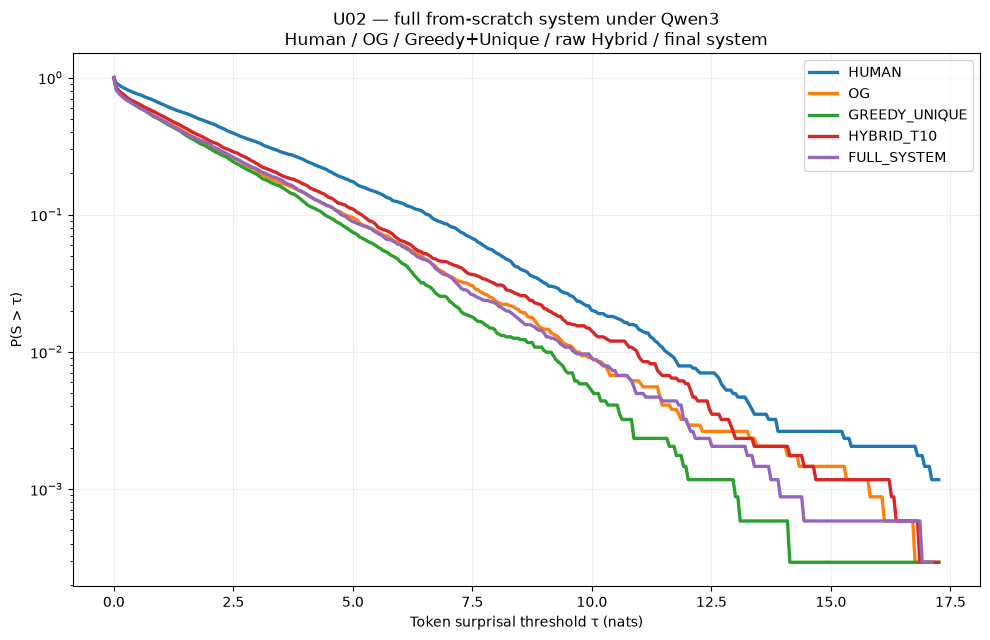


Scorer: GPT2 gpt2


Scoring FULL_SYSTEM / GPT2: 100%|███████████████████████████████████████████████████████████████████████| 20/20 [00:00<00:00, 96.20it/s]


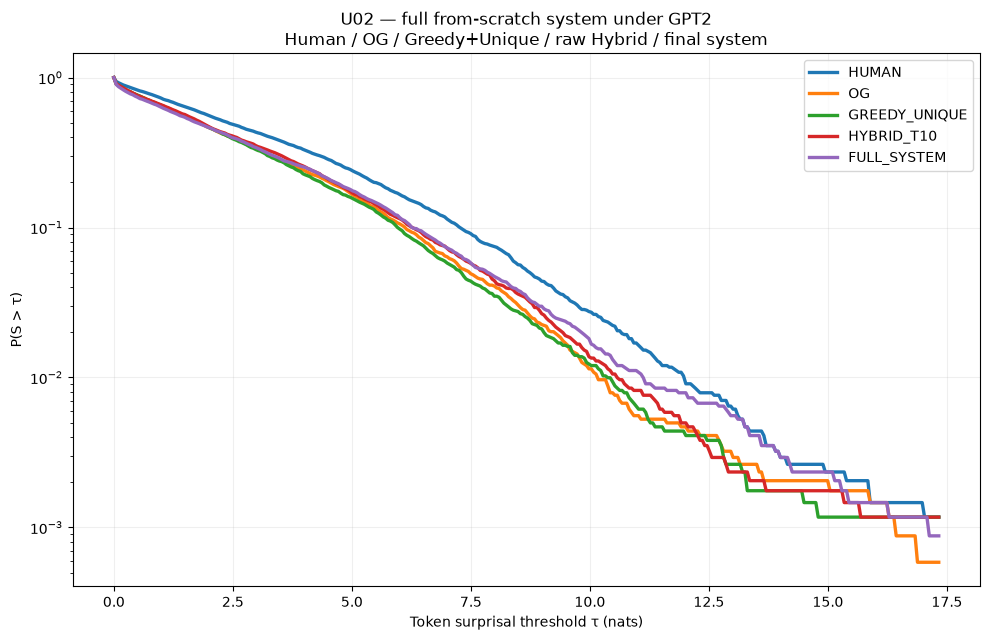


Scorer: SmolLM2 HuggingFaceTB/SmolLM2-360M


Scoring FULL_SYSTEM / SmolLM2: 100%|████████████████████████████████████████████████████████████████████| 20/20 [00:00<00:00, 45.79it/s]


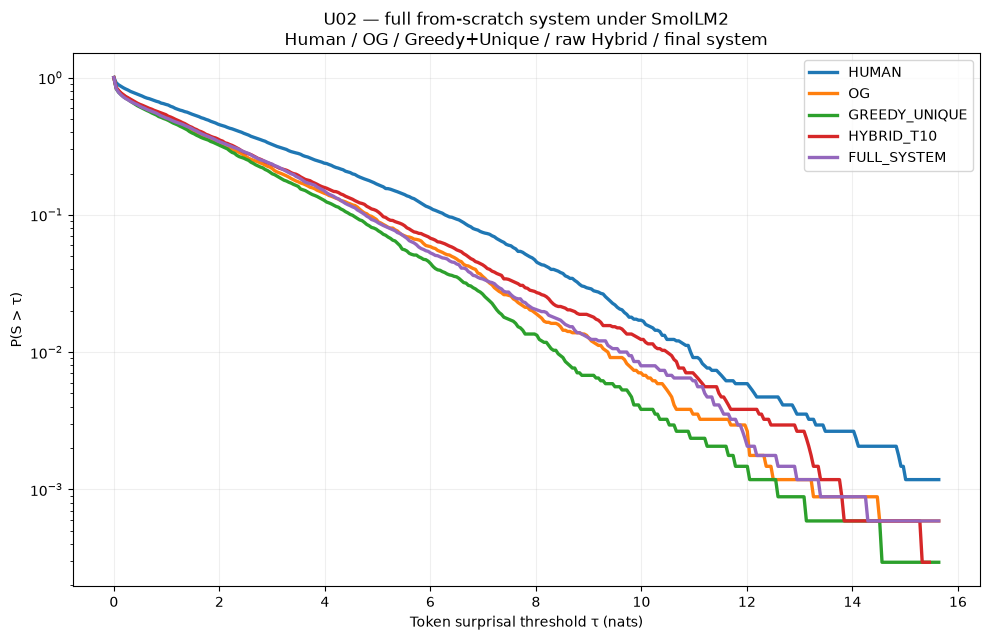


MEAN POST-WARMUP SURPRISAL


scorer,GPT2,Qwen3,SmolLM2
condition,,,
HUMAN,3.205569,2.643272,2.548970
OG,2.548546,1.791553,1.800987
GREEDY_UNIQUE,2.502744,1.656224,1.678193
HYBRID_T10,2.633755,1.964212,1.933959
FULL_SYSTEM,2.599082,1.776858,1.829635



P(S > 4):


scorer,GPT2,Qwen3,SmolLM2
condition,,,
HUMAN,0.329821,0.248683,0.237338
OG,0.239977,0.142188,0.142815
GREEDY_UNIQUE,0.226222,0.122879,0.126620
HYBRID_T10,0.256073,0.165594,0.158127
FULL_SYSTEM,0.253146,0.143944,0.148704



P(S > 6):


...


P(S > 10):


scorer,GPT2,Qwen3,SmolLM2
condition,,,
HUMAN,0.027510,0.020187,0.017079
OG,0.011414,0.009070,0.007067
GREEDY_UNIQUE,0.011999,0.005266,0.003828
HYBRID_T10,0.013755,0.014336,0.012367
FULL_SYSTEM,0.017852,0.008777,0.007951



PAIRED CASE-LEVEL COMPARISONS


,scorer,comparison,mean_delta,ci_low,ci_high,positive_case_fraction,median_delta
0,Qwen3,FULL_minus_GREEDY,0.122493,-0.071818,0.313670,0.65,0.118991
1,Qwen3,FULL_minus_RAW_HYBRID,-0.155766,-0.396851,0.053761,0.40,-0.072943
2,Qwen3,HUMAN_minus_FULL,0.886513,0.675315,1.112719,1.00,0.825557
3,GPT2,FULL_minus_GREEDY,0.105402,-0.056991,0.256678,0.60,0.132323
4,GPT2,FULL_minus_RAW_HYBRID,-0.021234,-0.204398,0.143778,0.65,0.053175
5,GPT2,HUMAN_minus_FULL,0.642307,0.454519,0.849142,0.90,0.627165
6,SmolLM2,FULL_minus_GREEDY,0.142570,-0.054465,0.332729,0.65,0.114758
7,SmolLM2,FULL_minus_RAW_HYBRID,-0.081922,-0.293899,0.104728,0.40,-0.037646
8,SmolLM2,HUMAN_minus_FULL,0.743089,0.535659,0.964020,0.90,0.697087



Saved final-system evaluation: ../results/causal/U02_hybrid_unique_sampling/full_system_from_scratch_v1/cross_scorer


In [41]:
# ============================================================
# U02 — FINAL from-scratch system: cross-scorer evaluation
#
# Reuses EXISTING cached losses for:
#   HUMAN
#   OG
#   GREEDY_UNIQUE
#   HYBRID_T10
#
# Scores ONLY:
#   FULL_SYSTEM = fs_gen
#
# Exact same protocol as original U02 evaluation:
#   scorers: Qwen3 / GPT2 / SmolLM2
#   scorer cap: 256 tokens
#   remove first ceil(20% of OG total scorer-token length)
#   equal common support within each matched case
#
# Produces:
#   - survival graph for each scorer
#   - mean/median/q90/q95/q99
#   - tail rates τ = 4,6,8,10
#   - paired FULL_SYSTEM - GREEDY
#   - paired FULL_SYSTEM - RAW HYBRID
# ============================================================

import gc
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM


# ------------------------------------------------------------
# 0. Exact frozen evaluation setup from original U02
# ------------------------------------------------------------

SCORERS = {
    "Qwen3":
        "Qwen/Qwen3-0.6B-Base",

    "GPT2":
        "gpt2",

    "SmolLM2":
        "HuggingFaceTB/SmolLM2-360M",
}

MAX_COMPARE_TOKENS = 256
POST_CUT_FRACTION = 0.20

OLD_CONDITIONS = [
    "HUMAN",
    "OG",
    "GREEDY_UNIQUE",
    "HYBRID_T10",
]

FULL_COND = "FULL_SYSTEM"

CONDITIONS = (
    OLD_CONDITIONS
    + [FULL_COND]
)


EVAL_DIR = (
    OUT
    / "cross_scorer"
)

EVAL_DIR.mkdir(
    exist_ok=True
)

FINAL_EVAL_DIR = (
    FS_OUT
    / "cross_scorer"
)

FINAL_EVAL_DIR.mkdir(
    exist_ok=True
)

FIG_DIR = (
    ROOT
    / "figures"
)

FIG_DIR.mkdir(
    exist_ok=True
)


assert "fs_gen" in globals()
assert len(fs_gen) == 20
assert fs_gen["case_id"].is_unique


# ------------------------------------------------------------
# 1. Free Llama generator
# ------------------------------------------------------------

for name in [
    "model",
    "tok",
    "past",
    "next_logits",
    "mask",
]:

    if name in globals():

        try:
            del globals()[name]
        except Exception:
            pass


gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()


device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

dtype = (
    torch.float16
    if device.type == "cuda"
    else torch.float32
)


# ------------------------------------------------------------
# 2. Exact scorer from original U02
# ------------------------------------------------------------

def score_text_final(
    text,
    tokenizer,
    scorer,
):

    ids_all = tokenizer(
        str(text),
        add_special_tokens=False,
    )[
        "input_ids"
    ]

    n_total = len(
        ids_all
    )

    ids = ids_all[
        :MAX_COMPARE_TOKENS
    ]


    if len(ids) < 2:

        return (
            n_total,
            np.array(
                [],
                dtype=np.float32,
            ),
        )


    x = torch.tensor(
        [ids],
        dtype=torch.long,
        device=device,
    )


    with torch.inference_mode():

        out = scorer(
            input_ids=x,
            use_cache=False,
        )

        logits = (
            out.logits[
                :,
                :-1,
                :
            ]
            .float()
        )

        targets = x[
            :,
            1:
        ]


        losses = F.cross_entropy(
            logits.reshape(
                -1,
                logits.shape[-1],
            ),
            targets.reshape(-1),
            reduction="none",
        )


    arr = (
        losses
        .detach()
        .cpu()
        .numpy()
        .astype(
            np.float32
        )
    )


    del x
    del out
    del logits
    del targets
    del losses


    return (
        n_total,
        arr,
    )


# ------------------------------------------------------------
# 3. Bootstrap helper
# ------------------------------------------------------------

def bootstrap_mean_ci(
    values,
    n_boot=10000,
    seed=20260918,
):

    values = np.asarray(
        values,
        dtype=float,
    )

    rng = np.random.default_rng(
        seed
    )

    n = len(
        values
    )

    boots = np.empty(
        n_boot,
        dtype=float,
    )


    for i in range(
        n_boot
    ):

        boots[i] = (
            rng.choice(
                values,
                size=n,
                replace=True,
            )
            .mean()
        )


    return (
        float(
            values.mean()
        ),

        float(
            np.quantile(
                boots,
                0.025,
            )
        ),

        float(
            np.quantile(
                boots,
                0.975,
            )
        ),
    )


# ------------------------------------------------------------
# 4. Final-system text lookup
# ------------------------------------------------------------

full_text_lookup = (
    fs_gen
    .assign(
        case_id=
            fs_gen[
                "case_id"
            ]
            .astype(str)
    )
    .set_index(
        "case_id"
    )[
        "generated_text"
    ]
    .to_dict()
)


case_ids = sorted(
    full_text_lookup.keys()
)

assert len(
    case_ids
) == 20


# ------------------------------------------------------------
# 5. Score ONLY FULL_SYSTEM under each scorer.
#
# Existing four-condition losses remain untouched.
# ------------------------------------------------------------

summary_rows = []
tail_rows = []
paired_rows = []

all_final_scored = {}


for (
    scorer_name,
    scorer_id,
) in SCORERS.items():

    print(
        "\n"
        + "=" * 80
    )

    print(
        "Scorer:",
        scorer_name,
        scorer_id,
    )

    print(
        "=" * 80
    )


    # --------------------------------------------------------
    # Load ORIGINAL U02 loss cache.
    # --------------------------------------------------------

    old_cache_path = (
        EVAL_DIR
        / f"{scorer_name}_losses.parquet"
    )

    assert old_cache_path.exists(), (
        "Missing original U02 scorer cache: "
        f"{old_cache_path}"
    )


    old_scored = pd.read_parquet(
        old_cache_path
    )

    old_scored[
        "case_id"
    ] = (
        old_scored[
            "case_id"
        ]
        .astype(str)
    )

    old_scored[
        "condition"
    ] = (
        old_scored[
            "condition"
        ]
        .astype(str)
    )


    # Only use the four original conditions.
    old_scored = old_scored.loc[
        old_scored[
            "condition"
        ].isin(
            OLD_CONDITIONS
        )
    ].copy()


    assert (
        old_scored[
            [
                "case_id",
                "condition",
            ]
        ]
        .drop_duplicates()
        .shape[0]
        == 80
    ), (
        scorer_name,
        old_scored.shape,
    )


    # --------------------------------------------------------
    # Separate cache for the final system.
    # Allows safe resume.
    # --------------------------------------------------------

    full_cache_path = (
        FINAL_EVAL_DIR
        / f"{scorer_name}_FULL_SYSTEM_losses.parquet"
    )


    if full_cache_path.exists():

        full_scored = pd.read_parquet(
            full_cache_path
        )

        full_scored[
            "case_id"
        ] = (
            full_scored[
                "case_id"
            ]
            .astype(str)
        )

    else:

        full_scored = pd.DataFrame(
            columns=[
                "case_id",
                "condition",
                "n_scorer_tokens",
                "losses",
            ]
        )


    done = set(
        full_scored[
            "case_id"
        ]
        .astype(str)
    )


    # --------------------------------------------------------
    # Load scorer model.
    # --------------------------------------------------------

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()


    stok = AutoTokenizer.from_pretrained(
        scorer_id,
        use_fast=True,
    )


    smodel = (
        AutoModelForCausalLM
        .from_pretrained(
            scorer_id,
            dtype=dtype,
            low_cpu_mem_usage=True,
        )
        .to(device)
        .eval()
    )


    # --------------------------------------------------------
    # Score the 20 final-system outputs.
    # --------------------------------------------------------

    for cid in tqdm(
        case_ids,
        desc=f"Scoring FULL_SYSTEM / {scorer_name}",
    ):

        if cid in done:

            continue


        n_total, losses = (
            score_text_final(
                full_text_lookup[
                    cid
                ],
                stok,
                smodel,
            )
        )


        row = pd.DataFrame(
            [
                {
                    "case_id":
                        cid,

                    "condition":
                        FULL_COND,

                    "n_scorer_tokens":
                        n_total,

                    "losses":
                        losses.tolist(),
                }
            ]
        )


        full_scored = pd.concat(
            [
                full_scored,
                row,
            ],
            ignore_index=True,
        )


        full_scored.to_parquet(
            full_cache_path,
            index=False,
        )

        done.add(
            cid
        )


    assert len(
        full_scored
    ) == 20


    # --------------------------------------------------------
    # Combine cached old losses + NEW final-system losses.
    # --------------------------------------------------------

    scored5 = pd.concat(
        [
            old_scored,
            full_scored,
        ],
        ignore_index=True,
    )


    assert (
        scored5[
            [
                "case_id",
                "condition",
            ]
        ]
        .drop_duplicates()
        .shape[0]
        == 100
    )


    all_final_scored[
        scorer_name
    ] = scored5


    # --------------------------------------------------------
    # Loss + length lookup
    # --------------------------------------------------------

    loss_lookup = {
        (
            str(r.case_id),
            str(r.condition),
        ):
            np.asarray(
                r.losses,
                dtype=float,
            )

        for r in scored5.itertuples(
            index=False
        )
    }


    length_lookup = {
        (
            str(r.case_id),
            str(r.condition),
        ):
            int(
                r.n_scorer_tokens
            )

        for r in scored5.itertuples(
            index=False
        )
    }


    # --------------------------------------------------------
    # EXACT matched-support protocol.
    #
    # Common support now includes FULL_SYSTEM as the fifth
    # condition, so every condition is compared over precisely
    # the same scorer-token positions within each case.
    # --------------------------------------------------------

    suffixes = {
        c: []
        for c in CONDITIONS
    }

    case_means = []


    for cid in case_ids:

        per_case = {
            c:
                loss_lookup[
                    (
                        cid,
                        c,
                    )
                ]

            for c in CONDITIONS
        }


        m = min(
            len(v)
            for v in per_case.values()
        )


        og_total = (
            length_lookup[
                (
                    cid,
                    "OG",
                )
            ]
        )


        cut = int(
            np.ceil(
                POST_CUT_FRACTION
                * og_total
            )
        )


        assert cut < m, (
            scorer_name,
            cid,
            cut,
            m,
        )


        case_row = {
            "scorer":
                scorer_name,

            "case_id":
                cid,

            "common_support":
                m,

            "og_cut":
                cut,
        }


        for c in CONDITIONS:

            suffix = (
                per_case[c][
                    cut:m
                ]
            )


            suffixes[c].append(
                suffix
            )


            case_row[c] = float(
                suffix.mean()
            )


        case_means.append(
            case_row
        )


    case_means = pd.DataFrame(
        case_means
    )


    assert len(
        case_means
    ) == 20


    # --------------------------------------------------------
    # Pool post-warmup matched tokens.
    # --------------------------------------------------------

    agg = {
        c:
            np.concatenate(
                suffixes[c]
            )

        for c in CONDITIONS
    }


    # --------------------------------------------------------
    # Summary statistics
    # --------------------------------------------------------

    for c in CONDITIONS:

        x = agg[c]


        summary_rows.append({
            "scorer":
                scorer_name,

            "condition":
                c,

            "n_tokens":
                len(x),

            "mean":
                float(
                    x.mean()
                ),

            "median":
                float(
                    np.median(
                        x
                    )
                ),

            "q90":
                float(
                    np.quantile(
                        x,
                        .90,
                    )
                ),

            "q95":
                float(
                    np.quantile(
                        x,
                        .95,
                    )
                ),

            "q99":
                float(
                    np.quantile(
                        x,
                        .99,
                    )
                ),
        })


        for tau in [
            4,
            6,
            8,
            10,
        ]:

            tail_rows.append({
                "scorer":
                    scorer_name,

                "condition":
                    c,

                "tau":
                    tau,

                "P_S_gt_tau":
                    float(
                        np.mean(
                            x > tau
                        )
                    ),
            })


    # --------------------------------------------------------
    # Paired case-level comparisons
    # --------------------------------------------------------

    comparisons = {
        "FULL_minus_GREEDY":
            (
                case_means[
                    FULL_COND
                ]
                -
                case_means[
                    "GREEDY_UNIQUE"
                ]
            ),

        "FULL_minus_RAW_HYBRID":
            (
                case_means[
                    FULL_COND
                ]
                -
                case_means[
                    "HYBRID_T10"
                ]
            ),

        "HUMAN_minus_FULL":
            (
                case_means[
                    "HUMAN"
                ]
                -
                case_means[
                    FULL_COND
                ]
            ),
    }


    for (
        comparison,
        delta_series,
    ) in comparisons.items():

        delta = (
            delta_series
            .to_numpy(
                dtype=float
            )
        )


        mean_delta, ci_low, ci_high = (
            bootstrap_mean_ci(
                delta
            )
        )


        paired_rows.append({
            "scorer":
                scorer_name,

            "comparison":
                comparison,

            "mean_delta":
                mean_delta,

            "ci_low":
                ci_low,

            "ci_high":
                ci_high,

            "positive_case_fraction":
                float(
                    np.mean(
                        delta > 0
                    )
                ),

            "median_delta":
                float(
                    np.median(
                        delta
                    )
                ),
        })


    # --------------------------------------------------------
    # Full survival curve
    # --------------------------------------------------------

    xmax = min(
        20.0,
        max(
            np.quantile(
                x,
                .999,
            )
            for x in agg.values()
        ),
    )


    taus = np.linspace(
        0,
        xmax,
        350,
    )


    fig, ax = plt.subplots(
        figsize=(
            10,
            6.5,
        )
    )


    for c in CONDITIONS:

        survival = np.array(
            [
                np.mean(
                    agg[c]
                    > tau
                )

                for tau in taus
            ]
        )


        keep = (
            survival > 0
        )


        ax.plot(
            taus[
                keep
            ],
            survival[
                keep
            ],
            linewidth=2.4,
            label=c,
        )


    ax.set_yscale(
        "log"
    )

    ax.set_xlabel(
        "Token surprisal threshold τ (nats)"
    )

    ax.set_ylabel(
        "P(S > τ)"
    )


    ax.set_title(
        f"U02 — full from-scratch system under {scorer_name}\n"
        "Human / OG / Greedy+Unique / raw Hybrid / final system"
    )


    ax.grid(
        alpha=.2
    )

    ax.legend()


    fig.tight_layout()


    fig.savefig(
        FINAL_EVAL_DIR
        / f"full_system_survival_{scorer_name}.png",
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        FINAL_EVAL_DIR
        / f"full_system_survival_{scorer_name}.pdf",
        bbox_inches="tight",
    )


    plt.show()


    # --------------------------------------------------------
    # Cleanup scorer
    # --------------------------------------------------------

    del smodel
    del stok

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()


# ------------------------------------------------------------
# 6. Final cross-scorer tables
# ------------------------------------------------------------

full_cross_summary = pd.DataFrame(
    summary_rows
)

full_cross_tail = pd.DataFrame(
    tail_rows
)

full_cross_paired = pd.DataFrame(
    paired_rows
)


full_cross_summary.to_csv(
    FINAL_EVAL_DIR
    / "summary.csv",
    index=False,
)

full_cross_tail.to_csv(
    FINAL_EVAL_DIR
    / "tail_rates.csv",
    index=False,
)

full_cross_paired.to_csv(
    FINAL_EVAL_DIR
    / "paired_comparisons.csv",
    index=False,
)


ORDER = [
    "HUMAN",
    "OG",
    "GREEDY_UNIQUE",
    "HYBRID_T10",
    "FULL_SYSTEM",
]


print(
    "\n"
    + "=" * 80
)

print(
    "MEAN POST-WARMUP SURPRISAL"
)

print(
    "=" * 80
)


display(
    full_cross_summary
    .pivot(
        index="condition",
        columns="scorer",
        values="mean",
    )
    .reindex(
        ORDER
    )
)


for tau in [
    4,
    6,
    8,
    10,
]:

    print(
        f"\nP(S > {tau}):"
    )


    display(
        full_cross_tail.loc[
            full_cross_tail[
                "tau"
            ].eq(
                tau
            )
        ]
        .pivot(
            index="condition",
            columns="scorer",
            values="P_S_gt_tau",
        )
        .reindex(
            ORDER
        )
    )


print(
    "\n"
    + "=" * 80
)

print(
    "PAIRED CASE-LEVEL COMPARISONS"
)

print(
    "=" * 80
)


display(
    full_cross_paired
)


print(
    "\nSaved final-system evaluation:",
    FINAL_EVAL_DIR,
)

ROOT: ..
U02 : ../results/causal/U02_hybrid_unique_sampling


condition
FULL_SYSTEM    20
HUMAN          20
OG             20
Name: case_id, dtype: int64


Plotting cases:
['gate_0016', 'gate_0017', 'gate_0039', 'gate_0046', 'gate_0051', 'gate_0062', 'gate_0070', 'gate_0075', 'gate_0078', 'gate_0090']


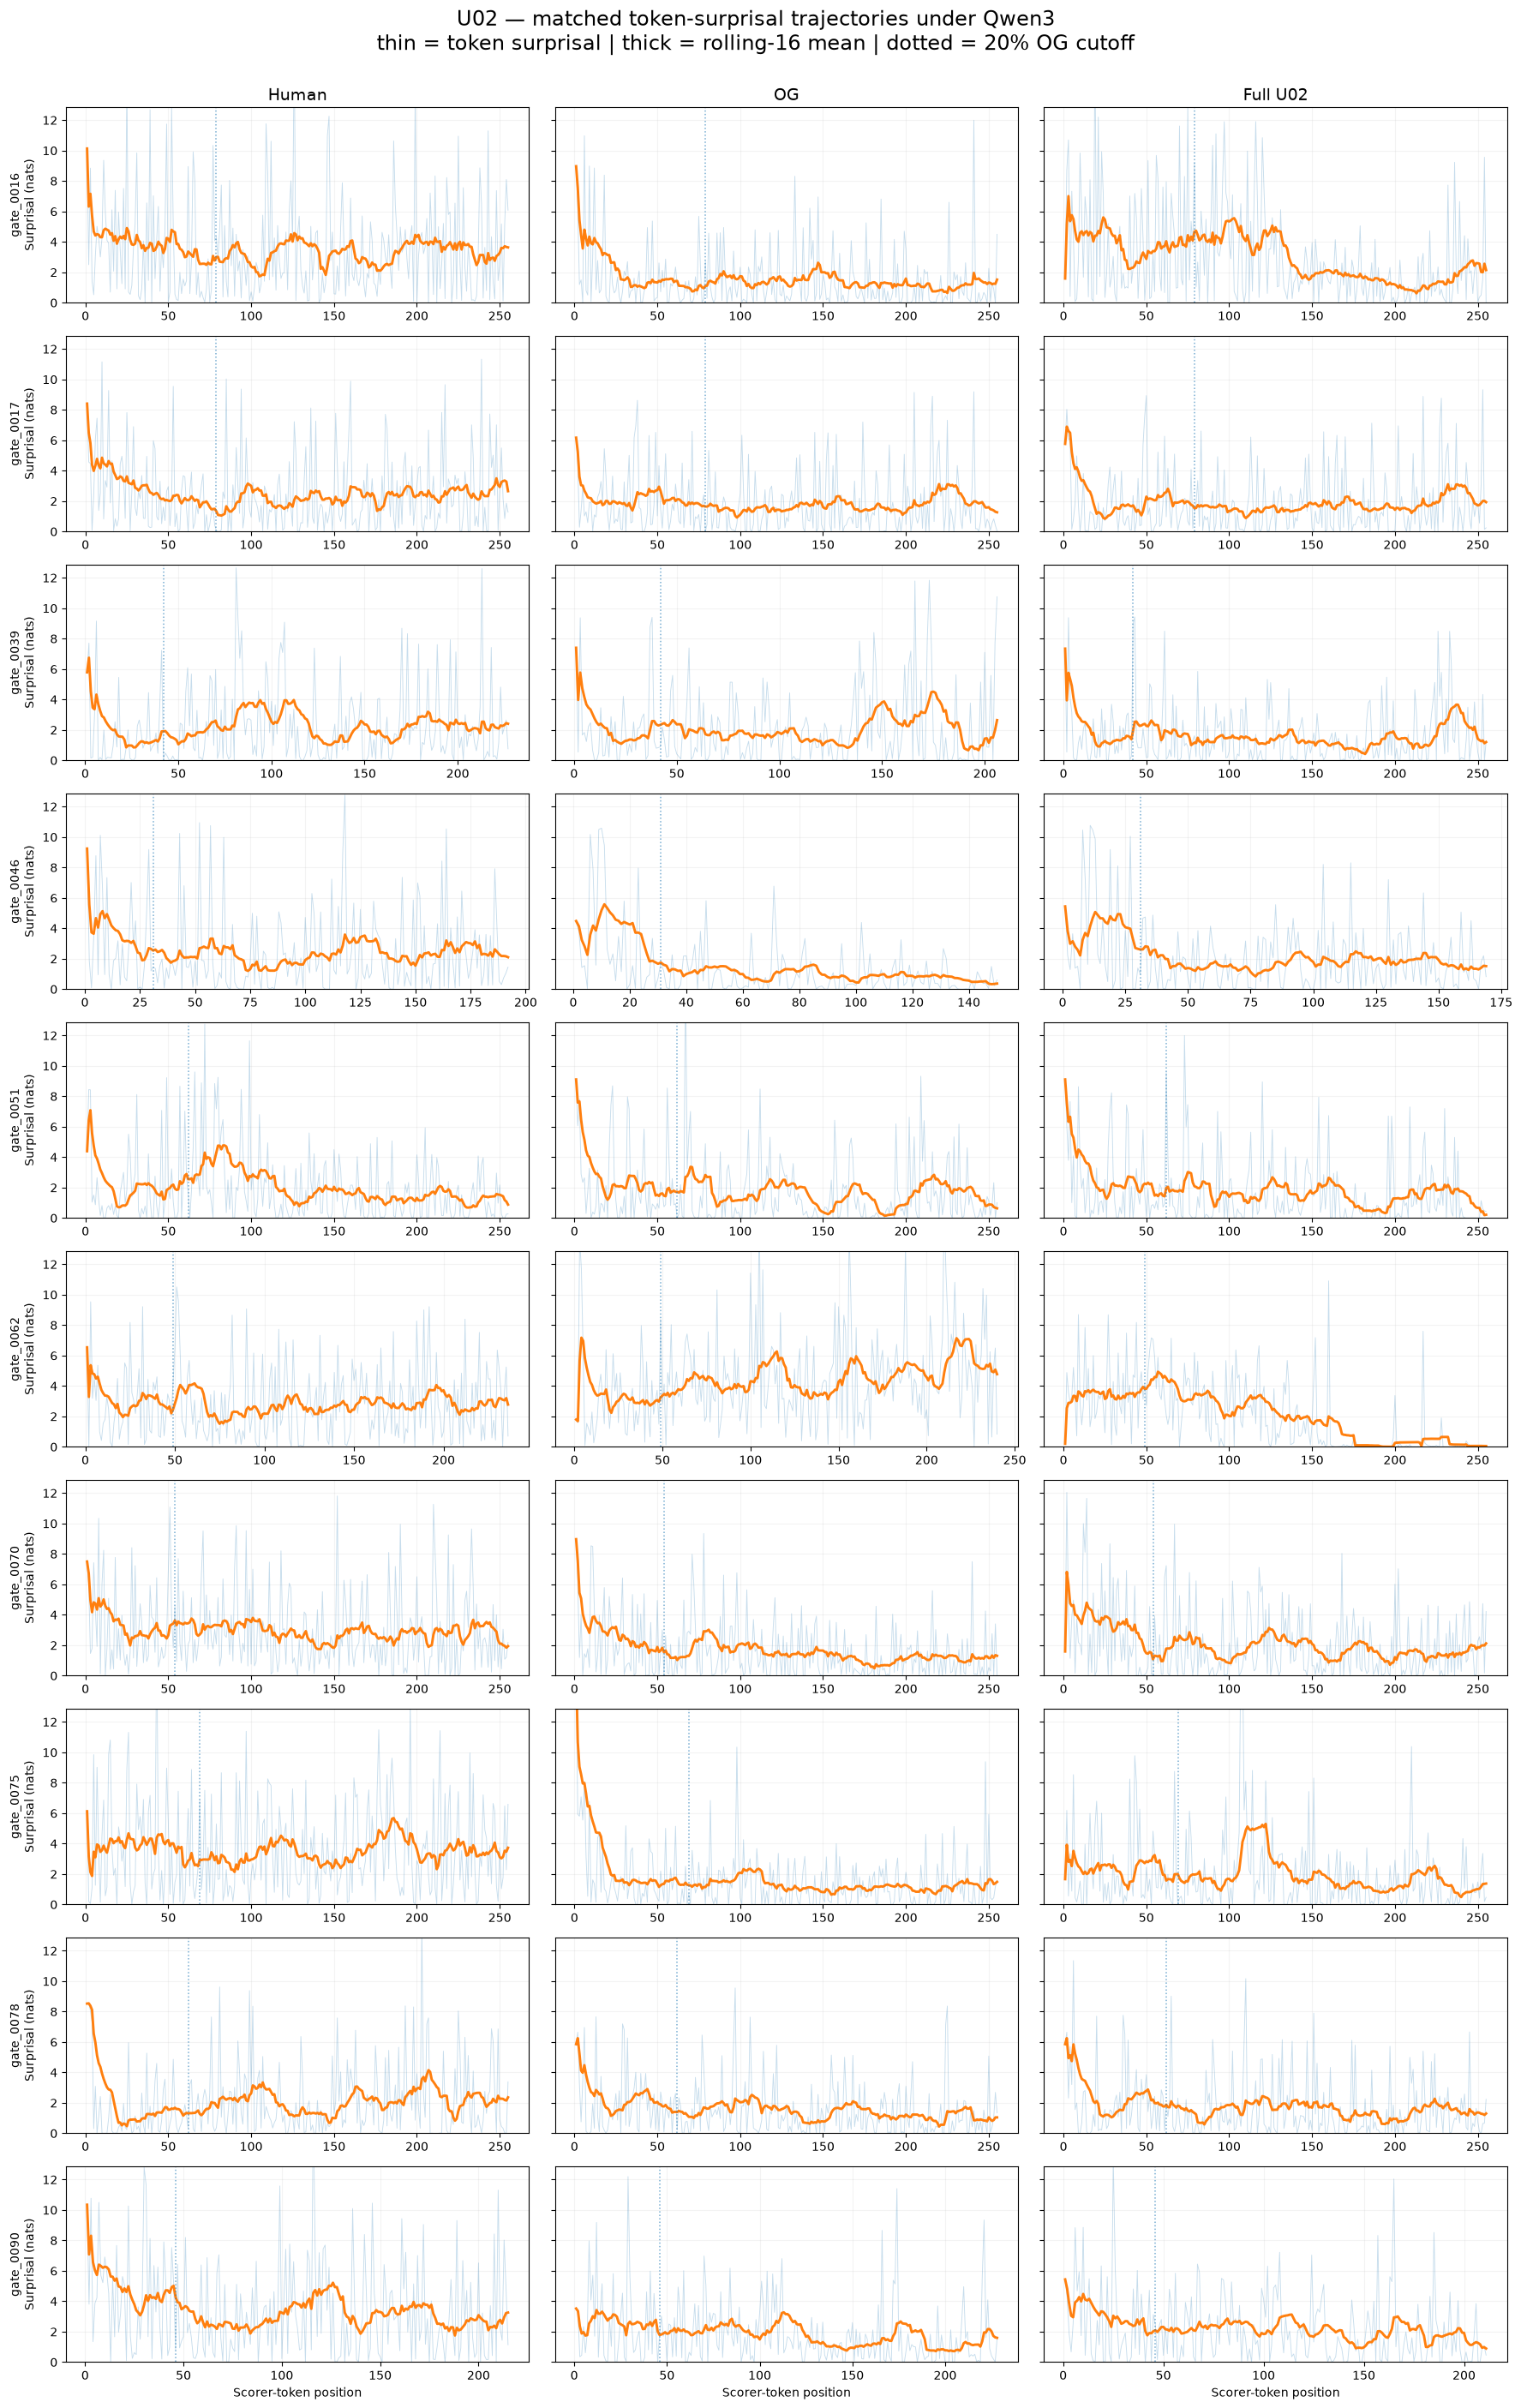

In [1]:
# ============================================================
# U02 — self-contained matched surprisal trajectories
#
# Safe to run after a kernel restart.
#
# 10 matched cases × 3 columns:
#   HUMAN | OG | FULL U02
#
# thin  = token-level surprisal
# thick = rolling-16 mean
# dotted vertical line = old 20% OG evaluation cutoff
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 0. Recover reproduction root from disk
# ------------------------------------------------------------

ROOT_CANDIDATES = [
    Path.cwd().resolve(),
    *Path.cwd().resolve().parents,

    Path.home()
    / "Downloads"
    / "TemporalContextResearch"
    / "reproduction",
]


ROOT = next(
    (
        p
        for p in ROOT_CANDIDATES
        if (
            p
            / "results"
            / "causal"
            / "U02_hybrid_unique_sampling"
        ).exists()
    ),
    None,
)

assert ROOT is not None, (
    "Could not locate reproduction root."
)


OUT = (
    ROOT
    / "results"
    / "causal"
    / "U02_hybrid_unique_sampling"
)

FS_OUT = (
    OUT
    / "full_system_from_scratch_v1"
)


print("ROOT:", ROOT)
print("U02 :", OUT)


# ------------------------------------------------------------
# 1. Load existing Qwen3 scorer caches
# ------------------------------------------------------------

SCORER_NAME = "Qwen3"


OLD_CACHE = (
    OUT
    / "cross_scorer"
    / f"{SCORER_NAME}_losses.parquet"
)

FULL_CACHE = (
    FS_OUT
    / "cross_scorer"
    / f"{SCORER_NAME}_FULL_SYSTEM_losses.parquet"
)


assert OLD_CACHE.exists(), OLD_CACHE
assert FULL_CACHE.exists(), FULL_CACHE


old = pd.read_parquet(
    OLD_CACHE
)

full = pd.read_parquet(
    FULL_CACHE
)


old["case_id"] = (
    old["case_id"]
    .astype(str)
)

old["condition"] = (
    old["condition"]
    .astype(str)
)

full["case_id"] = (
    full["case_id"]
    .astype(str)
)


# FULL cache contains only the new final-system arm.
full["condition"] = "FULL_SYSTEM"


# ------------------------------------------------------------
# 2. Keep exactly HUMAN / OG / FULL_SYSTEM
# ------------------------------------------------------------

old = old.loc[
    old["condition"].isin(
        [
            "HUMAN",
            "OG",
        ]
    )
].copy()


traj = pd.concat(
    [
        old,
        full,
    ],
    ignore_index=True,
)


CONDITIONS = [
    "HUMAN",
    "OG",
    "FULL_SYSTEM",
]


assert set(
    CONDITIONS
) <= set(
    traj["condition"].unique()
)


counts_by_condition = (
    traj.groupby(
        "condition"
    )[
        "case_id"
    ]
    .nunique()
)

display(
    counts_by_condition
)

assert all(
    counts_by_condition.loc[
        CONDITIONS
    ]
    == 20
)


# ------------------------------------------------------------
# 3. Normalize stored loss arrays
# ------------------------------------------------------------

def as_array(x):

    return np.asarray(
        x,
        dtype=float,
    ).reshape(-1)


loss_lookup = {
    (
        str(r.case_id),
        str(r.condition),
    ):
        as_array(
            r.losses
        )

    for r in traj.itertuples(
        index=False
    )
}


length_lookup = {
    (
        str(r.case_id),
        str(r.condition),
    ):
        int(
            r.n_scorer_tokens
        )

    for r in traj.itertuples(
        index=False
    )
}


# ------------------------------------------------------------
# 4. Deterministically choose 10 of the 20
#
# Change seed if you want another matched set.
# ------------------------------------------------------------

all_cases = sorted(
    set(
        full["case_id"]
    )
)

assert len(
    all_cases
) == 20


PLOT_SEED = 20260918

rng = np.random.default_rng(
    PLOT_SEED
)


PLOT_CASES = sorted(
    rng.choice(
        all_cases,
        size=10,
        replace=False,
    )
    .tolist()
)


print(
    "\nPlotting cases:"
)

print(
    PLOT_CASES
)


# ------------------------------------------------------------
# 5. Rolling trajectory
# ------------------------------------------------------------

ROLL = 16


def rolling_mean(
    x,
    window=ROLL,
):

    return (
        pd.Series(
            x
        )
        .rolling(
            window=window,
            min_periods=1,
        )
        .mean()
        .to_numpy()
    )


# ------------------------------------------------------------
# 6. Shared y-axis
#
# Avoid one isolated freak token flattening all 30 panels.
# ------------------------------------------------------------

all_values = np.concatenate(
    [
        loss_lookup[
            (
                cid,
                cond,
            )
        ]

        for cid in PLOT_CASES

        for cond in CONDITIONS
    ]
)


YMAX = max(
    8.0,
    float(
        np.quantile(
            all_values,
            0.9975,
        )
    ),
)


# ------------------------------------------------------------
# 7. Plot
# ------------------------------------------------------------

TITLE = {
    "HUMAN":
        "Human",

    "OG":
        "OG",

    "FULL_SYSTEM":
        "Full U02",
}


fig, axes = plt.subplots(
    nrows=10,
    ncols=3,
    figsize=(
        18,
        28,
    ),
    sharey=True,
)


for row_i, cid in enumerate(
    PLOT_CASES
):

    # Historical U02 evaluation cutoff:
    # ceil(20% of TOTAL OG scorer-token length)
    og_total = length_lookup[
        (
            cid,
            "OG",
        )
    ]

    cut = int(
        np.ceil(
            0.20
            * og_total
        )
    )


    for col_i, cond in enumerate(
        CONDITIONS
    ):

        ax = axes[
            row_i,
            col_i
        ]


        S = loss_lookup[
            (
                cid,
                cond,
            )
        ]


        x = np.arange(
            1,
            len(S) + 1,
        )


        smooth = rolling_mean(
            S
        )


        # Raw token surprisal.
        ax.plot(
            x,
            S,
            linewidth=0.65,
            alpha=0.25,
        )


        # Rolling-16 mean.
        ax.plot(
            x,
            smooth,
            linewidth=2.1,
        )


        # Old evaluation warmup boundary.
        ax.axvline(
            cut,
            linestyle=":",
            linewidth=1.1,
            alpha=0.6,
        )


        ax.set_ylim(
            0,
            YMAX,
        )


        ax.grid(
            alpha=0.15,
        )


        if row_i == 0:

            ax.set_title(
                TITLE[
                    cond
                ],
                fontsize=14,
            )


        if col_i == 0:

            ax.set_ylabel(
                f"{cid}\nSurprisal (nats)"
            )


        if row_i == len(
            PLOT_CASES
        ) - 1:

            ax.set_xlabel(
                "Scorer-token position"
            )


fig.suptitle(
    f"U02 — matched token-surprisal trajectories under {SCORER_NAME}\n"
    "thin = token surprisal | thick = rolling-16 mean | dotted = 20% OG cutoff",
    fontsize=17,
    y=1.002,
)


fig.tight_layout()

plt.show()

ROOT: ..
U02 : ../results/causal/U02_hybrid_unique_sampling

HIGH-SURPRISAL EVENT PROCESS

τ = 4


,,event_rate,mean_inter_event_gap,longest_drought,early_rate,middle_rate,late_rate,late_minus_early
condition,scorer,,,,,,,
FULL_SYSTEM,GPT2,0.2546,4.1938,18.80,0.2984,0.2434,0.2219,-0.0765
HUMAN,GPT2,0.3365,3.1030,11.20,0.3494,0.3293,0.3307,-0.0187
OG,GPT2,0.2411,4.8949,16.20,0.2404,0.2358,0.2473,0.0068
FULL_SYSTEM,Qwen3,0.1402,8.5660,33.35,0.1791,0.1291,0.1122,-0.0669
HUMAN,Qwen3,0.2509,4.1745,16.50,0.2523,0.2565,0.2434,-0.0090
OG,Qwen3,0.1395,10.7585,34.50,0.1332,0.1327,0.1530,0.0198
FULL_SYSTEM,SmolLM2,0.1458,8.4036,30.95,0.1750,0.1404,0.1220,-0.0530
HUMAN,SmolLM2,0.2415,4.4376,14.70,0.2488,0.2398,0.2357,-0.0131
OG,SmolLM2,0.1405,9.2493,30.90,0.1490,0.1211,0.1516,0.0026



τ = 6


,,event_rate,mean_inter_event_gap,longest_drought,early_rate,middle_rate,late_rate,late_minus_early
condition,scorer,,,,,,,
FULL_SYSTEM,GPT2,0.1155,9.6354,39.50,0.1387,0.1183,0.0898,-0.0489
HUMAN,GPT2,0.1731,6.4929,23.20,0.1823,0.1584,0.1786,-0.0037
OG,GPT2,0.1080,13.5090,38.50,0.1085,0.0946,0.1210,0.0125
FULL_SYSTEM,Qwen3,0.0578,23.3546,64.15,0.0788,0.0471,0.0471,-0.0316
HUMAN,Qwen3,0.1239,8.3941,36.05,0.1254,0.1182,0.1278,0.0024
OG,Qwen3,0.0604,28.0153,69.55,0.0533,0.0517,0.0764,0.0230
FULL_SYSTEM,SmolLM2,0.0509,22.0347,66.25,0.0635,0.0429,0.0463,-0.0172
HUMAN,SmolLM2,0.1143,10.8550,34.60,0.1152,0.1074,0.1205,0.0052
OG,SmolLM2,0.0585,21.8515,66.45,0.0582,0.0425,0.0750,0.0168



τ = 8


,,event_rate,mean_inter_event_gap,longest_drought,early_rate,middle_rate,late_rate,late_minus_early
condition,scorer,,,,,,,
FULL_SYSTEM,GPT2,0.0461,16.7769,69.10,0.0560,0.0475,0.0349,-0.0210
HUMAN,GPT2,0.0794,13.9094,48.50,0.0888,0.0650,0.0845,-0.0043
OG,GPT2,0.0419,29.3434,91.65,0.0331,0.0405,0.0520,0.0189
FULL_SYSTEM,Qwen3,0.0212,36.8497,101.50,0.0287,0.0149,0.0199,-0.0088
HUMAN,Qwen3,0.0537,17.6295,59.15,0.0555,0.0440,0.0617,0.0062
OG,Qwen3,0.0232,51.2325,96.85,0.0206,0.0207,0.0283,0.0076
FULL_SYSTEM,SmolLM2,0.0201,34.4067,106.95,0.0243,0.0142,0.0220,-0.0022
HUMAN,SmolLM2,0.0466,27.8245,67.75,0.0429,0.0368,0.0602,0.0174
OG,SmolLM2,0.0196,43.2360,101.85,0.0180,0.0143,0.0267,0.0087


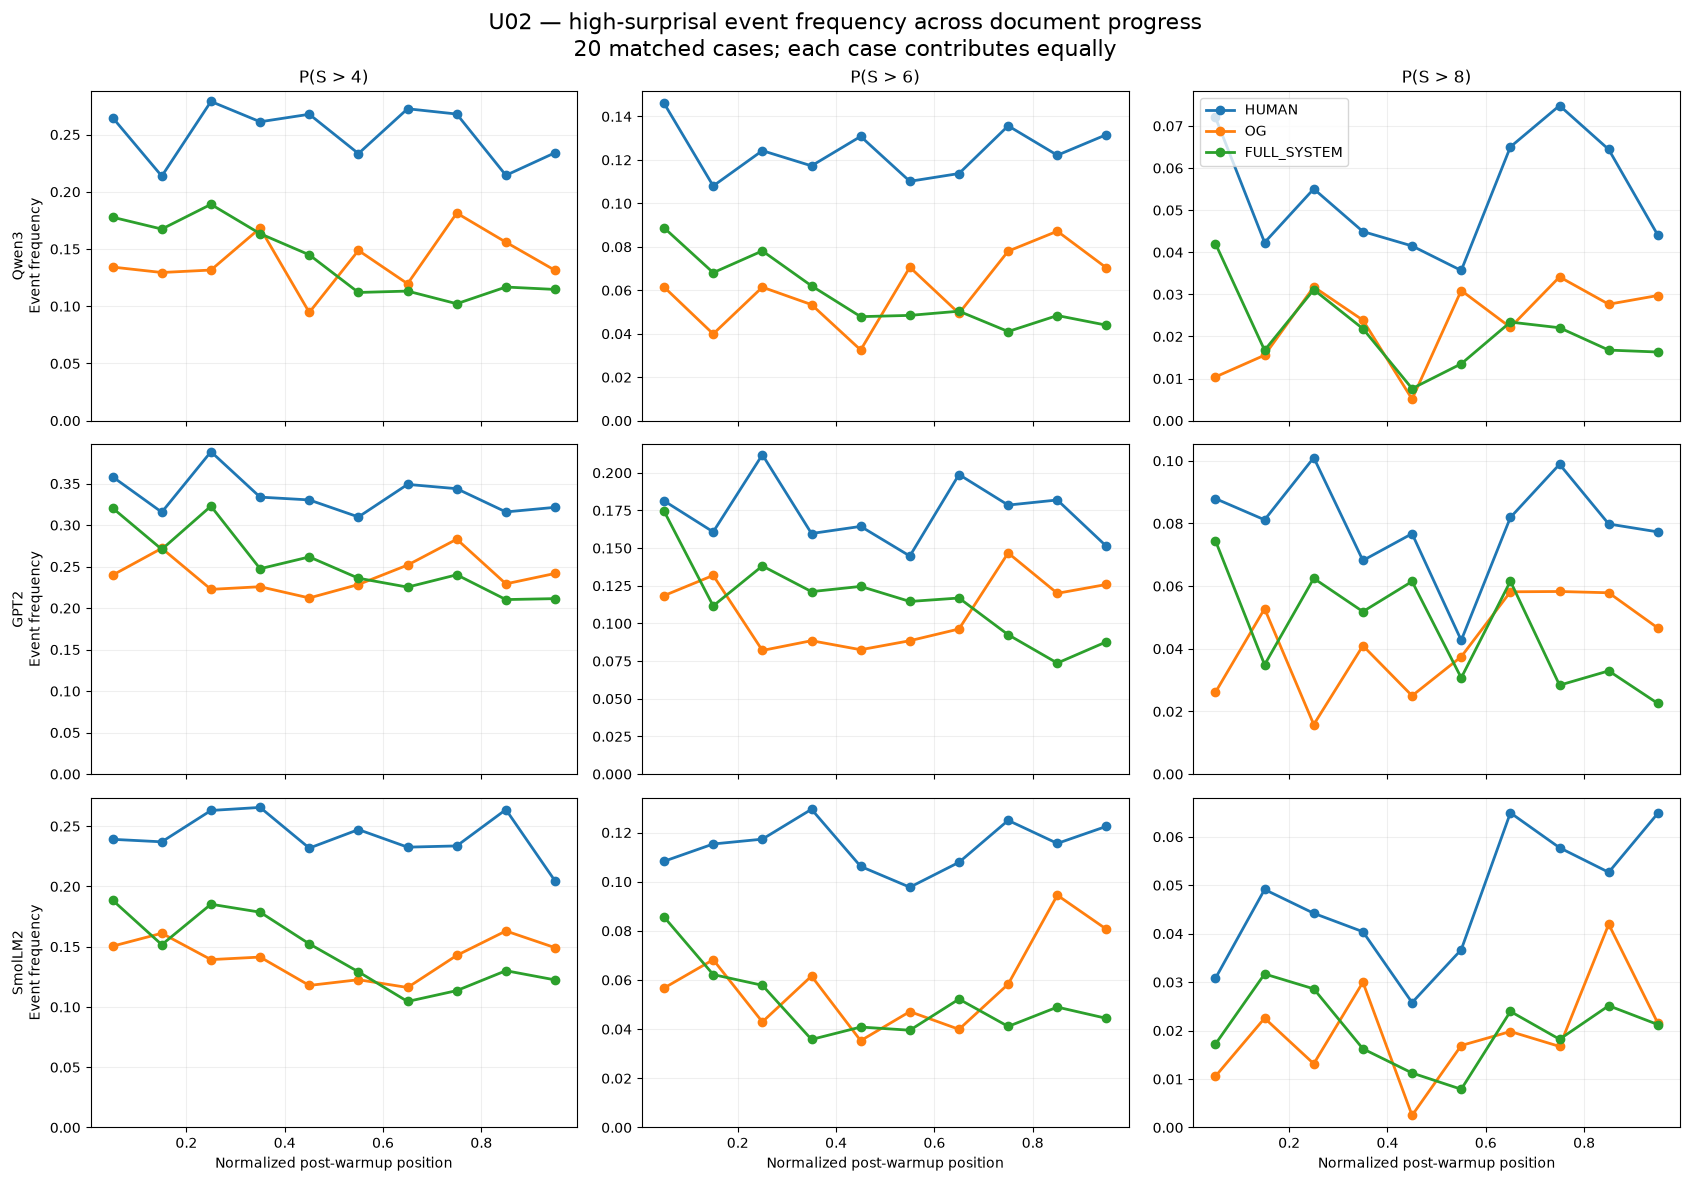

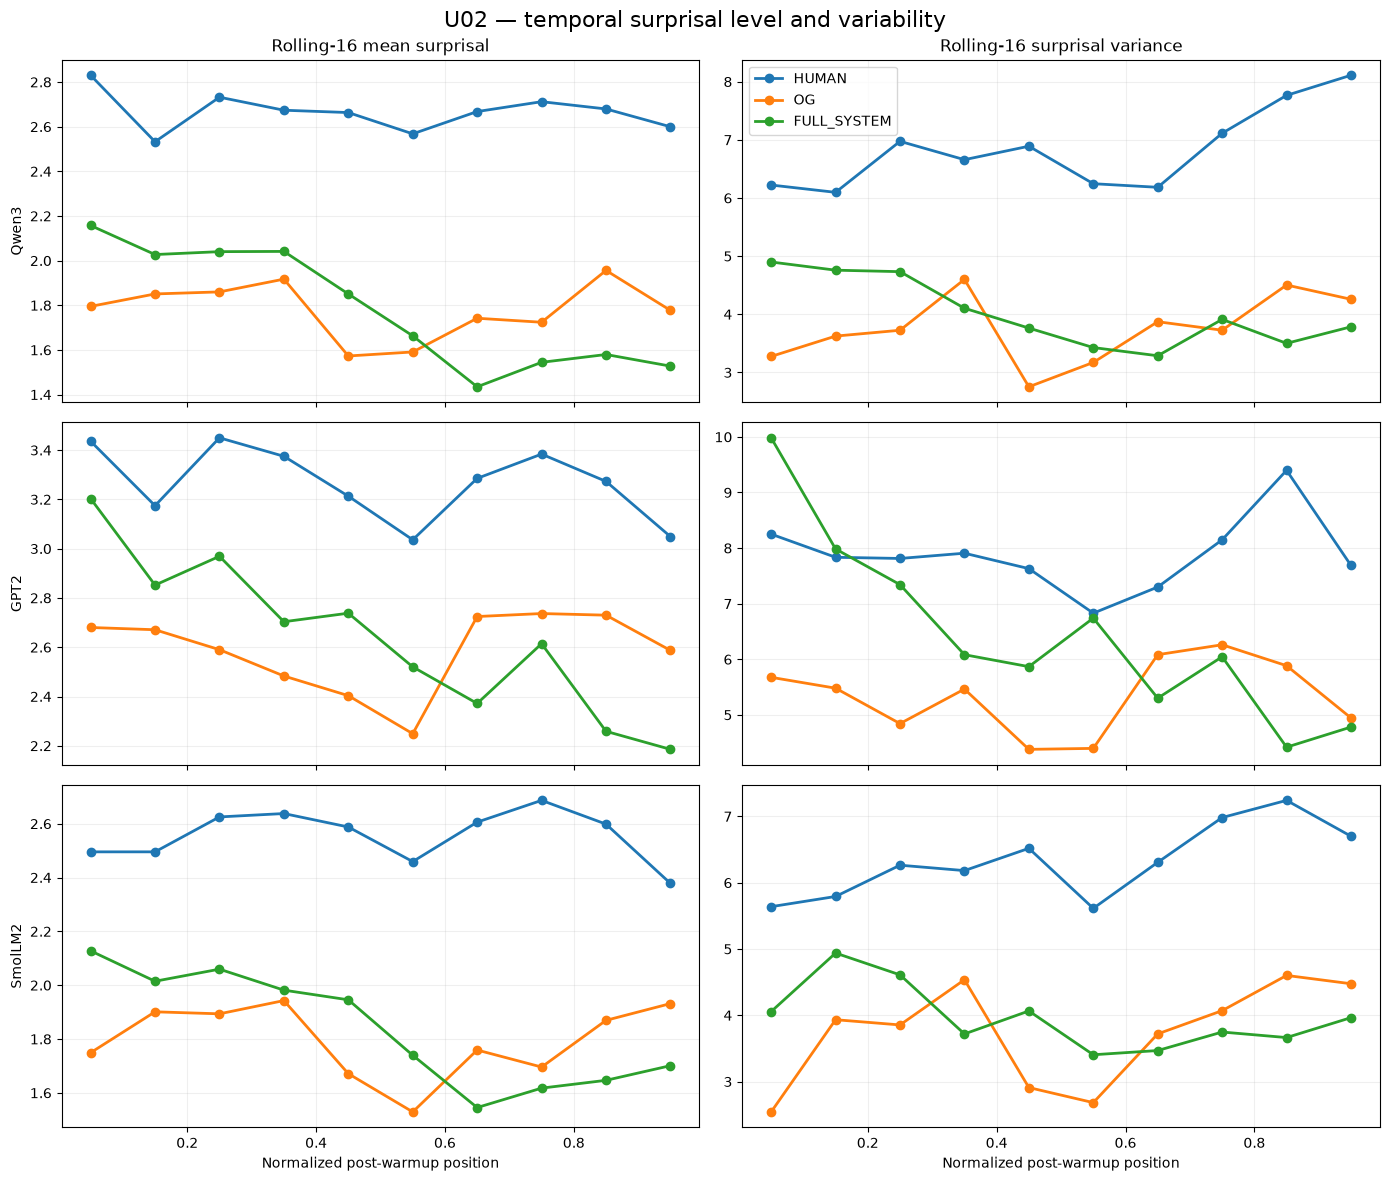

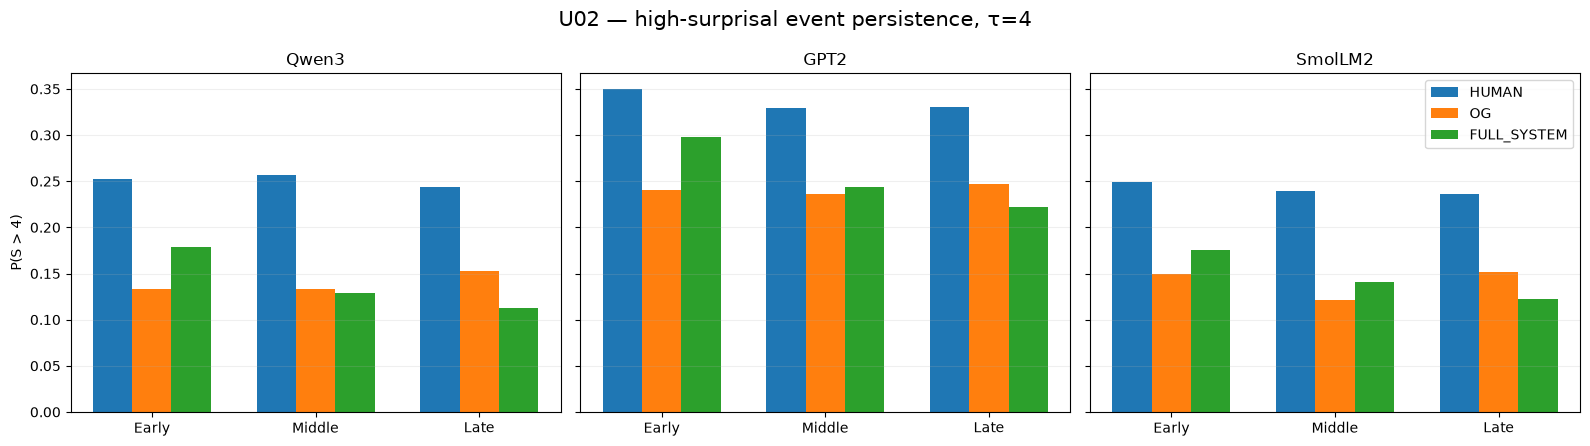

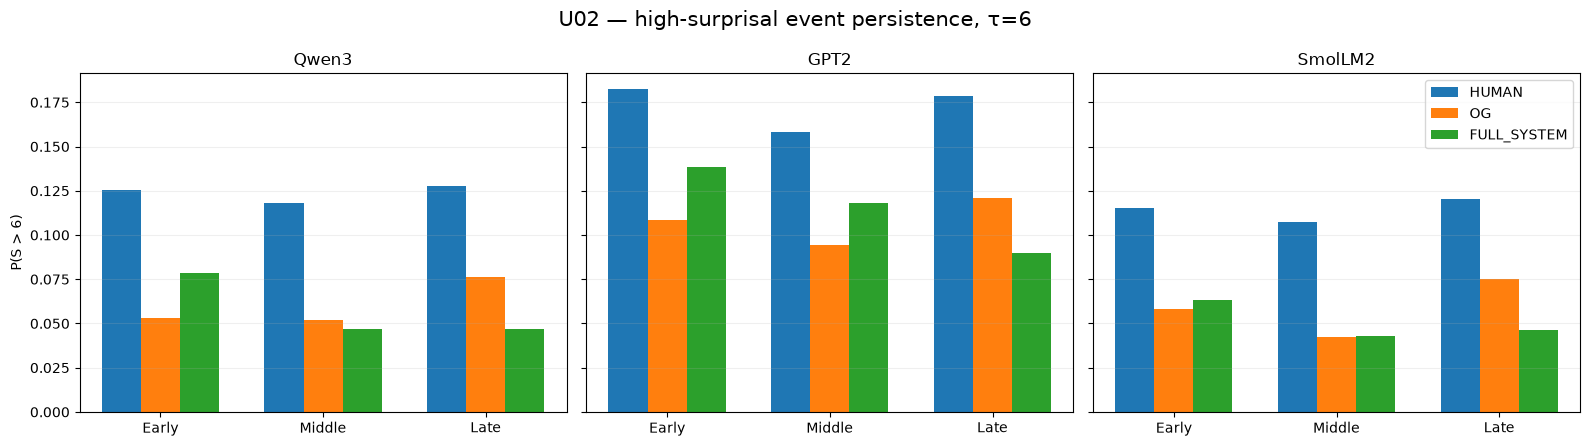

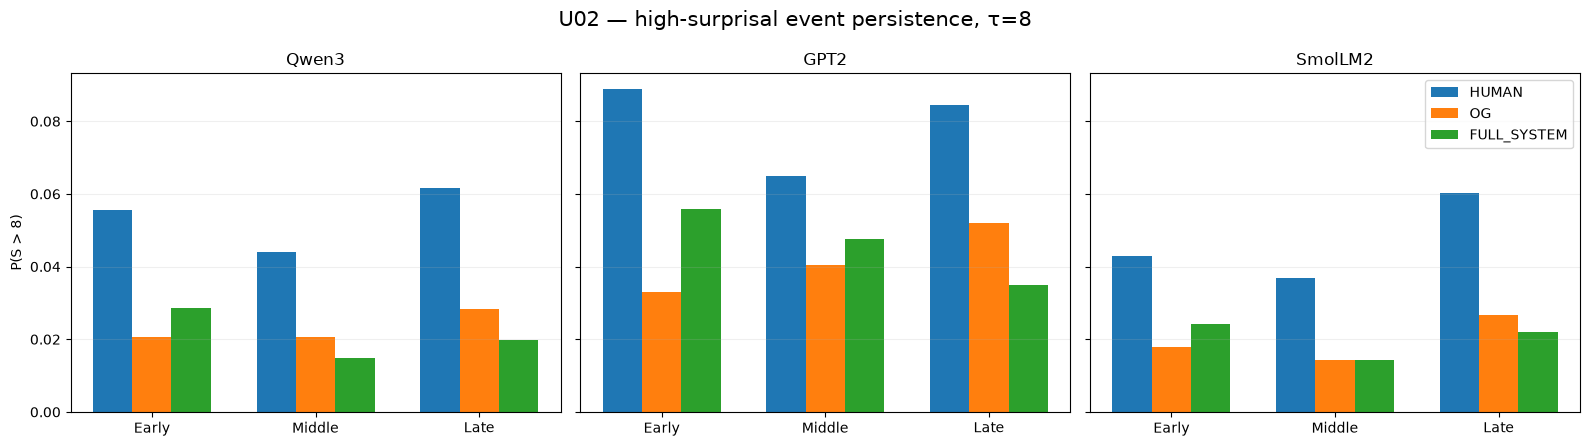


TEMPORAL EVENT-RATE DECAY
negative late_minus_early = high-surprisal events fade with position


,scorer,condition,tau,early_rate,late_rate,late_minus_early
0,GPT2,FULL_SYSTEM,4.0,0.2984,0.2219,-0.0765
3,GPT2,HUMAN,4.0,0.3494,0.3307,-0.0187
6,GPT2,OG,4.0,0.2404,0.2473,0.0068
9,Qwen3,FULL_SYSTEM,4.0,0.1791,0.1122,-0.0669
12,Qwen3,HUMAN,4.0,0.2523,0.2434,-0.0090
15,Qwen3,OG,4.0,0.1332,0.1530,0.0198
18,SmolLM2,FULL_SYSTEM,4.0,0.1750,0.1220,-0.0530
21,SmolLM2,HUMAN,4.0,0.2488,0.2357,-0.0131
24,SmolLM2,OG,4.0,0.1490,0.1516,0.0026
1,GPT2,FULL_SYSTEM,6.0,0.1387,0.0898,-0.0489



Saved diagnostic tables to: ../results/causal/U02_hybrid_unique_sampling/full_system_from_scratch_v1/u03_surprisal_temporal_diagnostic


In [2]:
# ============================================================
# U02 -> U03 diagnostic:
# Temporal organization of high-surprisal events
#
# Conditions:
#   HUMAN
#   OG
#   FULL_SYSTEM
#
# Scorers:
#   Qwen3
#   GPT2
#   SmolLM2
#
# Metrics:
#   - P(S > tau), tau = 4, 6, 8
#   - mean inter-event gap
#   - longest non-event drought
#   - early / middle / late event rate
#   - late - early event-rate change
#   - rolling-16 mean surprisal
#   - rolling-16 variance
#   - event frequency over normalized document position
#
# Uses:
#   same post-20% OG warmup
#   same matched common token support
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 0. Locate reproduction root
# ------------------------------------------------------------

ROOT_CANDIDATES = [
    Path.cwd().resolve(),
    *Path.cwd().resolve().parents,

    Path.home()
    / "Downloads"
    / "TemporalContextResearch"
    / "reproduction",
]


ROOT = next(
    (
        p
        for p in ROOT_CANDIDATES
        if (
            p
            / "results"
            / "causal"
            / "U02_hybrid_unique_sampling"
        ).exists()
    ),
    None,
)

assert ROOT is not None, (
    "Could not locate reproduction root."
)


OUT = (
    ROOT
    / "results"
    / "causal"
    / "U02_hybrid_unique_sampling"
)

FS_OUT = (
    OUT
    / "full_system_from_scratch_v1"
)


print("ROOT:", ROOT)
print("U02 :", OUT)


# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

SCORERS = [
    "Qwen3",
    "GPT2",
    "SmolLM2",
]

CONDITIONS = [
    "HUMAN",
    "OG",
    "FULL_SYSTEM",
]

TAUS = [
    4.0,
    6.0,
    8.0,
]

POST_CUT_FRACTION = 0.20

ROLL = 16

N_PROGRESS_BINS = 10


# ------------------------------------------------------------
# 2. Helpers
# ------------------------------------------------------------

def as_array(x):

    return np.asarray(
        x,
        dtype=float,
    ).reshape(-1)


def longest_false_run(
    event_mask,
):

    """
    Longest consecutive run with NO high-surprisal event.
    Includes beginning and ending droughts.
    """

    best = 0
    current = 0

    for is_event in event_mask:

        if is_event:

            best = max(
                best,
                current,
            )

            current = 0

        else:

            current += 1


    best = max(
        best,
        current,
    )

    return int(
        best
    )


def rolling_mean_var(
    x,
    window=16,
):

    s = pd.Series(
        np.asarray(
            x,
            dtype=float,
        )
    )

    mean = (
        s.rolling(
            window,
            min_periods=2,
        )
        .mean()
        .to_numpy()
    )

    var = (
        s.rolling(
            window,
            min_periods=2,
        )
        .var(
            ddof=0
        )
        .to_numpy()
    )

    return (
        mean,
        var,
    )


# ------------------------------------------------------------
# 3. Load all scorer caches
# ------------------------------------------------------------

scorer_panels = {}


for scorer in SCORERS:

    old_path = (
        OUT
        / "cross_scorer"
        / f"{scorer}_losses.parquet"
    )

    full_path = (
        FS_OUT
        / "cross_scorer"
        / f"{scorer}_FULL_SYSTEM_losses.parquet"
    )


    assert old_path.exists(), old_path
    assert full_path.exists(), full_path


    old = pd.read_parquet(
        old_path
    )

    full = pd.read_parquet(
        full_path
    )


    old["case_id"] = (
        old["case_id"]
        .astype(str)
    )

    old["condition"] = (
        old["condition"]
        .astype(str)
    )

    full["case_id"] = (
        full["case_id"]
        .astype(str)
    )

    full["condition"] = (
        "FULL_SYSTEM"
    )


    old = old.loc[
        old["condition"].isin(
            [
                "HUMAN",
                "OG",
            ]
        )
    ].copy()


    panel = pd.concat(
        [
            old,
            full,
        ],
        ignore_index=True,
    )


    assert (
        panel[
            [
                "case_id",
                "condition",
            ]
        ]
        .drop_duplicates()
        .shape[0]
        == 60
    )


    scorer_panels[
        scorer
    ] = panel


# ------------------------------------------------------------
# 4. Build matched post-warmup trajectories
#
# For each case/scorer:
#
#   m = common scorer-token support across
#       HUMAN / OG / FULL_SYSTEM
#
#   cut = ceil(.20 * OG total scorer-token length)
#
#   each condition uses [cut:m]
# ------------------------------------------------------------

matched = {}


for scorer, panel in scorer_panels.items():

    loss_lookup = {
        (
            str(r.case_id),
            str(r.condition),
        ):
            as_array(
                r.losses
            )

        for r in panel.itertuples(
            index=False
        )
    }


    length_lookup = {
        (
            str(r.case_id),
            str(r.condition),
        ):
            int(
                r.n_scorer_tokens
            )

        for r in panel.itertuples(
            index=False
        )
    }


    case_ids = sorted(
        panel[
            "case_id"
        ]
        .astype(str)
        .unique()
    )

    assert len(
        case_ids
    ) == 20


    for cid in case_ids:

        raw = {
            cond:
                loss_lookup[
                    (
                        cid,
                        cond,
                    )
                ]

            for cond in CONDITIONS
        }


        common_end = min(
            len(
                x
            )
            for x in raw.values()
        )


        og_total = (
            length_lookup[
                (
                    cid,
                    "OG",
                )
            ]
        )


        cut = int(
            np.ceil(
                POST_CUT_FRACTION
                * og_total
            )
        )


        assert cut < common_end, (
            scorer,
            cid,
            cut,
            common_end,
        )


        for cond in CONDITIONS:

            matched[
                (
                    scorer,
                    cid,
                    cond,
                )
            ] = (
                raw[
                    cond
                ][
                    cut:common_end
                ]
            )


# ------------------------------------------------------------
# 5. Per-case event-process metrics
# ------------------------------------------------------------

event_rows = []


for (
    scorer,
    cid,
    cond,
), S in matched.items():

    n = len(
        S
    )


    # Relative post-warmup progress.
    progress = (
        np.arange(
            n
        )
        + 0.5
    ) / n


    for tau in TAUS:

        events = (
            S > tau
        )

        event_idx = np.flatnonzero(
            events
        )


        event_rate = float(
            events.mean()
        )


        if len(
            event_idx
        ) >= 2:

            gaps = np.diff(
                event_idx
            )

            mean_gap = float(
                gaps.mean()
            )

            median_gap = float(
                np.median(
                    gaps
                )
            )

        else:

            mean_gap = np.nan
            median_gap = np.nan


        longest_drought = (
            longest_false_run(
                events
            )
        )


        early = (
            progress
            < 1 / 3
        )

        middle = (
            (progress >= 1 / 3)
            &
            (progress < 2 / 3)
        )

        late = (
            progress
            >= 2 / 3
        )


        early_rate = float(
            events[
                early
            ].mean()
        )

        middle_rate = float(
            events[
                middle
            ].mean()
        )

        late_rate = float(
            events[
                late
            ].mean()
        )


        event_rows.append({
            "scorer":
                scorer,

            "case_id":
                cid,

            "condition":
                cond,

            "tau":
                tau,

            "n_tokens":
                n,

            "n_events":
                int(
                    events.sum()
                ),

            "event_rate":
                event_rate,

            "mean_inter_event_gap":
                mean_gap,

            "median_inter_event_gap":
                median_gap,

            "longest_drought":
                longest_drought,

            "early_rate":
                early_rate,

            "middle_rate":
                middle_rate,

            "late_rate":
                late_rate,

            "late_minus_early":
                (
                    late_rate
                    -
                    early_rate
                ),
        })


event_metrics = pd.DataFrame(
    event_rows
)


# ------------------------------------------------------------
# 6. Temporal progress bins
#
# Each CASE contributes one rate per bin, preventing longer
# documents from dominating the aggregate.
# ------------------------------------------------------------

progress_rows = []


for (
    scorer,
    cid,
    cond,
), S in matched.items():

    n = len(
        S
    )

    progress = (
        np.arange(
            n
        )
        + 0.5
    ) / n


    bin_id = np.minimum(
        (
            progress
            * N_PROGRESS_BINS
        ).astype(int),
        N_PROGRESS_BINS - 1,
    )


    roll_mean, roll_var = (
        rolling_mean_var(
            S,
            ROLL,
        )
    )


    for b in range(
        N_PROGRESS_BINS
    ):

        mask = (
            bin_id == b
        )


        if not mask.any():
            continue


        base = {
            "scorer":
                scorer,

            "case_id":
                cid,

            "condition":
                cond,

            "bin":
                b,

            "progress_mid":
                (
                    b + 0.5
                )
                / N_PROGRESS_BINS,

            "mean_surprisal":
                float(
                    np.nanmean(
                        roll_mean[
                            mask
                        ]
                    )
                ),

            "rolling_variance":
                float(
                    np.nanmean(
                        roll_var[
                            mask
                        ]
                    )
                ),
        }


        for tau in TAUS:

            base[
                f"event_rate_tau_{int(tau)}"
            ] = float(
                np.mean(
                    S[
                        mask
                    ]
                    > tau
                )
            )


        progress_rows.append(
            base
        )


progress_metrics = pd.DataFrame(
    progress_rows
)


# ------------------------------------------------------------
# 7. Core summary: event frequency / gaps / droughts
# ------------------------------------------------------------

summary = (
    event_metrics
    .groupby(
        [
            "scorer",
            "condition",
            "tau",
        ]
    )
    .agg(
        event_rate=(
            "event_rate",
            "mean",
        ),

        mean_inter_event_gap=(
            "mean_inter_event_gap",
            "mean",
        ),

        longest_drought=(
            "longest_drought",
            "mean",
        ),

        early_rate=(
            "early_rate",
            "mean",
        ),

        middle_rate=(
            "middle_rate",
            "mean",
        ),

        late_rate=(
            "late_rate",
            "mean",
        ),

        late_minus_early=(
            "late_minus_early",
            "mean",
        ),
    )
    .reset_index()
)


print(
    "\n"
    + "=" * 90
)

print(
    "HIGH-SURPRISAL EVENT PROCESS"
)

print(
    "=" * 90
)


for tau in TAUS:

    print(
        f"\nτ = {tau:g}"
    )

    display(
        summary.loc[
            summary[
                "tau"
            ].eq(
                tau
            )
        ]
        .set_index(
            [
                "condition",
                "scorer",
            ]
        )
        [
            [
                "event_rate",
                "mean_inter_event_gap",
                "longest_drought",
                "early_rate",
                "middle_rate",
                "late_rate",
                "late_minus_early",
            ]
        ]
        .round(
            4
        )
    )


# ------------------------------------------------------------
# 8. Compact early/mid/late table
# ------------------------------------------------------------

phase_long = (
    event_metrics[
        [
            "scorer",
            "case_id",
            "condition",
            "tau",
            "early_rate",
            "middle_rate",
            "late_rate",
        ]
    ]
    .melt(
        id_vars=[
            "scorer",
            "case_id",
            "condition",
            "tau",
        ],

        value_vars=[
            "early_rate",
            "middle_rate",
            "late_rate",
        ],

        var_name="phase",

        value_name="event_rate",
    )
)


phase_summary = (
    phase_long
    .groupby(
        [
            "scorer",
            "condition",
            "tau",
            "phase",
        ]
    )[
        "event_rate"
    ]
    .mean()
    .reset_index()
)


# ------------------------------------------------------------
# 9. FIGURE 1:
# High-surprisal event frequency over document progress
#
# rows    = scorer
# columns = tau
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(
        17,
        12,
    ),
    sharex=True,
)


for i, scorer in enumerate(
    SCORERS
):

    for j, tau in enumerate(
        TAUS
    ):

        ax = axes[
            i,
            j
        ]


        metric = (
            f"event_rate_tau_"
            f"{int(tau)}"
        )


        d = (
            progress_metrics
            .loc[
                progress_metrics[
                    "scorer"
                ].eq(
                    scorer
                )
            ]
            .groupby(
                [
                    "condition",
                    "progress_mid",
                ]
            )[
                metric
            ]
            .mean()
            .reset_index()
        )


        for cond in CONDITIONS:

            dc = d.loc[
                d[
                    "condition"
                ].eq(
                    cond
                )
            ]


            ax.plot(
                dc[
                    "progress_mid"
                ],
                dc[
                    metric
                ],
                marker="o",
                linewidth=2,
                label=cond,
            )


        if i == 0:

            ax.set_title(
                f"P(S > {tau:g})"
            )


        if j == 0:

            ax.set_ylabel(
                f"{scorer}\nEvent frequency"
            )


        if i == 2:

            ax.set_xlabel(
                "Normalized post-warmup position"
            )


        ax.set_ylim(
            bottom=0
        )

        ax.grid(
            alpha=0.2
        )


axes[
    0,
    2
].legend()


fig.suptitle(
    "U02 — high-surprisal event frequency across document progress\n"
    "20 matched cases; each case contributes equally",
    fontsize=16,
)


fig.tight_layout()

plt.show()


# ------------------------------------------------------------
# 10. FIGURE 2:
# rolling surprisal mean + rolling variance over progress
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(
        14,
        12,
    ),
    sharex=True,
)


for i, scorer in enumerate(
    SCORERS
):

    d = (
        progress_metrics
        .loc[
            progress_metrics[
                "scorer"
            ].eq(
                scorer
            )
        ]
        .groupby(
            [
                "condition",
                "progress_mid",
            ]
        )
        [
            [
                "mean_surprisal",
                "rolling_variance",
            ]
        ]
        .mean()
        .reset_index()
    )


    for cond in CONDITIONS:

        dc = d.loc[
            d[
                "condition"
            ].eq(
                cond
            )
        ]


        axes[
            i,
            0
        ].plot(
            dc[
                "progress_mid"
            ],
            dc[
                "mean_surprisal"
            ],
            marker="o",
            linewidth=2,
            label=cond,
        )


        axes[
            i,
            1
        ].plot(
            dc[
                "progress_mid"
            ],
            dc[
                "rolling_variance"
            ],
            marker="o",
            linewidth=2,
            label=cond,
        )


    axes[
        i,
        0
    ].set_ylabel(
        scorer
    )


    axes[
        i,
        0
    ].grid(
        alpha=0.2
    )

    axes[
        i,
        1
    ].grid(
        alpha=0.2
    )


axes[
    0,
    0
].set_title(
    "Rolling-16 mean surprisal"
)

axes[
    0,
    1
].set_title(
    "Rolling-16 surprisal variance"
)


axes[
    2,
    0
].set_xlabel(
    "Normalized post-warmup position"
)

axes[
    2,
    1
].set_xlabel(
    "Normalized post-warmup position"
)


axes[
    0,
    1
].legend()


fig.suptitle(
    "U02 — temporal surprisal level and variability",
    fontsize=16,
)


fig.tight_layout()

plt.show()


# ------------------------------------------------------------
# 11. FIGURE 3:
# early / middle / late event rates
#
# One figure per tau so it's easy to read.
# ------------------------------------------------------------

PHASE_ORDER = [
    "early_rate",
    "middle_rate",
    "late_rate",
]


for tau in TAUS:

    fig, axes = plt.subplots(
        nrows=1,
        ncols=3,
        figsize=(
            16,
            4.5,
        ),
        sharey=True,
    )


    for i, scorer in enumerate(
        SCORERS
    ):

        ax = axes[
            i
        ]


        d = (
            phase_summary.loc[
                (
                    phase_summary[
                        "scorer"
                    ].eq(
                        scorer
                    )
                )
                &
                (
                    phase_summary[
                        "tau"
                    ].eq(
                        tau
                    )
                )
            ]
        )


        x = np.arange(
            3
        )


        width = 0.24


        for j, cond in enumerate(
            CONDITIONS
        ):

            dc = (
                d.loc[
                    d[
                        "condition"
                    ].eq(
                        cond
                    )
                ]
                .set_index(
                    "phase"
                )
            )


            y = [
                dc.loc[
                    p,
                    "event_rate",
                ]
                for p in PHASE_ORDER
            ]


            ax.bar(
                x
                +
                (
                    j - 1
                )
                * width,
                y,
                width=width,
                label=cond,
            )


        ax.set_xticks(
            x
        )

        ax.set_xticklabels(
            [
                "Early",
                "Middle",
                "Late",
            ]
        )


        ax.set_title(
            scorer
        )

        ax.grid(
            axis="y",
            alpha=0.2,
        )


        if i == 0:

            ax.set_ylabel(
                f"P(S > {tau:g})"
            )


    axes[
        2
    ].legend()


    fig.suptitle(
        f"U02 — high-surprisal event persistence, τ={tau:g}",
        fontsize=15,
    )


    fig.tight_layout()

    plt.show()


# ------------------------------------------------------------
# 12. Most direct 'human stays interesting' diagnostic:
# late - early event rate
#
# Negative = events disappear as text progresses.
# Near zero = event rate is sustained.
# ------------------------------------------------------------

decay_table = (
    summary[
        [
            "scorer",
            "condition",
            "tau",
            "early_rate",
            "late_rate",
            "late_minus_early",
        ]
    ]
    .sort_values(
        [
            "tau",
            "scorer",
            "condition",
        ]
    )
)


print(
    "\n"
    + "=" * 90
)

print(
    "TEMPORAL EVENT-RATE DECAY"
)

print(
    "negative late_minus_early = high-surprisal events fade with position"
)

print(
    "=" * 90
)


display(
    decay_table.round(
        4
    )
)


# ------------------------------------------------------------
# 13. Save everything
# ------------------------------------------------------------

DIAG_DIR = (
    FS_OUT
    / "u03_surprisal_temporal_diagnostic"
)

DIAG_DIR.mkdir(
    exist_ok=True
)


event_metrics.to_csv(
    DIAG_DIR
    / "per_case_event_metrics.csv",
    index=False,
)

summary.to_csv(
    DIAG_DIR
    / "event_process_summary.csv",
    index=False,
)

progress_metrics.to_csv(
    DIAG_DIR
    / "progress_bin_metrics.csv",
    index=False,
)

phase_summary.to_csv(
    DIAG_DIR
    / "phase_event_rates.csv",
    index=False,
)


print(
    "\nSaved diagnostic tables to:",
    DIAG_DIR,
)

In [3]:
# ============================================================
# Human gate_0016 — word-level surprisal heatmap
#
# Self-contained after kernel restart.
#
# Scorer:
#   Qwen/Qwen3-0.6B-Base
#
# Word surprisal:
#   sum of surprisal over all scorer tokens overlapping the
#   whitespace-delimited surface word.
#
# Color:
#   low S  -> nearly white
#   S >= 4 -> yellow/orange
#   S >= 6 -> red
#   S >= 8 -> dark red
#
# Hover over any word for its exact S.
# ============================================================

from pathlib import Path
import html
import re

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from IPython.display import display, HTML
from transformers import AutoTokenizer, AutoModelForCausalLM


# ------------------------------------------------------------
# 0. Locate reproduction root
# ------------------------------------------------------------

ROOT_CANDIDATES = [
    Path.cwd().resolve(),
    *Path.cwd().resolve().parents,
    Path.home()
    / "Downloads"
    / "TemporalContextResearch"
    / "reproduction",
]

ROOT = next(
    (
        p
        for p in ROOT_CANDIDATES
        if (
            p
            / "results"
            / "causal"
            / "C02d2_fz118_ghostbuster_raid"
            / "paired_corpus.parquet"
        ).exists()
    ),
    None,
)

assert ROOT is not None, (
    "Could not locate TemporalContextResearch/reproduction."
)

print("ROOT:", ROOT)


# ------------------------------------------------------------
# 1. Recover the exact matched HUMAN document for gate_0016
# ------------------------------------------------------------

CASE_ID = "gate_0016"

PAIR_PATH = (
    ROOT
    / "results"
    / "causal"
    / "C02d2_fz118_ghostbuster_raid"
    / "paired_corpus.parquet"
)

HUMAN_SPLIT_PATH = (
    ROOT
    / "results"
    / "causal"
    / "C02w_adaptive_camouflage_v1"
    / "split.csv"
)

assert PAIR_PATH.exists(), PAIR_PATH
assert HUMAN_SPLIT_PATH.exists(), HUMAN_SPLIT_PATH


paired = pd.read_parquet(
    PAIR_PATH
)

split = pd.read_csv(
    HUMAN_SPLIT_PATH
)

split["case_id"] = (
    split["case_id"]
    .astype(str)
)

row = split.loc[
    split["case_id"].eq(
        CASE_ID
    )
]

assert len(row) == 1, row


human_source_id = str(
    row.iloc[0][
        "human_source_id"
    ]
)


human_rows = paired.loc[
    paired[
        "source_id"
    ]
    .astype(str)
    .eq(
        human_source_id
    )
]

assert len(human_rows) >= 1, (
    CASE_ID,
    human_source_id,
)


human_text = str(
    human_rows.iloc[0][
        "text"
    ]
)


print(
    "case:",
    CASE_ID,
)

print(
    "human source:",
    human_source_id,
)

print(
    "characters:",
    len(human_text),
)


# ------------------------------------------------------------
# 2. Load Qwen3 scorer
# ------------------------------------------------------------

SCORER_ID = (
    "Qwen/Qwen3-0.6B-Base"
)

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

dtype = (
    torch.float16
    if device.type == "cuda"
    else torch.float32
)


stok = AutoTokenizer.from_pretrained(
    SCORER_ID,
    use_fast=True,
)

smodel = (
    AutoModelForCausalLM
    .from_pretrained(
        SCORER_ID,
        dtype=dtype,
        low_cpu_mem_usage=True,
    )
    .to(device)
    .eval()
)


# ------------------------------------------------------------
# 3. Tokenize WITH character offsets
#
# Do NOT truncate here — we want to inspect the whole document.
# ------------------------------------------------------------

enc = stok(
    human_text,
    add_special_tokens=False,
    return_offsets_mapping=True,
)

ids = enc[
    "input_ids"
]

offsets = enc[
    "offset_mapping"
]


assert len(ids) == len(offsets)
assert len(ids) >= 2


# ------------------------------------------------------------
# 4. Exact token surprisal
#
# loss[i] = surprisal of token i+1.
# Token 0 has no preceding token inside this isolated scoring
# sequence, so it is NaN.
# ------------------------------------------------------------

x = torch.tensor(
    [ids],
    dtype=torch.long,
    device=device,
)


with torch.inference_mode():

    out = smodel(
        input_ids=x,
        use_cache=False,
    )

    logits = (
        out.logits[
            :,
            :-1,
            :
        ]
        .float()
    )

    targets = x[
        :,
        1:
    ]

    token_losses = F.cross_entropy(
        logits.reshape(
            -1,
            logits.shape[-1],
        ),
        targets.reshape(-1),
        reduction="none",
    )


losses = np.full(
    len(ids),
    np.nan,
    dtype=float,
)

losses[1:] = (
    token_losses
    .detach()
    .cpu()
    .numpy()
)


del x, out, logits, targets, token_losses

if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ------------------------------------------------------------
# 5. Map scorer-token surprisal -> surface words
#
# Surface word here means every contiguous non-whitespace span.
# This preserves punctuation visually:
#
#     "however,"
#
# is displayed as one unit.
#
# For a multi-token word:
#
#     S(word) = sum S(token)
#
# which is the correct chain-rule surprisal.
# ------------------------------------------------------------

word_rows = []


for word_index, m in enumerate(
    re.finditer(
        r"\S+",
        human_text,
    )
):

    w_start = m.start()
    w_end = m.end()
    word = m.group(0)


    overlapping = []

    for token_i, (
        t_start,
        t_end,
    ) in enumerate(
        offsets
    ):

        # Ignore zero-width tokenizer artifacts.
        if t_end <= t_start:
            continue

        # Character-span overlap.
        if (
            t_start < w_end
            and
            t_end > w_start
        ):

            if np.isfinite(
                losses[
                    token_i
                ]
            ):

                overlapping.append(
                    token_i
                )


    if overlapping:

        word_S = float(
            np.sum(
                losses[
                    overlapping
                ]
            )
        )

        max_token_S = float(
            np.max(
                losses[
                    overlapping
                ]
            )
        )

        n_tokens = len(
            overlapping
        )

    else:

        word_S = np.nan
        max_token_S = np.nan
        n_tokens = 0


    word_rows.append({
        "word_index":
            word_index,

        "word":
            word,

        "char_start":
            w_start,

        "char_end":
            w_end,

        "word_surprisal":
            word_S,

        "max_token_surprisal":
            max_token_S,

        "n_scorer_tokens":
            n_tokens,
    })


word_df = pd.DataFrame(
    word_rows
)


# ------------------------------------------------------------
# 6. Color function
#
# Fixed semantic scale rather than min-max coloring.
#
# This lets the colors correspond directly to the thresholds
# we've already been studying:
#
#   S < 2      ordinary / predictable
#   2–4        moderate
#   4–6        high
#   6–8        very high
#   >=8        extreme
# ------------------------------------------------------------

def style_for_surprisal(
    S,
):

    if not np.isfinite(S):

        return (
            "background:#f5f5f5;"
            "color:#666;"
        )


    if S < 2:

        return (
            "background:#fffdf5;"
            "color:#222;"
        )


    if S < 4:

        return (
            "background:#fff2b2;"
            "color:#222;"
        )


    if S < 6:

        return (
            "background:#ffc66d;"
            "color:#222;"
        )


    if S < 8:

        return (
            "background:#ff7b54;"
            "color:#111;"
            "font-weight:600;"
        )


    return (
        "background:#b71c1c;"
        "color:white;"
        "font-weight:700;"
    )


# ------------------------------------------------------------
# 7. Render while preserving original whitespace/newlines
# ------------------------------------------------------------

pieces = []

cursor = 0


for r in word_df.itertuples(
    index=False
):

    # Original whitespace before word.
    pieces.append(
        html.escape(
            human_text[
                cursor:r.char_start
            ]
        )
    )


    S = float(
        r.word_surprisal
    )


    tooltip = (
        f"word #{r.word_index} | "
        f"S={S:.3f} nats | "
        f"{r.n_scorer_tokens} scorer token(s) | "
        f"max token S={r.max_token_surprisal:.3f}"
        if np.isfinite(S)
        else
        f"word #{r.word_index} | unscored"
    )


    pieces.append(
        "<span "
        f"title='{html.escape(tooltip, quote=True)}' "
        "style='"
        + style_for_surprisal(S)
        + "padding:1px 2px;"
        + "border-radius:3px;"
        + "margin:0 1px;"
        + "'>"
        + html.escape(
            r.word
        )
        + "</span>"
    )


    cursor = r.char_end


pieces.append(
    html.escape(
        human_text[
            cursor:
        ]
    )
)


rendered_text = "".join(
    pieces
)


# ------------------------------------------------------------
# 8. Legend + document
# ------------------------------------------------------------

legend = """
<div style="
    margin-bottom:16px;
    font-family:monospace;
    line-height:1.8;
">
<b>Word surprisal under Qwen3</b><br>

<span style="background:#fffdf5;padding:3px 8px;">S &lt; 2</span>
<span style="background:#fff2b2;padding:3px 8px;">2–4</span>
<span style="background:#ffc66d;padding:3px 8px;">4–6</span>
<span style="background:#ff7b54;padding:3px 8px;font-weight:600;">6–8</span>
<span style="background:#b71c1c;color:white;padding:3px 8px;font-weight:700;">≥ 8</span>

<br>
Hover over a word for the exact value.
</div>
"""


doc = f"""
{legend}

<div style="
    max-width:1200px;
    font-family:Georgia, serif;
    font-size:17px;
    line-height:1.85;
    white-space:pre-wrap;
">
{rendered_text}
</div>
"""


display(
    HTML(
        doc
    )
)


# ------------------------------------------------------------
# 9. Also print the most surprising words numerically
# ------------------------------------------------------------

print(
    "\nMost surprising surface words:"
)

display(
    word_df.loc[
        word_df[
            "word_surprisal"
        ].notna()
    ]
    .sort_values(
        "word_surprisal",
        ascending=False,
    )
    [
        [
            "word_index",
            "word",
            "word_surprisal",
            "max_token_surprisal",
            "n_scorer_tokens",
        ]
    ]
    .head(30)
    .reset_index(drop=True)
)

/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROOT: ..
case: gate_0016
human source: human__raid:fe252deb-2d6b-4ed6-bac4-315e1dc40e94
characters: 1913


Loading weights: 100%|█| 310/310 [00:00<00:00, 3411.35it/s]



Most surprising surface words:


,word_index,word,word_surprisal,max_token_surprisal,n_scorer_tokens
0,99,nothing&nbsp;—,26.070802,17.368824,4
1,51,rackets,17.972639,9.926137,2
2,288,comets/asteroids,17.928566,10.593232,5
3,119,"""twiddles""",17.053504,7.891445,4
4,144,Roundworld,17.020980,10.633064,2
5,222,(accidentally).,16.902196,10.202367,4
6,242,Roundworld,16.285692,16.230661,2
7,26,"""reactor""",15.707283,9.849075,4
8,185,Egregious,15.666288,8.871773,3
9,22,squash,14.644089,14.644089,1


In [4]:
# ============================================================
# Full U02 gate_0016 — word-level surprisal heatmap
#
# Same scale as the HUMAN visualization:
#
#   S < 2   nearly white
#   2–4     yellow
#   4–6     orange
#   6–8     red-orange
#   >= 8    dark red
#
# Word surprisal = sum of Qwen3 token surprisals making up word.
# ============================================================

from pathlib import Path
import html
import re

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from IPython.display import display, HTML
from transformers import AutoTokenizer, AutoModelForCausalLM


# ------------------------------------------------------------
# 0. Locate repo
# ------------------------------------------------------------

if "ROOT" not in globals():

    ROOT_CANDIDATES = [
        Path.cwd().resolve(),
        *Path.cwd().resolve().parents,
        Path.home()
        / "Downloads"
        / "TemporalContextResearch"
        / "reproduction",
    ]

    ROOT = next(
        (
            p
            for p in ROOT_CANDIDATES
            if (
                p
                / "results"
                / "causal"
                / "U02_hybrid_unique_sampling"
            ).exists()
        ),
        None,
    )

assert ROOT is not None


# ------------------------------------------------------------
# 1. Load the FINAL from-scratch U02 output
# ------------------------------------------------------------

CASE_ID = "gate_0016"

FS_GEN_PATH = (
    ROOT
    / "results"
    / "causal"
    / "U02_hybrid_unique_sampling"
    / "full_system_from_scratch_v1"
    / "full_system_generations.parquet"
)

assert FS_GEN_PATH.exists(), FS_GEN_PATH


fs_gen = pd.read_parquet(
    FS_GEN_PATH
)

fs_gen["case_id"] = (
    fs_gen["case_id"]
    .astype(str)
)


r = fs_gen.loc[
    fs_gen["case_id"].eq(
        CASE_ID
    )
]

assert len(r) == 1


ai_text = str(
    r.iloc[0][
        "generated_text"
    ]
)


print(
    CASE_ID,
    "| domain:",
    r.iloc[0]["domain"],
)

print(
    "words:",
    len(
        re.findall(
            r"\S+",
            ai_text,
        )
    ),
)


# ------------------------------------------------------------
# 2. Reuse Qwen3 if previous HUMAN cell is still alive;
#    otherwise load it.
# ------------------------------------------------------------

SCORER_ID = "Qwen/Qwen3-0.6B-Base"


device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


dtype = (
    torch.float16
    if device.type == "cuda"
    else torch.float32
)


if (
    "stok" not in globals()
    or
    getattr(
        stok,
        "name_or_path",
        None,
    ) != SCORER_ID
):

    stok = AutoTokenizer.from_pretrained(
        SCORER_ID,
        use_fast=True,
    )


if "smodel" not in globals():

    smodel = (
        AutoModelForCausalLM
        .from_pretrained(
            SCORER_ID,
            dtype=dtype,
            low_cpu_mem_usage=True,
        )
        .to(device)
        .eval()
    )


# ------------------------------------------------------------
# 3. Score entire AI output
# ------------------------------------------------------------

enc = stok(
    ai_text,
    add_special_tokens=False,
    return_offsets_mapping=True,
)

ids = enc["input_ids"]
offsets = enc["offset_mapping"]


x = torch.tensor(
    [ids],
    dtype=torch.long,
    device=device,
)


with torch.inference_mode():

    out = smodel(
        input_ids=x,
        use_cache=False,
    )

    logits = (
        out.logits[
            :,
            :-1,
            :
        ]
        .float()
    )

    targets = x[
        :,
        1:
    ]

    token_losses = F.cross_entropy(
        logits.reshape(
            -1,
            logits.shape[-1],
        ),
        targets.reshape(-1),
        reduction="none",
    )


losses = np.full(
    len(ids),
    np.nan,
    dtype=float,
)

losses[1:] = (
    token_losses
    .detach()
    .cpu()
    .numpy()
)


del x, out, logits, targets, token_losses

if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ------------------------------------------------------------
# 4. Aggregate scorer tokens into visible surface words
# ------------------------------------------------------------

word_rows = []


for word_index, m in enumerate(
    re.finditer(
        r"\S+",
        ai_text,
    )
):

    start = m.start()
    end = m.end()
    word = m.group(0)


    token_idx = [
        i
        for i, (
            ts,
            te,
        ) in enumerate(
            offsets
        )
        if (
            te > ts
            and ts < end
            and te > start
            and np.isfinite(
                losses[i]
            )
        )
    ]


    if token_idx:

        S = float(
            np.sum(
                losses[
                    token_idx
                ]
            )
        )

        max_S = float(
            np.max(
                losses[
                    token_idx
                ]
            )
        )

    else:

        S = np.nan
        max_S = np.nan


    word_rows.append({
        "word_index":
            word_index,

        "word":
            word,

        "char_start":
            start,

        "char_end":
            end,

        "word_surprisal":
            S,

        "max_token_surprisal":
            max_S,

        "n_scorer_tokens":
            len(
                token_idx
            ),
    })


word_df_ai = pd.DataFrame(
    word_rows
)


# ------------------------------------------------------------
# 5. IDENTICAL fixed color scale
# ------------------------------------------------------------

def surprisal_style(S):

    if not np.isfinite(S):
        return (
            "background:#f5f5f5;"
            "color:#666;"
        )

    if S < 2:
        return (
            "background:#fffdf5;"
            "color:#222;"
        )

    if S < 4:
        return (
            "background:#fff2b2;"
            "color:#222;"
        )

    if S < 6:
        return (
            "background:#ffc66d;"
            "color:#222;"
        )

    if S < 8:
        return (
            "background:#ff7b54;"
            "color:#111;"
            "font-weight:600;"
        )

    return (
        "background:#b71c1c;"
        "color:white;"
        "font-weight:700;"
    )


# ------------------------------------------------------------
# 6. Render
# ------------------------------------------------------------

pieces = []
cursor = 0


for r in word_df_ai.itertuples(
    index=False
):

    pieces.append(
        html.escape(
            ai_text[
                cursor:r.char_start
            ]
        )
    )


    S = float(
        r.word_surprisal
    )


    tooltip = (
        f"word #{r.word_index} | "
        f"S={S:.3f} nats | "
        f"{r.n_scorer_tokens} scorer token(s) | "
        f"max-token S={r.max_token_surprisal:.3f}"
        if np.isfinite(S)
        else
        f"word #{r.word_index} | unscored"
    )


    pieces.append(
        "<span "
        f"title='{html.escape(tooltip, quote=True)}' "
        "style='"
        + surprisal_style(S)
        + "padding:1px 2px;"
        + "border-radius:3px;"
        + "margin:0 1px;"
        + "'>"
        + html.escape(
            r.word
        )
        + "</span>"
    )


    cursor = r.char_end


pieces.append(
    html.escape(
        ai_text[
            cursor:
        ]
    )
)


legend = """
<div style="
    margin-bottom:16px;
    font-family:monospace;
    line-height:1.8;
">
<b>FULL U02 — gate_0016 — Qwen3 word surprisal</b><br>

<span style="background:#fffdf5;padding:3px 8px;">S &lt; 2</span>
<span style="background:#fff2b2;padding:3px 8px;">2–4</span>
<span style="background:#ffc66d;padding:3px 8px;">4–6</span>
<span style="background:#ff7b54;padding:3px 8px;font-weight:600;">6–8</span>
<span style="background:#b71c1c;color:white;padding:3px 8px;font-weight:700;">≥ 8</span>

<br>Hover for exact surprisal.
</div>
"""


display(
    HTML(
        legend
        +
        """
        <div style="
            max-width:1200px;
            font-family:Georgia, serif;
            font-size:17px;
            line-height:1.85;
            white-space:pre-wrap;
        ">
        """
        +
        "".join(
            pieces
        )
        +
        "</div>"
    )
)


# ------------------------------------------------------------
# 7. Quick event-frequency comparison for THIS AI document
# ------------------------------------------------------------

print(
    "\nFULL U02 gate_0016 word-level event rates:"
)

for tau in [
    4,
    6,
    8,
]:

    rate = (
        word_df_ai[
            "word_surprisal"
        ]
        .gt(tau)
        .mean()
    )

    print(
        f"P(word S > {tau}) = "
        f"{rate:.3f}"
    )

gate_0016 | domain: books
words: 382



FULL U02 gate_0016 word-level event rates:
P(word S > 4) = 0.243
P(word S > 6) = 0.149
P(word S > 8) = 0.076


In [ ]:
# ============================================================
# U03 PROBE 0 — Referent-oriented prompt diagnostic
#
# SELF-CONTAINED AFTER KERNEL RESTART.
#
# Purpose:
#   Keep the ENTIRE frozen U02 Full system fixed and change
#   ONLY the generator prompt.
#
# Frozen:
#   - Llama-3.2-3B-Instruct
#   - WITH_PREV
#   - FULL history
#   - Unique controller
#   - T=1 secondary sampling
#   - post-reference ceiling-only Unique
#   - entropy collapse detector
#   - rewind / recovery
#   - 24-rewind finite fallback
#   - SAME U02 per-case seeds
#
# New experimental variable:
#   semantic referent-oriented prompt instruction.
#
# IMPORTANT:
#   Prompt does NOT mention:
#     - humans / humanization
#     - AI detection
#     - surprisal
#     - entropy
#     - nouns / POS
#     - NER
#
# Runs 10 / 20 frozen cases.
# Includes gate_0016 + gate_0035 intentionally because these
# previously exercised the U02 coherence controller.
# ============================================================

from pathlib import Path
import ast
import copy
import gc
import hashlib
import json
import math
from collections import Counter

import numpy as np
import pandas as pd
import torch

from tqdm.auto import tqdm
from IPython.display import display


# ============================================================
# 0. Locate reproduction/
# ============================================================

ROOT_CANDIDATES = [
    Path.cwd().resolve(),
    *Path.cwd().resolve().parents,
    Path.home()
    / "Downloads"
    / "TemporalContextResearch"
    / "reproduction",
]

ROOT = next(
    (
        p
        for p in ROOT_CANDIDATES
        if (
            p
            / "experiments"
            / "U02_hybrid_unique_sampling.ipynb"
        ).exists()
    ),
    None,
)

assert ROOT is not None, (
    "Could not locate TemporalContextResearch/reproduction."
)

U02_NB = (
    ROOT
    / "experiments"
    / "U02_hybrid_unique_sampling.ipynb"
)

print("ROOT:", ROOT)
print("Loading frozen machinery from:", U02_NB)


# ============================================================
# 1. Read U02 notebook as a library
#
# We execute ONLY setup/controller-definition cells.
# No old U02 generation or scoring cells are executed.
# ============================================================

u02_nb = json.loads(
    U02_NB.read_text()
)


def get_u02_code(marker):

    hits = []

    for cell in u02_nb["cells"]:

        if cell.get(
            "cell_type"
        ) != "code":
            continue

        src = "".join(
            cell.get(
                "source",
                [],
            )
        )

        if marker in src:
            hits.append(
                src
            )

    assert len(hits) == 1, (
        marker,
        len(hits),
    )

    return hits[0]


# ------------------------------------------------------------
# Exact U02 setup cells
# ------------------------------------------------------------

SETUP_MARKERS = [

    # imports, paths, constants
    'MODEL_ID = "meta-llama/Llama-3.2-3B-Instruct"',

    # cohort + Unique contract
    "# Reconstruct the exact cohort and Unique contracts used by U01b.",

    # canonical Unique engine
    "# Load the canonical Unique controller from C02w2",

    # model + WITH_PREV prompt
    "def build_messages(prompt, previous_ai):",

    # FULL history contract
    "# U02 freezes the U01b FULL arm.",

    # U01b model backend
    "# Recover ONLY the JointTemporalBackend class definition",

    # Hybrid T=1 controller
    "# U02 hybrid policy:",
]


for marker in SETUP_MARKERS:

    print(
        "Executing U02 definition:",
        marker[:70],
    )

    exec(
        compile(
            get_u02_code(
                marker
            ),
            str(
                U02_NB
            ),
            "exec",
        ),
        globals(),
    )


# ============================================================
# 2. Load FINAL U02 coherence/recovery controller
#
# Cell 47 normally reloads the generator even though we just
# loaded it above. Strip ONLY that redundant reload block.
# Everything else is executed verbatim.
# ============================================================

fs_src = get_u02_code(
    "# U02 — FINAL full system, generated FROM SCRATCH"
)


reload_start = fs_src.index(
    "# ------------------------------------------------------------\n"
    "# 2. Reload generator."
)

reload_end = fs_src.index(
    "# ------------------------------------------------------------\n"
    "# 3. Deterministic fresh-run seeds"
)


fs_src = (
    fs_src[
        :reload_start
    ]
    +
    "# Generator already loaded by the exact U02 setup cell.\n\n"
    +
    fs_src[
        reload_end:
    ]
)


exec(
    compile(
        fs_src,
        str(
            U02_NB
        ),
        "exec",
    ),
    globals(),
)


# Reinstate exact frozen Unique likelihood guard.
globals()[
    "search_word"
] = make_search(
    UNIQUE_RATIO_FLOOR
)


# ============================================================
# 3. Experimental prompt
#
# Deliberately semantic.
#
# NO:
#   "be human"
#   "increase surprisal"
#   "use more nouns"
#   "add named entities"
#   detector terminology
# ============================================================

REFERENT_INSTRUCTION = (
    "Keep the response grounded in specific people, places, "
    "organizations, objects, events, and other concrete referents "
    "that are relevant to the subject. "
    "As the response develops, introduce specific referents when "
    "they naturally advance the content, and return to previously "
    "introduced referents when useful. "
    "Prefer advancing the subject matter with concrete details over "
    "repeatedly restating broad themes, relationships, or implications. "
    "Keep those details coherent with the original task and the supplied "
    "previous answer; do not introduce unrelated specifics merely for variety."
)


def build_messages(
    prompt,
    previous_ai,
):

    content = (
        f"Original task:\n"
        f"{prompt}\n\n"

        f"Previous AI answer:\n"
        f"{previous_ai}\n\n"

        "Generate a fresh complete answer to the original task. "
        "Preserve the substantive content of the previous AI answer.\n\n"

        f"{REFERENT_INSTRUCTION}"
    )

    return [
        {
            "role":
                "user",

            "content":
                content,
        }
    ]


def prompt_ids(
    prompt,
    previous_ai,
):

    rendered = tok.apply_chat_template(
        build_messages(
            prompt,
            previous_ai,
        ),
        tokenize=False,
        add_generation_prompt=True,
    )

    return tok(
        rendered,
        return_tensors="pt",
        add_special_tokens=False,
    )[
        "input_ids"
    ][0].tolist()


print(
    "\nREFERENT PROMPT:\n"
)

print(
    REFERENT_INSTRUCTION
)


# ============================================================
# 4. Fixed 10-case diagnostic panel
#
# First ten frozen IDs.
#
# Conveniently contains:
#   gate_0016 — previous pathological coherence case
#   gate_0035 — previous one-rewind coherence case
#
# Domains are also nicely mixed.
# ============================================================

PROBE_CASES = [
    "gate_0003",
    "gate_0016",
    "gate_0017",
    "gate_0018",
    "gate_0024",
    "gate_0025",
    "gate_0035",
    "gate_0038",
    "gate_0039",
    "gate_0046",
]


probe_cohort = (
    cohort.loc[
        cohort[
            "case_id"
        ]
        .astype(str)
        .isin(
            PROBE_CASES
        )
    ]
    .copy()
)


probe_cohort[
    "case_id"
] = (
    probe_cohort[
        "case_id"
    ]
    .astype(str)
)


probe_cohort = (
    probe_cohort
    .set_index(
        "case_id"
    )
    .loc[
        PROBE_CASES
    ]
    .reset_index()
)


assert len(
    probe_cohort
) == 10

assert list(
    probe_cohort[
        "case_id"
    ]
) == PROBE_CASES


print(
    "\nProbe cohort:"
)

display(
    probe_cohort[
        [
            "case_id",
            "domain",
        ]
    ]
)


# ============================================================
# 5. U03 output paths
# ============================================================

U03_OUT = (
    ROOT
    / "results"
    / "causal"
    / "U03_referent_prompt_probe"
)

U03_OUT.mkdir(
    parents=True,
    exist_ok=True,
)


U03_STATE_DIR = (
    U03_OUT
    / "states"
)

U03_STATE_DIR.mkdir(
    exist_ok=True,
)


U03_GEN_PATH = (
    U03_OUT
    / "referent_prompt_generations.parquet"
)

U03_REWIND_PATH = (
    U03_OUT
    / "coherence_rewind_events.csv"
)


U03_CONDITION = (
    "U03_REFERENT_PROMPT"
)


# ============================================================
# 6. Experiment contract
#
# SAME generation seeds as U02.
#
# This matters:
#
#     seed = fs_case_seed(case_id)
#
# No new namespace is introduced, because the causal variable
# we want to change is ONLY the prompt.
# ============================================================

U03_CONTRACT = {

    "version":
        "U03_REFERENT_PROMPT_PROBE_v1",

    "parent_system":
        FS_NAMESPACE,

    "model_id":
        MODEL_ID,

    "cases":
        PROBE_CASES,

    "n_cases":
        10,

    "same_u02_seeds":
        True,

    "with_prev":
        True,

    "temporal_method":
        "FULL",

    "max_new_tokens":
        FS_MAX_NEW_TOKENS,

    "unique_ratio_floor":
        UNIQUE_RATIO_FLOOR,

    "downward_theta_multiplier":
        DOWNWARD_THETA_MULTIPLIER,

    "sampling_temperature":
        SAMPLE_TEMPERATURE,

    "sampling_top_p":
        SAMPLE_TOP_P,

    "entropy_window":
        FS_H_WINDOW,

    "entropy_danger":
        FS_H_DANGER,

    "entropy_persistence":
        FS_H_PERSISTENCE,

    "rewind_backoff_tokens":
        FS_REWIND_BACKOFF_TOKENS,

    "max_rewinds":
        FS_MAX_REWINDS,

    "post_reference_policy":
        "ceiling_only_last_supported_H_a10",

    "referent_instruction":
        REFERENT_INSTRUCTION,
}


(
    U03_OUT
    / "contract.json"
).write_text(
    json.dumps(
        U03_CONTRACT,
        indent=2,
        sort_keys=True,
    )
)


# ============================================================
# 7. Generate ONE case with exact U02 Full-system machinery
# ============================================================

def generate_referent_case(
    src_row,
):

    global _FS_RUNTIME

    cid = str(
        src_row.case_id
    )


    # --------------------------------------------------------
    # Frozen case-specific Unique reference
    # --------------------------------------------------------

    c = case_contract[
        cid
    ]

    curve = c[
        "curve"
    ]

    warmup_words = int(
        c[
            "warmup_words"
        ]
    )

    last_ref = (
        fs_last_supported_reference(
            curve
        )
    )


    # --------------------------------------------------------
    # SAME seed used by original U02 Full system
    # --------------------------------------------------------

    seed = fs_case_seed(
        cid
    )


    backend = FullSystemBackend(
        prompt_ids(
            src_row.prompt,
            src_row.previous_ai,
        ),
        "FULL",
        seed,
    )


    state = initial_state(
        U03_CONDITION
    )


    runtime = {

        "case_id":
            cid,

        "last_supported_ref":
            last_ref,

        "recovery_until_word":
            None,

        "epoch_entropy":
            [],

        "danger_run":
            0,

        "last_monitored_token_count":
            0,

        "snapshots":
            [
                fs_snapshot_state(
                    state
                )
            ],

        "events":
            [],

        "alarm_pending":
            False,

        "rewinds":
            0,

        "discarded_tokens":
            0,

        "used_greedy_fallback":
            False,

        "fallback_reason":
            None,
    }


    _FS_RUNTIME = runtime


    checkpoint = fs_make_checkpoint(
        backend,
        runtime,
    )


    # --------------------------------------------------------
    # Exact U02 coherence-rewind loop
    # --------------------------------------------------------

    while True:

        try:

            run_feedback_hybrid(
                backend,
                state,
                curve,
                warmup_words,
                UNIQUE_THETA_SCHEDULES,
                checkpoint=checkpoint,
            )

            break


        except FSCoherenceCollapse as collapse:

            runtime[
                "alarm_pending"
            ] = False

            event = collapse.event


            # Restore exact controller state.
            fs_restore_state(
                state,
                collapse.target_snapshot,
            )


            runtime[
                "discarded_tokens"
            ] += int(
                event[
                    "tokens_removed"
                ]
            )


            # Finite-completion safety bound.
            if (
                runtime[
                    "rewinds"
                ]
                >= FS_MAX_REWINDS
            ):

                runtime[
                    "used_greedy_fallback"
                ] = True

                runtime[
                    "fallback_reason"
                ] = (
                    "coherence_rewind_limit"
                )

                fs_greedy_finish(
                    backend,
                    state,
                )

                break


            runtime[
                "rewinds"
            ] += 1


            # Unique OFF until failed span has been traversed.
            old_until = runtime.get(
                "recovery_until_word"
            )

            new_until = int(
                event[
                    "alarm_word"
                ]
            )

            runtime[
                "recovery_until_word"
            ] = (
                new_until
                if old_until is None
                else max(
                    int(
                        old_until
                    ),
                    new_until,
                )
            )


            # Reset coherence epoch only.
            # Sampling RNG deliberately continues forward.
            runtime[
                "epoch_entropy"
            ] = []

            runtime[
                "danger_run"
            ] = 0

            runtime[
                "last_monitored_token_count"
            ] = len(
                state[
                    "ids"
                ]
            )

            runtime[
                "alarm_pending"
            ] = False


            runtime[
                "snapshots"
            ] = runtime[
                "snapshots"
            ][
                :
                collapse
                .target_snapshot_index
                + 1
            ]


            backend.entropy_by_prefix.clear()


        except TokenCapReached:

            state[
                "finished"
            ] = False

            state[
                "status"
            ] = (
                "truncated_token_cap"
            )

            break


        except Exception as exc:

            state[
                "finished"
            ] = False

            state[
                "status"
            ] = (
                "failed_exception"
            )

            state[
                "exception"
            ] = repr(
                exc
            )

            break


    # --------------------------------------------------------
    # Final output
    # --------------------------------------------------------

    text = backend.decode(
        state.get(
            "ids",
            [],
        )
    )


    V, W = counts(
        text
    )

    k = (
        V / W
        if W
        else np.nan
    )


    ref = (
        reference_at(
            curve,
            W,
        )
        if W
        else {
            "supported":
                False
        }
    )


    final_distance = np.nan

    final_normalized_distance = np.nan


    if (
        ref.get(
            "supported",
            False,
        )
        and
        np.isfinite(
            k
        )
    ):

        final_distance = max(
            ref[
                "H_h30"
            ]
            - k,
            0.0,
            k
            - ref[
                "H_a10"
            ],
        )

        final_normalized_distance = (
            final_distance
            /
            max(
                ref[
                    "H_a10"
                ]
                -
                ref[
                    "H_h30"
                ],
                1
                /
                max(
                    W,
                    1,
                ),
            )
        )


    in_band = (
        bool(
            ref.get(
                "supported",
                False,
            )
        )
        and
        np.isfinite(
            k
        )
        and
        ref[
            "H_h30"
        ]
        <= k
        <= ref[
            "H_a10"
        ]
    )


    last_supported_W = int(
        last_ref[
            "W"
        ]
    )

    expired_ceiling = float(
        last_ref[
            "H_a10"
        ]
    )


    final_above_expired_ceiling = bool(
        W
        > last_supported_W
        and
        np.isfinite(
            k
        )
        and
        k
        > expired_ceiling
    )


    traj = state.get(
        "trajectory",
        [],
    )


    tmetrics = trajectory_metrics(
        traj,
        warmup_words,
    )


    postref_ceiling_decrease_words = sum(
        1
        for t in traj
        if (
            t.get(
                "mode_before"
            )
            == "decrease"
            and
            not t.get(
                "reference_before",
                {},
            ).get(
                "supported",
                False,
            )
            and
            int(
                t.get(
                    "W_before",
                    0,
                )
            )
            > last_supported_W
        )
    )


    action_counts = Counter(
        t.get(
            "action",
            "unknown",
        )
        for t in traj
    )


    if state[
        "status"
    ] in {
        "completed_eos",
        "completed_eos_greedy_fallback",
    }:

        stop_reason = "eos"

    elif (
        state[
            "status"
        ]
        ==
        "truncated_token_cap"
    ):

        stop_reason = "truncated"

    elif (
        state[
            "status"
        ]
        ==
        "failed_exception"
    ):

        stop_reason = "exception"

    else:

        stop_reason = str(
            state[
                "status"
            ]
        )


    events = runtime[
        "events"
    ]


    row = {

        "case_id":
            cid,

        "source_id":
            src_row.source_id,

        "domain":
            src_row.domain,

        "condition":
            U03_CONDITION,

        "generated_text":
            text,

        "seed":
            seed,

        "generator_tokens":
            len(
                state.get(
                    "ids",
                    [],
                )
            ),

        "word_count":
            W,

        "unique_words":
            V,

        "share_unique_words":
            k,

        "stop_reason":
            stop_reason,

        "controller_status":
            state[
                "status"
            ],

        "reference_supported":
            bool(
                ref.get(
                    "supported",
                    False,
                )
            ),

        "unique_in_band":
            bool(
                in_band
            ),

        "final_band_distance":
            final_distance,

        "final_normalized_band_distance":
            final_normalized_distance,

        "trajectory_fraction_in_band":
            tmetrics.get(
                "fraction_in_band"
            ),

        "trajectory_mean_band_distance":
            tmetrics.get(
                "mean_band_distance"
            ),

        "unique_replacements":
            int(
                state.get(
                    "replacements",
                    0,
                )
            ),

        "secondary_sample_attempts":
            int(
                state.get(
                    "secondary_sample_attempts",
                    0,
                )
            ),

        "secondary_sample_accepts":
            int(
                state.get(
                    "secondary_sample_accepts",
                    0,
                )
            ),

        "coherence_alarms":
            len(
                events
            ),

        "coherence_rewinds":
            int(
                runtime[
                    "rewinds"
                ]
            ),

        "discarded_tokens_total":
            int(
                runtime[
                    "discarded_tokens"
                ]
            ),

        "alarms_unique_active":
            int(
                sum(
                    bool(
                        e[
                            "unique_active_at_alarm"
                        ]
                    )
                    for e in events
                )
            ),

        "alarms_during_recovery":
            int(
                sum(
                    bool(
                        e[
                            "already_in_recovery"
                        ]
                    )
                    for e in events
                )
            ),

        "used_greedy_fallback":
            bool(
                runtime[
                    "used_greedy_fallback"
                ]
            ),

        "fallback_reason":
            runtime[
                "fallback_reason"
            ],

        "last_supported_word":
            last_supported_W,

        "postref_unique_ceiling":
            expired_ceiling,

        "postref_ceiling_decrease_words":
            int(
                postref_ceiling_decrease_words
            ),

        "final_above_expired_ceiling":
            final_above_expired_ceiling,

        "sample_draws_total":
            int(
                backend.sample_draws
            ),

        "action_counts_json":
            json.dumps(
                dict(
                    action_counts
                ),
                sort_keys=True,
            ),

        "text_sha":
            hashlib.sha256(
                text.encode()
            ).hexdigest(),
    }


    # Exact audit for this case.
    audit = {

        "case_id":
            cid,

        "seed":
            seed,

        "contract":
            U03_CONTRACT,

        "rewind_events":
            events,

        "state":
            state,

        "summary":
            row,
    }


    (
        U03_STATE_DIR
        / f"{cid}__REFERENT_PROMPT.json"
    ).write_text(
        json.dumps(
            audit,
            ensure_ascii=False,
            indent=2,
            default=float,
        )
    )


    backend.entropy_by_prefix.clear()

    del backend

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    return (
        row,
        events,
    )


# ============================================================
# 8. RUN / RESUME 10 cases
# ============================================================

# Install exact final U02 adaptive wrappers.
_saved_adaptive_mode = globals()[
    "adaptive_mode"
]

_saved_adaptive_theta = globals()[
    "adaptive_theta"
]


globals()[
    "adaptive_mode"
] = fs_adaptive_mode

globals()[
    "adaptive_theta"
] = fs_adaptive_theta


if U03_GEN_PATH.exists():

    u03_gen = pd.read_parquet(
        U03_GEN_PATH
    )

else:

    u03_gen = pd.DataFrame()


done = (
    set(
        u03_gen[
            "case_id"
        ]
        .astype(str)
    )
    if len(
        u03_gen
    )
    else set()
)


all_events = []

if U03_REWIND_PATH.exists():

    try:

        all_events = (
            pd.read_csv(
                U03_REWIND_PATH
            )
            .to_dict(
                "records"
            )
        )

    except Exception:

        all_events = []


print(
    "\nAlready complete:",
    len(
        done
    ),
)

print(
    "Remaining:",
    len(
        probe_cohort
    )
    -
    len(
        done
    ),
)


pbar = tqdm(
    total=len(
        probe_cohort
    ),
    initial=len(
        done
    ),
    desc="U03 referent-prompt probe",
)


try:

    for src_row in probe_cohort.itertuples(
        index=False
    ):

        cid = str(
            src_row.case_id
        )

        if cid in done:
            continue


        row, events = (
            generate_referent_case(
                src_row
            )
        )


        if (
            row[
                "stop_reason"
            ]
            ==
            "exception"
        ):

            raise RuntimeError(
                f"{cid} failed: "
                f"{row['controller_status']}"
            )


        if len(
            u03_gen
        ):

            u03_gen = pd.concat(
                [
                    u03_gen,
                    pd.DataFrame(
                        [
                            row
                        ]
                    ),
                ],
                ignore_index=True,
            )

        else:

            u03_gen = pd.DataFrame(
                [
                    row
                ]
            )


        u03_gen.to_parquet(
            U03_GEN_PATH,
            index=False,
        )


        all_events.extend(
            events
        )


        pd.DataFrame(
            all_events
        ).to_csv(
            U03_REWIND_PATH,
            index=False,
        )


        done.add(
            cid
        )

        pbar.update(
            1
        )


finally:

    pbar.close()

    globals()[
        "adaptive_mode"
    ] = _saved_adaptive_mode

    globals()[
        "adaptive_theta"
    ] = _saved_adaptive_theta

    _FS_RUNTIME = None


# ============================================================
# 9. Integrity + quick summary
# ============================================================

u03_gen = (
    u03_gen
    .drop_duplicates(
        "case_id",
        keep="last",
    )
    .set_index(
        "case_id"
    )
    .loc[
        PROBE_CASES
    ]
    .reset_index()
)


u03_gen.to_parquet(
    U03_GEN_PATH,
    index=False,
)


assert len(
    u03_gen
) == 10

assert not u03_gen[
    "stop_reason"
].eq(
    "exception"
).any()


print(
    "\nSaved:",
    U03_GEN_PATH
)


print(
    "\nCOMPLETION"
)

print(
    "EOS:",
    int(
        u03_gen[
            "stop_reason"
        ]
        .eq(
            "eos"
        )
        .sum()
    ),
)

print(
    "Truncated:",
    int(
        u03_gen[
            "stop_reason"
        ]
        .eq(
            "truncated"
        )
        .sum()
    ),
)


print(
    "\nCOHERENCE"
)

print(
    "Cases with alarms:",
    int(
        u03_gen[
            "coherence_alarms"
        ]
        .gt(0)
        .sum()
    ),
)

print(
    "Total alarms:",
    int(
        u03_gen[
            "coherence_alarms"
        ]
        .sum()
    ),
)

print(
    "Total rewinds:",
    int(
        u03_gen[
            "coherence_rewinds"
        ]
        .sum()
    ),
)

print(
    "Greedy safety fallbacks:",
    int(
        u03_gen[
            "used_greedy_fallback"
        ]
        .sum()
    ),
)


display(
    u03_gen[
        [
            "case_id",
            "domain",
            "stop_reason",
            "generator_tokens",
            "word_count",
            "share_unique_words",
            "unique_in_band",
            "coherence_alarms",
            "coherence_rewinds",
            "used_greedy_fallback",
        ]
    ]
)

/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROOT: ..
Loading frozen machinery from: ../experiments/U02_hybrid_unique_sampling.ipynb
Executing U02 definition: MODEL_ID = "meta-llama/Llama-3.2-3B-Instruct"
ROOT: ..
Output: ../results/causal/U02_hybrid_unique_sampling
Device: cuda
Unique guard floor: 0.05
Secondary sampling: T=1.0, top_p=1.0
Executing U02 definition: # Reconstruct the exact cohort and Unique contracts used by U01b.
Cases: 20
Unique contract: ../results/causal/C02r_discovery_gated_punctuation/frozen_contract.json
Theta schedules: {'increase': {'minimum': 0.005, 'maximum': 0.1, 'slope': 4.0, 'midpoint': 1.0}, 'decrease': {'minimum': 0.005, 'maximum': 0.1, 'slope': 4.0, 'midpoint': 1.0}}
Max completed candidates: 500


,case_id,source_id,domain
0,gate_0090,ai__raid:e3945a96-7048-41d9-9e86-a84e87818986,abstracts
1,gate_0070,ai__raid:7a3b622e-1e88-48ce-98e0-2f87da5c573c,books
2,gate_0017,ai__raid:b4b807b1-fbfa-43d8-9fc3-61bd36b078ef,news
3,gate_0085,ai__raid:fa8bd0e4-3134-4d4d-83e4-4749c0bf6462,recipes
4,gate_0038,ai__raid:bf3df034-9724-4840-86cb-33eb1489b717,reddit
5,gate_0039,ai__raid:8760103e-729a-4bab-b799-5775ac2468b1,wiki
6,gate_0069,ai__raid:c7b5fc38-2bbb-4e44-bba7-dc8ac8eae773,abstracts
7,gate_0035,ai__raid:e0c2314e-b8d9-422e-af55-1498f8c4dce9,books
8,gate_0003,ai__raid:2abdd1df-30c9-4db4-bc75-08ae57b9ec93,news
9,gate_0025,ai__raid:dab3ef7f-6a54-49f9-9367-e907f0618c82,recipes


Executing U02 definition: # Load the canonical Unique controller from C02w2


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1112: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


...

,case_id,last_supported_word,last_unique_ceiling
0,gate_0090,169,0.607101
1,gate_0070,229,0.593886
2,gate_0017,331,0.551057
3,gate_0085,224,0.549107
4,gate_0038,155,0.623226
5,gate_0039,171,0.612865
6,gate_0069,120,0.668333
7,gate_0035,210,0.606667
8,gate_0003,385,0.544935
9,gate_0025,234,0.540171



Full-system controller defined.

REFERENT PROMPT:

Keep the response grounded in specific people, places, organizations, objects, events, and other concrete referents that are relevant to the subject. As the response develops, introduce specific referents when they naturally advance the content, and return to previously introduced referents when useful. Prefer advancing the subject matter with concrete details over repeatedly restating broad themes, relationships, or implications. Keep those details coherent with the original task and the supplied previous answer; do not introduce unrelated specifics merely for variety.

Probe cohort:


,case_id,domain
0,gate_0003,news
1,gate_0016,books
2,gate_0017,news
3,gate_0018,recipes
4,gate_0024,news
5,gate_0025,recipes
6,gate_0035,books
7,gate_0038,reddit
8,gate_0039,wiki
9,gate_0046,abstracts



Already complete: 0
Remaining: 10


U03 referent-prompt probe:  30%|▎| 3/10 [24:11<49:06, 420.9

In [2]:
# U03 referent-prompt diagnostic — gate_0016 ONLY

TARGET_CASE = "gate_0016"

src_row = (
    cohort.loc[
        cohort["case_id"].astype(str).eq(TARGET_CASE)
    ]
    .iloc[0]
)

print(
    f"Running referent-prompt probe for {TARGET_CASE} "
    f"({src_row.domain})"
)

result = generate_referent_case(src_row)

u03_0016 = pd.DataFrame([result])

display(
    u03_0016[
        [
            "case_id",
            "domain",
            "stop_reason",
            "generator_tokens",
            "word_count",
            "share_unique_words",
            "unique_in_band",
            "coherence_alarms",
            "coherence_rewinds",
            "used_greedy_fallback",
        ]
    ]
)

print("\nGenerated text:\n")
print(u03_0016.iloc[0]["text"])

Running referent-prompt probe for gate_0016 (books)


KeyError: "None of [Index(['case_id', 'domain', 'stop_reason', 'generator_tokens', 'word_count',\n       'share_unique_words', 'unique_in_band', 'coherence_alarms',\n       'coherence_rewinds', 'used_greedy_fallback'],\n      dtype='str')] are in the [columns]"

In [3]:
row, events = result

u03_0016 = pd.DataFrame([row])

display(u03_0016)

print("\nGenerated text:\n")
print(row["text"])

print("\nRewind events:")
display(pd.DataFrame(events))

,case_id,source_id,domain,condition,generated_text,seed,generator_tokens,word_count,unique_words,share_unique_words,...,alarms_during_recovery,used_greedy_fallback,fallback_reason,last_supported_word,postref_unique_ceiling,postref_ceiling_decrease_words,final_above_expired_ceiling,sample_draws_total,action_counts_json,text_sha
0,gate_0016,ai__raid:296752cd-3b82-479f-b5a9-0bb1001ba706,books,U03_REFERENT_PROMPT,"In the railway town of Shrewsbury, a famous po...",4023456825142243174,396,315,175,0.555556,...,0,False,None,289,0.584083,0,False,404,"{""backtracked"": 22, ""sample_fallback_equivalen...",16e272d3626731f36ab8f5bc9b5dccfeef8e27b5d7d493...



Generated text:



KeyError: 'text'

In [4]:
print("\nGenerated text:\n")
print(row["generated_text"])

print("\nRewind events:")
display(pd.DataFrame(events))


Generated text:

In the railway town of Shrewsbury, a famous portrait of Beatrice, a former fiancée, hangs in Stevens's London home. The faded photograph, a reminder of the life he left behind, sits above a pianoforte, hauntingly highlighting the choices Stevens made after their breakup. The occasion was a false engagement, and he is haunted by the questions of what could have been.

Stevens, a butler at Darlington Hall, has been devoted to serving his Master, the wealthy and influential Lord Darlington. Stevens has been a butler at Darlington Hall for over three decades, and his dedication to his profession is unwavering. He takes pride in maintaining order and cultured appearances in an increasingly chaotic world, particularly through his impeccable attention to detail and unwavering loyalty to his Master and long-standing household routines.

Life in Darlington Hall has become suffocating for Stevens, however, once he made acquaintance with Miss Kenton, a young housemaid who began 

,case_id,alarm_number,alarm_output_token,danger_start_output_token,raw_rewind_target_token,actual_rewind_target_token,alarm_word,actual_rewind_target_word,tokens_removed,last_H_roll16,danger_run,unique_active_at_alarm,mode_at_alarm,secondary_policy_at_alarm,reference_supported_at_alarm,already_in_recovery
0,gate_0016,1,363,355,331,330,284,258,33,7.562424,8,True,decrease,sample_fallback_equivalent,True,False


In [5]:
# ============================================================
# U03 gate_0016 — Qwen3 word-surprisal highlight
# ============================================================

import re
import html
import numpy as np
import torch

from transformers import AutoTokenizer, AutoModelForCausalLM
from IPython.display import HTML, display


# ------------------------------------------------------------
# 1. Text to inspect
# ------------------------------------------------------------

TEXT = row["generated_text"]

CASE_ID = "gate_0016"
DOMAIN = "books"
CONDITION = "U03 REFERENT PROMPT"

SCORER_ID = "Qwen/Qwen3-0.6B-Base"


# ------------------------------------------------------------
# 2. Load frozen Qwen3 scorer on CPU
#    (leave the Llama generator on GPU untouched)
# ------------------------------------------------------------

qwen_tok = AutoTokenizer.from_pretrained(
    SCORER_ID,
    use_fast=True,
)

qwen_model = AutoModelForCausalLM.from_pretrained(
    SCORER_ID,
    torch_dtype=torch.float32,
).to("cpu")

qwen_model.eval()


# ------------------------------------------------------------
# 3. Token-level surprisal with character offsets
# ------------------------------------------------------------

enc = qwen_tok(
    TEXT,
    return_tensors="pt",
    return_offsets_mapping=True,
    add_special_tokens=False,
)

input_ids = enc["input_ids"]
offsets = enc["offset_mapping"][0].tolist()

with torch.no_grad():
    logits = qwen_model(
        input_ids=input_ids,
    ).logits

logp = torch.log_softmax(
    logits[:, :-1, :],
    dim=-1,
)

targets = input_ids[:, 1:]

token_surprisal = (
    -logp
    .gather(
        -1,
        targets.unsqueeze(-1),
    )
    .squeeze(-1)[0]
    .cpu()
    .numpy()
)

# First scorer token has no left-context prediction.
token_s = np.full(
    input_ids.shape[1],
    np.nan,
    dtype=float,
)

token_s[1:] = token_surprisal


# ------------------------------------------------------------
# 4. Aggregate scorer-token surprisal to written words
#
# Word S = sum of scorer-token surprisals belonging to the word.
# Hyphenated / apostrophe words stay together.
# ------------------------------------------------------------

word_pattern = re.compile(
    r"\b[\w]+(?:[-'’][\w]+)*\b",
    flags=re.UNICODE,
)

words = []

for m in word_pattern.finditer(TEXT):

    w0, w1 = m.span()

    overlapping = []

    for j, (t0, t1) in enumerate(offsets):

        if t1 <= t0:
            continue

        if t1 > w0 and t0 < w1:
            if np.isfinite(token_s[j]):
                overlapping.append(
                    token_s[j]
                )

    if overlapping:
        s = float(
            np.sum(overlapping)
        )
    else:
        s = np.nan

    words.append(
        {
            "word": m.group(0),
            "start": w0,
            "end": w1,
            "surprisal": s,
        }
    )


# ------------------------------------------------------------
# 5. Same visual buckets
# ------------------------------------------------------------

def word_style(s):

    if not np.isfinite(s):
        return (
            "background:#f7f7f7;"
            "color:#444;"
        )

    if s < 2:
        return (
            "background:#f7f5ef;"
            "color:#333;"
        )

    if s < 4:
        return (
            "background:#fff0a8;"
            "color:#333;"
        )

    if s < 6:
        return (
            "background:#f6b44c;"
            "color:#222;"
        )

    if s < 8:
        return (
            "background:#ff7043;"
            "color:#111;"
            "font-weight:600;"
        )

    return (
        "background:#c71919;"
        "color:white;"
        "font-weight:700;"
    )


# ------------------------------------------------------------
# 6. Reconstruct original text, preserving whitespace /
#    punctuation, while highlighting words.
# ------------------------------------------------------------

pieces = []

cursor = 0

for w in words:

    # untouched material before the word
    pieces.append(
        html.escape(
            TEXT[
                cursor:w["start"]
            ]
        )
    )

    s = w["surprisal"]

    tooltip = (
        "S = NA"
        if not np.isfinite(s)
        else f"S = {s:.3f} nats"
    )

    pieces.append(
        (
            f'<span title="{tooltip}" '
            f'style="{word_style(s)}'
            'padding:1px 3px;'
            'border-radius:2px;'
            'margin:0 1px;">'
            f'{html.escape(w["word"])}'
            "</span>"
        )
    )

    cursor = w["end"]

pieces.append(
    html.escape(
        TEXT[cursor:]
    )
)

body = "".join(pieces)


# ------------------------------------------------------------
# 7. Event rates
# ------------------------------------------------------------

svals = np.array(
    [
        w["surprisal"]
        for w in words
        if np.isfinite(
            w["surprisal"]
        )
    ],
    dtype=float,
)

rates = {
    tau: float(
        np.mean(
            svals > tau
        )
    )
    for tau in (4, 6, 8)
}


# ------------------------------------------------------------
# 8. Display
# ------------------------------------------------------------

legend = """
<span style="background:#f7f5ef;padding:4px 9px;">S &lt; 2</span>
<span style="background:#fff0a8;padding:4px 9px;">2–4</span>
<span style="background:#f6b44c;padding:4px 9px;">4–6</span>
<span style="background:#ff7043;padding:4px 9px;font-weight:600;">6–8</span>
<span style="background:#c71919;color:white;padding:4px 9px;font-weight:700;">≥ 8</span>
"""

display(
    HTML(
        f"""
        <div style="
            font-family:monospace;
            font-size:16px;
            line-height:1.85;
            max-width:1500px;
        ">

        <div>
            <b>{CASE_ID}</b> | domain: {DOMAIN}<br>
            words: {len(words)}
        </div>

        <div style="
            font-weight:700;
            font-size:18px;
            margin-top:5px;
        ">
            {CONDITION} — {CASE_ID} — Qwen3 word surprisal
        </div>

        <div style="margin:6px 0;">
            {legend}
        </div>

        <div style="margin-bottom:12px;">
            Hover for exact surprisal.
        </div>

        <div style="
            font-family:Georgia, serif;
            font-size:18px;
            line-height:2.05;
            white-space:pre-wrap;
        ">
            {body}
        </div>

        <pre style="
            margin-top:18px;
            font-family:monospace;
            font-size:15px;
        ">
{CONDITION} {CASE_ID} word-level event rates:
P(word S > 4) = {rates[4]:.3f}
P(word S > 6) = {rates[6]:.3f}
P(word S > 8) = {rates[8]:.3f}
        </pre>

        </div>
        """
    )
)

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|█| 310/310 [00:00<00:00, 2172.30it/s]


In [6]:
print(cohort.columns.tolist())

for name in [
    "human_text",
    "matched_human_text",
    "reference_text",
    "human",
]:
    if name in globals():
        print(name, type(globals()[name]))

['case_id', 'source_id', 'domain', 'prompt', 'stage', 'raw_id', 'previous_ai']


In [7]:
# ============================================================
# Other 9 U02 probe cases — matched HUMAN texts
# Qwen3 word-surprisal highlights
#
# Excludes gate_0016 because we already inspected it.
# Uses the exact RAID human paired by underlying source UUID.
# Reuses qwen_tok + qwen_model already loaded above.
# ============================================================

from pathlib import Path
import re
import html
import numpy as np
import pandas as pd
import torch

from IPython.display import HTML, display


# ------------------------------------------------------------
# 0. Probe cases
# ------------------------------------------------------------

OTHER_CASES = [
    cid
    for cid in PROBE_CASES
    if cid != "gate_0016"
]

probe9 = (
    cohort
    .set_index("case_id")
    .loc[OTHER_CASES]
    .reset_index()
    .copy()
)

# Underlying RAID UUID.
probe9["raid_id"] = (
    probe9["source_id"]
    .astype(str)
    .str.replace(
        r"^ai__raid:",
        "",
        regex=True,
    )
)

display(
    probe9[
        [
            "case_id",
            "domain",
            "raid_id",
        ]
    ]
)


# ------------------------------------------------------------
# 1. Recover exact paired human RAID rows
# ------------------------------------------------------------

RAID_CSV = (
    Path.home()
    / ".cache"
    / "raid"
    / "train.csv"
)

assert RAID_CSV.exists(), (
    f"Missing RAID cache: {RAID_CSV}"
)

wanted_ids = set(
    probe9["raid_id"].astype(str)
)

pieces = []

usecols = [
    "id",
    "model",
    "attack",
    "domain",
    "title",
    "generation",
]

for chunk in pd.read_csv(
    RAID_CSV,
    usecols=usecols,
    chunksize=100_000,
):

    ids = chunk["id"].astype(str)

    keep = chunk.loc[
        ids.isin(wanted_ids)
        & chunk["model"].astype(str).eq("human")
        & chunk["attack"].astype(str).eq("none")
    ].copy()

    if len(keep):
        pieces.append(keep)

    if pieces:
        found = set(
            pd.concat(
                pieces,
                ignore_index=True,
            )["id"].astype(str)
        )

        if wanted_ids.issubset(found):
            break


human9 = (
    pd.concat(
        pieces,
        ignore_index=True,
    )
    .drop_duplicates("id")
    .copy()
)

human9["id"] = human9["id"].astype(str)

assert set(human9["id"]) == wanted_ids, (
    "Did not recover every paired human.\n"
    f"Missing: {sorted(wanted_ids - set(human9['id']))}"
)

human9 = (
    probe9[
        [
            "case_id",
            "domain",
            "raid_id",
        ]
    ]
    .merge(
        human9[
            [
                "id",
                "generation",
            ]
        ],
        left_on="raid_id",
        right_on="id",
        how="left",
        validate="one_to_one",
    )
)

human9["text"] = (
    human9["generation"]
    .astype(str)
)


# ------------------------------------------------------------
# 2. Qwen3 word-surprisal scorer
# ------------------------------------------------------------

word_pattern = re.compile(
    r"\b[\w]+(?:[-'’][\w]+)*\b",
    flags=re.UNICODE,
)


@torch.inference_mode()
def qwen_word_surprisal(text):

    enc = qwen_tok(
        text,
        return_tensors="pt",
        return_offsets_mapping=True,
        add_special_tokens=False,
    )

    input_ids = enc[
        "input_ids"
    ].to("cpu")

    offsets = (
        enc[
            "offset_mapping"
        ][0]
        .tolist()
    )

    logits = qwen_model(
        input_ids=input_ids,
    ).logits

    logp = torch.log_softmax(
        logits[:, :-1, :],
        dim=-1,
    )

    targets = input_ids[:, 1:]

    token_surprisal = (
        -logp
        .gather(
            -1,
            targets.unsqueeze(-1),
        )
        .squeeze(-1)[0]
        .cpu()
        .numpy()
    )

    token_s = np.full(
        input_ids.shape[1],
        np.nan,
        dtype=float,
    )

    token_s[1:] = token_surprisal

    words = []

    for m in word_pattern.finditer(text):

        w0, w1 = m.span()

        vals = []

        for j, (t0, t1) in enumerate(
            offsets
        ):

            if t1 <= t0:
                continue

            if (
                t1 > w0
                and
                t0 < w1
                and
                np.isfinite(token_s[j])
            ):
                vals.append(
                    token_s[j]
                )

        s = (
            float(np.sum(vals))
            if vals
            else np.nan
        )

        words.append(
            {
                "word": m.group(0),
                "start": w0,
                "end": w1,
                "surprisal": s,
            }
        )

    return words


# ------------------------------------------------------------
# 3. Rendering
# ------------------------------------------------------------

def word_style(s):

    if not np.isfinite(s):
        return (
            "background:#f7f7f7;"
            "color:#444;"
        )

    if s < 2:
        return (
            "background:#f7f5ef;"
            "color:#333;"
        )

    if s < 4:
        return (
            "background:#fff0a8;"
            "color:#333;"
        )

    if s < 6:
        return (
            "background:#f6b44c;"
            "color:#222;"
        )

    if s < 8:
        return (
            "background:#ff7043;"
            "color:#111;"
            "font-weight:600;"
        )

    return (
        "background:#c71919;"
        "color:white;"
        "font-weight:700;"
    )


LEGEND = """
<span style="background:#f7f5ef;padding:4px 9px;">S &lt; 2</span>
<span style="background:#fff0a8;padding:4px 9px;">2–4</span>
<span style="background:#f6b44c;padding:4px 9px;">4–6</span>
<span style="background:#ff7043;padding:4px 9px;font-weight:600;">6–8</span>
<span style="background:#c71919;color:white;padding:4px 9px;font-weight:700;">≥ 8</span>
"""


def render_human_case(
    case_id,
    domain,
    text,
):

    words = qwen_word_surprisal(
        text
    )

    pieces = []
    cursor = 0

    for w in words:

        pieces.append(
            html.escape(
                text[
                    cursor:w["start"]
                ]
            )
        )

        s = w[
            "surprisal"
        ]

        tooltip = (
            "S = NA"
            if not np.isfinite(s)
            else f"S = {s:.3f} nats"
        )

        pieces.append(
            (
                f'<span title="{tooltip}" '
                f'style="{word_style(s)}'
                'padding:1px 3px;'
                'border-radius:2px;'
                'margin:0 1px;">'
                f'{html.escape(w["word"])}'
                "</span>"
            )
        )

        cursor = w[
            "end"
        ]

    pieces.append(
        html.escape(
            text[cursor:]
        )
    )

    body = "".join(
        pieces
    )

    svals = np.asarray(
        [
            w["surprisal"]
            for w in words
            if np.isfinite(
                w["surprisal"]
            )
        ],
        dtype=float,
    )

    rates = {
        tau: float(
            np.mean(
                svals > tau
            )
        )
        for tau in (
            4,
            6,
            8,
        )
    }

    display(
        HTML(
            f"""
            <div style="
                font-family:monospace;
                font-size:16px;
                line-height:1.85;
                max-width:1500px;
                margin-bottom:55px;
            ">

            <div>
                <b>{case_id}</b> |
                domain: {html.escape(domain)}<br>
                words: {len(words)}
            </div>

            <div style="
                font-weight:700;
                font-size:18px;
                margin-top:5px;
            ">
                HUMAN — {case_id} — Qwen3 word surprisal
            </div>

            <div style="margin:6px 0;">
                {LEGEND}
            </div>

            <div style="margin-bottom:12px;">
                Hover for exact surprisal.
            </div>

            <div style="
                font-family:Georgia, serif;
                font-size:18px;
                line-height:2.05;
                white-space:pre-wrap;
            ">
                {body}
            </div>

            <pre style="
                margin-top:18px;
                font-family:monospace;
                font-size:15px;
            ">
HUMAN {case_id} word-level event rates:
P(word S > 4) = {rates[4]:.3f}
P(word S > 6) = {rates[6]:.3f}
P(word S > 8) = {rates[8]:.3f}
            </pre>

            </div>
            """
        )
    )

    return {
        "case_id": case_id,
        "domain": domain,
        "words": len(words),
        "P_S_gt_4": rates[4],
        "P_S_gt_6": rates[6],
        "P_S_gt_8": rates[8],
    }


# ------------------------------------------------------------
# 4. Render all other 9 humans
# ------------------------------------------------------------

summary_rows = []

for r in human9.itertuples(
    index=False
):

    summary_rows.append(
        render_human_case(
            case_id=str(
                r.case_id
            ),
            domain=str(
                r.domain
            ),
            text=str(
                r.text
            ),
        )
    )


# ------------------------------------------------------------
# 5. Compact summary at bottom
# ------------------------------------------------------------

human9_surprisal_summary = pd.DataFrame(
    summary_rows
)

display(
    human9_surprisal_summary
)

,case_id,domain,raid_id
0,gate_0003,news,2abdd1df-30c9-4db4-bc75-08ae57b9ec93
1,gate_0017,news,b4b807b1-fbfa-43d8-9fc3-61bd36b078ef
2,gate_0018,recipes,6caeff0b-6fa7-4fea-9a48-342fe2d6b83b
3,gate_0024,news,f2eaa471-9b08-4ebd-804a-1c12ad4bdad6
4,gate_0025,recipes,dab3ef7f-6a54-49f9-9367-e907f0618c82
5,gate_0035,books,e0c2314e-b8d9-422e-af55-1498f8c4dce9
6,gate_0038,reddit,bf3df034-9724-4840-86cb-33eb1489b717
7,gate_0039,wiki,8760103e-729a-4bab-b799-5775ac2468b1
8,gate_0046,abstracts,59825d20-00f4-4abf-8cf6-7eec3e063729


,case_id,domain,words,P_S_gt_4,P_S_gt_6,P_S_gt_8
0,gate_0003,news,332,0.314199,0.145015,0.078550
1,gate_0017,news,406,0.234568,0.108642,0.049383
2,gate_0018,recipes,310,0.190939,0.087379,0.055016
3,gate_0024,news,245,0.290984,0.159836,0.069672
4,gate_0025,recipes,302,0.252492,0.132890,0.066445
5,gate_0035,books,229,0.293860,0.149123,0.074561
6,gate_0038,reddit,150,0.288591,0.127517,0.046980
7,gate_0039,wiki,154,0.274510,0.150327,0.071895
8,gate_0046,abstracts,124,0.314516,0.201613,0.096774


In [8]:
# ============================================================
# Corresponding AI texts for the same 9 cases
# Qwen3 word-surprisal highlights + summary
# ============================================================

ai9 = (
    probe9[
        [
            "case_id",
            "domain",
            "previous_ai",
        ]
    ]
    .rename(
        columns={
            "previous_ai": "text",
        }
    )
    .copy()
)


def render_ai_case(
    case_id,
    domain,
    text,
):

    words = qwen_word_surprisal(
        text
    )

    pieces = []
    cursor = 0

    for w in words:

        pieces.append(
            html.escape(
                text[
                    cursor:w["start"]
                ]
            )
        )

        s = w[
            "surprisal"
        ]

        tooltip = (
            "S = NA"
            if not np.isfinite(s)
            else f"S = {s:.3f} nats"
        )

        pieces.append(
            (
                f'<span title="{tooltip}" '
                f'style="{word_style(s)}'
                'padding:1px 3px;'
                'border-radius:2px;'
                'margin:0 1px;">'
                f'{html.escape(w["word"])}'
                "</span>"
            )
        )

        cursor = w[
            "end"
        ]

    pieces.append(
        html.escape(
            text[cursor:]
        )
    )

    body = "".join(
        pieces
    )

    svals = np.asarray(
        [
            w["surprisal"]
            for w in words
            if np.isfinite(
                w["surprisal"]
            )
        ],
        dtype=float,
    )

    rates = {
        tau: float(
            np.mean(
                svals > tau
            )
        )
        for tau in (
            4,
            6,
            8,
        )
    }

    display(
        HTML(
            f"""
            <div style="
                font-family:monospace;
                font-size:16px;
                line-height:1.85;
                max-width:1500px;
                margin-bottom:55px;
            ">

            <div>
                <b>{case_id}</b> |
                domain: {html.escape(domain)}<br>
                words: {len(words)}
            </div>

            <div style="
                font-weight:700;
                font-size:18px;
                margin-top:5px;
            ">
                AI — {case_id} — Qwen3 word surprisal
            </div>

            <div style="margin:6px 0;">
                {LEGEND}
            </div>

            <div style="margin-bottom:12px;">
                Hover for exact surprisal.
            </div>

            <div style="
                font-family:Georgia, serif;
                font-size:18px;
                line-height:2.05;
                white-space:pre-wrap;
            ">
                {body}
            </div>

            <pre style="
                margin-top:18px;
                font-family:monospace;
                font-size:15px;
            ">
AI {case_id} word-level event rates:
P(word S > 4) = {rates[4]:.3f}
P(word S > 6) = {rates[6]:.3f}
P(word S > 8) = {rates[8]:.3f}
            </pre>

            </div>
            """
        )
    )

    return {
        "case_id": case_id,
        "domain": domain,
        "words": len(words),
        "P_S_gt_4": rates[4],
        "P_S_gt_6": rates[6],
        "P_S_gt_8": rates[8],
    }


ai_summary_rows = []

for r in ai9.itertuples(
    index=False
):

    ai_summary_rows.append(
        render_ai_case(
            case_id=str(
                r.case_id
            ),
            domain=str(
                r.domain
            ),
            text=str(
                r.text
            ),
        )
    )


ai9_surprisal_summary = pd.DataFrame(
    ai_summary_rows
)

display(
    ai9_surprisal_summary
)

,case_id,domain,words,P_S_gt_4,P_S_gt_6,P_S_gt_8
0,gate_0003,news,388,0.105670,0.030928,0.018041
1,gate_0017,news,340,0.174041,0.079646,0.023599
2,gate_0018,recipes,338,0.311573,0.151335,0.065282
3,gate_0024,news,255,0.255906,0.098425,0.031496
4,gate_0025,recipes,257,0.160156,0.066406,0.042969
5,gate_0035,books,208,0.159420,0.082126,0.048309
6,gate_0038,reddit,123,0.138211,0.048780,0.008130
7,gate_0039,wiki,142,0.241135,0.120567,0.049645
8,gate_0046,abstracts,127,0.095238,0.063492,0.031746


### Note that prompt engineering is unscientific and we'll avoid using this method, this is just to prove that AI has a thematic bias that we need to nudge